# F1 Podium Prediction

**Task:** predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information available **after qualifying and before the race starts**.
**Grain (one prediction = one row):** one driver entering one race → unique (`raceId`, `driverId`).
**Data:** Kaggle / Ergast *Formula 1 World Championship (1950–2024)*, 14 relational CSVs.

**Notebook map (brief section → notebook section):**

| Brief | Notebook |
|---|---|
| 1. Data cleaning & auditing (EDA before/after, sentinels, typing, one row per driver and race, keys) | 1. Data Audit, 2. Data Cleaning |
| 2. Data-engineering questions (Q1–Q3) | 3. Data-Engineering Questions |
| 3. Feature selection & engineering, data split | 4. Feature Selection & Engineering |
| Pre-processing, preprocessing-order experiments | 5. Pre-processing |
| 4. Predictive modelling (statistical models, shallow neural network, baseline, metrics on validation and test) | 6. Predictive Modeling, 7. Final optimisation and test evaluation (8. post-test exploration) |
| 5. Experiments: feature-group ablation | 9. Feature-group ablation |
| 6. Model explainability (permutation importance, SHAP, LIME / local SHAP) | 10. Explainable AI |
| Deliverable 7: inference function (complete and partially-missing record) | 11. Final inference |
| Report: known limitations | 12. Known limitations and conclusions |

# 1. Data Audit

This section **only looks** at the data. Nothing is cleaned or modified. Anomaly reports in 1.12 are retained as in-memory tables.

Ground rules:
- **Raw files stay immutable.** The CSVs are read straight from `Dataset.zip` (or the Kaggle input folder); nothing is extracted, and nothing is written next to the raw data.
  We fingerprint every file (SHA-256) now and re-check it at the end of the section (1.13).
- **Seasons are pinned to 1950–2024** (the brief's dataset). If a newer download contains later seasons, they are dropped in memory right after loading (1.0), so the split, the frozen models and the test results always refer to the same rows (checked again in 4.1).
- **Everything is loaded as text first** (`dtype=str`, `keep_default_na=False`), so pandas cannot silently convert placeholders
  like `\N`, `""` or `"NA"` into `NaN`, or guess types for us. We want to *see* every raw value before deciding what it means.

## 1.0 Setup and raw loading

In [1]:
import hashlib
import io
import os
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SENTINEL = "\\N"  # the literal two characters backslash + N used by Ergast for "missing"

TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
    "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
    "sprint_results", "seasons", "status",
]

# Where the raw data lives: an env var override, the Kaggle mount, or the local zip / folder.
CANDIDATE_SOURCES = [
    os.environ.get("F1_DATA"),
    "/kaggle/input/formula-1-world-championship-1950-2020",
    "Dataset.zip", "Dataset",
]


def find_data_source():
    for cand in filter(None, CANDIDATE_SOURCES):
        p = Path(cand)
        if p.is_file() and zipfile.is_zipfile(p):
            return p
        if p.is_dir() and (p / "results.csv").exists():
            return p
    for p in Path("/kaggle/input").glob("*/results.csv"):  # any Kaggle dataset slug
        return p.parent
    raise FileNotFoundError("Raw F1 data not found; set the F1_DATA environment variable.")


DATA_SOURCE = find_data_source()


def read_raw_bytes(table):
    """Return the untouched bytes of one raw CSV (read-only, never extracted to disk)."""
    if DATA_SOURCE.is_file():
        with zipfile.ZipFile(DATA_SOURCE) as zf:
            return zf.read(f"{table}.csv")
    return (DATA_SOURCE / f"{table}.csv").read_bytes()


print("Raw data source:", DATA_SOURCE.resolve())

Raw data source: D:\semster 9\ACL Project\standalone_submission\Dataset


In [2]:
RAW_BYTES = {t: read_raw_bytes(t) for t in TABLES}
RAW_FINGERPRINT = {t: hashlib.sha256(b).hexdigest() for t, b in RAW_BYTES.items()}

# RAW: every value kept exactly as written in the file (all strings, nothing becomes NaN).
RAW = {t: pd.read_csv(io.BytesIO(b), dtype=str, keep_default_na=False, na_filter=False)
       for t, b in RAW_BYTES.items()}

# NAIVE: what plain pd.read_csv() would give us; only used to show what pandas guesses.
NAIVE = {t: pd.read_csv(io.BytesIO(b), low_memory=False) for t, b in RAW_BYTES.items()}

# Season pin. The brief's dataset covers 1950-2024, and the split, the frozen models and the test results were
# fixed on exactly those seasons. A newer download (e.g. the live Kaggle dataset) may contain later seasons;
# they are dropped here, in memory only (the raw files are never changed), so that 2025+ races can never
# enter the test set. With the 1950-2024 files nothing is dropped.
LAST_SEASON = 2024
kept_races = set(RAW["races"].loc[RAW["races"]["year"].astype(int) <= LAST_SEASON, "raceId"])
season_pin = {}
for t in TABLES:
    if t == "seasons":
        keep = RAW[t]["year"].astype(int) <= LAST_SEASON
    elif "raceId" in RAW[t].columns:
        keep = RAW[t]["raceId"].isin(kept_races)
    else:
        continue
    season_pin[t] = int((~keep).sum())
    RAW[t] = RAW[t][keep].reset_index(drop=True)
    NAIVE[t] = NAIVE[t][keep.to_numpy()].reset_index(drop=True)

print(f"Loaded {len(RAW)} tables; fingerprints recorded.")
print(f"Season pin (<= {LAST_SEASON}): rows dropped per table: "
      + (", ".join(f"{t} {n}" for t, n in season_pin.items() if n) or "none (the files end in 2024)"))

Loaded 14 tables; fingerprints recorded.
Season pin (<= 2024): rows dropped per table: none (the files end in 2024)


**Why load twice?** `RAW` is our source of truth: every cell is the exact string from the file.
`NAIVE` is only there for comparison: it shows what pandas would *silently* do by default. By default pandas turns `""`, `"NA"`, `"null"`, etc. into `NaN`,
but it does **not** recognise `\N`, so a numeric column containing `\N` becomes text (`object`). Either way we'd lose track of which placeholder was used.

## 1.1 Table overview: shape, columns, dtypes, samples

In [3]:
overview = pd.DataFrame({
    "rows": {t: d.shape[0] for t, d in RAW.items()},
    "columns": {t: d.shape[1] for t, d in RAW.items()},
    "file size (MB)": {t: round(len(RAW_BYTES[t]) / 1e6, 2) for t in TABLES},
}).sort_values("rows", ascending=False)
display(overview)

,rows,columns,file size (MB)
lap_times,589081,6,17.62
driver_standings,34863,7,0.88
results,26759,18,1.72
constructor_standings,13391,7,0.32
constructor_results,12625,5,0.22
pit_stops,11371,7,0.44
qualifying,10494,9,0.47
races,1125,18,0.16
drivers,861,9,0.09
sprint_results,360,16,0.02


In [4]:
def describe_table(name):
    raw, naive = RAW[name], NAIVE[name]
    summary = pd.DataFrame({
        "raw dtype": raw.dtypes.astype(str),
        "naive pandas dtype": naive.dtypes.astype(str),
        "n_unique": raw.nunique(),
        "first value": raw.iloc[0],
    })
    display(Markdown(f"### `{name}` - {raw.shape[0]:,} rows x {raw.shape[1]} columns"))
    display(summary)
    display(raw.sample(3, random_state=42))


for t in TABLES:
    describe_table(t)

### `circuits` - 77 rows x 9 columns

,raw dtype,naive pandas dtype,n_unique,first value
circuitId,object,int64,77,1
circuitRef,object,object,77,albert_park
name,object,object,77,Albert Park Grand Prix Circuit
location,object,object,75,Melbourne
country,object,object,35,Australia
lat,object,float64,77,-37.8497
lng,object,float64,77,144.968
alt,object,int64,66,10
url,object,object,77,http://en.wikipedia.org/wiki/Melbourne_Grand_Prix_Circuit


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.9517,29.405,130,http://en.wikipedia.org/wiki/Istanbul_Park
35,36,jacarepagua,Autódromo Internacional Nelson Piquet,Rio de Janeiro,Brazil,-22.9756,-43.395,1126,http://en.wikipedia.org/wiki/Aut%C3%B3dromo_Internaciona...
10,11,hungaroring,Hungaroring,Budapest,Hungary,47.5789,19.2486,264,http://en.wikipedia.org/wiki/Hungaroring


### `constructors` - 212 rows x 5 columns

,raw dtype,naive pandas dtype,n_unique,first value
constructorId,object,int64,212,1
constructorRef,object,object,212,mclaren
name,object,object,212,McLaren
nationality,object,object,24,British
url,object,object,175,http://en.wikipedia.org/wiki/McLaren


...

,raw dtype,naive pandas dtype,n_unique,first value
year,object,int64,75,2009
url,object,object,75,http://en.wikipedia.org/wiki/2009_Formula_One_season


,year,url
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_season
63,2013,http://en.wikipedia.org/wiki/2013_Formula_One_season
10,1999,http://en.wikipedia.org/wiki/1999_Formula_One_season


### `status` - 139 rows x 2 columns

,raw dtype,naive pandas dtype,n_unique,first value
statusId,object,int64,139,1
status,object,object,139,Finished


,statusId,status
135,138,Debris
66,67,Wheel bearing
31,32,Fuel pressure


**What this shows.** All 14 tables loaded. `lap_times` (~589k rows) is by far the largest. `results` (~26.8k rows) is the table closest to our grain.
`raw dtype` is always `object` because we forced text. The interesting column is **`naive pandas dtype`**:
- Columns that look numeric but come out as `object` (e.g. `results.position`, `results.milliseconds`, `results.fastestLap`, `drivers.number`) contain a non-numeric placeholder. That placeholder is `\N` (see 1.2).
- Columns that really are dates or durations (`races.date`, `qualifying.q1`, `lap_times.time`, ...) are `object` too. pandas doesn't parse them by default, so they need **semantic typing** (1.3).

**Why it matters.** If we trusted the default load, numeric features would arrive as strings. A model would then either crash or treat them as categories.

## 1.2 Sentinels and placeholder values

For every column we count:
- `\N`: the Ergast missing-value sentinel.
- empty strings `""` and whitespace-only strings.
- values with leading/trailing spaces (they break joins and group-bys silently).
- other common "missing" tokens (`NA`, `N/A`, `null`, `None`, `nan`, `-`, `?`).

In [5]:
NA_TOKENS = {"NA", "N/A", "n/a", "na", "null", "NULL", "None", "none", "nan", "NaN", "-", "--", "?"}

rows = []
for t, df in RAW.items():
    for col in df.columns:
        s = df[col]
        stripped = s.str.strip()
        counts = {
            "\\N": int((s == SENTINEL).sum()),
            "empty": int((s == "").sum()),
            "whitespace-only": int(((stripped == "") & (s != "")).sum()),
            "padded (leading/trailing space)": int(((s != stripped) & (stripped != "")).sum()),
            "other NA token": int(s.isin(NA_TOKENS).sum()),
        }
        if any(counts.values()):
            rows.append({"table": t, "column": col, "rows": len(s), **counts})

placeholder_report = pd.DataFrame(rows)
placeholder_report["% \\N"] = (100 * placeholder_report["\\N"] / placeholder_report["rows"]).round(1)
placeholder_report = placeholder_report.sort_values(["table", "% \\N"], ascending=[True, False]).reset_index(drop=True)
display(placeholder_report)

clean_tables = sorted(set(TABLES) - set(placeholder_report["table"]))
print("Tables with no placeholder of any kind:", clean_tables)

,table,column,rows,\N,empty,whitespace-only,padded (leading/trailing space),other NA token,% \N
0,constructor_results,status,12625,12608,0,0,0,0,99.9
1,drivers,number,861,802,0,0,0,0,93.1
2,drivers,code,861,757,0,0,0,0,87.9
3,drivers,nationality,861,0,0,0,1,0,0.0
4,qualifying,q3,10494,6819,46,0,0,0,65.0
5,qualifying,q2,10494,4625,22,0,0,0,44.1
6,qualifying,q1,10494,156,0,0,0,0,1.5
7,races,sprint_time,1125,1110,0,0,0,0,98.7
8,races,sprint_date,1125,1107,0,0,0,0,98.4
9,races,fp3_time,1125,1072,0,0,0,0,95.3


Tables with no placeholder of any kind: ['circuits', 'constructor_standings', 'constructors', 'driver_standings', 'lap_times', 'pit_stops', 'seasons', 'status']


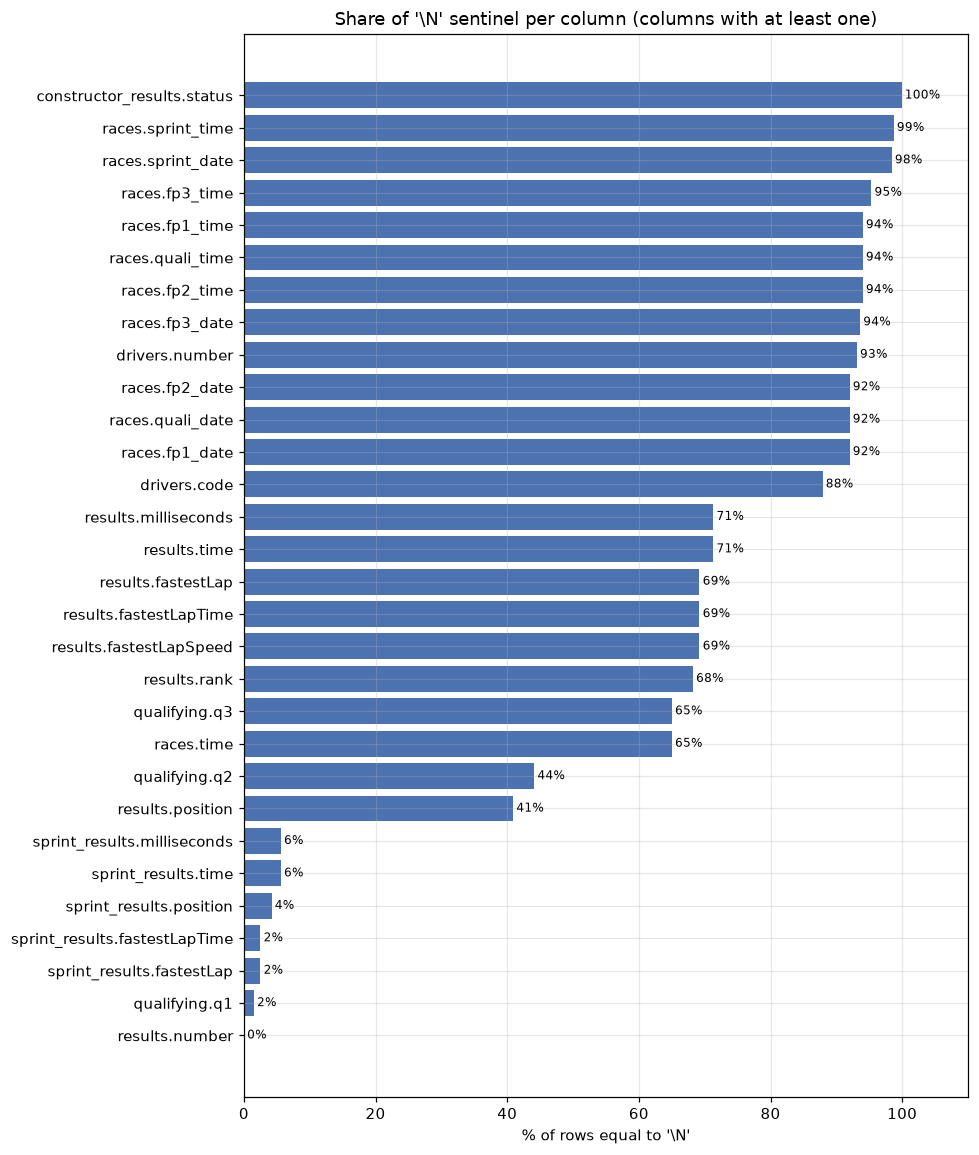

In [6]:
plot_df = placeholder_report[placeholder_report["\\N"] > 0].copy()
plot_df["label"] = plot_df["table"] + "." + plot_df["column"]
plot_df = plot_df.sort_values("% \\N")

fig, ax = plt.subplots(figsize=(9, 0.32 * len(plot_df) + 1))
ax.barh(plot_df["label"], plot_df["% \\N"], color="#4C72B0")
for y, v in enumerate(plot_df["% \\N"]):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlabel(r"% of rows equal to '\N'")
ax.set_title(r"Share of '\N' sentinel per column (columns with at least one)")
ax.set_xlim(0, 110)
plt.tight_layout()
plt.show()

### 1.2.1 Zeros that may be placeholders

`\N` is not the only way "unknown" is encoded. Some numeric columns use `0` where 0 is not a real value (there is no grid slot 0, no position 0).

In [7]:
zero_checks = [
    ("results", "grid"), ("sprint_results", "grid"), ("qualifying", "position"),
    ("results", "positionOrder"), ("results", "number"), ("qualifying", "number"),
    ("results", "laps"), ("circuits", "alt"),
]
zero_report = pd.DataFrame([
    {"table": t, "column": c, "n_zero": int((RAW[t][c] == "0").sum()),
     "% zero": round(100 * (RAW[t][c] == "0").mean(), 2)}
    for t, c in zero_checks
])
display(zero_report)

,table,column,n_zero,% zero
0,results,grid,1638,6.12
1,sprint_results,grid,11,3.06
2,qualifying,position,0,0.00
3,results,positionOrder,0,0.00
4,results,number,34,0.13
5,qualifying,number,15,0.14
6,results,laps,2532,9.46
7,circuits,alt,2,2.60


### 1.2.2 Inconsistent labels (matter for joins on text)

Question 2 (home-country podiums) needs to match a **driver nationality** to a **circuit country**. Both are free text, so we check how they're spelled.

In [8]:
nat = RAW["drivers"]["nationality"]
country = RAW["circuits"]["country"]

print("Driver nationalities with leading/trailing spaces:", sorted(nat[nat != nat.str.strip()].unique()))
print("\nCircuit countries:", sorted(country.unique()))
print("\nDriver nationalities:", sorted(nat.str.strip().unique()))

direct_matches = sorted(set(nat.str.strip()) & set(country))
print("\nNationality strings that literally equal a circuit country:", direct_matches)

Driver nationalities with leading/trailing spaces: ['Argentinian ']

Circuit countries: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']

Driver nationalities: ['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 

**What this means.**
- `\N` appears in exactly the columns we'd expect to be "not applicable" or "not recorded". Examples: `results.position` (~41%, drivers who weren't classified), `results.time/milliseconds` (~71%, only finishers on the lead lap get a time), `fastestLap*` (~69%, only recorded since 2004), `qualifying.q2/q3` (only drivers who advanced to Q2/Q3), `races.fp*/quali_*/sprint_*` (session schedule only recorded recently), `drivers.number/code` (permanent numbers/codes are a modern thing).
  So **`\N` is mostly "doesn't exist" rather than "lost"**. That changes how we treat it: a missing Q3 time means "eliminated earlier", which is information, not noise.
- **Inconsistent sentinel:** `qualifying.q2/q3` also contain **empty strings** (not `\N`) in some recent rows. A cleaner that only replaces `\N` would miss them, so both must map to missing.
- **`0` as placeholder:** `results.grid = 0` (~6% of rows) is not a real slot (explained in 1.8).
- **Text labels don't line up:** `'Argentinian '` has a trailing space (and `Argentine` also exists). Nationalities are demonyms (`British`, `American`) while countries are names (`UK`, `USA` **and** `United States`). Almost no nationality equals a country string literally, so Q2 needs an explicit nationality → country mapping.

**Why it matters.** Mis-handled placeholders become fake values (e.g. `0` grid read as "pole position", which is better than P1!) or silently drop rows from joins.

## 1.3 Semantic typing: dates, times, durations

For each temporal column we show the **value shapes** (every digit replaced by `9`, so `1:27.452` → `9:99.999`), example raw values, and the target type.
Then we **test-parse** each column in memory (not saved) and count values that fail to parse. That way the conversion rule is proven, not assumed.

In [9]:
def is_missing(s):
    return (s == SENTINEL) | (s.str.strip() == "")


def value_shapes(s, top=4):
    shapes = s[~is_missing(s)].str.replace(r"\d", "9", regex=True).value_counts()
    return ", ".join(f"{k} ({v:,})" for k, v in shapes.head(top).items()) + (" ..." if len(shapes) > top else "")


def duration_to_seconds(v):
    """'h:mm:ss.sss' | 'm:ss.sss' | 'ss.sss' -> float seconds (NaN if not parseable)."""
    try:
        secs = 0.0
        for part in v.split(":"):
            secs = secs * 60 + float(part)
        return secs
    except (ValueError, AttributeError):
        return np.nan


def parse_failures(s, kind):
    present = s[~is_missing(s)]
    if kind == "date":
        parsed = pd.to_datetime(present, format="%Y-%m-%d", errors="coerce")
    elif kind == "clock":
        parsed = pd.to_datetime(present, format="%H:%M:%S", errors="coerce")
    elif kind == "duration":
        parsed = present.map(duration_to_seconds)
    elif kind == "number":
        parsed = pd.to_numeric(present, errors="coerce")
    else:
        return np.nan
    return int(parsed.isna().sum())


SEMANTIC = [
    # table, column, parse kind, target type, note
    ("races", "date", "date", "datetime64 (date)", "race day"),
    ("races", "time", "clock", "time of day -> combine with date (UTC)", "start time; only recorded from ~2005"),
    ("races", "quali_date", "date", "datetime64 (date)", "session schedule, recent seasons only"),
    ("races", "quali_time", "clock", "time of day", "session schedule, recent seasons only"),
    ("races", "fp1_date", "date", "datetime64 (date)", "same pattern for fp2/fp3/sprint"),
    ("drivers", "dob", "date", "datetime64 (date)", "for driver age at race"),
    ("qualifying", "q1", "duration", "float seconds", "lap time m:ss.sss"),
    ("qualifying", "q2", "duration", "float seconds", "missing = eliminated in Q1 / format"),
    ("qualifying", "q3", "duration", "float seconds", "missing = eliminated in Q2 / format"),
    ("results", "time", "mixed", "DO NOT PARSE -> use milliseconds", "winner: total time; others: '+gap'"),
    ("results", "milliseconds", "number", "Int64 milliseconds", "total race time, finishers only"),
    ("results", "fastestLapTime", "duration", "float seconds", "post-race info"),
    ("results", "fastestLapSpeed", "number", "float km/h", "post-race info"),
    ("sprint_results", "time", "mixed", "DO NOT PARSE -> use milliseconds", "same format as results.time"),
    ("sprint_results", "fastestLapTime", "duration", "float seconds", ""),
    ("lap_times", "time", "duration", "float seconds", "also has milliseconds column"),
    ("pit_stops", "time", "clock", "time of day (local)", "wall-clock time of the stop"),
    ("pit_stops", "duration", "duration", "float seconds", "some > 60 s written as m:ss.sss"),
]

typing_report = pd.DataFrame([
    {
        "table.column": f"{t}.{c}",
        "non-missing": int((~is_missing(RAW[t][c])).sum()),
        "value shapes (count)": value_shapes(RAW[t][c]),
        "examples": " | ".join(RAW[t][c][~is_missing(RAW[t][c])].drop_duplicates().head(3)),
        "target type": target,
        "parse failures": parse_failures(RAW[t][c], kind),
        "note": note,
    }
    for t, c, kind, target, note in SEMANTIC
])
display(typing_report)

,table.column,non-missing,value shapes (count),examples,target type,parse failures,note
0,races.date,1125,"9999-99-99 (1,125)",2009-03-29 | 2009-04-05 | 2009-04-19,datetime64 (date),0.0,race day
1,races.time,394,99:99:99 (394),06:00:00 | 09:00:00 | 07:00:00,time of day -> combine with date (UTC),0.0,start time; only recorded from ~2005
2,races.quali_date,90,9999-99-99 (90),2021-04-17 | 2022-03-19 | 2021-03-27,datetime64 (date),0.0,"session schedule, recent seasons only"
3,races.quali_time,68,99:99:99 (68),15:00:00 | 17:00:00 | 06:00:00,time of day,0.0,"session schedule, recent seasons only"
4,races.fp1_date,90,9999-99-99 (90),2021-04-16 | 2022-03-18 | 2021-03-26,datetime64 (date),0.0,same pattern for fp2/fp3/sprint
5,drivers.dob,861,9999-99-99 (861),1985-01-07 | 1977-05-10 | 1985-06-27,datetime64 (date),0.0,for driver age at race
6,qualifying.q1,10338,"9:99.999 (10,337), 99:99.999 (1)",1:26.572 | 1:26.103 | 1:25.664,float seconds,0.0,lap time m:ss.sss
7,qualifying.q2,5847,"9:99.999 (5,847)",1:25.187 | 1:25.315 | 1:25.452,float seconds,0.0,missing = eliminated in Q1 / format
8,qualifying.q3,3629,"9:99.999 (3,629)",1:26.714 | 1:26.869 | 1:27.079,float seconds,0.0,missing = eliminated in Q2 / format
9,results.time,7680,"+99.999 (2,973), +9:99.999 (1,614), 9:99:99.999 (765), +...",1:34:50.616 | +5.478 | +8.163,DO NOT PARSE -> use milliseconds,NaN,winner: total time; others: '+gap'


**Cross-check:** `lap_times`, `pit_stops` and `results` carry a `milliseconds` column next to the text time. If our parser is right, both must agree.

In [10]:
checks = []
for t, text_col in [("lap_times", "time"), ("pit_stops", "duration")]:
    d = RAW[t]
    ok = ~is_missing(d[text_col]) & ~is_missing(d["milliseconds"])
    parsed_ms = d.loc[ok, text_col].map(duration_to_seconds) * 1000
    diff = (parsed_ms - pd.to_numeric(d.loc[ok, "milliseconds"])).abs()
    checks.append({"column": f"{t}.{text_col}", "rows compared": int(ok.sum()),
                   "max |parsed - milliseconds| (ms)": round(diff.max(), 3),
                   "rows differing by > 1 ms": int((diff > 1).sum())})

# results.time only equals milliseconds for the winner (absolute time); everyone else has a '+gap'.
r = RAW["results"]
has_time = ~is_missing(r["time"])
checks.append({"column": "results.time", "rows compared": int(has_time.sum()),
               "max |parsed - milliseconds| (ms)": np.nan,
               "rows differing by > 1 ms": int(r.loc[has_time, "time"].str.startswith("+").sum())})
display(pd.DataFrame(checks))
print("results.time rows starting with '+' are gaps to the winner, not race times.")

,column,rows compared,max |parsed - milliseconds| (ms),rows differing by > 1 ms
0,lap_times.time,589081,0.0,0
1,pit_stops.duration,11371,0.0,0
2,results.time,7680,NaN,6552


results.time rows starting with '+' are gaps to the winner, not race times.


### 1.3.1 Numeric columns stored as text

Every column where **all non-missing values parse as numbers** should become numeric. If it has missing values, it should use a nullable type (`Int64` / `float`), so the missing ones stay missing instead of becoming `0`.

In [11]:
num_rows = []
for t, df in RAW.items():
    for col in df.columns:
        s = df[col]
        present = s[~is_missing(s)]
        if present.empty:
            continue
        as_num = pd.to_numeric(present, errors="coerce")
        if as_num.notna().all():
            is_int = bool((as_num == np.floor(as_num)).all())
            n_missing = int(is_missing(s).sum())
            num_rows.append({"table": t, "column": col, "naive dtype": str(NAIVE[t][col].dtype),
                             "missing": n_missing,
                             "proposed": ("Int64" if is_int else "float64") + (" (nullable)" if n_missing else "")})

numeric_report = pd.DataFrame(num_rows)
print(f"{len(numeric_report)} columns are purely numeric apart from placeholders.")
display(numeric_report[numeric_report["naive dtype"] == "object"]
        .rename(columns={"naive dtype": "naive dtype (wrong)"}))

73 columns are purely numeric apart from placeholders.


,table,column,naive dtype (wrong),missing,proposed
16,drivers,number,object,802,Int64 (nullable)
31,results,number,object,6,Int64 (nullable)
33,results,position,object,10953,Int64 (nullable)
37,results,milliseconds,object,19079,Int64 (nullable)
38,results,fastestLap,object,18507,Int64 (nullable)
39,results,rank,object,18249,Int64 (nullable)
40,results,fastestLapSpeed,object,18507,float64 (nullable)
64,sprint_results,position,object,15,Int64 (nullable)
68,sprint_results,milliseconds,object,20,Int64 (nullable)
69,sprint_results,fastestLap,object,9,Int64 (nullable)


**What this means.**
- **Dates** (`races.date`, `drivers.dob`, session dates) are clean `YYYY-MM-DD`, with 0 parse failures. They become real dates, so we can sort races chronologically (essential for "past races only" features) and compute driver age.
- **Lap and qualifying times** (`m:ss.sss`) become **seconds as float**, which makes them comparable and usable as numbers. Some `pit_stops.duration` values over a minute are written `m:ss.sss` (red-flag stoppages), and a few lap times use `h:mm:ss.sss`. That's why the parser handles 1–3 parts instead of assuming one format. The milliseconds cross-check shows the parser reproduces the official milliseconds exactly.
- **`results.time` must not be parsed as a duration.** For the winner it's the total race time, for everyone else it's a gap (`+5.478`). The same column mixes two meanings. `milliseconds` is the consistent version, and it's post-race anyway.
- The numeric list shows which ID/count columns are text only because of `\N`.

**Why it matters.** Correct types are the precondition for everything else: chronological ordering for leakage-safe features, numeric features for the models, and correct joins on ID columns.

## 1.4 Primary-key check

For each table we test the **surrogate key** (the `...Id` column) and the **natural key** (what the row *means*, e.g. "one driver in one race").
A valid key is **unique** and **non-null** (no `\N` / empty).

In [12]:
KEYS = [
    # table, key columns, key kind
    ("circuits", ["circuitId"], "surrogate"), ("circuits", ["circuitRef"], "natural"),
    ("constructors", ["constructorId"], "surrogate"), ("constructors", ["constructorRef"], "natural"),
    ("drivers", ["driverId"], "surrogate"), ("drivers", ["driverRef"], "natural"),
    ("seasons", ["year"], "natural"),
    ("status", ["statusId"], "surrogate"),
    ("races", ["raceId"], "surrogate"), ("races", ["year", "round"], "natural"),
    ("results", ["resultId"], "surrogate"), ("results", ["raceId", "driverId"], "natural (our grain)"),
    ("qualifying", ["qualifyId"], "surrogate"), ("qualifying", ["raceId", "driverId"], "natural"),
    ("sprint_results", ["resultId"], "surrogate"), ("sprint_results", ["raceId", "driverId"], "natural"),
    ("driver_standings", ["driverStandingsId"], "surrogate"), ("driver_standings", ["raceId", "driverId"], "natural"),
    ("constructor_standings", ["constructorStandingsId"], "surrogate"), ("constructor_standings", ["raceId", "constructorId"], "natural"),
    ("constructor_results", ["constructorResultsId"], "surrogate"), ("constructor_results", ["raceId", "constructorId"], "natural"),
    ("lap_times", ["raceId", "driverId", "lap"], "natural (no surrogate)"),
    ("pit_stops", ["raceId", "driverId", "stop"], "natural (no surrogate)"),
]

pk_rows = []
for t, key, kind in KEYS:
    d = RAW[t]
    n_null = int(d[key].apply(is_missing).any(axis=1).sum())
    n_dup_rows = int(d.duplicated(key, keep=False).sum())
    pk_rows.append({"table": t, "key": " + ".join(key), "kind": kind, "rows": len(d),
                    "null keys": n_null, "rows in duplicated keys": n_dup_rows,
                    "valid PK": n_null == 0 and n_dup_rows == 0})

pk_report = pd.DataFrame(pk_rows)
display(pk_report.style.apply(
    lambda row: ["background-color: #f8d7da" if not row["valid PK"] else "" for _ in row], axis=1))

,table,key,kind,rows,null keys,rows in duplicated keys,valid PK
0,circuits,circuitId,surrogate,77,0,0,True
1,circuits,circuitRef,natural,77,0,0,True
2,constructors,constructorId,surrogate,212,0,0,True
3,constructors,constructorRef,natural,212,0,0,True
4,drivers,driverId,surrogate,861,0,0,True
5,drivers,driverRef,natural,861,0,0,True
6,seasons,year,natural,75,0,0,True
7,status,statusId,surrogate,139,0,0,True
8,races,raceId,surrogate,1125,0,0,True
9,races,year + round,natural,1125,0,0,True


**What this means.** Every surrogate `...Id` key is unique and non-null, so the tables are internally consistent.
The **only key that fails is `results (raceId, driverId)`**: the same driver appears more than once in the same race. That's exactly our modeling grain, so it must be fixed (see 1.6).
`qualifying` and `driver_standings` *are* unique per (raceId, driverId), so joining them onto `results` won't multiply rows.

**Why it matters.** If a join key isn't unique on the "one" side, a join silently duplicates rows. Duplicated rows inflate the dataset, bias the model, and can leak the same race into train and test.

## 1.5 Foreign-key check

For every foreign key we count child values that **don't exist** in the parent table (orphans). We also check the reverse direction where it matters (parents with no children).

In [13]:
FKS = [
    # child table, child column, parent table, parent column
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
]

fk_rows = []
for child, ccol, parent, pcol in FKS:
    vals = RAW[child][ccol]
    missing = is_missing(vals)
    orphan = ~missing & ~vals.isin(RAW[parent][pcol])
    fk_rows.append({"FK": f"{child}.{ccol} -> {parent}.{pcol}", "rows": len(vals),
                    "null FK": int(missing.sum()), "orphans": int(orphan.sum()),
                    "orphan examples": ", ".join(vals[orphan].unique()[:5])})
fk_report = pd.DataFrame(fk_rows)
display(fk_report)
print("All foreign keys reconcile:", bool((fk_report["orphans"] == 0).all()))

,FK,rows,null FK,orphans,orphan examples
0,races.circuitId -> circuits.circuitId,1125,0,0,
1,races.year -> seasons.year,1125,0,0,
2,results.raceId -> races.raceId,26759,0,0,
3,results.driverId -> drivers.driverId,26759,0,0,
4,results.constructorId -> constructors.constructorId,26759,0,0,
5,results.statusId -> status.statusId,26759,0,0,
6,qualifying.raceId -> races.raceId,10494,0,0,
7,qualifying.driverId -> drivers.driverId,10494,0,0,
8,qualifying.constructorId -> constructors.constructorId,10494,0,0,
9,sprint_results.raceId -> races.raceId,360,0,0,


All foreign keys reconcile: True


In [14]:
# Reverse direction + cross-table consistency checks.
res, quali, races = RAW["results"], RAW["qualifying"], RAW["races"]

races_without_results = races[~races["raceId"].isin(res["raceId"])]
q_keys = quali.set_index(["raceId", "driverId"]).index
r_keys = res.set_index(["raceId", "driverId"]).index
quali_without_result = int((~q_keys.isin(r_keys)).sum())

# Same driver, same race: does qualifying list the same constructor as results?
both = res.merge(quali, on=["raceId", "driverId"], suffixes=("_res", "_q"))
team_mismatch = both[both["constructorId_res"] != both["constructorId_q"]]

print(f"Races with no results rows:           {len(races_without_results)}")
print(f"Qualifying rows with no results row:  {quali_without_result}")
print(f"Drivers never appearing in results:   {int((~RAW['drivers']['driverId'].isin(res['driverId'])).sum())}")
print(f"results vs qualifying constructorId mismatches: {len(team_mismatch)}")
display(team_mismatch.merge(races[["raceId", "year", "name"]], on="raceId")
        [["raceId", "year", "name", "driverId", "constructorId_res", "constructorId_q", "position_q", "grid"]])

Races with no results rows:           0
Qualifying rows with no results row:  0
Drivers never appearing in results:   0
results vs qualifying constructorId mismatches: 10


,raceId,year,name,driverId,constructorId_res,constructorId_q,position_q,grid
0,937,2015,Belgian Grand Prix,833,209,206,20,17
1,937,2015,Belgian Grand Prix,829,209,206,19,15
2,941,2015,Russian Grand Prix,833,209,206,19,18
3,941,2015,Russian Grand Prix,829,209,206,18,17
4,942,2015,United States Grand Prix,834,209,206,18,17
5,942,2015,United States Grand Prix,829,209,206,19,19
6,943,2015,Mexican Grand Prix,834,209,206,18,16
7,943,2015,Mexican Grand Prix,829,209,206,19,17
8,944,2015,Brazilian Grand Prix,829,209,206,19,18
9,944,2015,Brazilian Grand Prix,834,209,206,18,17


**What this means.** Every foreign key resolves (0 orphans). Every race has results and every qualifying row has a matching result, so a **left join from `results`** loses nothing.
The one soft inconsistency is a handful of rows where `qualifying` and `results` list a *different constructor* for the same driver in the same race (data-entry quirks). When we need the constructor, we'll take it from `results`, the table that defines the grain.

**Why it matters.** Orphan keys would make inner joins silently drop rows, or left joins produce unexplained NaNs. Here we can join safely, and any NaN after a join means "not recorded", not "broken link".

## 1.6 Duplicate (raceId, driverId) pairs in `results`

In [15]:
drivers = RAW["drivers"].assign(driver=lambda d: d["forename"] + " " + d["surname"])[["driverId", "driver"]]
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = (res[dup_mask]
        .merge(races[["raceId", "year", "name"]], on="raceId")
        .merge(drivers, on="driverId")
        .merge(RAW["status"], on="statusId")
        .sort_values(["raceId", "driverId", "resultId"]))

pairs = dups.groupby(["raceId", "driverId"])
print(f"Duplicated rows: {len(dups)}  |  distinct (raceId, driverId) pairs: {pairs.ngroups}  "
      f"|  share of results: {100 * len(dups) / len(res):.2f}%")
print("Rows per duplicated pair:", pairs.size().value_counts().sort_index().to_dict())
print("Constructors per duplicated pair:", pairs["constructorId"].nunique().value_counts().sort_index().to_dict())
print("Years:", f"{dups['year'].min()}-{dups['year'].max()}")

Duplicated rows: 176  |  distinct (raceId, driverId) pairs: 85  |  share of results: 0.66%
Rows per duplicated pair: {2: 79, 3: 6}
Constructors per duplicated pair: {1: 69, 2: 15, 3: 1}
Years: 1950-1978


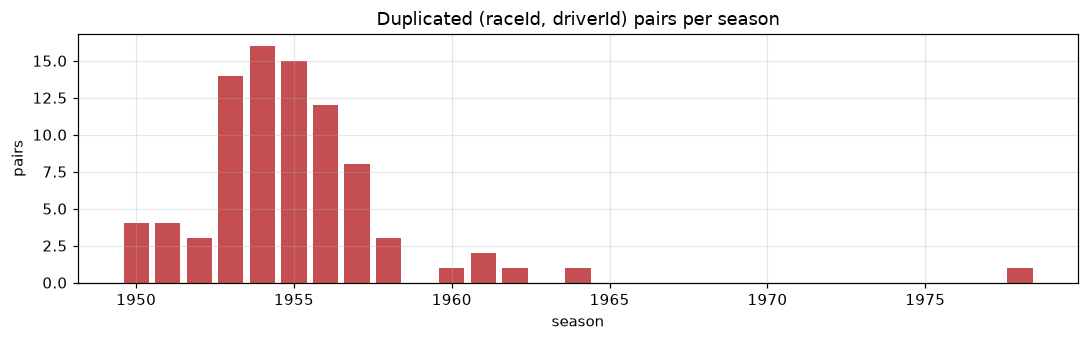

,year,name,pairs,rows
0,1950,French Grand Prix,1,2
1,1950,Indianapolis 500,1,2
2,1950,Italian Grand Prix,2,4
3,1951,French Grand Prix,3,6
4,1951,Italian Grand Prix,1,2
5,1952,Dutch Grand Prix,1,2
6,1952,French Grand Prix,1,2
7,1952,Swiss Grand Prix,1,2
12,1953,Swiss Grand Prix,2,4
11,1953,Indianapolis 500,8,18


In [16]:
per_year = dups.groupby("year").apply(lambda g: g.groupby(["raceId", "driverId"]).ngroups, include_groups=False)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(per_year.index.astype(int), per_year.values, color="#C44E52")
ax.set_title("Duplicated (raceId, driverId) pairs per season")
ax.set_xlabel("season")
ax.set_ylabel("pairs")
plt.tight_layout()
plt.show()

display(dups.groupby(["year", "name"]).agg(pairs=("driverId", lambda s: s.nunique()), rows=("resultId", "size"))
        .reset_index().sort_values("year"))

A few complete examples (all original columns), chosen to show the different kinds of duplicate:

In [17]:
def show_pair(race_id, driver_id):
    d = dups[(dups["raceId"] == race_id) & (dups["driverId"] == driver_id)]
    display(Markdown(f"**{d['year'].iat[0]} {d['name'].iat[0]} - {d['driver'].iat[0]}**"))
    display(d[list(res.columns) + ["status"]])


# Pick one example of each kind found in the data.
kinds = pairs.agg(n_constructors=("constructorId", "nunique"),
                  any_podium=("positionOrder", lambda s: (s.astype(int) <= 3).any()),
                  all_no_start=("grid", lambda s: (s == "0").all())).reset_index()
examples = [
    kinds[(kinds["n_constructors"] == 1) & kinds["any_podium"]].iloc[0],    # shared drive that reached the podium
    kinds[(kinds["n_constructors"] == 1) & ~kinds["any_podium"]].iloc[0],   # shared drive, no podium
    kinds[kinds["n_constructors"] > 1].iloc[0],                              # two different teams' cars
    kinds[kinds["all_no_start"]].iloc[-1],                                   # entries that never started
]
for ex in examples:
    show_pair(ex["raceId"], ex["driverId"])

**1960 Argentine Grand Prix - Stirling Moss**

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
8,18083,746,475,170,36,1,\N,R,17,0,40,\N,\N,\N,\N,\N,\N,22,Suspension
173,22372,746,475,170,38,8,3,3,3,0,80,+36.9,8306400,\N,\N,\N,\N,1,Finished


**1964 United States Grand Prix - Jim Clark**

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
2,17363,717,373,172,1,1,7,7,7,0,102,\N,\N,\N,\N,\N,\N,60,Out of fuel
175,24304,717,373,172,2,1,\N,R,12,0,54,\N,\N,\N,\N,\N,\N,98,Injection


**1978 Italian Grand Prix - Harald Ertl**

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
0,13189,540,229,54,10,0,\N,F,26,0,0,\N,\N,\N,\N,\N,\N,81,Did not qualify
1,13192,540,229,57,23,0,\N,F,29,0,0,\N,\N,\N,\N,\N,\N,97,Did not prequalify


**1958 Monaco Grand Prix - Ron Flockhart**

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
9,18510,766,541,87,22,0,\N,F,17,0,0,\N,\N,\N,\N,\N,\N,81,Did not qualify
10,18520,766,541,66,10,0,\N,F,27,0,0,\N,\N,\N,\N,\N,\N,81,Did not qualify


**Effect on the target:** if duplicates are left in, a race can have more than 3 "podium" rows.

In [18]:
po = res.assign(positionOrder=res["positionOrder"].astype(int))
podium_rows = po[po["positionOrder"] <= 3].groupby("raceId").size()
odd = podium_rows[podium_rows != 3]
print("Races by number of rows with positionOrder <= 3:", podium_rows.value_counts().sort_index().to_dict())
dup_races = set(dups["raceId"])
print(f"Races with != 3 podium rows: {len(odd)}, of which contain duplicated pairs: {sum(r in dup_races for r in odd.index)}")
print("positionOrder values repeated within a race:", int(po.duplicated(["raceId", "positionOrder"]).sum()))

Races by number of rows with positionOrder <= 3: {3: 1107, 4: 16, 5: 1, 7: 1}
Races with != 3 podium rows: 18, of which contain duplicated pairs: 16
positionOrder values repeated within a race: 123


The 2 races with too many podium rows but **no** duplicated pair point to a second kind of shared drive. **Different drivers** share one car, so each driver appears only once,
but both are credited with the same `positionOrder`. Checking for repeated (`raceId`, `positionOrder`) finds these:

In [19]:
shared_pos = (po[po.duplicated(["raceId", "positionOrder"], keep=False)]
              .merge(races[["raceId", "year", "name"]], on="raceId")
              .merge(drivers, on="driverId"))
shared_pos["same driver twice"] = shared_pos.duplicated(["raceId", "driverId"], keep=False)
print(f"Rows sharing a positionOrder with another row in the same race: {len(shared_pos)} "
      f"(years {shared_pos['year'].min()}-{shared_pos['year'].max()})")
print("  of which are the same driver twice (already covered above):", int(shared_pos["same driver twice"].sum()))
print("  of which are different drivers sharing one result:", int((~shared_pos["same driver twice"]).sum()))

example_races = odd.index[~odd.index.isin(list(dup_races))]
display(shared_pos[shared_pos["raceId"].isin(example_races) & (shared_pos["positionOrder"] <= 3)]
        [["year", "name", "driver", "constructorId", "number", "grid", "positionOrder", "points", "laps"]]
        .sort_values(["year", "positionOrder"]))

Rows sharing a positionOrder with another row in the same race: 228 (years 1950-1964)
  of which are the same driver twice (already covered above): 62
  of which are different drivers sharing one result: 166


,year,name,driver,constructorId,number,grid,positionOrder,points,laps
92,1951,Indianapolis 500,Jack McGrath,113,9,3,3,2,200
113,1951,Indianapolis 500,Manny Ayulo,113,9,3,3,2,200
43,1955,Indianapolis 500,Tony Bettenhausen,113,10,2,2,3,200
189,1955,Indianapolis 500,Paul Russo,113,10,2,2,3,200


**What this means.**
- There are **85 duplicated pairs (176 rows, ~0.7% of results)**. Most pairs have 2 rows and a few have 3. They concentrate in **1950–1958**, with a small tail into the 1960s and one case in 1978. There are none after 1978.
- Most are **shared drives**: the same constructor, with two drivers credited for one car. That's why a race can show 4–7 rows with `positionOrder <= 3` and why `positionOrder` repeats within a race: the shared result is credited to every driver of that car.
- A minority are **different constructors**: a driver entered in two cars, or took over a team-mate's car. Some are entries that never started at all (`grid = 0`, e.g. *Did not qualify* / *Withdrew* twice).
- There is also a **second kind of shared drive** that the (raceId, driverId) check can't see: two *different* drivers credited with one car's result (e.g. the 1951 and 1955 Indianapolis 500). These rows aren't duplicates for our grain, since each driver appears once. They do mean a race can legitimately have **more than 3 podium-labelled drivers** even after de-duplication. That matches the official record (both drivers are credited) and only affects 1950-1964.

**Options for which row to keep (not chosen yet):**

| Rule | How | Pros | Cons |
|---|---|---|---|
| A. Best result | keep the row with the lowest `positionOrder` | Target = "did this driver get podium credit at all", matches the official record | The kept row's `grid`/car may be one the driver **didn't start in**. Its pre-race features then describe another car (subtle leakage: the row was chosen *because* of its outcome) |
| B. Starting entry | keep the row the driver actually **started** in. In practice: the lowest `resultId`, as a proxy for the starting car, plus a short list of verified overrides (2.6) | Selection uses only pre-race info, so features and target describe the same car. Consistent with the cutoff | May label a driver "no podium" even though he shared a podium car later in the race. The proxy can be wrong for a few pairs |
| C. Hybrid | features from the starting entry, target = podium in **any** of his rows | Keeps the official credit and pre-race-consistent features | Mixes two rows into one, which is harder to explain and test |
| D. Drop all duplicated pairs | remove these 176 rows | Simplest, no arbitrary choice | Loses data (small), and removes some genuine podiums from 1950s races |

Practical note: these rows are all from 1950-1978, so they never reach a 2003+ model. They do reach an all-years model and the data-engineering questions that use all seasons, and the brief requires a documented rule.

## 1.7 Qualifying coverage by season

For each season: what % of `results` rows have a matching `qualifying` row (same raceId + driverId)?
We also show the % of races with *any* qualifying data (to separate "whole race missing" from "some drivers missing"), and the % of rows with a usable `grid` (> 0) for comparison.

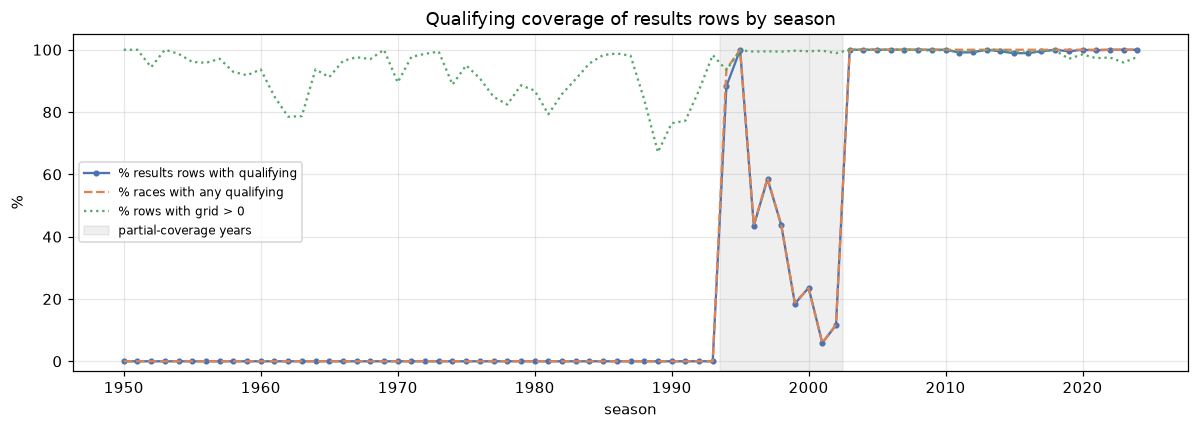

,% results rows with qualifying,% races with any qualifying,% rows with grid > 0
year,,,
1990,0.0,0.0,76.4
1991,0.0,0.0,77.2
1992,0.0,0.0,87.0
1993,0.0,0.0,98.3
1994,88.3,93.8,93.5
1995,100.0,100.0,99.8
1996,43.5,43.8,99.4
1997,58.5,58.8,99.5
1998,43.8,43.8,99.4


First season of continuous ~full coverage: 2003


In [20]:
rq = (res[["raceId", "driverId", "grid"]]
      .merge(quali[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
             on=["raceId", "driverId"], how="left")
      .merge(races[["raceId", "year"]], on="raceId"))
rq["year"] = rq["year"].astype(int)
rq["has_quali"] = rq["quali_pos"].notna()

coverage = pd.DataFrame({
    "% results rows with qualifying": 100 * rq.groupby("year")["has_quali"].mean(),
    "% races with any qualifying": 100 * rq.groupby(["year", "raceId"])["has_quali"].any().groupby("year").mean(),
    "% rows with grid > 0": 100 * (rq["grid"] != "0").groupby(rq["year"]).mean(),
}).round(1)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(coverage.index, coverage.iloc[:, 0], marker="o", ms=3, label=coverage.columns[0], color="#4C72B0")
ax.plot(coverage.index, coverage.iloc[:, 1], ls="--", label=coverage.columns[1], color="#DD8452")
ax.plot(coverage.index, coverage.iloc[:, 2], ls=":", label=coverage.columns[2], color="#55A868")
ax.axvspan(1993.5, 2002.5, color="grey", alpha=0.12, label="partial-coverage years")
ax.set_ylim(-3, 105)
ax.set_ylabel("%")
ax.set_xlabel("season")
ax.set_title("Qualifying coverage of results rows by season")
ax.legend(loc="center left", fontsize=8)
plt.tight_layout()
plt.show()

display(coverage.loc[1990:2006])
first_full = coverage.index[(coverage.iloc[:, 0] >= 98) & (coverage.index > 2002)].min()
print("First season of continuous ~full coverage:", first_full)

**What this means.**
- **1950–1993: 0% coverage.** The `qualifying` table simply doesn't exist for those seasons.
- **1994–2002: patchy.** 1994–95 are nearly complete, but 1996–2002 only cover some races (whole races missing, the dashed line), dropping as low as ~6% of rows in 2001.
- **2003 onward: ~100%** (tiny gaps are drivers with no qualifying entry).
- Meanwhile `grid` (dotted line) is available in almost every season.

**Why it matters.** Qualifying features (position, gap to pole, Q1/Q2/Q3 times) are only usable from 2003 (or 1994 if we accept gaps). Our options are: (a) restrict the modeling table to ≥ 2003; (b) use all years but rely on `grid` and treat qualifying as missing (with a "has qualifying" flag); (c) impute. A model trained across eras would also learn "qualifying missing ⇒ old era", which is a known limitation the brief explicitly asks us to discuss (qualifying-coverage drift).

## 1.8 Qualifying position vs. `grid`

`qualifying.position` = where the driver qualified. `results.grid` = where they actually **started**. They can differ (penalties, pit-lane starts, other drivers' penalties). Compared on rows that have both.

Rows with both values:         10,494
grid == qualifying position:   76.1%
grid == 0 (among these rows):  87
Among grid > 0: started further back 5.1%, further forward 18.2%


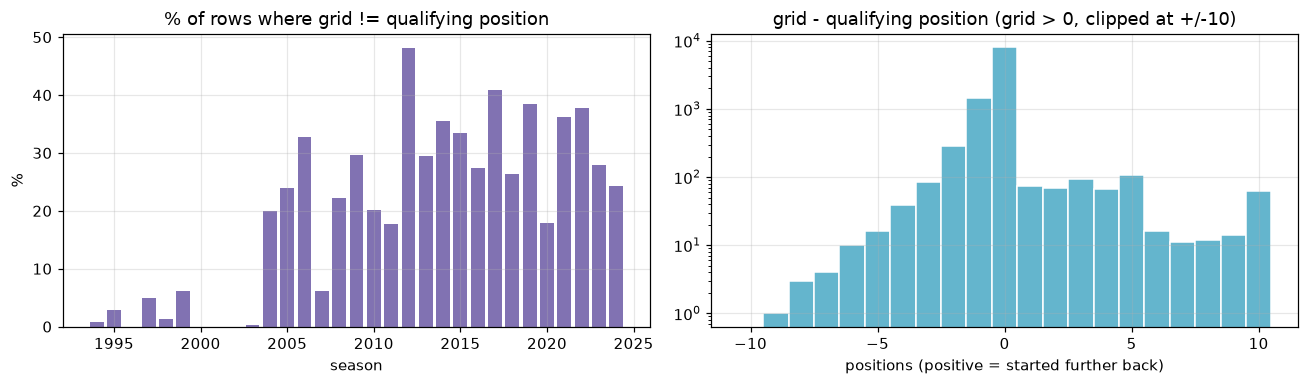

In [21]:
both = rq[rq["has_quali"]].copy()
both["grid_n"] = both["grid"].astype(int)
both["quali_n"] = both["quali_pos"].astype(int)
both["grid_minus_quali"] = both["grid_n"] - both["quali_n"]
started_from_grid = both[both["grid_n"] > 0]

print(f"Rows with both values:         {len(both):,}")
print(f"grid == qualifying position:   {100 * (both['grid_minus_quali'] == 0).mean():.1f}%")
print(f"grid == 0 (among these rows):  {int((both['grid_n'] == 0).sum())}")
print(f"Among grid > 0: started further back {100 * (started_from_grid['grid_minus_quali'] > 0).mean():.1f}%, "
      f"further forward {100 * (started_from_grid['grid_minus_quali'] < 0).mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
diff_by_year = 100 * (both["grid_minus_quali"] != 0).groupby(both["year"]).mean()
axes[0].bar(diff_by_year.index, diff_by_year.values, color="#8172B2")
axes[0].set_title("% of rows where grid != qualifying position")
axes[0].set_xlabel("season")
axes[0].set_ylabel("%")

clipped = started_from_grid["grid_minus_quali"].clip(-10, 10)
axes[1].hist(clipped, bins=np.arange(-10.5, 11.5, 1), color="#64B5CD", edgecolor="white")
axes[1].set_yscale("log")
axes[1].set_title("grid - qualifying position (grid > 0, clipped at +/-10)")
axes[1].set_xlabel("positions (positive = started further back)")
plt.tight_layout()
plt.show()

In [22]:
# What does grid = 0 mean? Look at the race status of those rows, split by whether they have a qualifying row.
g0 = (res[res["grid"] == "0"]
      .merge(RAW["status"], on="statusId")
      .merge(races[["raceId", "year"]], on="raceId")
      .merge(quali[["raceId", "driverId"]], on=["raceId", "driverId"], how="left", indicator=True))
g0["in_qualifying"] = g0.pop("_merge") == "both"
g0["era"] = np.where(g0["year"].astype(int) < 1994, "1950-1993", "1994-2024")

print(f"Total results rows with grid = 0: {len(g0):,}")
display(g0.groupby("era").size().rename("rows").to_frame())
for era, d in g0.groupby("era"):
    display(Markdown(f"**{era}: top statuses for grid = 0**"))
    display(d["status"].value_counts().head(8).to_frame("rows"))
display(Markdown("**grid = 0 rows that DO have a qualifying row: did they race?**"))
display(g0[g0["in_qualifying"]]["status"].value_counts().head(8).to_frame("rows"))

Total results rows with grid = 0: 1,638


,rows
era,
1950-1993,1508
1994-2024,130


**1950-1993: top statuses for grid = 0**

,rows
status,
Did not qualify,978
Did not prequalify,331
Withdrew,158
Accident,16
Excluded,6
Disqualified,6
Engine,5
Injury,2


**1994-2024: top statuses for grid = 0**

,rows
status,
Did not qualify,35
+1 Lap,27
Finished,22
+2 Laps,7
Injury,6
Withdrew,6
Accident,4
Collision damage,3


**grid = 0 rows that DO have a qualifying row: did they race?**

,rows
status,
+1 Lap,26
Finished,22
+2 Laps,7
Did not qualify,5
Accident,4
Withdrew,4
Collision damage,3
Injury,2


**What this means.**
- On rows with both values, about **3 in 4 match**. The rest differ, and the difference is common in the modern era (often 20–45% of rows per season) because of grid penalties (engine/gearbox changes, impeding, etc.) and their knock-on effect on everyone else. **Qualifying position is not the starting position.**
- **`grid = 0` means "no grid slot"**, and it has two different meanings:
  - **Before ~1994:** mostly *Did not qualify / Did not prequalify / Withdrew*. These drivers **never started the race**, but they still have a `results` row (with a `positionOrder`!).
  - **Modern era (with a qualifying row):** mostly *Finished / +N Laps*. The driver **started from the pit lane** (e.g. after car changes under parc fermé). They raced, just from behind the last slot.
- So `grid = 0` must **never** be read as a number "better than pole".

**Why it matters.**
- For Q1 (front-row conversion) we must decide whether "front row" means **qualified** P1–P2 or **started** P1–P2. The brief asks us to distinguish them.
- For the model, `grid` is valid pre-race info (it's known at lights out) and is likely our strongest feature. It needs recoding: pit-lane start → a value behind the last grid slot plus a flag, not `0`.
- Rows of drivers who **never started** (DNQ/DNPQ/withdrew) arguably aren't "a driver entering a race" in the prediction sense. Keeping them adds easy negatives that inflate scores. This is a decision for the cleaning plan.

## 1.9 Join map: which tables, which keys

**Modeling table (grain = one row per raceId + driverId)**, built from `results` as the spine (left joins, so no driver-race is dropped):

| Join | Key(s) | What it brings | Unique on the right side? (1.4) |
|---|---|---|---|
| `results` ← `races` | `raceId` | year, round, date, circuitId (chronological ordering) | yes |
| `races` ← `circuits` | `circuitId` | circuit identity, country | yes |
| `results` ← `qualifying` | `raceId`, `driverId` | qualifying position, Q1/Q2/Q3 times | yes |
| `results` ← `drivers` | `driverId` | dob (age), nationality | yes |
| `results` ← `constructors` | `constructorId` | team identity | yes |
| `results` ← `driver_standings` of the **previous race** | `driverId` + previous `raceId` of the same season | points/position/wins *before* this race | yes |
| `results` ← `constructor_standings` of the **previous race** | `constructorId` + previous `raceId` | team form before this race | yes |
| `results` ← `sprint_results` (optional) | `raceId`, `driverId` | sprint finish (sprint runs *before* the GP, 2021+) | yes |
| past `results` (self-join on earlier races) | `driverId` / `constructorId`, date < race date | rolling form: recent podium rate, average finish | built by us |

**Data-engineering questions**

| Question | Tables | Keys |
|---|---|---|
| Q1 Front-row → podium by circuit, pre/post 2014 | `results` + `qualifying` + `races` + `circuits` | `raceId`+`driverId` (quali), `raceId` (races), `circuitId` (circuits) |
| Q2 Home-country podium effect, controlling for grid | `results` + `races` + `circuits` + `drivers` (+ a nationality→country mapping we create) | `raceId`, `circuitId`, `driverId` |
| Q3 Constructor mechanical-retirement rates 2014–21 vs 2022–24 | `results` + `status` + `races` + `constructors` | `statusId`, `raceId` (year), `constructorId` |

For Q3 we'll need to classify `status` values into mechanical / accident / driver / regulation / finished. Here is what actually occurs in 2014–2024:

In [23]:
status_recent = (res.merge(races[["raceId", "year"]], on="raceId")
                 .loc[lambda d: d["year"].astype(int) >= 2014]
                 .merge(RAW["status"], on="statusId")["status"].value_counts())
print(f"{len(status_recent)} distinct status values in 2014-2024:")
display(status_recent.to_frame("rows").T)

66 distinct status values in 2014-2024:


status,Finished,+1 Lap,+2 Laps,Collision,Accident,Engine,Collision damage,Retired,Brakes,Power Unit,Gearbox,Suspension,+3 Laps,Hydraulics,Withdrew,Electrical,Power loss,Wheel,Spun off,Disqualified,Oil leak,Overheating,Water pressure,Puncture,Mechanical,Turbo,+4 Laps,Exhaust,Fuel pressure,Battery,...,Radiator,Wheel nut,Illness,Transmission,Rear wing,Oil pressure,Steering,Fuel leak,+8 Laps,Clutch,Technical,Vibrations,Throttle,+6 Laps,Driveshaft,Damage,Fuel system,Drivetrain,Brake duct,Excluded,Seat,Spark plugs,Debris,+5 Laps,Out of fuel,Cooling system,Water pump,Fuel pump,Differential,+7 Laps
rows,2403,1178,208,150,85,81,59,50,49,42,42,25,24,15,14,14,13,11,11,11,10,8,7,7,7,6,6,5,5,5,...,3,3,3,3,3,2,2,2,2,2,2,2,2,2,2,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1


**What this means.** The modeling table only needs **one-to-one left joins on keys we've verified are unique**, so the grain can't blow up. The time-dependent tables (standings, past results) must be joined to the **previous** race, not the current one (see 1.10).
The status list shows many specific failure causes (`Engine`, `Gearbox`, `Power Unit`, `Hydraulics`, ...) mixed with crash (`Accident`, `Collision`), driver and regulation (`Disqualified`) labels. Q3's answer depends on an explicit, documented mapping.

## 1.10 Leakage and irrelevant columns

The test for every candidate feature is: **would we know this value after qualifying, before lights out?**

In [24]:
leakage = pd.DataFrame([
    ("results", "position, positionText, positionOrder", "LEAK (this is the target)", "finishing result of the race we predict"),
    ("results", "points", "LEAK", "awarded after the race"),
    ("results", "laps", "LEAK", "laps completed: known only at the end (low laps = DNF)"),
    ("results", "statusId / status", "LEAK", "Finished / Engine / Accident: outcome of the race"),
    ("results", "time, milliseconds", "LEAK", "race duration / gap to winner"),
    ("results", "fastestLap, rank, fastestLapTime, fastestLapSpeed", "LEAK", "measured during the race"),
    ("lap_times", "all (current race)", "LEAK", "recorded during the race"),
    ("pit_stops", "all (current race)", "LEAK", "recorded during the race"),
    ("driver_standings", "points, position, wins @ current raceId", "LEAK", "standings AFTER this race -> must use the previous race's row"),
    ("constructor_standings", "points, position, wins @ current raceId", "LEAK", "same: use previous race"),
    ("constructor_results", "points, status @ current raceId", "LEAK", "constructor points from this race"),
    ("results", "grid", "OK", "starting slot, known at lights out (needs grid=0 recoding)"),
    ("qualifying", "position, q1, q2, q3", "OK", "qualifying happens before the race"),
    ("sprint_results", "position, grid, points (2021+)", "OK with care", "sprint is held before the GP; only exists for ~18 weekends"),
    ("races", "year, round, circuitId, date", "OK", "schedule is known in advance"),
    ("drivers / constructors / circuits", "ids, dob, nationality, country", "OK", "static attributes"),
    ("past results / standings", "rolling form over EARLIER races", "OK if strictly lagged", "must exclude the current race (shift by one race)"),
    ("all", "url, circuitRef, driverRef, constructorRef, name strings", "IRRELEVANT", "identifiers/links, no predictive signal beyond the Id"),
    ("races", "fp1-3 / quali / sprint date & time", "IRRELEVANT", ">90% missing, schedule metadata only"),
    ("drivers", "number, code", "IRRELEVANT", "mostly missing, just labels"),
    ("circuits", "lat, lng, alt", "LOW VALUE", "static location, circuit Id already captures it"),
    ("seasons", "url", "IRRELEVANT", "only a link"),
], columns=["table", "columns", "verdict", "reason"])
display(leakage)

,table,columns,verdict,reason
0,results,"position, positionText, positionOrder",LEAK (this is the target),finishing result of the race we predict
1,results,points,LEAK,awarded after the race
2,results,laps,LEAK,laps completed: known only at the end (low laps = DNF)
3,results,statusId / status,LEAK,Finished / Engine / Accident: outcome of the race
4,results,"time, milliseconds",LEAK,race duration / gap to winner
5,results,"fastestLap, rank, fastestLapTime, fastestLapSpeed",LEAK,measured during the race
6,lap_times,all (current race),LEAK,recorded during the race
7,pit_stops,all (current race),LEAK,recorded during the race
8,driver_standings,"points, position, wins @ current raceId",LEAK,standings AFTER this race -> must use the previous race'...
9,constructor_standings,"points, position, wins @ current raceId",LEAK,same: use previous race


**Why it matters.** Leakage is the biggest risk in this project: `laps`, `status` or same-race `points` would give near-perfect scores that are useless in practice.
The subtle one is **standings**. `driver_standings` for a `raceId` includes the points *from that race*, so it looks like "season context" but contains the answer. Any form/standings feature must come from **strictly earlier races**.

## 1.11 Cleaning plan (approved, applied in section 2)

Ordered by priority: grain and leakage first (they decide correctness), then typing, then convenience. Every step works on **copies**; the raw files stay untouched.

| # | Step | Evidence | Decision you need to make |
|---|---|---|---|
| 1 | **Fix the grain**: one row per (`raceId`, `driverId`) in `results` | 1.4, 1.6: 85 duplicated pairs, races with > 3 "podiums" | Choose rule A/B/C/D (1.6), and whether to accept > 3 podium drivers per race from cross-driver shared drives (1950-1964) |
| 2 | **Define who is "entering a race"**: decide whether to drop rows that never started (grid = 0 with DNQ / DNPQ / Withdrew) | 1.8 | Keep or drop non-starters |
| 3 | **Sentinels → missing**: replace `\N` **and** empty/whitespace strings with `NaN` everywhere; strip padded text (`'Argentinian '`) | 1.2 | – |
| 4 | **Numeric typing**: IDs/counts → `Int64` (nullable), points/speeds → float | 1.3.1 | – |
| 5 | **Semantic typing**: dates → `datetime64`; q1/q2/q3, lap times, pit durations, fastest laps → float seconds; race date + time → timestamp; **don't parse `results.time`** (use `milliseconds`) | 1.3 + ms cross-check | – |
| 6 | **Recode `grid = 0`**: pit-lane start → a value behind the last grid slot + `pit_lane_start` flag; never keep `0` as a number | 1.8 | Exact recoding value |
| 7 | **Choose the modeling window**: 2003+ (full qualifying), 1994+ with gaps, or all years with missing-qualifying handling | 1.7 | Window |
| 8 | **Leakage guard**: drop or quarantine every post-race column (1.10); build standings and form features from the **previous** race only | 1.10 | – |
| 9 | **Label harmonisation for Q2**: nationality → country mapping (`British`→`UK`, `American`→`USA`/`United States`, ...), unify `USA`/`United States` | 1.2.2 | Treatment of dual nationalities (`American-Italian`, `East German`) |
| 10 | **Status taxonomy for Q3**: map each status to mechanical / accident / driver / regulation / finished | 1.9 | Borderline labels (`Retired`, `Puncture`, `Damage`, `Debris`) |
| 11 | **Re-run the audit checks on the cleaned copies** (PK unique, FK reconcile, no `\N`, types correct) plus a before/after EDA, as the brief requires | – | – |

## 1.12 Report: duplicates and anomalies per table

Every row-level problem found above is collected in **one DataFrame per raw table**, available in `ANOMALIES` for inspection.
These are independent tables; the raw CSVs are not touched (verified again in 1.13).

Each output row is **one raw row + one anomaly** (a row with two problems appears twice):
- `csv_line`: line number in the original CSV (header = line 1), to find the row in the raw file.
- `anomaly_type` / `anomaly_detail`: what is wrong and why it was flagged.
- then all original columns, exactly as written in the raw file.

`anomaly_summary` lists the count per table and anomaly type, including tables with nothing flagged.

Checks applied (all derived from sections 1.2–1.8):

| Anomaly type | Tables | Source |
|---|---|---|
| duplicate key | any table whose natural key repeats | 1.4 / 1.6 |
| shared result (different drivers) | results | 1.6 |
| race has > 3 podium rows | results | 1.6 |
| grid = 0 (no grid slot) | results, sprint_results | 1.2.1 / 1.8 |
| constructor differs from results / qualifying | results, qualifying | 1.5 |
| empty-string sentinel (not `\N`) | any | 1.2 |
| padded text | any | 1.2 |
| label synonym | circuits.country, drivers.nationality | 1.2.2 |
| duration outlier (pit stop ≥ 60 s, lap ≥ 10 min, qualifying lap ≥ 5 min) | pit_stops, lap_times, qualifying | 1.3 |
| unusual status value | constructor_results | 1.2 |
| non-numeric positionText | driver/constructor standings | sanity check |
| missing car number | results | 1.2 |

In [25]:
ANOMALIES = {}

found = {t: [] for t in TABLES}


def flag(table, mask, kind, detail):
    """Record the raw rows selected by `mask` under one anomaly type."""
    rows = RAW[table].loc[mask].copy()
    if rows.empty:
        return
    if isinstance(detail, pd.Series):
        detail = detail.loc[rows.index]
    rows.insert(0, "anomaly_detail", detail)
    rows.insert(0, "anomaly_type", kind)
    rows.insert(0, "csv_line", rows.index + 2)  # header is line 1
    found[table].append(rows)


status_name = RAW["results"]["statusId"].map(dict(zip(RAW["status"]["statusId"], RAW["status"]["status"])))

# --- generic checks on every table --------------------------------------------------------
for t, df in RAW.items():
    for col in df.columns:
        s, stripped = df[col], df[col].str.strip()
        flag(t, stripped == "", "empty-string sentinel", f"{col} is empty instead of \\N")
        flag(t, (s != stripped) & (stripped != ""), "padded text", f"{col} has leading/trailing spaces: '" + s + "'")

for t, key, kind in KEYS:
    d = RAW[t]
    n = d.groupby(key)[key[0]].transform("size")
    flag(t, n > 1, "duplicate key", f"{' + '.join(key)} shared by " + n.astype(str) + " rows")

# --- results / sprint_results ---------------------------------------------------------------
r = RAW["results"]
same_driver_twice = r.duplicated(["raceId", "driverId"], keep=False)
shared_pos = r.duplicated(["raceId", "positionOrder"], keep=False) & ~same_driver_twice
flag("results", shared_pos, "shared result (different drivers)",
     "positionOrder " + r["positionOrder"] + " also credited to another driver in this race")

po_int = r["positionOrder"].astype(int)
podiums_per_race = (po_int <= 3).groupby(r["raceId"]).transform("sum")
flag("results", (po_int <= 3) & (podiums_per_race > 3), "race has > 3 podium rows",
     "race has " + podiums_per_race.astype(str) + " rows with positionOrder <= 3")

flag("results", r["grid"] == "0", "grid = 0 (no grid slot)", "status: " + status_name)
flag("sprint_results", RAW["sprint_results"]["grid"] == "0", "grid = 0 (no grid slot)", "pit-lane / no-grid sprint start")
flag("results", r["number"] == SENTINEL, "missing car number", "number is \\N")

# results vs qualifying: same driver, same race, different constructor (flag the row in both tables)
pair = (r.reset_index().merge(RAW["qualifying"].reset_index(), on=["raceId", "driverId"], suffixes=("_r", "_q"))
        .loc[lambda d: d["constructorId_r"] != d["constructorId_q"]])
flag("results", r.index.isin(pair["index_r"]), "constructor differs from qualifying",
     pd.Series("qualifying constructorId " + pair["constructorId_q"].values, index=pair["index_r"].values))
flag("qualifying", RAW["qualifying"].index.isin(pair["index_q"]), "constructor differs from results",
     pd.Series("results constructorId " + pair["constructorId_r"].values, index=pair["index_q"].values))

# --- duration outliers ----------------------------------------------------------------------
pit_s = RAW["pit_stops"]["duration"].map(duration_to_seconds)
flag("pit_stops", pit_s >= 60, "duration outlier", "pit stop of " + pit_s.round(1).astype(str) + " s (likely red flag / repair)")
lap_s = pd.to_numeric(RAW["lap_times"]["milliseconds"]) / 1000
flag("lap_times", lap_s >= 600, "duration outlier", "lap of " + (lap_s / 60).round(1).astype(str) + " min (likely red flag / safety car)")
for q in ["q1", "q2", "q3"]:
    q_s = RAW["qualifying"][q].map(duration_to_seconds)
    flag("qualifying", q_s >= 300, "duration outlier", f"{q} lap of " + q_s.round(1).astype(str) + " s")

# --- categorical oddities --------------------------------------------------------------------
cr = RAW["constructor_results"]
flag("constructor_results", cr["status"] != SENTINEL, "unusual status value",
     "status = '" + cr["status"] + "' (all other rows are \\N)")
for t in ["driver_standings", "constructor_standings"]:
    pt = RAW[t]["positionText"]
    flag(t, ~pt.str.isdigit(), "non-numeric positionText", "positionText = '" + pt + "'")

LABEL_SYNONYMS = {("circuits", "country"): [{"USA", "United States"}],
                  ("drivers", "nationality"): [{"Argentine", "Argentinian"}]}
for (t, col), groups in LABEL_SYNONYMS.items():
    values = RAW[t][col].str.strip()
    for group in groups:
        flag(t, values.isin(group), "label synonym", f"{col} '" + values + "' has a synonym in " + str(sorted(group)))

# --- retain one DataFrame per table and a summary ------------------------------------------------------
summary_rows = []
for t in TABLES:
    if found[t]:
        out = pd.concat(found[t]).sort_values(["csv_line", "anomaly_type"])
        ANOMALIES[t] = out.copy()
        summary_rows += [{"table": t, "anomaly_type": k, "rows": v}
                         for k, v in out["anomaly_type"].value_counts().items()]
    else:
        summary_rows.append({"table": t, "anomaly_type": "(none found)", "rows": 0})

anomaly_summary = pd.DataFrame(summary_rows)
display(anomaly_summary)

print("Anomaly tables retained in memory:", {name: len(rows) for name, rows in ANOMALIES.items()})
display(anomaly_summary)


,table,anomaly_type,rows
0,circuits,label synonym,12
1,constructors,(none found),0
2,constructor_results,unusual status value,17
3,constructor_standings,non-numeric positionText,17
4,drivers,label synonym,25
5,drivers,padded text,1
6,driver_standings,non-numeric positionText,1
7,races,(none found),0
8,results,grid = 0 (no grid slot),1638
9,results,duplicate key,176


Anomaly tables retained in memory: {'circuits': 12, 'constructor_results': 17, 'constructor_standings': 17, 'drivers': 26, 'driver_standings': 1, 'results': 2021, 'qualifying': 79, 'lap_times': 626, 'pit_stops': 517, 'sprint_results': 11}


,table,anomaly_type,rows
0,circuits,label synonym,12
1,constructors,(none found),0
2,constructor_results,unusual status value,17
3,constructor_standings,non-numeric positionText,17
4,drivers,label synonym,25
5,drivers,padded text,1
6,driver_standings,non-numeric positionText,1
7,races,(none found),0
8,results,grid = 0 (no grid slot),1638
9,results,duplicate key,176


**What this gives you.** Each table is a concrete, row-level list of what the cleaning step (1.11) has to deal with, with the exact line in the raw CSV. For example:
- `ANOMALIES["results"]` holds the 176 duplicate rows (1.6), the cross-driver shared drives, the races with too many podium rows and all `grid = 0` rows, each with its race status.
- `ANOMALIES["qualifying"]` holds the empty-string sentinels and the constructor mismatches.

Some of these are **real data quirks to fix** (duplicates, empty strings, padded text, synonyms). Others are **legitimate but unusual values to handle deliberately** (long pit stops under red flags, pit-lane starts). The anomaly type says which is which, and the reports make it easy to show the evaluator exactly which rows each cleaning rule touches.

## 1.13 Raw-data immutability check

In [26]:
after = {t: hashlib.sha256(read_raw_bytes(t)).hexdigest() for t in TABLES}
unchanged = all(after[t] == RAW_FINGERPRINT[t] for t in TABLES)
assert unchanged, "A raw file changed during the audit!"
print(f"All {len(TABLES)} raw files are byte-identical to when they were loaded (SHA-256).")

All 14 raw files are byte-identical to when they were loaded (SHA-256).


# 2. Data Cleaning

Everything here works on **copies** (`CLEAN`) of the raw tables. `RAW` and the files on disk are never changed (re-verified in 2.12).

Decisions taken (evidence in section 1):

| Decision | Choice | Why |
|---|---|---|
| Duplicate (raceId, driverId) | **Rule B**: keep the row with the **lowest `resultId`**, as a proxy for the car the driver started in, plus 3 verified overrides where the proxy is wrong | the row is chosen without looking at the result, so features and target describe the same car (1.6, 2.6) |
| Non-starters | **removed**: non-start status (DNQ, DNPQ, Withdrew, 107%) with 0 laps, or no grid slot and 0 laps | they never took the start, so they aren't a "driver entering the race" and would be easy fake negatives (1.8) |
| Indianapolis 500 (1950–1960) | **removed** from the cleaned results (kept aside only for a Q2 robustness check) | a separate American race inside the championship: its own drivers and cars, a 33-car oval field; it distorts Q2 and an all-years model (2.6.1) |
| `grid = 0` (pit-lane start) | that race's last grid slot + 1, plus a `pit_lane_start` flag | 0 would look *better* than pole (1.8) |
| Modeling window | `model_base` = **2003+**; every pre-2003 row is cleaned too (`results_full`) | qualifying coverage is ~100% only from 2003 (1.7). A later all-years model version (missing qualifying left as NaN + a flag) needs the older rows clean as well |
| Standings | use the standings **after the previous round**, never the current race | same-race standings already contain the result (1.10, proven in 2.10.2) |
| Unused / deferred tables | `seasons`, `lap_times`, `pit_stops`, `constructor_results` not used; `sprint_results` cleaned but deferred | one-line reason per table in 2.1 |

## 2.1 Working copies, sentinels and text

In [27]:
# Tables not carried into CLEAN at all.
UNUSED_TABLES = {
    "seasons": "not used: it only lists the years already in races.year (plus a Wikipedia url)",
    "lap_times": "not used as features: recorded during the race (post-race information, 1.10)",
    "pit_stops": "not used as features: recorded during the race (post-race information, 1.10)",
}
# Tables cleaned (so their keys are re-validated in 2.10) but not used by the questions or the current models.
DEFERRED_TABLES = {
    "constructor_results": "not used: per-race team points are already in results and constructor_standings; "
                           "its status column is 99.9% empty",
    "sprint_results": "cleaned but not used in the current models; to be tested later as an optional feature "
                      "(sprint finish + has_sprint flag)",
}
CLEAN = {t: RAW[t].copy() for t in TABLES if t not in UNUSED_TABLES}
cleaning_log = []


def log_step(step, table, before, after, note=""):
    cleaning_log.append({"step": step, "table": table, "rows before": before, "rows after": after,
                         "rows removed": before - after, "note": note})


counts = {"\\N -> NaN": 0, "empty / whitespace-only -> NaN": 0, "leading/trailing spaces stripped": 0}
for t, df in CLEAN.items():
    stripped = df.apply(lambda s: s.str.strip())
    counts["\\N -> NaN"] += int((stripped == SENTINEL).sum().sum())
    counts["empty / whitespace-only -> NaN"] += int((stripped == "").sum().sum())
    counts["leading/trailing spaces stripped"] += int(((df != stripped) & (stripped != "")).sum().sum())
    CLEAN[t] = stripped.mask(stripped.isin([SENTINEL, ""]))  # both placeholder spellings become real missing values

display(pd.DataFrame([(t, "not carried", why) for t, why in UNUSED_TABLES.items()]
                     + [(t, "cleaned, not used", why) for t, why in DEFERRED_TABLES.items()],
                     columns=["table", "status", "reason"]))
display(pd.Series(counts, name="cells").to_frame())

,table,status,reason
0,seasons,not carried,not used: it only lists the years already in races.year ...
1,lap_times,not carried,not used as features: recorded during the race (post-rac...
2,pit_stops,not carried,not used as features: recorded during the race (post-rac...
3,constructor_results,"cleaned, not used",not used: per-race team points are already in results an...
4,sprint_results,"cleaned, not used",cleaned but not used in the current models; to be tested...


,cells
\N -> NaN,160076
empty / whitespace-only -> NaN,68
leading/trailing spaces stripped,1


In [28]:
# Encoding check: is there any mis-decoded text ("web-scraping" mojibake) to repair?
MOJIBAKE = ["Ã", "Â", "â€", "�"]
hits = {f"{t}.{c}": int(df[c].dropna().str.contains("|".join(MOJIBAKE)).sum())
        for t, df in CLEAN.items() for c in df.select_dtypes("object")}
print("Cells with mojibake markers:", sum(hits.values()))
accented = CLEAN["drivers"].loc[~CLEAN["drivers"]["surname"].map(str.isascii), ["forename", "surname"]].head(5)
print("Accented names decode correctly, e.g.:")
display(accented)

Cells with mojibake markers: 0
Accented names decode correctly, e.g.:


,forename,surname
7,Kimi,Räikkönen
47,Marc,Gené
56,Mika,Häkkinen
97,Jean-Denis,Délétraz
108,Jyrki,Järvilehto


**What this did.** `\N` **and** empty strings are now both real missing values (`NaN`), so later steps can't confuse a placeholder with data. Stray spaces are gone (`'Argentinian '` → `'Argentinian'`).
**Unused and deferred tables (one line each, see the table above):**
- `seasons`: not used; it only lists the years already in `races.year`.
- `lap_times`, `pit_stops`: not used as features; they are recorded during the race.
- `constructor_results`: not used; its per-race team points are already in `results` and `constructor_standings`, and its `status` column is 99.9% empty. It is still cleaned so its keys are checked in 2.10.
- `sprint_results`: cleaned but not used in the current models; to be tested later as an optional feature (sprint finish + `has_sprint` flag).

**Encoding:** there is nothing to fix. No cell contains mis-decoded characters, and accented names (e.g. *Räikkönen*) read correctly because the files are valid UTF-8. We document the check instead of "repairing" text that isn't broken.

## 2.2 Columns removed

In [29]:
DROP_COLUMNS = [
    ("circuits", ["circuitRef", "lat", "lng", "alt", "url"], "identifier / link / static geography: circuitId + country carry this"),
    ("constructors", ["url"], "link only"),
    ("drivers", ["number", "code", "url"], "number/code 88-93% missing and only labels; url is a link"),
    ("races", ["url", "fp1_date", "fp1_time", "fp2_date", "fp2_time", "fp3_date", "fp3_time",
               "quali_date", "quali_time", "sprint_date", "sprint_time"], "session schedule >90% missing; link"),
    ("qualifying", ["constructorId"], "10 rows disagree with results; results is the source of truth for the team (1.5)"),
    ("results", ["position", "positionText", "time"], "position/positionText repeat positionOrder; time mixes total time and gaps (1.3)"),
    ("sprint_results", ["position", "positionText", "time"], "same as results"),
    ("driver_standings", ["positionText"], "text copy of position, with letter codes ('D')"),
    ("constructor_standings", ["positionText"], "text copy of position, with letter codes ('E')"),
    ("constructor_results", ["status"], "99.9% missing ('D' in 17 rows)"),
]
for t, cols, _ in DROP_COLUMNS:
    CLEAN[t] = CLEAN[t].drop(columns=cols)

display(pd.DataFrame([(t, ", ".join(c), why) for t, c, why in DROP_COLUMNS],
                     columns=["table", "dropped columns", "reason"]))

,table,dropped columns,reason
0,circuits,"circuitRef, lat, lng, alt, url",identifier / link / static geography: circuitId + countr...
1,constructors,url,link only
2,drivers,"number, code, url",number/code 88-93% missing and only labels; url is a link
3,races,"url, fp1_date, fp1_time, fp2_date, fp2_time, fp3_date, f...",session schedule >90% missing; link
4,qualifying,constructorId,10 rows disagree with results; results is the source of ...
5,results,"position, positionText, time",position/positionText repeat positionOrder; time mixes t...
6,sprint_results,"position, positionText, time",same as results
7,driver_standings,positionText,"text copy of position, with letter codes ('D')"
8,constructor_standings,positionText,"text copy of position, with letter codes ('E')"
9,constructor_results,status,99.9% missing ('D' in 17 rows)


**Why these and not more.** Each dropped column is either a link/identifier, mostly empty, a duplicate of another column, or inconsistent with the table that owns the information.
Post-race columns of `results` (`points`, `laps`, `statusId`, ...) are **not** dropped here: the data-engineering questions need them (Q3 uses status). They are kept out of the **modeling** table instead (2.9).

## 2.3 Types: numbers, dates, durations

In [30]:
def to_numeric_if_possible(s):
    """Text column whose non-missing values are all numbers -> Int64 (nullable) or float64."""
    if s.dtype != object or s.dropna().empty:
        return s
    num = pd.to_numeric(s.dropna(), errors="coerce")
    if num.isna().any():
        return s
    full = pd.to_numeric(s)
    return full.astype("Int64") if (num == np.floor(num)).all() else full.astype("float64")


for t in CLEAN:
    CLEAN[t] = CLEAN[t].apply(to_numeric_if_possible)

# Points are always float, even where every value happens to be whole (sprint points: 8, 7, ... 1).
CLEAN["sprint_results"]["points"] = CLEAN["sprint_results"]["points"].astype("float64")

# Dates (and race start as a timestamp where the start time is recorded)
races_c = CLEAN["races"]
races_c["start_utc"] = pd.to_datetime(races_c["date"] + " " + races_c["time"], format="%Y-%m-%d %H:%M:%S")
races_c["date"] = pd.to_datetime(races_c["date"], format="%Y-%m-%d")
CLEAN["races"] = races_c.drop(columns="time")
CLEAN["drivers"]["dob"] = pd.to_datetime(CLEAN["drivers"]["dob"], format="%Y-%m-%d")

# Lap-time strings -> seconds (parser validated against milliseconds in 1.3)
DURATIONS = {"qualifying": ["q1", "q2", "q3"], "results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"]}
for t, cols in DURATIONS.items():
    for c in cols:
        CLEAN[t][f"{c}_sec"] = CLEAN[t][c].map(duration_to_seconds)
    CLEAN[t] = CLEAN[t].drop(columns=cols)

dtype_summary = pd.DataFrame([{"table": t, "dtype": str(d), "column": c}
                              for t, df in CLEAN.items() for c, d in df.dtypes.items()])
display(dtype_summary.groupby(["table", "dtype"])["column"].apply(", ".join).unstack(fill_value=""))

dtype,Int64,datetime64[ns],float64,object
table,,,,
circuits,circuitId,,,"name, location, country"
constructor_results,"constructorResultsId, raceId, constructorId",,points,
constructor_standings,"constructorStandingsId, raceId, constructorId, position,...",,points,
constructors,constructorId,,,"constructorRef, name, nationality"
driver_standings,"driverStandingsId, raceId, driverId, position, wins",,points,
drivers,driverId,dob,,"driverRef, forename, surname, nationality"
qualifying,"qualifyId, raceId, driverId, number, position",,"q1_sec, q2_sec, q3_sec",
races,"raceId, year, round, circuitId","date, start_utc",,name
results,"resultId, raceId, driverId, constructorId, number, grid,...",,"points, fastestLapSpeed, fastestLapTime_sec",


**What this did.** Every column that only holds numbers is now numeric. Columns with gaps use the **nullable** `Int64` type, so a missing value stays missing instead of becoming 0 or forcing floats.
Dates are real dates (needed to order races in time), and lap times are seconds (`q1_sec`, ...), so they can be compared and averaged.
The only text columns left are genuine labels (names, nationality, country, status).
`sprint_results.points` holds only whole numbers, so the automatic typing made it an integer. It is set to float like `results.points`, so the two can be added or compared without a type mismatch.

## 2.4 Labels: countries and nationalities (for Q2)

In [31]:
CLEAN["circuits"]["country"] = CLEAN["circuits"]["country"].replace({"United States": "USA"})
CLEAN["drivers"]["nationality"] = CLEAN["drivers"]["nationality"].replace({"Argentinian": "Argentine"})

# Demonym -> the country spelling used in circuits.country.
# Dual nationalities take the first one listed; East German -> Germany (circuits are listed under Germany).
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "American-Italian": "USA", "Argentine": "Argentina", "Argentine-Italian": "Argentina",
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China", "Colombian": "Colombia",
    "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands", "East German": "Germany",
    "Finnish": "Finland", "French": "France", "German": "Germany", "Hungarian": "Hungary", "Indian": "India",
    "Indonesian": "Indonesia", "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal", "Rhodesian": "Rhodesia",
    "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden",
    "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
CLEAN["drivers"]["home_country"] = CLEAN["drivers"]["nationality"].map(NATIONALITY_TO_COUNTRY)
unmapped = sorted(CLEAN["drivers"].loc[CLEAN["drivers"]["home_country"].isna(), "nationality"].unique())
assert not unmapped, f"unmapped nationalities: {unmapped}"

circuit_countries = set(CLEAN["circuits"]["country"])
home_countries = set(CLEAN["drivers"]["home_country"])
print("Circuit countries:", len(circuit_countries))
print("Circuit countries with at least one home driver:", len(circuit_countries & home_countries))
print("Circuit countries with no driver from there:", sorted(circuit_countries - home_countries))

Circuit countries: 34
Circuit countries with at least one home driver: 25
Circuit countries with no driver from there: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']


**What this did.** Before, **no** nationality string matched a circuit country (1.2.2). Now every driver has a `home_country` in the same vocabulary as `circuits.country`, so Q2 becomes a simple equality test (`home_country == circuit country`).
Choices to defend: dual nationalities use the first one listed (the nationality the driver raced under), and *East German* maps to *Germany*.

## 2.5 Status taxonomy (for Q3 and the non-starter rule)

Every status is mapped to exactly one of **six categories**: finished, mechanical, accident, regulation, driver, unclear. The brief defines a **mechanical retirement** as a car component failing on its own, excluding crashes, the driver, and regulation decisions.
Statuses whose cause can't be told from the label go to **unclear** instead of being guessed.

The **non-starter rule** in 2.6 doesn't use these categories. It has its own list of statuses that mean "never took the start" (`NON_START_STATUSES`).

In [32]:
import re

# Statuses that mean the car never took the start (used by the non-starter rule in 2.6, together with laps == 0).
NON_START_STATUSES = {"Did not qualify", "Did not prequalify", "Withdrew", "107% Rule"}

STATUS_GROUPS = {
    # failed to qualify, or excluded / disqualified by the rules
    "regulation": {"Disqualified", "Excluded", "Underweight", "Not classified",
                   "Did not qualify", "Did not prequalify", "107% Rule"},
    "accident": {"Accident", "Collision", "Collision damage", "Spun off", "Fatal accident"},
    "driver": {"Injury", "Injured", "Illness", "Driver unwell", "Physical", "Eye injury"},
    # cause can't be told from the label: often contact or a pit error, a symptom rather than a part, or no cause given
    "unclear": {"Retired", "Withdrew", "Out of fuel", "Damage", "Debris", "Puncture", "Tyre puncture", "Tyre",
                "Not restarted", "Stalled", "Safety concerns", "Safety", "Fuel rig", "Refuelling",
                "Wheel", "Wheel nut", "Front wing", "Rear wing", "Broken wing", "Undertray", "Vibrations"},
    # a part of the car that fails on its own
    "mechanical": {
        "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes",
        "Differential", "Overheating", "Mechanical", "Driver Seat", "Driveshaft", "Fuel pressure", "Water pressure",
        "Throttle", "Steering", "Technical", "Electronics", "Heat shield fire", "Exhaust", "Oil leak",
        "Wheel rim", "Water leak", "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Engine misfire",
        "Pneumatics", "Handling", "Fire", "Wheel bearing", "Fuel system", "Oil line", "Launch control",
        "Fuel", "Power loss", "Drivetrain", "Ignition", "Chassis", "Battery", "Halfshaft", "Crankshaft",
        "Alternator", "Safety belt", "Oil pump", "Fuel leak", "Injection", "Distributor", "Turbo", "CV joint",
        "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto", "Supercharger",
        "Power Unit", "ERS", "Brake duct", "Seat", "Cooling system",
    },
}
STATUS_CATEGORIES = ["finished", "mechanical", "accident", "regulation", "driver", "unclear"]
all_listed = [s for names in STATUS_GROUPS.values() for s in names]
assert len(all_listed) == len(set(all_listed)), "a status is listed in two categories"


def status_category(name):
    if name == "Finished" or re.fullmatch(r"\+\d+ Laps?", name):
        return "finished"
    return next((cat for cat, names in STATUS_GROUPS.items() if name in names), None)


CLEAN["status"]["status_category"] = CLEAN["status"]["status"].map(status_category)
unmapped = CLEAN["status"].loc[CLEAN["status"]["status_category"].isna(), "status"].tolist()
assert not unmapped, f"unmapped statuses: {unmapped}"
assert set(CLEAN["status"]["status_category"]) == set(STATUS_CATEGORIES)

display(CLEAN["status"].groupby("status_category")["status"]
        .agg(n_statuses="size", statuses=lambda s: ", ".join(sorted(s)[:12]) + (" ..." if len(s) > 12 else ""))
        .loc[STATUS_CATEGORIES])

,n_statuses,statuses
status_category,,
finished,34,"+1 Lap, +10 Laps, +11 Laps, +12 Laps, +13 Laps, +14 Laps..."
mechanical,66,"Alternator, Axle, Battery, Brake duct, Brakes, CV joint,..."
accident,5,"Accident, Collision, Collision damage, Fatal accident, S..."
regulation,7,"107% Rule, Did not prequalify, Did not qualify, Disquali..."
driver,6,"Driver unwell, Eye injury, Illness, Injured, Injury, Phy..."
unclear,21,"Broken wing, Damage, Debris, Front wing, Fuel rig, Not r..."


**What this did.** All 139 statuses have exactly one of the six categories, and the code asserts that none is missed or listed twice. `+N Laps` counts as *finished* (the car was running at the end, just lapped).

**What changed and why (after review):** the assignment is now consistent.
- **mechanical** holds only parts that fail on their own (engine, gearbox, hydraulics, brakes, suspension, electrical, ...), plus `Technical` and `Seat`.
- **unclear** now also holds `Wheel`, `Rear wing`, `Undertray` and `Vibrations`. They join `Wheel nut` and `Front wing`, which were already there: these are often caused by contact or a pit-stop error, or are a symptom rather than a failed part. `Retired`, `Out of fuel` and `Withdrew` (during the race) give no cause, so they are *unclear* too.
- The old extra group *did not start* is gone. `Did not qualify`, `Did not prequalify` and `107% Rule` are **regulation** outcomes; `Withdrew` is *unclear*. The non-starter rule keeps its own status list, so it is unaffected.

**Note for Q3:** the constructor ranking is reported twice, **strict** (mechanical only) and **broad** (mechanical + unclear). A team that ranks high in both is unreliable whichever way the borderline statuses are counted.

## 2.6 `results`: target, non-starters, duplicates, grid

Order matters. The **target is created first** from the official classification, before any row is removed. Then come non-starters, then duplicates, then the grid recoding.

In [33]:
res_c = CLEAN["results"].merge(CLEAN["status"], on="statusId", how="left", validate="many_to_one")
res_c["podium"] = (res_c["positionOrder"] <= 3).astype("int8")   # target: positionOrder <= 3

# --- Non-starters --------------------------------------------------------------------------------
by_status = res_c["status"].isin(NON_START_STATUSES) & (res_c["laps"] == 0)
no_slot = (res_c["grid"] == 0) & (res_c["laps"] == 0)
non_starter = by_status | no_slot

reason = np.select([by_status, no_slot], ["non-start status, 0 laps", "no grid slot, 0 laps (other status)"], "kept")
display(pd.crosstab(reason, np.where(res_c["grid"] == 0, "grid = 0", "grid > 0"), margins=True))

print("Why the rule uses laps = 0 and not grid = 0: drivers who withdrew while holding a grid slot, e.g. the 2005 US GP:")
usgp05 = CLEAN["races"].query("year == 2005 and name == 'United States Grand Prix'")["raceId"]
display(res_c[res_c["raceId"].isin(usgp05) & by_status]
        .merge(CLEAN["drivers"][["driverId", "surname"]], on="driverId")[["surname", "grid", "laps", "status"]].head(6))
print("Pit-lane starters kept (grid = 0, laps > 0):", int(((res_c["grid"] == 0) & (res_c["laps"] > 0)).sum()))

n = len(res_c)
res_c = res_c[~non_starter].copy()
log_step("remove non-starters", "results", n, len(res_c), "non-start status with 0 laps, or grid = 0 with 0 laps")

col_0,grid = 0,grid > 0,All
row_0,,,
kept,72,25042,25114
"no grid slot, 0 laps (other status)",56,0,56
"non-start status, 0 laps",1510,79,1589
All,1638,25121,26759


Why the rule uses laps = 0 and not grid = 0: drivers who withdrew while holding a grid slot, e.g. the 2005 US GP:


,surname,grid,laps,status
0,Trulli,1,0,Withdrew
1,Räikkönen,2,0,Withdrew
2,Button,3,0,Withdrew
3,Fisichella,4,0,Withdrew
4,Alonso,6,0,Withdrew
5,Sato,8,0,Withdrew


Pit-lane starters kept (grid = 0, laps > 0): 72


In [34]:
# --- Duplicates: rule B ----------------------------------------------------------------------------
# Keep the row with the lowest resultId, as a proxy for the car the driver started in.
# Verified overrides: pairs where the proxy is known to keep the car the driver took over mid-race.
# In each case the proxy's row is an exact copy (car, grid, laps, finish) of another driver's only row,
# i.e. that car was the other driver's start.
RULE_B_OVERRIDES = pd.DataFrame([
    (1951, "French Grand Prix", "Ascari", 19935,
     "started car 12 from grid 3 (gearbox, lap 10), then took over González's car 14; the car-14 row copies González's row 20187"),
    (1954, "Belgian Grand Prix", "González", 19276,
     "started car 6 from grid 2 (engine, lap 1), then took over Hawthorn's car 10; the car-10 row copies Hawthorn's row 20238"),
    (1961, "British Grand Prix", "Moss", 17964,
     "started car 28 from grid 5 (brakes, lap 44), then took over Fairman's car 26; the car-26 row copies Fairman's row 20299"),
], columns=["year", "race", "driver", "keep resultId", "why"])

n = len(res_c)
dups = res_c[res_c.duplicated(["raceId", "driverId"], keep=False)]
dup_pairs = int(res_c.duplicated(["raceId", "driverId"]).sum())
both_started = dups.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).all())
print(f"Duplicated pairs after removing non-starters: {len(both_started)}; "
      f"pairs where both rows have grid > 0: {int(both_started.sum())} -> grid can't tell the rows apart")

# Each override must be one of the duplicated rows, for the named driver and race.
ov = (RULE_B_OVERRIDES.merge(dups[["resultId", "raceId", "driverId"]], left_on="keep resultId", right_on="resultId", how="left")
      .merge(CLEAN["races"][["raceId", "year", "name"]], on="raceId", how="left", suffixes=("", "_race"))
      .merge(CLEAN["drivers"][["driverId", "surname"]], on="driverId", how="left"))
assert ov["resultId"].notna().all() and (ov["year"] == ov["year_race"]).all() and (ov["race"] == ov["name"]).all() \
    and (ov["driver"] == ov["surname"]).all(), "an override does not match a duplicated pair"

proxy_choice = dups.sort_values("resultId").drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"])["resultId"]
RULE_B_OVERRIDES["proxy would keep"] = [proxy_choice.loc[(r, d)] for r, d in zip(ov["raceId"], ov["driverId"])]
display(RULE_B_OVERRIDES[["year", "race", "driver", "proxy would keep", "keep resultId", "why"]])

podium_any = res_c.groupby(["raceId", "driverId"])["podium"].transform("max")
res_c = (res_c.assign(_not_override=~res_c["resultId"].isin(RULE_B_OVERRIDES["keep resultId"]))
         .sort_values(["raceId", "driverId", "_not_override", "resultId"])   # override first, then lowest resultId
         .drop_duplicates(["raceId", "driverId"], keep="first")
         .drop(columns="_not_override"))
lost = res_c[res_c["podium"] < podium_any.loc[res_c.index]].merge(CLEAN["races"][["raceId", "year"]], on="raceId")
log_step("rule B: one row per driver per race", "results", n, len(res_c), f"{dup_pairs} extra rows")
print(f"Duplicate rows removed: {n - len(res_c)}")
print(f"Drivers whose shared-drive podium is not credited under rule B: {len(lost)} "
      f"(seasons {lost['year'].min()}-{lost['year'].max()}, outside the 2003+ window)")

french51 = CLEAN["races"].query("year == 1951 and name == 'French Grand Prix'")["raceId"]
print("1951 French GP, podium rows after rule B + override:")
display(res_c[res_c["raceId"].isin(french51) & (res_c["podium"] == 1)]
        .merge(CLEAN["drivers"][["driverId", "surname"]], on="driverId")
        .sort_values("positionOrder")[["surname", "resultId", "number", "grid", "positionOrder", "status"]])

# --- grid = 0 (pit-lane start) -> that race's last slot + 1, with a flag -------------------------
def recode_pit_lane(df):
    df = df.copy()
    df["pit_lane_start"] = df["grid"] == 0
    last_slot = df.groupby("raceId")["grid"].transform("max")
    df.loc[df["pit_lane_start"], "grid"] = last_slot[df["pit_lane_start"]] + 1
    return df


res_c = recode_pit_lane(res_c)
CLEAN["sprint_results"] = recode_pit_lane(CLEAN["sprint_results"])
print("Pit-lane starts recoded:", int(res_c["pit_lane_start"].sum()), "in results,",
      int(CLEAN["sprint_results"]["pit_lane_start"].sum()), "in sprint_results")
print("Smallest grid value now:", int(res_c["grid"].min()))
CLEAN["results"] = res_c

Duplicated pairs after removing non-starters: 82; pairs where both rows have grid > 0: 82 -> grid can't tell the rows apart


,year,race,driver,proxy would keep,keep resultId,why
0,1951,French Grand Prix,Ascari,19919,19935,"started car 12 from grid 3 (gearbox, lap 10), then took ..."
1,1954,Belgian Grand Prix,González,19268,19276,"started car 6 from grid 2 (engine, lap 1), then took ove..."
2,1961,British Grand Prix,Moss,17962,17964,"started car 28 from grid 5 (brakes, lap 44), then took o..."


Duplicate rows removed: 88
Drivers whose shared-drive podium is not credited under rule B: 17 (seasons 1950-1960, outside the 2003+ window)
1951 French GP, podium rows after rule B + override:


,surname,resultId,number,grid,positionOrder,status
2,Fagioli,19918,8,7,1,Finished
0,González,20187,14,6,2,Finished
1,Villoresi,19920,10,4,3,+3 Laps


Pit-lane starts recoded: 72 in results, 11 in sprint_results
Smallest grid value now: 1


**What this did.**
- **Target first:** `podium` is computed from `positionOrder` before anything is dropped, so cleaning can't change who finished on the podium.
- **Non-starters:** the rule tests **laps = 0**, not `grid = 0`, for the non-start statuses. The 2005 US GP shows why: 14 drivers withdrew before the start *while holding grid slots* (several near the front). With a `grid = 0` test they would stay in the 2003+ data as "started from P3, no podium", which is false. Rows with no grid slot *and* no laps are also removed (crashed in warm-up, injured, excluded before the start).
  Pit-lane starters (`grid = 0` but laps > 0) **raced**, so they stay.
- **Rule B (reworded after review):** keep the row with the **lowest `resultId`**, as a proxy for the car the driver started in. In this dataset the extra (takeover) rows were mostly added later: in 70 of the 85 raw pairs, one row has a `resultId` below 20,000 and the other one above it. `grid` can't decide: in every remaining pair **both** rows have grid > 0, because the second row carries the grid slot of the car's original driver. The rule never looks at the result, so features and target describe the same car. The cost is that a few 1950s drivers lose podium credit from a car they took over mid-race.
- **Verified overrides:** in 3 pairs the proxy is known to be wrong. Its row is an exact copy of another driver's only row (same car, grid, laps and finish), so that car was the other driver's start. For those pairs we keep the driver's own starting car (table above). The most visible case is **Ascari, 1951 French GP**: the proxy kept González's car (2nd place), which gave that race a 4th podium row. With the override, the race has exactly 3 podium rows: Fagioli 1st, González 2nd, Villoresi 3rd.
- **Limitation:** the proxy may still be wrong for a few other 1950s pairs that can't be verified from the data. All of them are before 1979, so they affect only the all-years model version and Q2 (which uses all seasons). Even then the effect is negligible: 82 pairs among ~25,000 rows, and most of them aren't podium rows.
- **Grid:** a pit-lane start becomes "behind the last car" (that race's highest grid + 1), with `pit_lane_start` keeping the information that it happened.

**Limitation: formation-lap failures (documented, no code change).** The data cannot distinguish a car that failed on the formation lap (never started) from one that retired on lap 1; both show 0 laps with a failure status. About 49 rows in 2003+ (0.5%) may be non-starters recorded as starters. We keep them, because removing all 0-lap rows would also remove genuine first-lap retirements and would select rows using race outcomes.

### 2.6.1 Indianapolis 500 (1950–1960)

From 1950 to 1960 the Indianapolis 500 counted as a round of the World Championship, but it was a separate American race: its own drivers and cars, a 33-car field on an oval, and the Grand Prix teams almost never took part. The checks below measure how different it is from the other races.

In [35]:
indy_races = CLEAN["races"].loc[CLEAN["races"]["name"] == "Indianapolis 500", ["raceId", "year"]]
assert len(indy_races) == 11 and indy_races["year"].between(1950, 1960).all()

res_c = CLEAN["results"]
is_indy = res_c["raceId"].isin(indy_races["raceId"])
indy = res_c[is_indy].merge(CLEAN["drivers"][["driverId", "nationality"]], on="driverId")
indy_drivers = indy["driverId"].unique()
other_races = res_c.loc[~is_indy, "driverId"].unique()
print(f"Indianapolis 500: {len(indy_races)} races ({indy_races['year'].min()}-{indy_races['year'].max()}), "
      f"{len(indy)} cleaned rows, {len(indy_drivers)} drivers")
print(f"American drivers: {int((indy['nationality'] == 'American').sum())} of {len(indy)} rows")
print(f"Drivers who never started any other championship race: {int((~pd.Series(indy_drivers).isin(other_races)).sum())} "
      f"of {len(indy_drivers)}")
same_years = CLEAN["races"].loc[CLEAN["races"]["year"] <= 1960, "raceId"]
other_fields = res_c[~is_indy & res_c["raceId"].isin(same_years)].groupby("raceId").size()
print(f"Starters per race: Indy {indy.groupby('raceId').size().median():.0f} (median), "
      f"other 1950-1960 races {other_fields.median():.0f} (median)")

# Set aside (fully cleaned: non-starters, rule B and grid already applied), used only by the Q2 robustness check.
INDY500_RESULTS = res_c[is_indy].copy()
n = len(res_c)
CLEAN["results"] = res_c[~is_indy].copy()
log_step("remove Indianapolis 500 (1950-1960)", "results", n, len(CLEAN["results"]),
         "separate US race in the championship: own drivers, 33-car oval field")
print(f"Rows removed: {n - len(CLEAN['results'])}")

Indianapolis 500: 11 races (1950-1960), 381 cleaned rows, 107 drivers
American drivers: 380 of 381 rows
Drivers who never started any other championship race: 103 of 107
Starters per race: Indy 34 (median), other 1950-1960 races 20 (median)
Rows removed: 381


**What this did and why.** The Indianapolis 500 rows are removed from the cleaned results:
- **Not the same competition:** 380 of its 381 starts are American drivers, and 103 of its 107 drivers never started another championship race. It doesn't describe the F1 Grands Prix we want to predict.
- **It breaks Q2 (home advantage):** every Indy start is a "home" start for an American driver at a US circuit (the only exception is Ascari in 1952). There is no away driver in the same race to compare with, and the 33-car field pushes most of these rows into the back grid bands. Indy alone was 16% of all home starts.
- **It would distort an all-years model:** 381 rows from another series, with no qualifying data.

The `races` rows stay (the races did happen, and `driver_standings` still refers to them), so no foreign key breaks. The removed rows are kept aside in `INDY500_RESULTS`, only so that Q2 can show the result *with* Indy as a robustness check.

## 2.7 Qualifying times: outliers

In [36]:
Q_COLS = ["q1_sec", "q2_sec", "q3_sec"]
q_c = CLEAN["qualifying"]
too_slow = q_c[Q_COLS] > 300   # no modern F1 qualifying lap takes 5 minutes
display(q_c[too_slow.any(axis=1)].merge(CLEAN["races"][["raceId", "year", "name"]], on="raceId"))
q_c[Q_COLS] = q_c[Q_COLS].mask(too_slow)
CLEAN["qualifying"] = q_c

ratio = q_c["q1_sec"] / q_c.groupby("raceId")["q1_sec"].transform("min")
print("Q1 time / fastest Q1 in that race, after the fix:")
display(ratio.describe().round(3).to_frame("ratio").T)

,qualifyId,raceId,driverId,number,position,q1_sec,q2_sec,q3_sec,year,name
0,2569,255,87,7,24,1002.64,NaN,NaN,1995,Japanese Grand Prix


Q1 time / fastest Q1 in that race, after the fix:


,count,mean,std,min,25%,50%,75%,max
ratio,10337.0,1.019,0.019,1.0,1.007,1.013,1.024,1.448


**What this did.** One Q1 time of ~1002 s (about 16 minutes) is impossible as a flying lap, so it becomes missing; the qualifying **position** of that row is kept. After the fix, the slowest Q1 time is a plausible multiple of the race's fastest lap.
Missing Q2/Q3 times are **not** filled in: they mean "eliminated earlier", which is handled as a feature in section 3 (e.g. gap to pole from the best session time).

## 2.8 Leakage-safe standings (pre-race)

`driver_standings` at `raceId = R` are the standings **after** race R. Before race R we only know the standings after the **previous round of the same season**.
We build `*_prerace` tables keyed by the race being predicted. Round 1 has no previous round, so it gets no row (handled as "start of season" in feature engineering).

In [37]:
season_order = CLEAN["races"].sort_values(["year", "round"])[["raceId", "year", "round"]].copy()
season_order["prev_raceId"] = season_order.groupby("year")["raceId"].shift(1).astype("Int64")


def prerace_standings(table, key):
    after_prev = CLEAN[table][["raceId", key, "points", "position", "wins"]].rename(columns={
        "raceId": "prev_raceId", "points": "pre_points", "position": "pre_position", "wins": "pre_wins"})
    out = season_order[["raceId", "prev_raceId"]].dropna().merge(after_prev, on="prev_raceId", how="inner")
    return out.drop(columns="prev_raceId")


CLEAN["driver_standings_prerace"] = prerace_standings("driver_standings", "driverId")
CLEAN["constructor_standings_prerace"] = prerace_standings("constructor_standings", "constructorId")

# Demonstration on the 2021 season finale: same-race standings already contain that race's result.
finale = season_order[season_order["year"] == 2021].iloc[-1]["raceId"]
names = CLEAN["drivers"].assign(driver=CLEAN["drivers"]["forename"] + " " + CLEAN["drivers"]["surname"])[["driverId", "driver"]]
after = CLEAN["driver_standings"].query("raceId == @finale")[["driverId", "points", "position"]]
before = CLEAN["driver_standings_prerace"].query("raceId == @finale")[["driverId", "pre_points", "pre_position"]]
display(before.merge(after, on="driverId").merge(names, on="driverId")
        .rename(columns={"points": "points AFTER race (leak)", "position": "position AFTER race (leak)"})
        .sort_values("pre_position").head(3)[["driver", "pre_points", "pre_position", "points AFTER race (leak)", "position AFTER race (leak)"]])

,driver,pre_points,pre_position,points AFTER race (leak),position AFTER race (leak)
1,Max Verstappen,369.5,1,395.5,1
0,Lewis Hamilton,369.5,2,387.5,2
2,Valtteri Bottas,218.0,3,226.0,3


**What this shows.** Before the 2021 finale, the top two drivers were tied on points. The same-race standings already show who won the title, i.e. the race result.
Using `driver_standings` at the current `raceId` as a feature would leak the answer. The `*_prerace` tables only contain what was known before lights out.

## 2.9 Output tables: full results (for the questions) and the modeling base (2003+)

In [38]:
MODEL_START_YEAR = 2003

race_info = CLEAN["races"][["raceId", "year", "round", "date", "circuitId", "name"]].rename(columns={"name": "race_name"})
results_full = CLEAN["results"].merge(race_info, on="raceId", how="left", validate="many_to_one")

POST_RACE = ["positionOrder", "points", "laps", "milliseconds", "fastestLap", "rank", "fastestLapTime_sec",
             "fastestLapSpeed", "statusId", "status", "status_category"]
PRE_RACE = ["raceId", "driverId", "constructorId", "year", "round", "date", "circuitId", "grid", "pit_lane_start"]

model_base = (results_full.loc[results_full["year"] >= MODEL_START_YEAR, PRE_RACE + ["podium"]]
              .sort_values(["date", "raceId", "grid"]).reset_index(drop=True))
assert not set(POST_RACE) & set(model_base.columns), "post-race column in the modeling table"
log_step(f"modeling window {MODEL_START_YEAR}+", "model_base", len(results_full), len(model_base), "qualifying coverage ~100% from 2003")

print(f"results_full: {len(results_full):,} rows ({results_full['year'].min()}-{results_full['year'].max()}), "
      f"used for the data-engineering questions")
print(f"model_base:   {len(model_base):,} rows, {model_base['raceId'].nunique()} races, "
      f"podium rate {100 * model_base['podium'].mean():.1f}%")
display(model_base.head())

results_full: 24,645 rows (1950-2024), used for the data-engineering questions
model_base:   8,934 rows, 428 races, podium rate 14.4%


,raceId,driverId,constructorId,year,round,date,circuitId,grid,pit_lane_start,podium
0,108,30,6,2003,1,2003-03-09,1,1,False,0
1,108,22,6,2003,1,2003-03-09,1,2,False,0
2,108,31,3,2003,1,2003-03-09,1,3,False,1
3,108,49,15,2003,1,2003-03-09,1,4,False,0
4,108,44,7,2003,1,2003-03-09,1,5,False,0


**Two tables, two purposes.**
- `results_full`: every cleaned driver-race (all years, without the Indianapolis 500) **with** post-race columns. Q1–Q3 need the finishing order and status.
- `model_base`: the modeling grain (one row per driver per race, 2003+) with **only pre-race columns** plus the target. Feature engineering (section 3) adds qualifying, form and standings features to it.
  The code asserts that no post-race column is in it. The podium rate (~14%) shows the class imbalance the metrics must handle (hence PR-AUC).

### 2.9.1 Final status mapping, with row counts

The full status → category table from 2.5, with how many cleaned race starts carry each status: all seasons, and the Q3 window (2014–2024).

In [39]:
status_counts = (results_full.assign(q3_window=results_full["year"] >= 2014)
                 .groupby("statusId").agg(rows_all_years=("resultId", "size"), rows_2014_2024=("q3_window", "sum")))
status_map = (CLEAN["status"].merge(status_counts, on="statusId", how="left")
              .fillna({"rows_all_years": 0, "rows_2014_2024": 0})
              .astype({"rows_all_years": int, "rows_2014_2024": int}))
status_map["status_category"] = pd.Categorical(status_map["status_category"], STATUS_CATEGORIES, ordered=True)
status_map = status_map.sort_values(["status_category", "rows_all_years"], ascending=[True, False])

display(status_map.groupby("status_category", observed=True)[["rows_all_years", "rows_2014_2024"]].sum()
        .assign(n_statuses=status_map.groupby("status_category", observed=True).size()))
with pd.option_context("display.max_rows", 200):
    display(status_map[["status_category", "status", "rows_all_years", "rows_2014_2024"]].reset_index(drop=True))

,rows_all_years,rows_2014_2024,n_statuses
status_category,,,
finished,14921,3825,34
mechanical,6200,372,66
accident,2691,305,5
regulation,314,12,7
driver,55,3,6
unclear,464,94,21


,status_category,status,rows_all_years,rows_2014_2024
0,finished,Finished,7538,2403
1,finished,+1 Lap,4020,1178
2,finished,+2 Laps,1603,208
3,finished,+3 Laps,720,24
4,finished,+4 Laps,392,6
5,finished,+5 Laps,214,1
6,finished,+6 Laps,148,2
7,finished,+7 Laps,92,1
8,finished,+8 Laps,47,2
9,finished,+9 Laps,34,0


**What this shows.** Every status and its category, for review. Six statuses have 0 rows: `107% Rule`, `Did not prequalify`, `Underweight` and `Safety concerns` only occurred on removed non-starter rows, and `+38 Laps` / `+49 Laps` exist in the status table but never in `results`. In the Q3 window, `Retired` is the largest *unclear* status, which is why Q3 also reports the broad version (mechanical + unclear).

## 2.10 Re-validation after cleaning

The section-1 checks re-run on the cleaned tables. They must all pass.

In [40]:
checks = []


def check(name, ok, detail=""):
    checks.append({"check": name, "passed": bool(ok), "detail": detail})


for name, df, key in [("results_full", results_full, ["raceId", "driverId"]),
                      ("model_base", model_base, ["raceId", "driverId"]),
                      ("qualifying", CLEAN["qualifying"], ["raceId", "driverId"]),
                      ("driver_standings_prerace", CLEAN["driver_standings_prerace"], ["raceId", "driverId"]),
                      ("constructor_standings_prerace", CLEAN["constructor_standings_prerace"], ["raceId", "constructorId"])]:
    n_dup, n_null = int(df.duplicated(key).sum()), int(df[key].isna().any(axis=1).sum())
    check(f"{name}: {' + '.join(key)} unique and non-null", n_dup == 0 and n_null == 0, f"{n_dup} duplicates, {n_null} null")

# Every foreign key between the cleaned tables (child.column -> parent.column).
FKS_CLEAN = [
    ("races", "circuitId", "circuits"),
    ("results", "raceId", "races"), ("results", "driverId", "drivers"),
    ("results", "constructorId", "constructors"), ("results", "statusId", "status"),
    ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
    ("sprint_results", "raceId", "races"), ("sprint_results", "driverId", "drivers"),
    ("sprint_results", "constructorId", "constructors"), ("sprint_results", "statusId", "status"),
    ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
    ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
    ("constructor_results", "raceId", "races"), ("constructor_results", "constructorId", "constructors"),
    ("driver_standings_prerace", "raceId", "races"), ("driver_standings_prerace", "driverId", "drivers"),
    ("constructor_standings_prerace", "raceId", "races"), ("constructor_standings_prerace", "constructorId", "constructors"),
]
fk_report = pd.DataFrame([{
    "foreign key": f"{child}.{col} -> {parent}.{col}",
    "child rows": len(CLEAN[child]),
    "broken references": int((~CLEAN[child][col].dropna().isin(CLEAN[parent][col])).sum()),
} for child, col, parent in FKS_CLEAN])
display(fk_report)
check(f"all {len(FKS_CLEAN)} foreign keys reconcile", fk_report["broken references"].sum() == 0,
      f"{int(fk_report['broken references'].sum())} broken references")
for col, parent in [("raceId", "races"), ("driverId", "drivers"), ("constructorId", "constructors"), ("circuitId", "circuits")]:
    broken = int((~model_base[col].isin(CLEAN[parent][col])).sum())
    check(f"FK model_base.{col} -> {parent}", broken == 0, f"{broken} broken")

leftover = sum(int(df[c].isin([SENTINEL, ""]).sum()) for df in CLEAN.values() for c in df.select_dtypes("object"))
check("no '\\N' or empty strings left in any table", leftover == 0, f"{leftover} cells")
check("results_full: grid >= 1 everywhere", results_full["grid"].min() >= 1, f"min grid = {results_full['grid'].min()}")
check("model_base: no text columns (model-ready types)", model_base.select_dtypes("object").empty,
      str(model_base.dtypes.astype(str).to_dict()))
per_race = model_base.groupby("raceId")["podium"].sum()
check("model_base: exactly 3 podium rows per race", (per_race == 3).all(), str(per_race.value_counts().to_dict()))
check("model_base: no post-race columns", not set(POST_RACE) & set(model_base.columns))

check_report = pd.DataFrame(checks)
display(check_report)
assert check_report["passed"].all(), "a post-cleaning check failed"

,foreign key,child rows,broken references
0,races.circuitId -> circuits.circuitId,1125,0
1,results.raceId -> races.raceId,24645,0
2,results.driverId -> drivers.driverId,24645,0
3,results.constructorId -> constructors.constructorId,24645,0
4,results.statusId -> status.statusId,24645,0
5,qualifying.raceId -> races.raceId,10494,0
6,qualifying.driverId -> drivers.driverId,10494,0
7,sprint_results.raceId -> races.raceId,360,0
8,sprint_results.driverId -> drivers.driverId,360,0
9,sprint_results.constructorId -> constructors.constructorId,360,0


,check,passed,detail
0,results_full: raceId + driverId unique and non-null,True,"0 duplicates, 0 null"
1,model_base: raceId + driverId unique and non-null,True,"0 duplicates, 0 null"
2,qualifying: raceId + driverId unique and non-null,True,"0 duplicates, 0 null"
3,driver_standings_prerace: raceId + driverId unique and n...,True,"0 duplicates, 0 null"
4,constructor_standings_prerace: raceId + constructorId un...,True,"0 duplicates, 0 null"
5,all 21 foreign keys reconcile,True,0 broken references
6,FK model_base.raceId -> races,True,0 broken
7,FK model_base.driverId -> drivers,True,0 broken
8,FK model_base.constructorId -> constructors,True,0 broken
9,FK model_base.circuitId -> circuits,True,0 broken


**What this means.** The grain is fixed (unique `raceId + driverId`), no placeholder text is left, `grid` has no fake zeros, and every 2003+ race has exactly 3 podium rows (the shared-drive anomaly only existed before 1965).
**Foreign keys (extended after review):** the check now covers **all 21** foreign keys between the cleaned tables (it covered 8 before), including the deferred `sprint_results` and `constructor_results` and the new `*_prerace` tables. None has a broken reference: every row still points to an existing race, driver, team, circuit or status. (Only `results` lost rows, and no table references a `results` row.)

### 2.10.1 Further sanity checks on the cleaned data

These don't pass/fail. They look for anything suspicious the cleaning might have caused or left behind.

In [41]:
race_names = CLEAN["races"][["raceId", "year", "round", "name"]]
surnames = CLEAN["drivers"][["driverId", "surname"]]

print("Missing values in model_base:", int(model_base.isna().sum().sum()))
print("Ranges: grid", model_base["grid"].min(), "-", model_base["grid"].max(),
      "| dates", model_base["date"].min().date(), "-", model_base["date"].max().date())
age = (model_base.merge(CLEAN["drivers"][["driverId", "dob"]], on="driverId")
       .pipe(lambda d: (d["date"] - d["dob"]).dt.days / 365.25))
print(f"Driver age at race: {age.min():.1f} - {age.max():.1f} years")
print("Qualifying times (s):", {c: (round(CLEAN['qualifying'][c].min(), 1), round(CLEAN['qualifying'][c].max(), 1)) for c in Q_COLS})

display(Markdown("**Smallest fields (should be explainable races, not cleaning errors)**"))
display(model_base.groupby("raceId").size().nsmallest(2).rename("starters").to_frame().join(race_names.set_index("raceId")))

display(Markdown("**Two starters on the same grid slot (excluding pit-lane starts)**"))
same_slot = model_base[~model_base["pit_lane_start"]]
same_slot = same_slot[same_slot.duplicated(["raceId", "grid"], keep=False)]
display(same_slot.merge(race_names, on=["raceId", "year", "round"]).merge(surnames, on="driverId")[["year", "name", "surname", "grid"]])

display(Markdown("**Races with more than 3 podium rows in results_full**"))
pods = results_full.groupby("raceId")["podium"].sum()
display(race_names[race_names["raceId"].isin(pods[pods > 3].index)])

display(Markdown("**Pre-race standings coverage for model_base rows**"))
for table, key in [("driver_standings_prerace", "driverId"), ("constructor_standings_prerace", "constructorId")]:
    joined = model_base.merge(CLEAN[table], on=["raceId", key], how="left")
    missing = joined["pre_points"].isna()
    print(f"{table}: {int(missing.sum())} rows without a standing, "
          f"{int((missing & (joined['round'] == 1)).sum())} of them in round 1, "
          f"{int((missing & (joined['round'] > 1)).sum())} later in the season")

early = CLEAN["races"].query("year == 2003").sort_values("round")["raceId"].head(3)
print("2003 rounds 1-3 -> standings rows:", CLEAN["driver_standings"][CLEAN["driver_standings"]["raceId"].isin(early)]
      .groupby("raceId").size().tolist(), "vs starters:", results_full[results_full["raceId"].isin(early)].groupby("raceId").size().tolist())

Missing values in model_base: 0
Ranges: grid 1 - 24 | dates 2003-03-09 - 2024-12-08
Driver age at race: 17.5 - 43.9 years
Qualifying times (s): {'q1_sec': (np.float64(53.9), np.float64(153.9)), 'q2_sec': (np.float64(53.6), np.float64(132.5)), 'q3_sec': (np.float64(53.4), np.float64(129.8))}


**Smallest fields (should be explainable races, not cleaning errors)**

,starters,year,round,name
raceId,,,,
79,6,2005,9,United States Grand Prix
926,15,2015,1,Australian Grand Prix


**Two starters on the same grid slot (excluding pit-lane starts)**

,year,name,surname,grid
0,2003,German Grand Prix,Fisichella,13
1,2003,German Grand Prix,Villeneuve,13
2,2015,Italian Grand Prix,Nasr,17
3,2015,Italian Grand Prix,Sainz,17
4,2015,Russian Grand Prix,Ericsson,17
5,2015,Russian Grand Prix,Stevens,17
6,2024,São Paulo Grand Prix,Hülkenberg,17
7,2024,São Paulo Grand Prix,Verstappen,17


**Races with more than 3 podium rows in results_full**

,raceId,year,round,name
791,792,1955,1,Argentine Grand Prix


**Pre-race standings coverage for model_base rows**

driver_standings_prerace: 597 rows without a standing, 455 of them in round 1, 142 later in the season
constructor_standings_prerace: 486 rows without a standing, 455 of them in round 1, 31 later in the season
2003 rounds 1-3 -> standings rows: [11, 15, 17] vs starters: [20, 20, 20]


**What these show.**
- **No missing values** in `model_base`, and ranges are plausible (grid 1–24, driver ages ~17–44, qualifying laps ~53–154 s).
- **Small fields are real:** the 2005 US GP had 6 starters (14 withdrew), and the 2015 Australian GP had 15 (several cars did not start). They aren't cleaning errors.
- **4 pairs of drivers share a grid slot** (e.g. 2015 Italian GP). This comes from the source data around grid penalties, not from cleaning. It's 8 rows out of 8,934. Grid is used as an ordinal feature, so a tie is harmless and the rows are left as they are.
- **1 race with > 3 podium rows** is left: the 1955 Argentine GP, a cross-driver shared drive (1.6) where two different drivers are credited with one car's 3rd place. It's expected and outside the 2003+ window. (There were 4: the Rule B override fixed the 1951 French GP, and the 1951 and 1955 Indianapolis 500 were removed in 2.6.1.)
- **Gaps in the pre-race standings:** `driver_standings` early in a season only lists drivers who already have an entry (2003 round 1 has 11 standings rows for 20 starters). Missing values after round 1 therefore mean **"no points yet"** (or the driver didn't race the previous round), not a broken join. **Rule for feature engineering (section 3):** fill `pre_points` and `pre_wins` with 0, and give `pre_position` a "behind everyone ranked" value plus a `no_standing_yet` flag. Round 1 always gets this treatment.

### 2.10.2 Evidence that standings are post-race

`driver_standings.points` at race R should be the driver's season total **after** race R. To check this, we rebuild each driver's cumulative season points race by race from the cleaned `results` and compare them to the standings in two ways:
- **current race included:** points from round 1 up to and including R;
- **current race not included:** points from round 1 up to R − 1.

If standings are post-race, the first version should match almost every row and the second should not.

In [42]:
rounds = CLEAN["races"][["raceId", "year", "round"]]


def per_race_points(df, name):
    return df.groupby(["raceId", "driverId"])["points"].sum().rename(name).reset_index()


# Points on raw rows that cleaning removed: the Indianapolis 500 (2.6.1), and shared-drive rows dropped by rule B.
raw_pts = RAW["results"][["resultId", "raceId", "driverId", "points"]].astype(
    {"resultId": int, "raceId": int, "driverId": int, "points": float})
removed = raw_pts[~raw_pts["resultId"].isin(CLEAN["results"]["resultId"])]
indy_pts = per_race_points(removed[removed["raceId"].isin(indy_races["raceId"])], "indy_pts")
removed_pts = per_race_points(removed[~removed["raceId"].isin(indy_races["raceId"])], "removed_pts")

# One row per driver, per round of every season in which the driver appears (0 points when he didn't score or race).
driver_seasons = (pd.concat([CLEAN["results"][["raceId", "driverId"]], CLEAN["driver_standings"][["raceId", "driverId"]]])
                  .merge(rounds, on="raceId")[["driverId", "year"]].drop_duplicates())
season = driver_seasons.merge(rounds, on="year")
for extra in [per_race_points(CLEAN["results"], "race_pts"), per_race_points(CLEAN["sprint_results"], "sprint_pts"),
              indy_pts, removed_pts]:
    season = season.merge(extra, on=["raceId", "driverId"], how="left")
season = (season.fillna({"race_pts": 0.0, "sprint_pts": 0.0, "indy_pts": 0.0, "removed_pts": 0.0})
          .sort_values(["driverId", "year", "round"]))
by_season = season.groupby(["driverId", "year"])
season["cum_incl"] = by_season["race_pts"].cumsum()                  # rounds 1..R
season["cum_excl"] = season["cum_incl"] - season["race_pts"]          # rounds 1..R-1
season["sprint_cum"] = by_season["sprint_pts"].cumsum()
season["indy_cum"] = by_season["indy_pts"].cumsum()
season["removed_cum"] = by_season["removed_pts"].cumsum()

st = CLEAN["driver_standings"][["raceId", "driverId", "points"]].merge(season, on=["raceId", "driverId"], how="left",
                                                                         validate="one_to_one")
st["match_incl"] = np.isclose(st["points"], st["cum_incl"])
st["match_excl"] = np.isclose(st["points"], st["cum_excl"])
scored = st["race_pts"] > 0
display(pd.DataFrame({
    "all standings rows": [st["match_incl"].mean(), st["match_excl"].mean()],
    "rows where the driver scored in that race": [st.loc[scored, "match_incl"].mean(), st.loc[scored, "match_excl"].mean()],
}, index=["current race INCLUDED", "current race NOT included"]).mul(100).round(1).astype(str).add(" %"))

# Why do the remaining rows not match (current race included)?
mis = st[~st["match_incl"]].copy()
all_removed = mis["cum_incl"] + mis["indy_cum"] + mis["removed_cum"]
half = (mis["points"] % 1 != 0) | (mis["cum_incl"] % 1 != 0)
CAUSES = ["sprint points (standings add the sprint, results don't)",
          "Indianapolis 500 points (rows removed in 2.6.1, still in the standings)",
          "shared drive (points of a row removed by rule B)",
          "best-results rule before 1991 (only the best N scores counted)",
          "half points"]
mis["cause"] = np.select(
    [np.isclose(mis["points"], mis["cum_incl"] + mis["sprint_cum"]),
     np.isclose(mis["points"], all_removed) & (mis["indy_cum"] > 0),
     np.isclose(mis["points"], all_removed) & (mis["removed_cum"] > 0),
     (mis["year"] < 1991) & (mis["points"] < all_removed),
     half],
    CAUSES, "other")
causes = (mis.groupby("cause").agg(rows=("points", "size"), seasons=("year", lambda y: f"{y.min()}-{y.max()}"))
          .reindex(CAUSES + ["other"], fill_value=0))
display(causes)
names_ = CLEAN["drivers"].assign(driver=CLEAN["drivers"]["forename"] + " " + CLEAN["drivers"]["surname"])[["driverId", "driver"]]
display(mis.merge(names_, on="driverId").sort_values(["cause", "year", "round"]).groupby("cause").head(2)
        [["cause", "year", "round", "driver", "points", "cum_incl", "cum_excl", "sprint_cum", "indy_cum", "removed_cum"]]
        .rename(columns={"points": "standings points", "cum_incl": "results incl. race", "cum_excl": "results excl. race"}))

,all standings rows,rows where the driver scored in that race
current race INCLUDED,96.1 %,92.6 %
current race NOT included,74.7 %,0.1 %


,rows,seasons
cause,,
"sprint points (standings add the sprint, results don't)",689,2021-2024
"Indianapolis 500 points (rows removed in 2.6.1, still in the standings)",452,1950-1960
shared drive (points of a row removed by rule B),84,1950-1957
best-results rule before 1991 (only the best N scores counted),124,1950-1990
half points,0,0
other,0,0


,cause,year,round,driver,standings points,results incl. race,results excl. race,sprint_cum,indy_cum,removed_cum
586,"Indianapolis 500 points (rows removed in 2.6.1, still in...",1950,3,Tony Bettenhausen,1.0,0.0,0.0,0.0,1.0,0.0
587,"Indianapolis 500 points (rows removed in 2.6.1, still in...",1950,3,Joie Chitwood,1.0,0.0,0.0,0.0,1.0,0.0
617,best-results rule before 1991 (only the best N scores co...,1950,7,Luigi Fagioli,24.0,28.0,24.0,0.0,0.0,0.0
567,best-results rule before 1991 (only the best N scores co...,1951,6,Juan Fangio,27.0,23.0,16.0,0.0,0.0,5.0
616,shared drive (points of a row removed by rule B),1950,7,Alberto Ascari,11.0,8.0,8.0,0.0,0.0,3.0
552,shared drive (points of a row removed by rule B),1951,4,Alberto Ascari,9.0,6.0,6.0,0.0,0.0,3.0
665,"sprint points (standings add the sprint, results don't)",2021,10,Lewis Hamilton,177.0,175.0,150.0,2.0,0.0,0.0
666,"sprint points (standings add the sprint, results don't)",2021,10,Max Verstappen,185.0,182.0,182.0,3.0,0.0,0.0


**What this shows.** Standings are **post-race**.
- With the current race **included**, the rebuilt totals match `driver_standings.points` in **96.1%** of rows; **not included**, only **74.7%** (those are mostly rows where the driver scored 0 in that race, so both totals are the same).
- The clearest test is the rows where the driver **scored** in that race: **92.6%** match with the race included vs **0.1%** without. The standings row for race R already contains race R's points, so it must be lagged by one race (2.8).
- **Every remaining mismatch has a known cause:** 689 rows are **sprint points** (2021–2024: the standings add the sprint, `results` doesn't). 452 are **Indianapolis 500 points** (1950–1960: the championship counted them, but the Indy rows were removed in 2.6.1). 84 are **shared drives** (1950–1957: the standings count the points of a row that rule B removed). 124 are the **best-results rule** before 1991 (only a driver's best N scores counted, so the standings are lower than the plain sum). **Half points** cause no mismatch, because `results.points` already holds the halves.

## 2.11 Before/after cleaning

The brief asks for EDA **before and after** cleaning, to show what the cleaning changed. Each figure puts the raw data on the **left** and the cleaned data on the **right**.

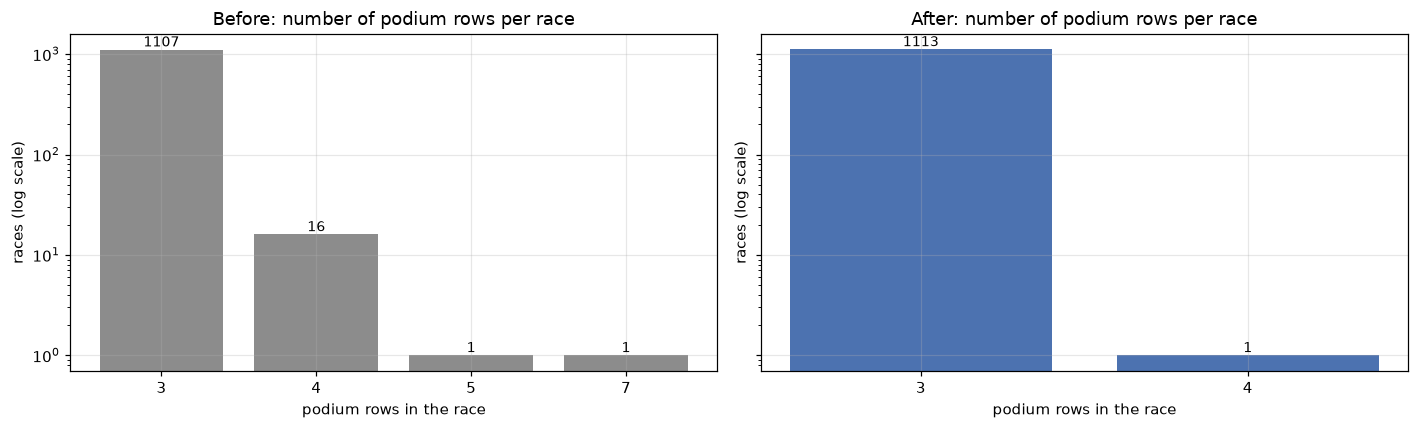

In [43]:
raw_res = RAW["results"].assign(grid=lambda d: d["grid"].astype(int), positionOrder=lambda d: d["positionOrder"].astype(int))
raw_res["podium"] = (raw_res["positionOrder"] <= 3).astype(int)
raw_res = raw_res.merge(RAW["races"][["raceId", "year"]], on="raceId").assign(year=lambda d: d["year"].astype(int))
BEFORE_COLOR, AFTER_COLOR = "#8C8C8C", "#4C72B0"


def before_after(title, figsize=(13, 4), sharey=True):
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=sharey)
    axes[0].set_title(f"Before: {title}")
    axes[1].set_title(f"After: {title}")
    return fig, axes


fig, axes = before_after("number of podium rows per race")
for ax, df, color in [(axes[0], raw_res, BEFORE_COLOR), (axes[1], results_full, AFTER_COLOR)]:
    counts = df.groupby("raceId")["podium"].sum().value_counts().sort_index()
    bars = ax.bar(counts.index.astype(str), counts.values, color=color)
    ax.bar_label(bars, fontsize=9)
    ax.set_yscale("log")
    ax.set_xlabel("podium rows in the race")
    ax.set_ylabel("races (log scale)")
plt.tight_layout()
plt.show()

**Podium rows per race:** before cleaning, 18 races had 4, 5 or 7 "podium" rows (shared drives counted the same driver twice); after the non-starter and duplicate rules and removing the Indianapolis 500, 1,113 of the 1,114 races have exactly 3. The one left with 4 is the 1955 Argentine GP, where two *different* drivers share one car's 3rd place.

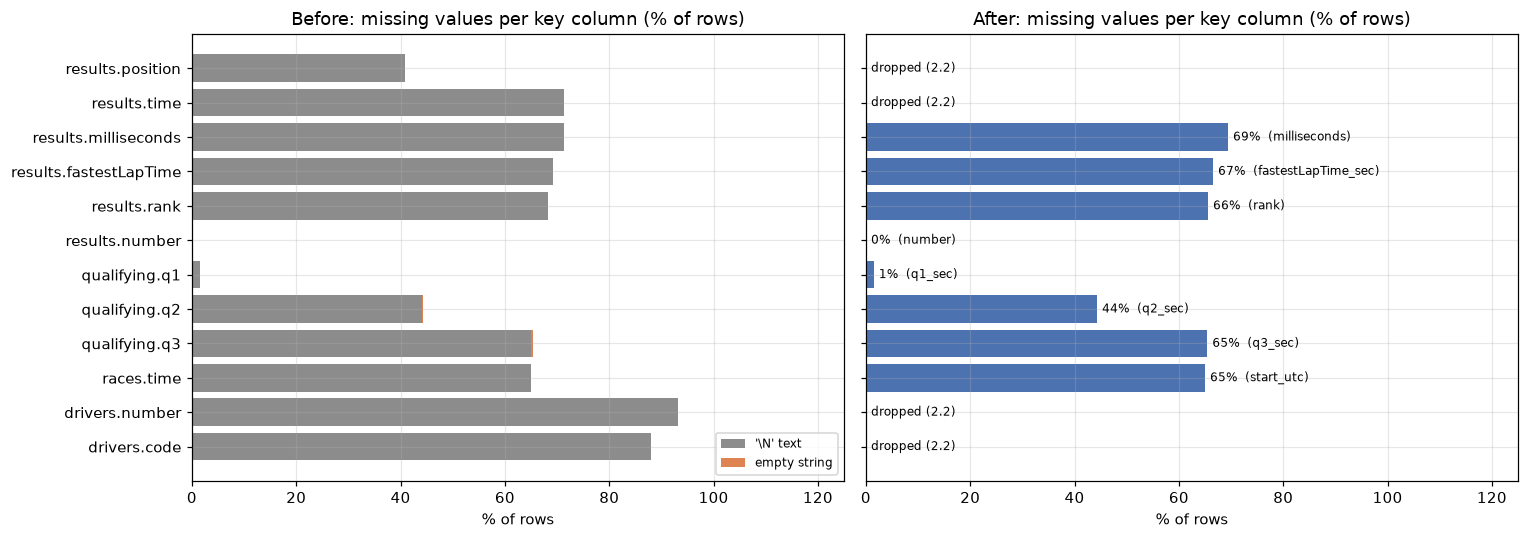

,column,raw '\N',raw empty string,raw missing %,clean column,clean NaN,clean NaN %
0,results.position,10953,0,40.9,dropped,NaN,NaN
1,results.time,19079,0,71.3,dropped,NaN,NaN
2,results.milliseconds,19079,0,71.3,milliseconds,17100.0,69.4
3,results.fastestLapTime,18507,0,69.2,fastestLapTime_sec,16393.0,66.5
4,results.rank,18249,0,68.2,rank,16156.0,65.6
5,results.number,6,0,0.0,number,0.0,0.0
6,qualifying.q1,156,0,1.5,q1_sec,157.0,1.5
7,qualifying.q2,4625,22,44.3,q2_sec,4647.0,44.3
8,qualifying.q3,6819,46,65.4,q3_sec,6865.0,65.4
9,races.time,731,0,65.0,start_utc,731.0,65.0


In [44]:
KEY_COLUMNS = [  # (table, raw column, cleaned column; None = dropped in 2.2)
    ("results", "position", None), ("results", "time", None), ("results", "milliseconds", "milliseconds"),
    ("results", "fastestLapTime", "fastestLapTime_sec"), ("results", "rank", "rank"), ("results", "number", "number"),
    ("qualifying", "q1", "q1_sec"), ("qualifying", "q2", "q2_sec"), ("qualifying", "q3", "q3_sec"),
    ("races", "time", "start_utc"), ("drivers", "number", None), ("drivers", "code", None),
]
rows = []
for t, raw_col, clean_col in KEY_COLUMNS:
    s = RAW[t][raw_col].str.strip()
    rows.append({"column": f"{t}.{raw_col}",
                 "raw '\\N'": int((s == SENTINEL).sum()), "raw empty string": int((s == "").sum()),
                 "raw rows": len(s),
                 "clean column": clean_col or "dropped",
                 "clean NaN": np.nan if clean_col is None else int(CLEAN[t][clean_col].isna().sum()),
                 "clean rows": len(CLEAN[t])})
missing_tbl = pd.DataFrame(rows)
missing_tbl["raw missing %"] = 100 * (missing_tbl["raw '\\N'"] + missing_tbl["raw empty string"]) / missing_tbl["raw rows"]
missing_tbl["clean NaN %"] = 100 * missing_tbl["clean NaN"] / missing_tbl["clean rows"]

fig, axes = before_after("missing values per key column (% of rows)", figsize=(14, 5))
y = np.arange(len(missing_tbl))
sent_pct = 100 * missing_tbl["raw '\\N'"] / missing_tbl["raw rows"]
empty_pct = 100 * missing_tbl["raw empty string"] / missing_tbl["raw rows"]
axes[0].barh(y, sent_pct, color=BEFORE_COLOR, label="'\\N' text")
axes[0].barh(y, empty_pct, left=sent_pct, color="#DD8452", label="empty string")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].barh(y, missing_tbl["clean NaN %"].fillna(0), color=AFTER_COLOR, label="NaN")
for yy, (pct, col) in enumerate(zip(missing_tbl["clean NaN %"], missing_tbl["clean column"])):
    axes[1].text(1 if np.isnan(pct) else pct + 1, yy, "dropped (2.2)" if col == "dropped" else f"{pct:.0f}%  ({col})",
                 va="center", fontsize=8)
axes[0].set_yticks(y, missing_tbl["column"])
axes[0].invert_yaxis()
for ax in axes:
    ax.set_xlim(0, 125)
    ax.set_xlabel("% of rows")
plt.tight_layout()
plt.show()
display(missing_tbl[["column", "raw '\\N'", "raw empty string", "raw missing %", "clean column", "clean NaN", "clean NaN %"]].round(1))

**Missing values:** before cleaning, pandas sees **none** of these gaps because they are the text `\N` (or an empty string in 68 `q2`/`q3` cells); after cleaning they are real `NaN` (for `qualifying` and `races` the counts are identical, plus the 1002.6 s Q1 lap set to NaN), sparse columns like `drivers.number/code` and `results.position/time` are dropped, and the `results` percentages fall slightly because non-starters, who had no times, were removed.

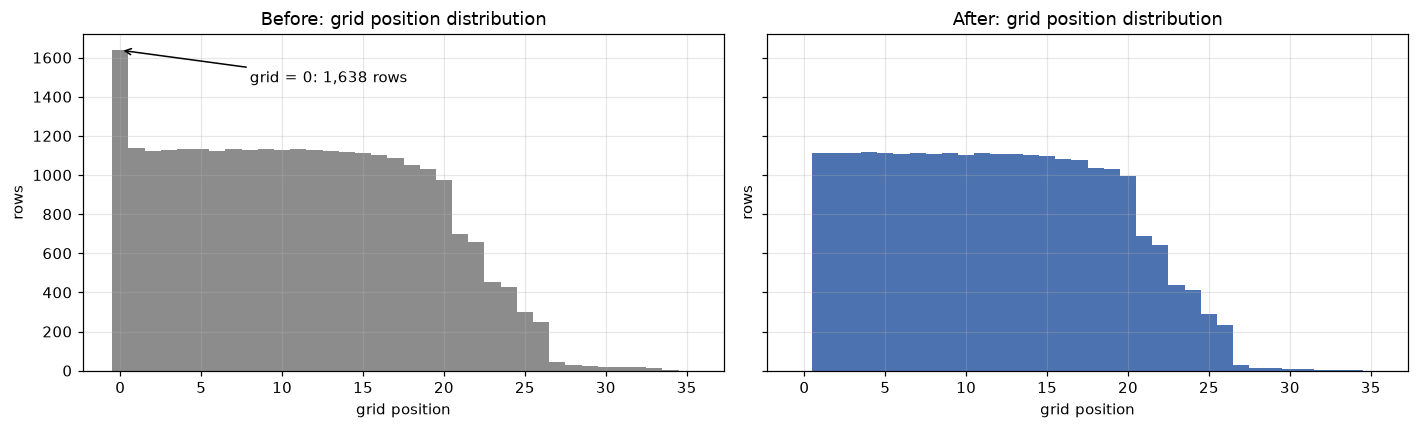

grid = 0 rows: 1,638 before, 0 after; pit-lane starters recoded and flagged: 72


In [45]:
fig, axes = before_after("grid position distribution")
bins = np.arange(-0.5, 36.5, 1)
axes[0].hist(raw_res["grid"], bins=bins, color=BEFORE_COLOR)
axes[1].hist(results_full["grid"].astype(int), bins=bins, color=AFTER_COLOR)
n_zero = int((raw_res["grid"] == 0).sum())
axes[0].annotate(f"grid = 0: {n_zero:,} rows", xy=(0, n_zero), xytext=(8, n_zero * 0.9), arrowprops={"arrowstyle": "->"})
for ax in axes:
    ax.set_xlabel("grid position")
    ax.set_ylabel("rows")
plt.tight_layout()
plt.show()
print(f"grid = 0 rows: {n_zero:,} before, {int((results_full['grid'] == 0).sum())} after; "
      f"pit-lane starters recoded and flagged: {int(results_full['pit_lane_start'].sum())}")

**Grid:** the spike of 1,638 rows at `grid = 0` is gone: 1,566 of them were non-starters and were removed, and the 72 pit-lane starters now sit behind the last car of their race (with `pit_lane_start = True`), so `grid` is a clean ordinal feature where 1 is always the best.

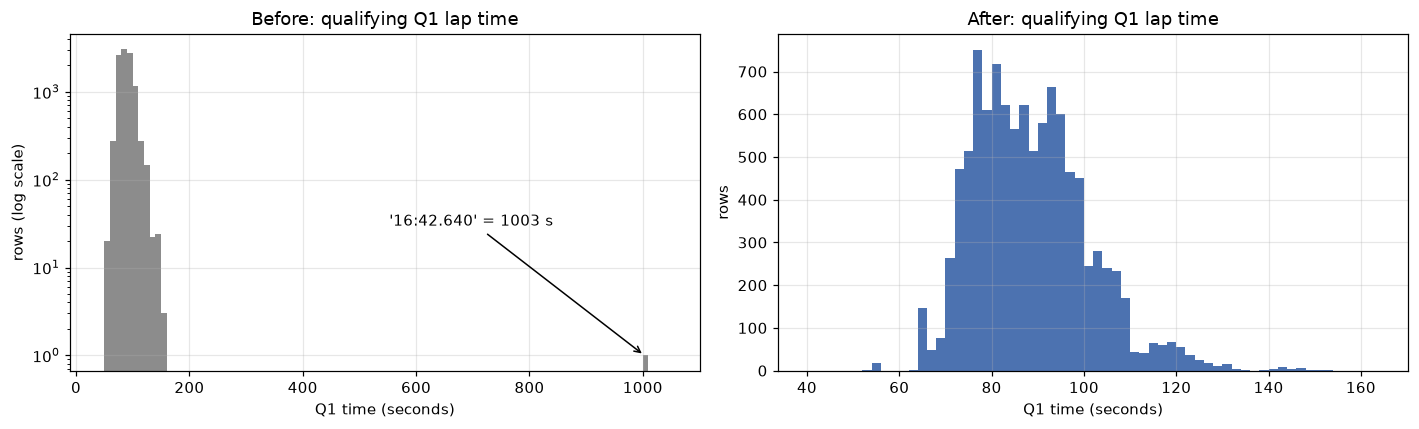

Q1 range before: 53.9-1002.6 s; after: 53.9-153.9 s


In [46]:
q1_raw = RAW["qualifying"]["q1"].map(duration_to_seconds)   # '\N' and '' parse to NaN
q1_clean = CLEAN["qualifying"]["q1_sec"]
outlier = RAW["qualifying"].loc[q1_raw.idxmax()]
fig, axes = before_after("qualifying Q1 lap time", sharey=False)
axes[0].hist(q1_raw.dropna(), bins=np.arange(40, 1060, 10), color=BEFORE_COLOR)
axes[0].set_yscale("log")
axes[0].annotate(f"'{outlier['q1']}' = {q1_raw.max():.0f} s", xy=(q1_raw.max(), 1), xytext=(q1_raw.max() - 450, 30),
                 arrowprops={"arrowstyle": "->"})
axes[1].hist(q1_clean.dropna(), bins=np.arange(40, 165, 2), color=AFTER_COLOR)
axes[0].set_ylabel("rows (log scale)")
axes[1].set_ylabel("rows")
for ax in axes:
    ax.set_xlabel("Q1 time (seconds)")
plt.tight_layout()
plt.show()
print(f"Q1 range before: {q1_raw.min():.1f}-{q1_raw.max():.1f} s; after: {q1_clean.min():.1f}-{q1_clean.max():.1f} s")

**Q1 times:** before cleaning, one Q1 time of `16:42.640` (1002.6 s, Japan 1995) stretches the range to over 16 minutes; after setting it to NaN (2.7) every Q1 time lies between 53.9 and 153.9 s, a plausible range for a flying lap.

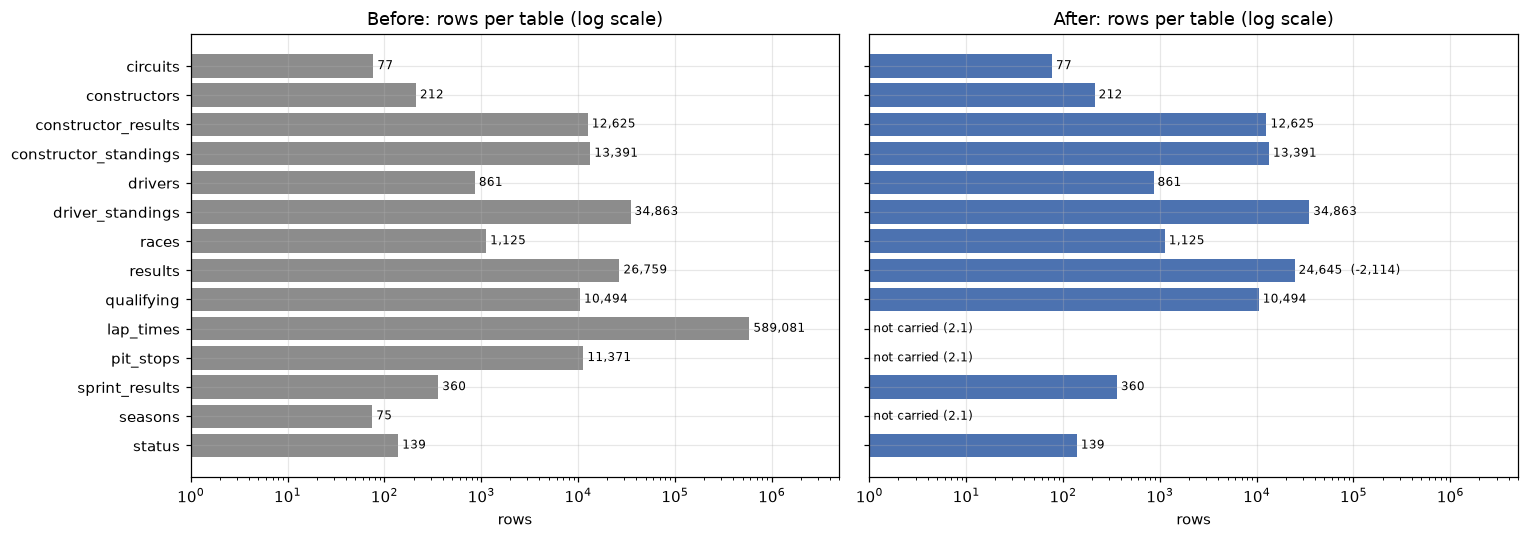

,raw rows,clean rows,removed,note
circuits,77,77,0,
constructors,212,212,0,
constructor_results,12625,12625,0,"cleaned, not used (2.1)"
constructor_standings,13391,13391,0,
drivers,861,861,0,
driver_standings,34863,34863,0,
races,1125,1125,0,
results,26759,24645,2114,
qualifying,10494,10494,0,
lap_times,589081,0,589081,not carried (2.1)


,step,table,rows before,rows after,rows removed,note
0,remove non-starters,results,26759,25114,1645,"non-start status with 0 laps, or grid = 0 with 0 laps"
1,rule B: one row per driver per race,results,25114,25026,88,88 extra rows
2,remove Indianapolis 500 (1950-1960),results,25026,24645,381,"separate US race in the championship: own drivers, 33-ca..."
3,modeling window 2003+,model_base,24645,8934,15711,qualifying coverage ~100% from 2003


In [47]:
rows_tbl = pd.DataFrame({"raw rows": {t: len(RAW[t]) for t in TABLES},
                         "clean rows": {t: len(CLEAN[t]) if t in CLEAN else 0 for t in TABLES}})
rows_tbl["removed"] = rows_tbl["raw rows"] - rows_tbl["clean rows"]
rows_tbl["note"] = ["not carried (2.1)" if t in UNUSED_TABLES else ("cleaned, not used (2.1)" if t in DEFERRED_TABLES else "")
                    for t in rows_tbl.index]

fig, axes = before_after("rows per table (log scale)", figsize=(14, 5))
y = np.arange(len(rows_tbl))
axes[0].barh(y, rows_tbl["raw rows"], color=BEFORE_COLOR)
axes[1].barh(y, rows_tbl["clean rows"].replace(0, np.nan), color=AFTER_COLOR)
for yy, (t, r) in enumerate(rows_tbl.iterrows()):
    axes[0].text(r["raw rows"] * 1.1, yy, f"{r['raw rows']:,}", va="center", fontsize=8)
    label = r["note"] if t in UNUSED_TABLES else f"{r['clean rows']:,}" + (f"  (-{r['removed']:,})" if r["removed"] else "")
    axes[1].text(max(r["clean rows"], 1) * 1.1, yy, label, va="center", fontsize=8)
axes[0].set_yticks(y, rows_tbl.index)
axes[0].invert_yaxis()
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlim(1, 5e6)
    ax.set_xlabel("rows")
plt.tight_layout()
plt.show()
display(rows_tbl)
display(pd.DataFrame(cleaning_log))

**Rows per table:** only `results` loses rows (26,759 → 24,645: 1,645 non-starters, 88 duplicate rows and 381 Indianapolis 500 rows, see the step table); `seasons`, `lap_times` and `pit_stops` are not carried, and every other table keeps all its rows (only values and types changed).

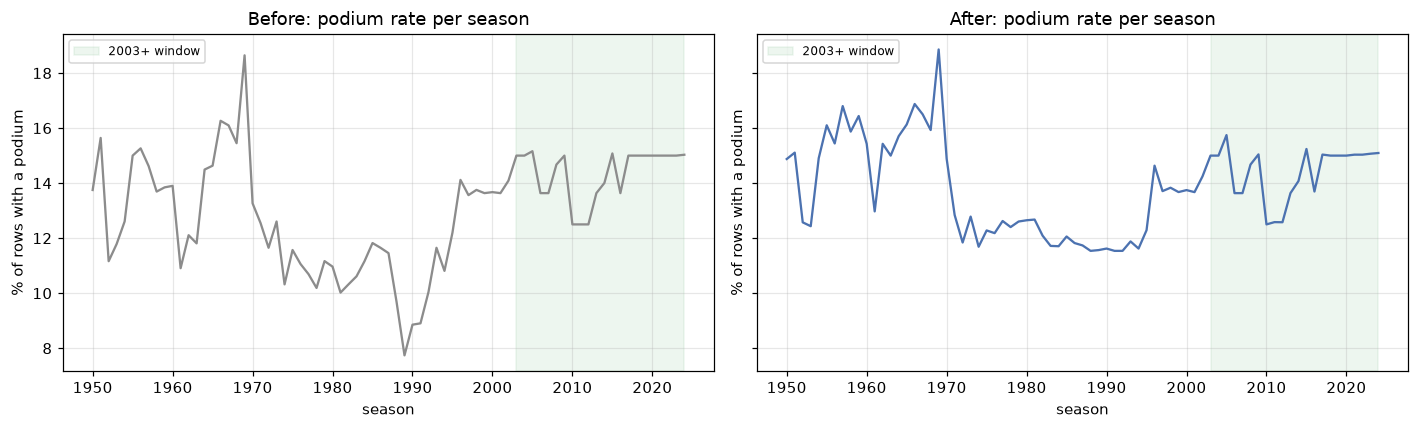

In [48]:
fig, axes = before_after("podium rate per season")
for ax, df, color in [(axes[0], raw_res, BEFORE_COLOR), (axes[1], results_full, AFTER_COLOR)]:
    rate = 100 * df.groupby("year")["podium"].mean()
    ax.plot(rate.index, rate.values, color=color)
    ax.axvspan(MODEL_START_YEAR, 2024, color="#55A868", alpha=0.1, label="2003+ window")
    ax.set_xlabel("season")
    ax.set_ylabel("% of rows with a podium")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Podium rate per season:** before cleaning, seasons with many non-qualifiers (late 1980s, as low as ~8%) look artificially weak because cars that never started sit in the denominator; after cleaning the rate follows 3 ÷ number of starters (about 11.5–19%), and inside the 2003+ window it barely changes, so the modeling data was mostly clean already.

## 2.12 Raw data still untouched

In [49]:
after = {t: hashlib.sha256(read_raw_bytes(t)).hexdigest() for t in TABLES}
assert all(after[t] == RAW_FINGERPRINT[t] for t in TABLES), "A raw file changed during cleaning!"
print(f"All {len(TABLES)} raw files are still byte-identical after cleaning (SHA-256).")

All 14 raw files are still byte-identical after cleaning (SHA-256).


## 2.13 Cleaned tables in memory

`CLEAN_TABLES` holds independent copies of all 15 cleaned tables. Values and dtypes are checked exactly. `load_clean()` returns a fresh copy for later analysis; raw CSVs remain immutable.

In [50]:
import json



# file -> (table, key, description)
EXPORT = {
    "model_base": (model_base, "raceId + driverId",
                   "Modeling base, 2003+: one row per driver per race, pre-race columns + target `podium` only."),
    "results_full": (results_full, "raceId + driverId",
                     "All cleaned driver-races 1950-2024 (no Indianapolis 500), with race info and post-race columns. "
                     "Used by the data-engineering questions. Post-race columns are never features."),
    "results": (CLEAN["results"], "resultId (and raceId + driverId)",
                "Cleaned results: target, non-starters removed, rule B, pit-lane grid recode, status + category."),
    "qualifying": (CLEAN["qualifying"], "qualifyId (and raceId + driverId)",
                   "q1/q2/q3 as seconds (`*_sec`); empty strings and the 1002.6 s outlier are NaN. Missing q2/q3 = knocked out."),
    "races": (CLEAN["races"], "raceId", "date as a date; start_utc where the start time is recorded (2005+)."),
    "drivers": (CLEAN["drivers"], "driverId", "dob as a date; nationality fixed; home_country for Q2."),
    "constructors": (CLEAN["constructors"], "constructorId", "Teams."),
    "circuits": (CLEAN["circuits"], "circuitId", "'United States' merged into 'USA'."),
    "status": (CLEAN["status"], "statusId", "status_category: finished / mechanical / accident / regulation / driver / unclear."),
    "driver_standings": (CLEAN["driver_standings"], "driverStandingsId (and raceId + driverId)",
                         "Standings AFTER each race (post-race, leakage!). Use driver_standings_prerace for features."),
    "constructor_standings": (CLEAN["constructor_standings"], "constructorStandingsId (and raceId + constructorId)",
                              "Standings AFTER each race (post-race, leakage!). Use constructor_standings_prerace for features."),
    "driver_standings_prerace": (CLEAN["driver_standings_prerace"], "raceId + driverId",
                                 "Leakage-safe: standings after the previous round, keyed by the race being predicted. Round 1 has no row."),
    "constructor_standings_prerace": (CLEAN["constructor_standings_prerace"], "raceId + constructorId",
                                      "Leakage-safe: standings after the previous round, keyed by the race being predicted. Round 1 has no row."),
    "sprint_results": (CLEAN["sprint_results"], "resultId (and raceId + driverId)",
                       "Cleaned but not used yet (optional feature later)."),
    "constructor_results": (CLEAN["constructor_results"], "constructorResultsId", "Cleaned but not used."),
}

CLEAN_TABLES = {name: df.reset_index(drop=True).copy(deep=True) for name, (df, _, _) in EXPORT.items()}

def load_clean(name, folder=None):
    """Independent copy of a cleaned table; raw files are never changed."""
    return CLEAN_TABLES[name].copy(deep=True)

for name, (df, _, _) in EXPORT.items():
    pd.testing.assert_frame_equal(load_clean(name), df.reset_index(drop=True), check_exact=True)
display(pd.DataFrame([{"table": name, "rows": len(df), "columns": len(df.columns), "key": key}
                      for name, (df, key, _) in EXPORT.items()]))


,table,rows,columns,key
0,model_base,8934,10,raceId + driverId
1,results_full,24645,24,raceId + driverId
2,results,24645,19,resultId (and raceId + driverId)
3,qualifying,10494,8,qualifyId (and raceId + driverId)
4,races,1125,7,raceId
5,drivers,861,7,driverId
6,constructors,212,4,constructorId
7,circuits,77,4,circuitId
8,status,139,3,statusId
9,driver_standings,34863,6,driverStandingsId (and raceId + driverId)


In [51]:
print("Cleaned tables retained in CLEAN_TABLES; values and dtypes verified exactly.")


Cleaned tables retained in CLEAN_TABLES; values and dtypes verified exactly.


The three data-engineering questions use the verified cleaned tables in memory. No generated data files are required.

# 3. Data-Engineering Questions

Each question uses independent copies of the **cleaned in-memory tables** from section 2.13, accessed through `load_clean()`, using multi-table joins. For every question we state:
- **Tables & joins:** which tables are combined, and on which keys.
- **Grain:** what one row represents.
- **Missingness:** what is missing and how it is handled.
- **Cutoff:** whether the pre-race cutoff matters.

Then come the result, a plot, and a plain-language answer.

In [52]:
results_full_c = load_clean("results_full", None)
races_c = load_clean("races", None)
qualifying_c = load_clean("qualifying", None)
drivers_c = load_clean("drivers", None)
circuits_c = load_clean("circuits", None)[["circuitId", "name", "country"]].rename(columns={"name": "circuit"})
constructors_c = (load_clean("constructors", None)[["constructorId", "name"]]
                  .rename(columns={"name": "constructor"}))
race_info_c = races_c[["raceId", "year", "round", "date", "circuitId", "name"]].rename(columns={"name": "race_name"})
quali_pos = qualifying_c[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})

# Checks on what we loaded: keys unique and non-null, and every foreign key found.
for name, df, key in [("results_full", results_full_c, ["raceId", "driverId"]), ("races", races_c, ["raceId"]),
                      ("qualifying", qualifying_c, ["raceId", "driverId"]), ("drivers", drivers_c, ["driverId"]),
                      ("circuits", circuits_c, ["circuitId"]), ("constructors", constructors_c, ["constructorId"])]:
    assert df[key].notna().all().all() and not df.duplicated(key).any(), name
for col, parent in [("circuitId", circuits_c), ("driverId", drivers_c), ("constructorId", constructors_c)]:
    assert results_full_c[col].isin(parent[col]).all(), col
assert results_full_c["raceId"].isin(races_c["raceId"]).all()
assert results_full_c["status_category"].notna().all()

display(pd.DataFrame({"rows": [len(results_full_c), len(races_c), len(qualifying_c), len(drivers_c),
                               len(circuits_c), len(constructors_c)]},
                     index=["results_full", "races", "qualifying", "drivers", "circuits", "constructors"]))

,rows
results_full,24645
races,1125
qualifying,10494
drivers,861
circuits,77
constructors,212


## 3.1 Q1: Which circuits convert a front-row start into a podium most often, and did that change in the hybrid era (2014+)?

**In simple words:** if a driver starts in the first two places, how often does he finish in the top three, and at which tracks is that most likely?

- **Tables & joins:** `CLEAN_TABLES["results_full"]` (grid, podium, circuit, year) ⟶ `CLEAN_TABLES["qualifying"]` on `raceId + driverId` (qualifying position) ⟶ `CLEAN_TABLES["circuits"]` on `circuitId` (circuit name).
- **Grain:** one row = one driver in one race.
- **Two definitions of "front row"**, because they differ (penalties):
  - **started** on the front row = `grid` 1 or 2 (the main answer: it's where the car actually lined up);
  - **qualified** on the front row = qualifying position 1 or 2 (shown for comparison).
- **Missingness:** qualifying is complete only from 2003 (1.7), so the comparison is **2003–2013 (pre-hybrid) vs 2014–2024 (hybrid)**. Circuits need **≥ 8 front-row starts in each era** (about 4 races) so a single race doesn't decide the ranking.
- **Cutoff:** grid and qualifying are known before the race, so both are valid "starting" information.

In [53]:
ERAS = ["2003-2013 (pre-hybrid)", "2014-2024 (hybrid)"]
q1 = (results_full_c[results_full_c["year"] >= 2003]
      .merge(quali_pos, on=["raceId", "driverId"], how="left", validate="one_to_one")
      .merge(circuits_c, on="circuitId", how="left", validate="many_to_one"))
q1["era"] = np.where(q1["year"] >= 2014, ERAS[1], ERAS[0])

started_fr = q1[q1["grid"] <= 2]
qualified_fr = q1[q1["quali_pos"] <= 2]
print(f"Front-row qualifiers who did NOT start on the front row (penalties): {int((qualified_fr['grid'] > 2).sum())}")
print(f"Front-row starters who did NOT qualify on the front row (moved up):  {int((started_fr['quali_pos'] > 2).sum())}")

overall = pd.DataFrame({
    "front-row starts": started_fr.groupby("era").size(),
    "podium % (started front row)": (100 * started_fr.groupby("era")["podium"].mean()).round(1),
    "podium % (qualified front row)": (100 * qualified_fr.groupby("era")["podium"].mean()).round(1),
})
display(overall)

MIN_STARTS = 8
by_start = started_fr.groupby(["circuit", "era"])["podium"].agg(["size", "mean"]).unstack("era")
by_quali = qualified_fr.groupby(["circuit", "era"])["podium"].mean().unstack("era")
keep = (by_start["size"].reindex(columns=ERAS) >= MIN_STARTS).all(axis=1)

rates = (100 * by_start["mean"].loc[keep, ERAS]).round(1)
q1_table = pd.concat({
    "podium % (started FR)": rates,
    "rank": rates.rank(ascending=False, method="min").astype(int),
    "podium % (qualified FR)": (100 * by_quali.loc[keep, ERAS]).round(1),
    "front-row starts": by_start["size"].loc[keep, ERAS].astype(int),
}, axis=1).sort_values(("podium % (started FR)", ERAS[1]), ascending=False)
display(q1_table)

rank_corr = rates[ERAS[0]].corr(rates[ERAS[1]], method="spearman")
print(f"{keep.sum()} circuits compared. Rank correlation between eras (Spearman): {rank_corr:.2f}  (1 = same order, 0 = unrelated)")

Front-row qualifiers who did NOT start on the front row (penalties): 36
Front-row starters who did NOT qualify on the front row (moved up):  36


,front-row starts,podium % (started front row),podium % (qualified front row)
era,,,
2003-2013 (pre-hybrid),398,68.3,67.6
2014-2024 (hybrid),454,76.0,74.0


podium % (started FR)                                      rank                    podium % (qualified FR)                          front-row starts                   
era                            2003-2013 (pre-hybrid) 2014-2024 (hybrid) 2003-2013 (pre-hybrid) 2014-2024 (hybrid)  2003-2013 (pre-hybrid) 2014-2024 (hybrid) 2003-2013 (pre-hybrid) 2014-2024 (hybrid)
circuit                                                                                                                                                                                                
Suzuka Circuit                                   72.2               88.9                      4                  1                    72.2               88.9                     18                 18
Yas Marina Circuit                               60.0               86.4                     12                  2                    60.0               81.8                     10                 22
Circuit de Monaco                                77.3               85.0                      1                  3                    68.2               85.0                     22                 20
Circuit de Barcelona-Catalunya                   68.2               81.8                      7                  4                    63.6               81.8                     22                 22
Circuit de Spa-Francorchamps                     72.2               81.8                      4                  4                    72.2               81.8                     18                 22
Autódromo José Carlos Pace                       59.1               78.9                     14                  6                    59.1               68.4                     22                 19
Shanghai International Circuit                   65.0               78.6                      9                  7                    70.0               78.6                     20                 14
Circuit Gilles Villeneuve                        60.0               77.8                     12                  8                    60.0               72.2                     20                 18
Silverstone Circuit                              72.7               75.0                      3                  9                    77.3               75.0                     22                 24
Autodromo Enzo e Dino Ferrari                    62.5               75.0                     11                  9                    62.5               62.5                      8                  8
Autodromo Nazionale di Monza                     77.3               72.7                      1                 11                    72.7               72.7                     22                 22
Albert Park Grand Prix Circuit                   59.1               72.2                     14                 12                    59.1               72.2                     22                 18
Marina Bay Street Circuit                        58.3               72.2                     16                 12                    58.3               72.2                     12                 18
Bahrain International Circuit                    66.7               66.7                      8                 14                    66.7               66.7                     18                 24
Hockenheimring                                   71.4               62.5                      6                 15                    71.4               62.5                     14                  8
Hungaroring                                      63.6               59.1                     10                 16                    59.1               59.1                     22                 22

16 circuits compared. Rank correlation between eras (Spearman): 0.21  (1 = same order, 0 = unrelated)


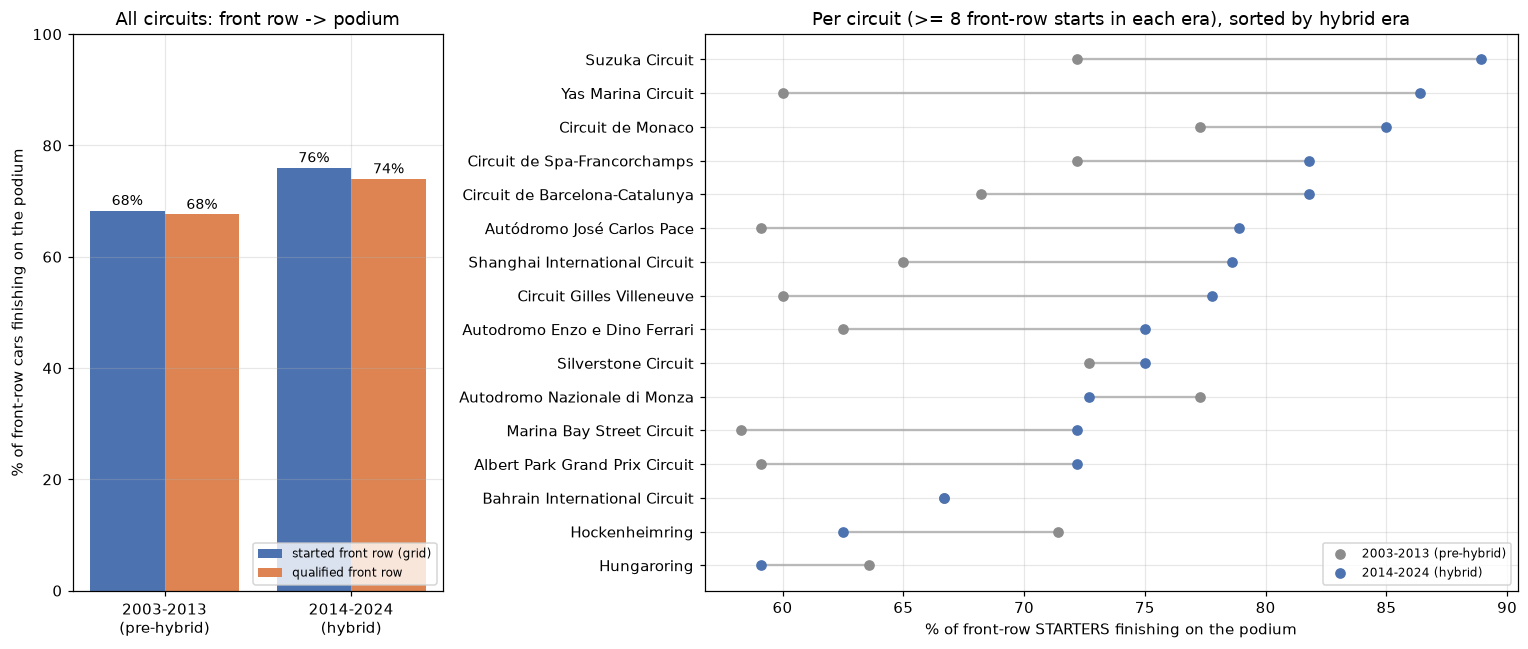

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 2.2]})

x = np.arange(len(ERAS))
axes[0].bar(x - 0.2, overall["podium % (started front row)"], 0.4, label="started front row (grid)", color="#4C72B0")
axes[0].bar(x + 0.2, overall["podium % (qualified front row)"], 0.4, label="qualified front row", color="#DD8452")
for i, (a, b) in enumerate(zip(overall["podium % (started front row)"], overall["podium % (qualified front row)"])):
    axes[0].text(i - 0.2, a + 1, f"{a:.0f}%", ha="center", fontsize=9)
    axes[0].text(i + 0.2, b + 1, f"{b:.0f}%", ha="center", fontsize=9)
axes[0].set_xticks(x, [e.replace(" (", "\n(") for e in ERAS])
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("% of front-row cars finishing on the podium")
axes[0].set_title("All circuits: front row -> podium")
axes[0].legend(fontsize=8, loc="lower right")

plot_rates = rates.sort_values(ERAS[1])
y = np.arange(len(plot_rates))
axes[1].hlines(y, plot_rates[ERAS[0]], plot_rates[ERAS[1]], color="#BBBBBB", zorder=1)
axes[1].scatter(plot_rates[ERAS[0]], y, color="#8C8C8C", label=ERAS[0], zorder=2)
axes[1].scatter(plot_rates[ERAS[1]], y, color="#4C72B0", label=ERAS[1], zorder=3)
axes[1].set_yticks(y, plot_rates.index)
axes[1].set_xlabel("% of front-row STARTERS finishing on the podium")
axes[1].set_title(f"Per circuit (>= {MIN_STARTS} front-row starts in each era), sorted by hybrid era")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Answer to Q1.**
- **Overall:** a front-row start turns into a podium about **7 times out of 10**. It became **more reliable in the hybrid era** (≈ 68% → 76%): with dominant teams and more reliable cars, the drivers at the front usually stay there.
- **Most "converting" circuits in the hybrid era:** **Suzuka, Yas Marina (Abu Dhabi) and Monaco** (≈ 85–89%). Monaco makes sense because overtaking there is almost impossible.
- **Before 2014** the top three were **Monaco, Monza and Silverstone**.
- **The ranking did change a lot:** the rank correlation between the two eras is only about **0.2**, so a circuit's position in the list before 2014 says little about its position after. Monza and Hockenheim dropped, and Yas Marina and Interlagos rose sharply. Monaco stays near the top in both.
- **Qualifying position vs grid:** 36 front-row qualifiers started further back (grid penalties), and 36 others were promoted onto the front row. Counting by qualifying instead of grid changes the overall rate only slightly (71% vs 72%), but it changes some individual circuits, which is why both columns are shown.

*Caution:* each circuit has only ~10–24 front-row starts per era, so one race can move a circuit's rate by 5–10 points. Treat close rankings as ties.

### 3.1.1 Robustness check: starting position only, all seasons (1950–2024)

`grid` exists for every season, so Q1 could be answered from grid alone, with "before 2014" meaning **1950–2013** instead of 2003–2013.
Does that give a different (or better) answer?

Front-row conversion 1950-2013: 56.0%  vs 2003-2013: 68.3%
Rank correlation, 1950-2013 vs hybrid era: -0.07
Rank correlation between the two 'pre-2014' versions (16 common circuits): -0.14


**Top 5 circuits before 2014, under each definition**

,"1950-2013 (grid only, all years)",2003-2013 (main answer)
0,Suzuka Circuit,Autodromo Nazionale di Monza
1,Hungaroring,Circuit de Monaco
2,Bahrain International Circuit,Silverstone Circuit
3,Circuit de Barcelona-Catalunya,Circuit de Spa-Francorchamps
4,Shanghai International Circuit,Suzuka Circuit


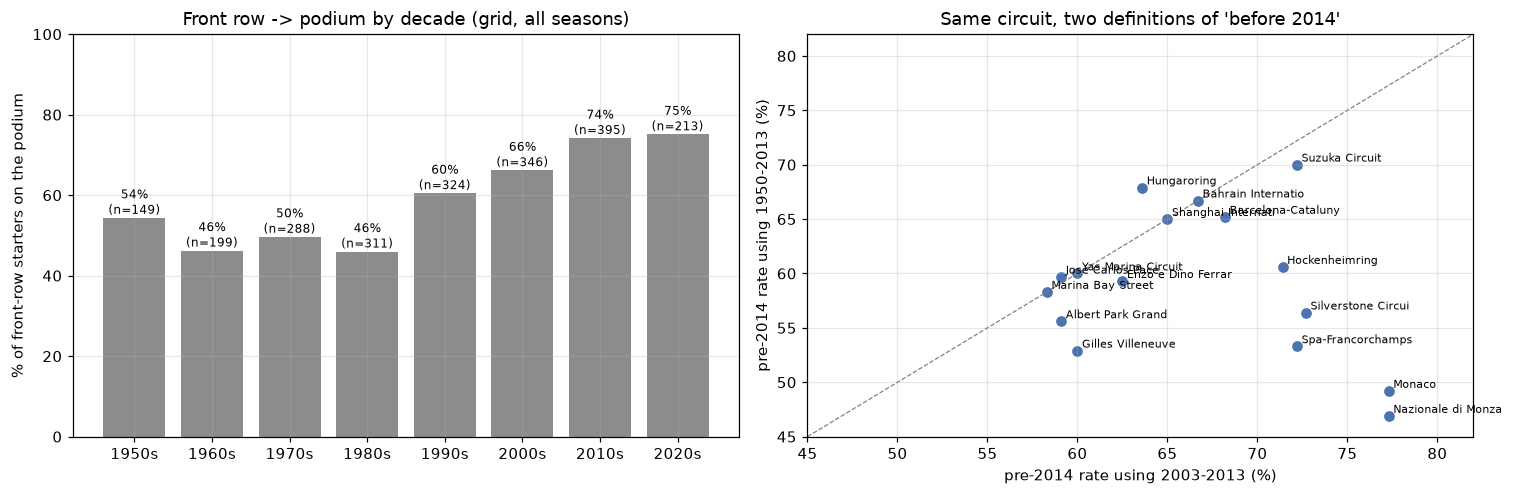

In [55]:
ERAS_ALL = ["1950-2013 (all pre-hybrid)", "2014-2024 (hybrid)"]
q1_all = results_full_c.merge(circuits_c, on="circuitId", how="left", validate="many_to_one")
q1_all["era"] = np.where(q1_all["year"] >= 2014, ERAS_ALL[1], ERAS_ALL[0])
fr_all = q1_all[q1_all["grid"] <= 2]

by_decade = fr_all.assign(decade=fr_all["year"] // 10 * 10).groupby("decade")["podium"].agg(["size", "mean"])
by_all = fr_all.groupby(["circuit", "era"])["podium"].agg(["size", "mean"]).unstack("era")
keep_all = (by_all["size"].reindex(columns=ERAS_ALL) >= MIN_STARTS).all(axis=1)
rates_all = (100 * by_all["mean"].loc[keep_all, ERAS_ALL]).round(1)

pre_compare = pd.concat({"pre-2014 = 1950-2013": rates_all[ERAS_ALL[0]],
                         "pre-2014 = 2003-2013": rates[ERAS[0]]}, axis=1).dropna()
print(f"Front-row conversion 1950-2013: {100 * fr_all.loc[fr_all['era'] == ERAS_ALL[0], 'podium'].mean():.1f}%  "
      f"vs 2003-2013: {overall.loc[ERAS[0], 'podium % (started front row)']}%")
print(f"Rank correlation, 1950-2013 vs hybrid era: {rates_all[ERAS_ALL[0]].corr(rates_all[ERAS_ALL[1]], method='spearman'):.2f}")
print(f"Rank correlation between the two 'pre-2014' versions ({len(pre_compare)} common circuits): "
      f"{pre_compare.iloc[:, 0].corr(pre_compare.iloc[:, 1], method='spearman'):.2f}")

display(Markdown("**Top 5 circuits before 2014, under each definition**"))
display(pd.DataFrame({
    "1950-2013 (grid only, all years)": rates_all[ERAS_ALL[0]].sort_values(ascending=False).head(5).index,
    "2003-2013 (main answer)": rates[ERAS[0]].sort_values(ascending=False).head(5).index,
}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].bar(by_decade.index.astype(str) + "s", 100 * by_decade["mean"], color="#8C8C8C")
for i, (v, n) in enumerate(zip(by_decade["mean"], by_decade["size"])):
    axes[0].text(i, 100 * v + 1, f"{100 * v:.0f}%\n(n={n})", ha="center", fontsize=8)
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("% of front-row starters on the podium")
axes[0].set_title("Front row -> podium by decade (grid, all seasons)")

axes[1].scatter(pre_compare.iloc[:, 1], pre_compare.iloc[:, 0], color="#4C72B0")
for name, (v_all, v_modern) in pre_compare.iterrows():
    short = name.replace("Circuit de ", "").replace("Circuit ", "").replace("Autodromo ", "").replace("Autódromo ", "")[:18]
    axes[1].annotate(short, (v_modern, v_all), fontsize=7, xytext=(3, 2), textcoords="offset points")
lims = [45, 82]
axes[1].plot(lims, lims, ls="--", color="grey", lw=0.8)
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_xlabel("pre-2014 rate using 2003-2013 (%)")
axes[1].set_ylabel("pre-2014 rate using 1950-2013 (%)")
axes[1].set_title("Same circuit, two definitions of 'before 2014'")
plt.tight_layout()
plt.show()

**What the robustness check shows.**
- **The conversion rate depends strongly on the decade:** about **46–54%** from the 1950s to the 1980s, rising to **74–75%** since 2010. Older cars broke down far more often, so even a front-row car often didn't finish.
- Because of this, **"before 2014" = 1950–2013 mostly measures how old a circuit is**:
  - Classic circuits (Monza, Silverstone, Monaco) carry decades of unreliable-era races, which pulls their rate down.
  - Newer circuits (Bahrain, Shanghai) only have modern races, so they look better.

  That's why the two "before 2014" rankings disagree (rank correlation about **−0.1**). The all-years version would also exaggerate the hybrid-era change (56% → 76% instead of 68% → 76%).
- **The hybrid-era (2014–2024) answer barely depends on this choice:** Suzuka, Yas Marina and Monaco stay at the top. Zandvoort also appears, because its 1950s–80s races let it pass the minimum-sample rule.
- **Decision:** the main answer keeps **2003–2013 vs 2014–2024**. Both periods are modern, comparable, and have qualifying data, which the question explicitly asks us to distinguish from grid. The all-years version is reported as a limitation: it compares eras more than circuits.

### 3.1.2 Why the qualifying table is still needed (beyond the brief asking for it)

Grid is the starting position, so it's the primary measure. The question is whether **qualifying adds information that grid hides**.

Since 2003, grid differs from qualifying position in 27% of rows.


,podium %
"qualified top 3, started 6th+ (n=47)",31.9
others starting from the same slots (n=5084),3.4


,faster half,slower half,n
grid,,,
2,69.5,60.8,425
3,50.9,51.2,427
4,37.4,27.7,427
5,26.6,15.0,428


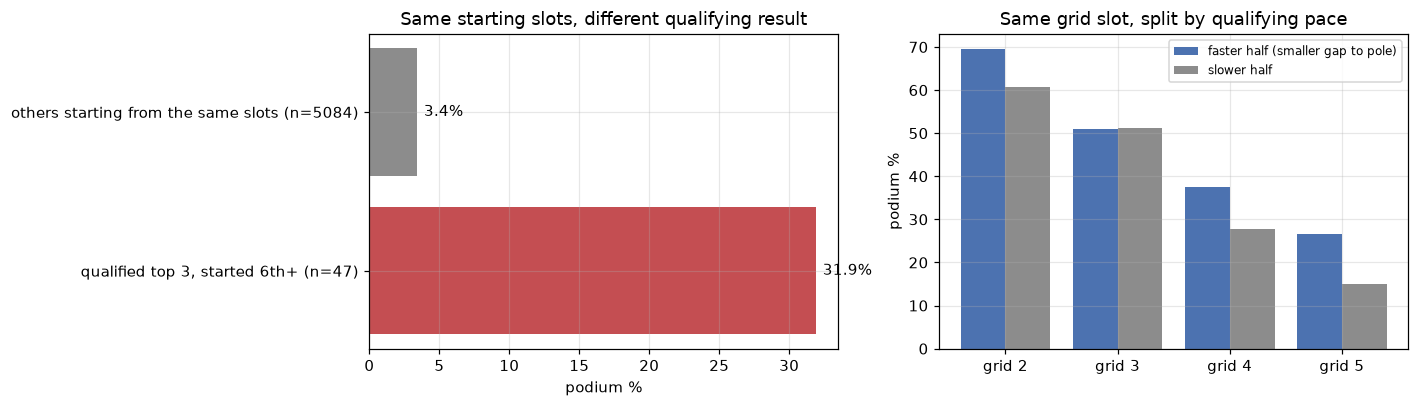

In [56]:
q_best = qualifying_c[["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].copy()
q_best["best_sec"] = q_best[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
q_best["gap_to_pole_pct"] = 100 * (q_best["best_sec"] / q_best.groupby("raceId")["best_sec"].transform("min") - 1)
qg = results_full_c[results_full_c["year"] >= 2003].merge(q_best[["raceId", "driverId", "position", "gap_to_pole_pct"]],
                                                      on=["raceId", "driverId"], how="left", validate="one_to_one")
print(f"Since 2003, grid differs from qualifying position in {100 * (qg['grid'] != qg['position'])[qg['position'].notna()].mean():.0f}% of rows.")

# (1) Penalised fast cars: qualified top 3, started 6th or worse
penalised = qg[(qg["position"] <= 3) & (qg["grid"] >= 6)]
same_slots = qg[qg["grid"].isin(penalised["grid"].unique()) & (qg["position"] > 3)]
penalty_view = pd.Series({
    f"qualified top 3, started 6th+ (n={len(penalised)})": 100 * penalised["podium"].mean(),
    f"others starting from the same slots (n={len(same_slots)})": 100 * same_slots["podium"].mean(),
}).round(1)

# (2) Same grid slot, faster vs slower half by gap to pole
gap_rows = []
for slot in [2, 3, 4, 5]:
    s = qg[(qg["grid"] == slot) & qg["gap_to_pole_pct"].notna()]
    fast = s["gap_to_pole_pct"] <= s["gap_to_pole_pct"].median()
    gap_rows.append({"grid": slot, "faster half": 100 * s.loc[fast, "podium"].mean(),
                     "slower half": 100 * s.loc[~fast, "podium"].mean(), "n": len(s)})
gap_view = pd.DataFrame(gap_rows).set_index("grid").round(1)
display(penalty_view.to_frame("podium %"))
display(gap_view)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].barh(penalty_view.index, penalty_view.values, color=["#C44E52", "#8C8C8C"])
for i, v in enumerate(penalty_view.values):
    axes[0].text(v + 0.5, i, f"{v:.1f}%", va="center")
axes[0].set_xlabel("podium %")
axes[0].set_title("Same starting slots, different qualifying result")
x = np.arange(len(gap_view))
axes[1].bar(x - 0.2, gap_view["faster half"], 0.4, label="faster half (smaller gap to pole)", color="#4C72B0")
axes[1].bar(x + 0.2, gap_view["slower half"], 0.4, label="slower half", color="#8C8C8C")
axes[1].set_xticks(x, [f"grid {g}" for g in gap_view.index])
axes[1].set_ylabel("podium %")
axes[1].set_title("Same grid slot, split by qualifying pace")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**What this shows.**
- **Penalties hide fast cars.** Drivers who qualified in the **top 3** but started **6th or worse** (grid penalties) still reached the podium about **32%** of the time. Other drivers starting from the same slots managed only about **3%**. Using grid alone, those fast cars look like midfield cars.
- **Qualifying shows how fast a car is, not just its order.** Among drivers starting from the same slot, the faster half (smaller gap to pole) reaches the podium more often from grid 2, 4 and 5 (e.g. **27% vs 15%** from grid 5). Grid 3 is the exception, with no difference. Grid is only a rank, while qualifying times measure the gap.
- **So we use both:** `grid` as the starting position (the main measure, all seasons), and qualifying for the information grid loses. Since 2003, grid and qualifying position differ in about a quarter of rows.
- **Planned modeling experiment:** *Attempt A* = grid only, all seasons vs *Attempt B* = grid + qualifying, 2003+. Both are evaluated on the same recent test seasons. If A is as good as B, the simpler data choice wins. This comparison will be reported in the modeling section.

## 3.2 Q2: Do drivers finish on the podium more often at home, once we account for where they start?

**In simple words:** a British driver at Silverstone, a Dutch driver at Zandvoort... do they do better than usual? To be fair, we must compare drivers who **started from similar places**. Otherwise "home advantage" could just mean "the home driver qualified well".

- **Tables & joins:** `CLEAN_TABLES["results_full"]` ⟶ `CLEAN_TABLES["drivers"]` on `driverId` (`home_country`, built in 2.4) ⟶ `CLEAN_TABLES["circuits"]` on `circuitId` (`country`). **Home race** = `home_country == circuit country`.
- **Grain:** one row = one driver starting one race (all seasons; non-starters were removed in 2.6, and the Indianapolis 500 in 2.6.1).
- **Why no Indianapolis 500:** in 1950–1960 it was a separate American race. Almost every starter was an American at a US circuit (a "home" start), with no away drivers in the same race to compare with. It would have made up 16% of all home starts. The result with Indy put back is shown as a robustness column. Those rows are removed by cleaning, so they are not in the clean files: this one column takes them from memory (`INDY500_RESULTS`, 2.6.1).
- **Controlling for starting position:** drivers are grouped into **grid bands** (1–3, 4–6, 7–10, 11+). Home and away drivers are compared **inside the same band**. The band differences are then averaged, weighted by how many home starts fall in each band ("grid-adjusted difference").
- **Uncertainty:** a bootstrap (resampling the rows 500 times) gives a 95% interval for the adjusted difference.
- **Missingness:** none. Every driver has a `home_country`, and every cleaned row has a valid grid.
- **Cutoff:** grid is pre-race information, so it's a valid control.

In [57]:
nat = drivers_c[["driverId", "home_country"]]
GRID_BANDS = ["1-3", "4-6", "7-10", "11+"]


def home_table(res):
    df = (res.merge(nat, on="driverId", how="left", validate="many_to_one")
          .merge(circuits_c, on="circuitId", how="left", validate="many_to_one"))
    df["home"] = df["home_country"] == df["country"]
    df["grid_band"] = pd.cut(df["grid"].astype(float), [0, 3, 6, 10, 99], labels=GRID_BANDS)
    return df


q2 = home_table(results_full_c)
# Robustness only: put back the Indianapolis 500 rows removed in 2.6.1.
q2_with_indy = home_table(pd.concat([results_full_c, INDY500_RESULTS.merge(race_info_c, on="raceId", how="left")]))


def adjusted_home_diff(df):
    """Home minus away podium rate inside each grid band, averaged with weights = home starts per band."""
    t = df.groupby(["grid_band", "home"], observed=True)["podium"].agg(["mean", "size"]).unstack("home")
    diff = t[("mean", True)] - t[("mean", False)]
    weights = t[("size", True)]
    return (diff * weights).sum() / weights.sum()


def summarize(df):
    rng = np.random.default_rng(42)
    boot = [adjusted_home_diff(df.sample(frac=1, replace=True, random_state=rng)) for _ in range(500)]
    return {
        "home starts": int(df["home"].sum()),
        "podium % home": round(100 * df.loc[df["home"], "podium"].mean(), 1),
        "podium % away": round(100 * df.loc[~df["home"], "podium"].mean(), 1),
        "avg grid home": round(df.loc[df["home"], "grid"].mean(), 1),
        "avg grid away": round(df.loc[~df["home"], "grid"].mean(), 1),
        "raw difference (pts)": round(100 * (df.loc[df["home"], "podium"].mean() - df.loc[~df["home"], "podium"].mean()), 2),
        "grid-adjusted difference (pts)": round(100 * adjusted_home_diff(df), 2),
        "95% interval (pts)": f"[{100 * np.percentile(boot, 2.5):.2f}, {100 * np.percentile(boot, 97.5):.2f}]",
    }


q2_summary = pd.DataFrame({"all seasons (1950-2024)": summarize(q2),
                           "2003-2024 only": summarize(q2[q2["year"] >= 2003]),
                           "robustness: + Indianapolis 500": summarize(q2_with_indy)})
display(q2_summary)

band_table = (q2.groupby(["grid_band", "home"], observed=True)["podium"].agg(["mean", "size"]).unstack("home"))
band_table = pd.DataFrame({
    "podium % away": (100 * band_table[("mean", False)]).round(1),
    "podium % home": (100 * band_table[("mean", True)]).round(1),
    "away starts": band_table[("size", False)],
    "home starts": band_table[("size", True)],
})
display(band_table)

,all seasons (1950-2024),2003-2024 only,robustness: + Indianapolis 500
home starts,1934,365,2314
podium % home,11.6,14.2,11.2
podium % away,13.7,14.4,13.7
avg grid home,12.7,10.7,13.4
avg grid away,11.7,11.0,11.7
raw difference (pts),-2.1,-0.13,-2.49
grid-adjusted difference (pts),-0.6,-1.55,-0.59
95% interval (pts),"[-1.76, 0.56]","[-4.37, 1.32]","[-1.73, 0.59]"


,podium % away,podium % home,away starts,home starts
grid_band,,,,
1-3,55.4,55.8,3109,231
4-6,26.0,26.5,3112,226
7-10,9.3,7.2,4102,334
11+,1.7,1.0,12388,1143


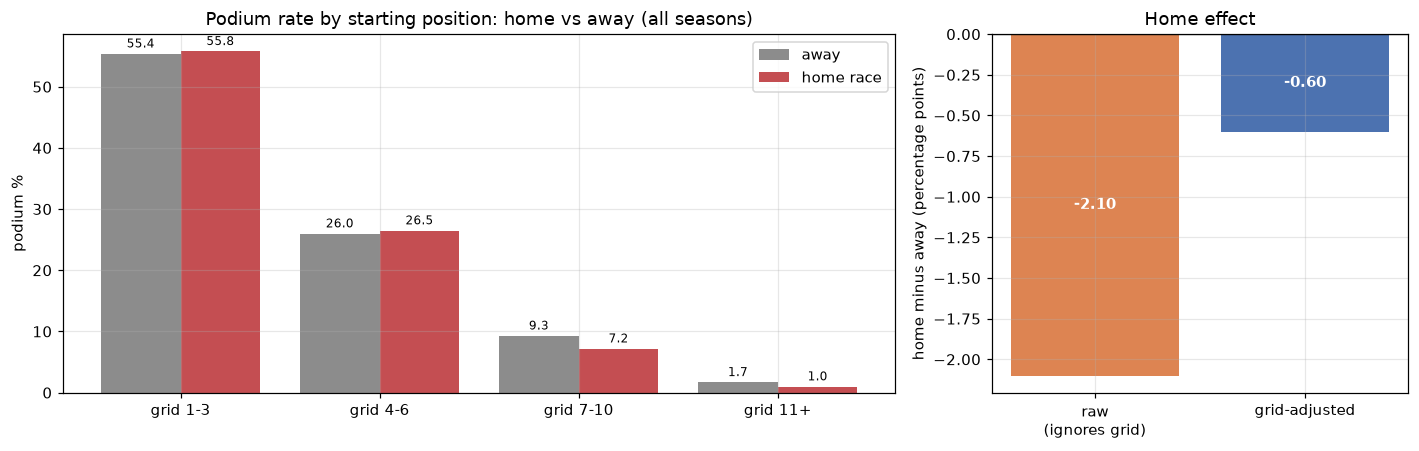

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
x = np.arange(len(GRID_BANDS))
axes[0].bar(x - 0.2, band_table["podium % away"], 0.4, label="away", color="#8C8C8C")
axes[0].bar(x + 0.2, band_table["podium % home"], 0.4, label="home race", color="#C44E52")
for i, (a, h) in enumerate(zip(band_table["podium % away"], band_table["podium % home"])):
    axes[0].text(i - 0.2, a + 1, f"{a:.1f}", ha="center", fontsize=8)
    axes[0].text(i + 0.2, h + 1, f"{h:.1f}", ha="center", fontsize=8)
axes[0].set_xticks(x, [f"grid {b}" for b in GRID_BANDS])
axes[0].set_ylabel("podium %")
axes[0].set_title("Podium rate by starting position: home vs away (all seasons)")
axes[0].legend()

s = q2_summary["all seasons (1950-2024)"]
vals = [s["raw difference (pts)"], s["grid-adjusted difference (pts)"]]
axes[1].bar(["raw\n(ignores grid)", "grid-adjusted"], vals, color=["#DD8452", "#4C72B0"])
axes[1].axhline(0, color="black", lw=0.8)
for i, v in enumerate(vals):
    axes[1].text(i, v / 2, f"{v:+.2f}", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
axes[1].set_ylabel("home minus away (percentage points)")
axes[1].set_title("Home effect")
plt.tight_layout()
plt.show()

**Answer to Q2: No, there is no home advantage once starting position is taken into account.**
- **Without controlling for grid**, home drivers even look *worse* (≈ 11.6% vs 13.7% podiums). That's misleading, because home drivers start further back on average (grid ≈ 12.7 vs 11.7). In older seasons many local drivers entered only their home race in weaker cars.
- **Comparing drivers who started from the same grid band**, the home rate is almost identical to the away rate in **every** band: slightly higher at the front (grid 1–3: ≈ 55.8% home vs 55.4% away; grid 4–6: 26.5% vs 26.0%) and slightly lower further back (grid 7–10: 7.2% vs 9.3%).
- The **grid-adjusted difference is close to zero** (about −0.6 points), and the 95% interval includes 0, so the small gap is consistent with chance. The modern era (2003+) points the same way, and so does the robustness version with the Indianapolis 500 put back (−0.59 points, interval also includes 0).
- **Takeaway:** what looks like a "home effect" is really a **starting-position effect**. Where you start matters a lot; whether you're at home doesn't. For the model this suggests a "home race" feature will add little.

*Note:* controlling with grid bands is a simple, transparent method. Within a band, small grid differences remain, but the per-band rates are so close that a finer control wouldn't change the conclusion.

## 3.3 Q3: Which constructors had the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**In simple words:** out of all the races a team's cars started, how often did one stop because something on the car broke?

- **Data source:** this question uses the cleaned in-memory tables from section 2.13. `results_full` already has the cleaning applied: non-starters, duplicate rows and the Indianapolis 500 removed, and every status mapped to a `status_category` (2.5–2.6).
- **Tables & joins:** `CLEAN_TABLES["results_full"]` ⟶ `CLEAN_TABLES["races"]` on `raceId` (for `year`) ⟶ `CLEAN_TABLES["constructors"]` on `constructorId` (team name).
- **Grain:** one row = one car starting one race. **Rate = mechanical retirements ÷ race starts** for that team in that period.
- **Mechanical retirement:** `status_category == "mechanical"` (engine, gearbox, hydraulics, power unit, ...; 2.5). Crashes, driver problems and regulation decisions are excluded, as the brief defines. Statuses whose cause is unclear (`Retired`, `Wheel`, `Puncture`, `Damage`, ...) are excluded from the main (**strict**) rate and added in the **broad** rate (mechanical + unclear, an upper bound).
- **Missingness:** none. Every status has a category, and non-starters were removed, so the denominator counts real starts only (checked below).
- **Small teams:** only teams with **≥ 40 starts** in a period are ranked. Team names follow the dataset: renamed teams (e.g. Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin) appear as separate entries.
- **Cutoff:** not relevant. This is a historical post-race analysis, not a feature.

In [59]:
# Same clean-data folder as the rest of section 3.
q3_results = results_full_c[["raceId", "driverId", "constructorId", "status", "status_category"]]
q3_races = races_c[["raceId", "year"]]
q3_teams = constructors_c

# Checks on what we loaded: unique grain, no missing categories, every key found.
assert not q3_results.duplicated(["raceId", "driverId"]).any()
assert q3_results["status_category"].notna().all()
assert q3_results["raceId"].isin(q3_races["raceId"]).all()
assert q3_results["constructorId"].isin(q3_teams["constructorId"]).all()

PERIODS = ["2014-2021", "2022-2024"]
q3 = (q3_results
      .merge(q3_races, on="raceId", how="left", validate="many_to_one")
      .merge(q3_teams, on="constructorId", how="left", validate="many_to_one"))
q3 = q3[q3["year"] >= 2014].copy()
q3["period"] = np.where(q3["year"] <= 2021, PERIODS[0], PERIODS[1])
q3["mechanical"] = q3["status_category"] == "mechanical"
q3["mechanical_or_unclear"] = q3["status_category"].isin(["mechanical", "unclear"])
print(f"Race starts 2014-2024: {len(q3):,}")

MIN_TEAM_STARTS = 40
q3_rates = (q3.groupby(["period", "constructor"])
            .agg(starts=("mechanical", "size"), mechanical_DNFs=("mechanical", "sum"),
                 mech_rate=("mechanical", "mean"), upper_bound=("mechanical_or_unclear", "mean"))
            .reset_index())
q3_rates = q3_rates[q3_rates["starts"] >= MIN_TEAM_STARTS]
q3_rates[["mech_rate", "upper_bound"]] = (100 * q3_rates[["mech_rate", "upper_bound"]]).round(1)
q3_rates = q3_rates.rename(columns={"mech_rate": "mechanical %", "upper_bound": "mechanical + unclear %"})

print("Field-wide mechanical-retirement rate:",
      {p: f"{100 * q3.loc[q3['period'] == p, 'mechanical'].mean():.1f}%" for p in PERIODS})
for p in PERIODS:
    display(Markdown(f"**{p}: top 5 constructors**"))
    display(q3_rates[q3_rates["period"] == p].sort_values("mechanical %", ascending=False)
            .head(5).drop(columns="period").reset_index(drop=True))

Race starts 2014-2024: 4,611
Field-wide mechanical-retirement rate: {'2014-2021': '9.1%', '2022-2024': '5.5%'}


**2014-2021: top 5 constructors**

,constructor,starts,mechanical_DNFs,mechanical %,mechanical + unclear %
0,Lotus F1,75,13,17.3,24.0
1,Toro Rosso,242,39,16.1,18.2
2,McLaren,319,43,13.5,16.3
3,Renault,200,27,13.5,16.5
4,Sauber,200,22,11.0,13.5


**2022-2024: top 5 constructors**

,constructor,starts,mechanical_DNFs,mechanical %,mechanical + unclear %
0,Alfa Romeo,88,11,12.5,12.5
1,Alpine F1 Team,136,15,11.0,11.0
2,AlphaTauri,88,6,6.8,8.0
3,Ferrari,135,7,5.2,7.4
4,Williams,134,7,5.2,8.2


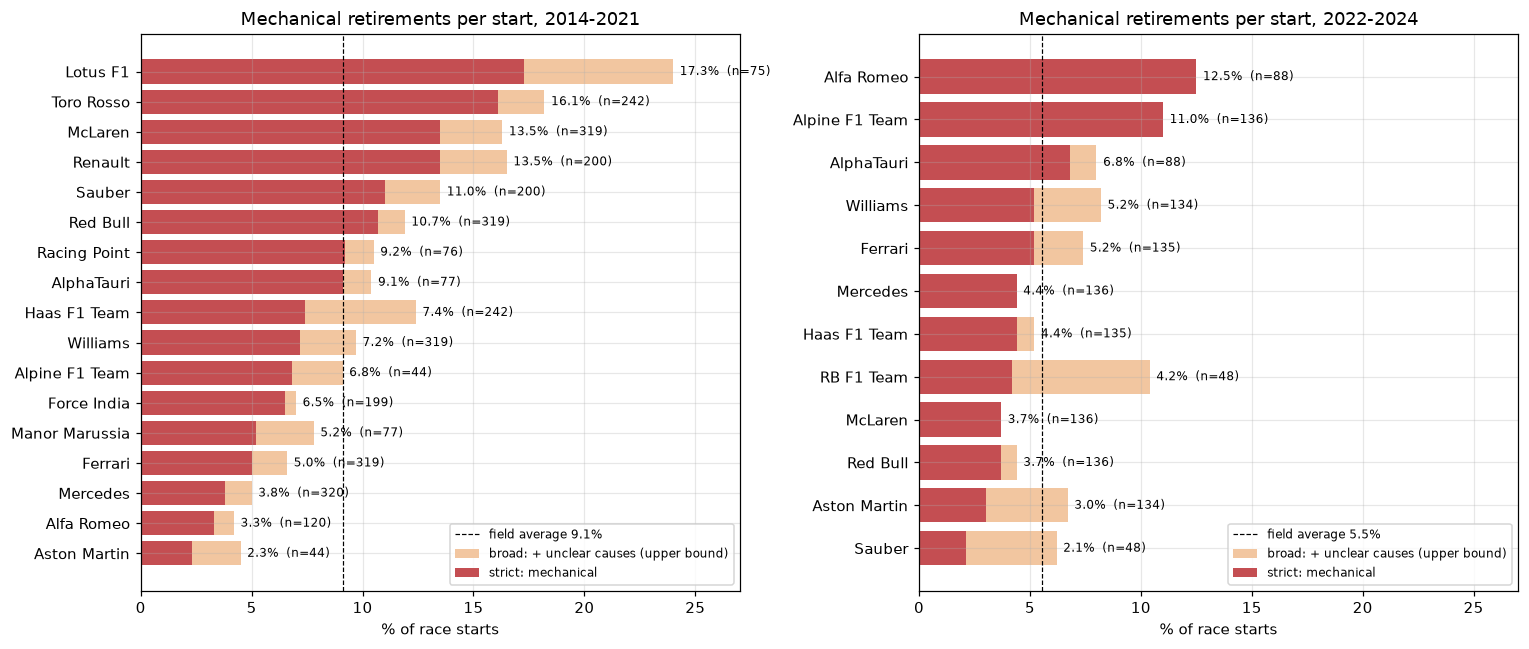

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, p in zip(axes, PERIODS):
    d = q3_rates[q3_rates["period"] == p].sort_values("mechanical %")
    ax.barh(d["constructor"], d["mechanical + unclear %"], color="#F2C6A0", label="broad: + unclear causes (upper bound)")
    ax.barh(d["constructor"], d["mechanical %"], color="#C44E52", label="strict: mechanical")
    for yy, (v, ub, n) in enumerate(zip(d["mechanical %"], d["mechanical + unclear %"], d["starts"])):
        ax.text(max(v, ub) + 0.3, yy, f"{v:.1f}%  (n={n})", va="center", fontsize=8)
    field = 100 * q3.loc[q3["period"] == p, "mechanical"].mean()
    ax.axvline(field, color="black", ls="--", lw=0.8, label=f"field average {field:.1f}%")
    ax.set_title(f"Mechanical retirements per start, {p}")
    ax.set_xlabel("% of race starts")
    ax.set_xlim(0, 27)
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Answer to Q3.**
- **2014–2021 (first hybrid engines):** the least reliable teams were **Lotus F1 (≈ 17% of starts ended with a car failure), Toro Rosso (≈ 16%) and McLaren (≈ 13.5%, tied with Renault)**. McLaren's years with the early Honda engine (2015–2017) are a well-known cause.
- **2022–2024 (new car rules):** the highest rates belong to **Alfa Romeo (≈ 12.5%) and Alpine (≈ 11%)**, then AlphaTauri (≈ 7%).
- **Big picture:** cars became **much more reliable**. The field-wide mechanical-retirement rate fell from about **9% to 5.5%** of starts, and the top teams in 2022–2024 (Red Bull, McLaren, Mercedes) retired from mechanical failures in only about 4% of starts.
- **Strict vs broad (2.5):** the strict ranking counts only *mechanical* statuses (dark bars). The broad ranking also counts *unclear* ones (`Retired`, `Wheel`, `Puncture`, ...; light bars). That raises some rates by up to ~7 points but doesn't change the top two in either period.

*Caution:* in 2022–2024 each team has at most ~136 starts, so one extra failure moves the rate by ~0.7 points. The differences between the middle teams are small.

# 4. Feature Selection & Engineering

**Goal:** choose the inputs the models will use, with evidence for each choice. Every feature must be **known after qualifying and before the race starts**.

How this section works:
1. **4.1 Split** the seasons into train / validation / test first, so every later decision can be made **without looking at the test seasons**.
2. **4.2 Build** the candidate features in five groups (grid, qualifying, standings, form, context), with checks that none of them uses the current race's result.
3. **4.3 Evidence:** one plot per group, on the **training seasons only**.
4. **4.4 Redundancy:** features that say almost the same thing; which one we keep and why.
5. **4.5 Trials:** a simple logistic regression, starting from grid only and adding one group at a time, scored on the **validation** seasons. Every trial is kept.
6. **4.6 Final feature set**, with the reason each feature is allowed.

The **test seasons (2022–2024) are not used** for any plot, correlation or decision in this section.

## 4.1 Train / validation / test split

We split **by season**, never randomly:

| Set | Model A (2003+) | Model B (all years) |
|---|---|---|
| Train | 2003–2018 | 1950–2018 (missing qualifying kept as NaN + a flag) |
| Validation | 2019–2021 | 2019–2021 |
| Test | 2022–2024 | 2022–2024 |

**Why by season:**
- **No peeking at the future.** Form and standings features look back in time. With a random split, the model would train on 2023 races and be tested on 2015 races, learning from the future.
- **A race is never split.** In each race exactly 3 drivers get a podium, so the rows of one race depend on each other. Splitting by season keeps every race whole inside one set.
- **An honest test.** 2022 brought completely new car rules, so 2022–2024 tests whether the model still works after a big change, as it would in real use.
- **Validation** (2019–2021) is the most recent period before the test. It's used to compare feature sets now, and to tune models and thresholds later.

In [61]:
SPLIT_YEARS = {"train": (2003, 2018), "validation": (2019, 2021), "test": (2022, 2024)}
MODEL_B_TRAIN_START = 1950


def season_split(year):
    year = np.asarray(year, dtype=int)
    return np.select([year <= 2018, year <= 2021], ["train", "validation"], "test")


split_summary = []
for model, start in [("A (2003+)", MODEL_START_YEAR), ("B (all years)", MODEL_B_TRAIN_START)]:
    rows = results_full[results_full["year"] >= start]
    sp = season_split(rows["year"])
    for s in ["train", "validation", "test"]:
        part = rows[sp == s]
        split_summary.append({"model": model, "set": s, "seasons": f"{part['year'].min()}-{part['year'].max()}",
                              "races": part["raceId"].nunique(), "rows": len(part),
                              # the test podium rate is deliberately not looked at
                              "podium rate %": round(100 * part["podium"].mean(), 1) if s != "test" else "not inspected"})
split_summary = pd.DataFrame(split_summary)
display(split_summary)

# A race can only belong to one set (a race lies inside one season).
race_sets = results_full.assign(set=season_split(results_full["year"])).groupby("raceId")["set"].nunique()
assert (race_sets == 1).all(), "a race is split across sets"
print("Every race belongs to exactly one set.")

# The split the frozen models and the test results were built on (races, rows). If a different dataset version
# changes any of these, the notebook stops here instead of silently evaluating on different rows.
ESTABLISHED_SPLIT = {("A (2003+)", "train"): (300, 6381), ("A (2003+)", "validation"): (60, 1199), ("A (2003+)", "test"): (68, 1354),
                     ("B (all years)", "train"): (986, 22092), ("B (all years)", "validation"): (60, 1199), ("B (all years)", "test"): (68, 1354)}
got = {(r.model, r.set): (r.races, r.rows) for r in split_summary.itertuples()}
assert got == ESTABLISHED_SPLIT, f"the split differs from the one the models were frozen on: {got}"
print("Split sizes match the established split (test: 68 races, 1,354 driver entries).")

,model,set,seasons,races,rows,podium rate %
0,A (2003+),train,2003-2018,300,6381,14.1
1,A (2003+),validation,2019-2021,60,1199,15.0
2,A (2003+),test,2022-2024,68,1354,not inspected
3,B (all years),train,1950-2018,986,22092,13.4
4,B (all years),validation,2019-2021,60,1199,15.0
5,B (all years),test,2022-2024,68,1354,not inspected


Every race belongs to exactly one set.
Split sizes match the established split (test: 68 races, 1,354 driver entries).


**What this shows.** Model A trains on 16 seasons (6,381 rows) and model B on 69 (22,092 rows); both are validated on the same 3 seasons and will be tested on the same 3 seasons, so their scores can be compared directly. The training podium rate of model A is close to the validation rate, so the class balance is similar in both. The test podium rate is intentionally not printed.

## 4.2 Building the candidate features

All features are computed for **every season** (1950–2024), because model B needs the old seasons and form features need each driver's earlier races. Building a feature for the test seasons is fine: it uses only information from before each race. Choosing features is what must not look at the test seasons.

| Group | Features | Known before the race because... |
|---|---|---|
| **Grid** | `grid`, `pit_lane_start` | the starting order is fixed before the start |
| **Qualifying** | `quali_pos`, `gap_q1_pct` (gap to the fastest Q1 time, %), `grid_minus_quali` (penalty indicator), `reached_q3` (advanced to Q3: a Q3 time, **or** a Q2 time ranked inside that race's Q3 places; + `no_q3_format` flag before 2006), `quali_missing` flag | qualifying is finished |
| **Standings** | driver and constructor championship **position** and **share of the leader's points** (from the **previous** race), `no_standing_yet` flags. No standing yet = behind everyone ranked with 0% of the leader's points; in round 1 nobody is ranked, so everyone is set to the back (number of starters) | the previous race's standings are known; never the current race's (2.10.2) |
| **Form** | driver podium rate, average finish and retirement rate over the **last 5 races**; constructor podium rate over its last 5 races, **restarted after a long absence** (see the checks below) | computed with `shift(1)`, so only earlier races are used |
| **Context** | `n_starters`, `drv_experience` (career starts so far), `drv_age`, `home_race` | known from the entry list, the calendar and the driver's birth date |

In [62]:
# Race order over all seasons: (year, round) -> 0, 1, 2, ...
race_seq = CLEAN["races"].sort_values(["year", "round"])[["raceId"]].reset_index(drop=True)
race_seq["race_seq"] = np.arange(len(race_seq))

feat = (results_full[["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "grid",
                      "pit_lane_start", "podium"]]
        .merge(race_seq, on="raceId", how="left", validate="many_to_one"))
feat["split"] = season_split(feat["year"])

# --- Grid ------------------------------------------------------------------------------------------
feat["grid"] = feat["grid"].astype(float)
feat["pit_lane_start"] = feat["pit_lane_start"].astype(float)

# --- Qualifying --------------------------------------------------------------------------------------
q = CLEAN["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].copy()
q["gap_q1_pct"] = 100 * (q["q1_sec"] / q.groupby("raceId")["q1_sec"].transform("min") - 1)
q["best_sec"] = q[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)          # only for the trial in 4.5
q["gap_best_pct"] = 100 * (q["best_sec"] / q.groupby("raceId")["best_sec"].transform("min") - 1)

# reached_q3 = the driver advanced to Q3. A Q3 lap time is not the only evidence: drivers who advanced but set no
# Q3 time (engine-change penalty, crash, tyre saving, Q3 cancelled) still advanced.
# Rule: every driver with a Q3 time reached Q3; the Q3 places left over go to the fastest Q2 times among the
# drivers WITHOUT a Q3 time (ties broken by qualifying position). Anchoring on Q3 times matters: in a few races the
# recorded Q2 time isn't the lap that counted, so a plain Q2 ranking would let an extra driver in.
# Qualifying position alone isn't used, because it sometimes already includes a penalty (2007 Belgian/Japanese GP).
# Q3 places: 10 in the knockout format (2006+), except the 2016 Australian and Bahrain GP (elimination format: 8).
ELIMINATION_FORMAT = CLEAN["races"].query("year == 2016 and name in ['Australian Grand Prix', 'Bahrain Grand Prix']")["raceId"]
assert len(ELIMINATION_FORMAT) == 2
q["q3_places"] = np.where(q["raceId"].isin(ELIMINATION_FORMAT), 8, 10)
q["q3_times"] = q.groupby("raceId")["q3_sec"].transform("count")
no_q3_time = q[q["q3_sec"].isna() & q["q2_sec"].notna()].sort_values(["raceId", "q2_sec", "position"])
q["q2_order_no_q3"] = no_q3_time.groupby("raceId").cumcount() + 1     # 1 = fastest Q2 among drivers without a Q3 time
q["reached_q3_time_only"] = q["q3_sec"].notna().astype(float)          # the old definition, kept only for the check in 4.2.1
q["reached_q3"] = (q["q3_sec"].notna() | (q["q2_order_no_q3"] <= q["q3_places"] - q["q3_times"])).astype(float)
feat = feat.merge(q[["raceId", "driverId", "position", "gap_q1_pct", "gap_best_pct", "reached_q3"]]
                  .rename(columns={"position": "quali_pos"}), on=["raceId", "driverId"], how="left", validate="one_to_one")
feat["quali_pos"] = feat["quali_pos"].astype(float)
feat["quali_missing"] = feat["quali_pos"].isna().astype(float)
feat["grid_minus_quali"] = feat["grid"] - feat["quali_pos"]
feat["no_q3_format"] = (feat["year"] < 2006).astype(float)          # the Q1/Q2/Q3 knockout started in 2006
feat.loc[feat["no_q3_format"] == 1, "reached_q3"] = np.nan          # not defined before 2006

# --- Standings (previous race only) ---------------------------------------------------------------------


def prerace_features(table, key, prefix):
    s = CLEAN[table][["raceId", key, "pre_points", "pre_position"]].copy()
    leader = s.groupby("raceId")["pre_points"].transform("max")
    s[f"{prefix}_points_share"] = np.where(leader > 0, s["pre_points"] / leader, 0.0)
    s[f"{prefix}_champ_pos"] = s["pre_position"].astype(float)
    out = feat[["raceId", key]].merge(s[["raceId", key, f"{prefix}_points_share", f"{prefix}_champ_pos"]],
                                      on=["raceId", key], how="left", validate="many_to_one")
    ranked = s.groupby("raceId")["pre_position"].max().astype(float)
    out[f"{prefix}_no_standing_yet"] = out[f"{prefix}_champ_pos"].isna().astype(float)
    # No standing yet: behind everyone ranked, 0% of the leader's points. In round 1 nobody is ranked yet,
    # so every driver is set to the back (= number of starters), not to position 1.
    starters = feat.groupby("raceId")["driverId"].transform("size").to_numpy()
    behind = (out["raceId"].map(ranked) + 1).fillna(pd.Series(starters, index=out.index).astype(float))
    out[f"{prefix}_champ_pos"] = out[f"{prefix}_champ_pos"].fillna(behind)
    out[f"{prefix}_points_share"] = out[f"{prefix}_points_share"].fillna(0.0)
    return out.drop(columns=["raceId", key])


feat = pd.concat([feat, prerace_features("driver_standings_prerace", "driverId", "drv"),
                  prerace_features("constructor_standings_prerace", "constructorId", "cons")], axis=1)

# --- Form (earlier races only) -------------------------------------------------------------------------
FORM_WINDOW = 5
hist = (results_full[["raceId", "driverId", "constructorId", "positionOrder", "podium", "status_category"]]
        .merge(race_seq, on="raceId"))
hist["finish"] = hist["positionOrder"].astype(float)
hist["dnf"] = (hist["status_category"] != "finished").astype(float)
hist["podium_f"] = hist["podium"].astype(float)


def past_mean(values, keys, n):
    """Mean of the previous n values within each key, excluding the current row (shift(1))."""
    return values.groupby(keys).transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())


# Constructor history segments. A constructorId can come back after decades (Mercedes 1955 -> 2010), so its
# "previous races" would describe another era's team. A gap of more than TEAM_GAP_DAYS between two races of the
# same constructor starts a new segment, and team form only looks back inside the current segment.
TEAM_GAP_DAYS = 550
TEAM_RACES = (hist.groupby(["constructorId", "raceId", "race_seq"])["podium_f"].agg(["sum", "size"])
              .reset_index().sort_values(["constructorId", "race_seq"]))
TEAM_RACES["date"] = TEAM_RACES["raceId"].map(CLEAN["races"].set_index("raceId")["date"])
TEAM_RACES["gap_days"] = TEAM_RACES.groupby("constructorId")["date"].diff().dt.days
TEAM_RACES["team_segment"] = (TEAM_RACES["gap_days"] > TEAM_GAP_DAYS).groupby(TEAM_RACES["constructorId"]).cumsum()


def form_features(n, reset_gap=True):
    h = hist.sort_values(["driverId", "race_seq"])
    out = pd.DataFrame({"raceId": h["raceId"], "driverId": h["driverId"]})
    out[f"drv_podium_rate_{n}"] = past_mean(h["podium_f"], h["driverId"], n)
    out[f"drv_avg_finish_{n}"] = past_mean(h["finish"], h["driverId"], n)
    out[f"drv_dnf_rate_{n}"] = past_mean(h["dnf"], h["driverId"], n)
    # Constructor: podium finishes / car-starts over its previous n races (both cars of a race count),
    # within the current history segment (reset_gap=False is the old version, kept only for the check in 4.2).
    team = TEAM_RACES.copy()
    keys = ["constructorId", "team_segment"] if reset_gap else ["constructorId"]
    roll = lambda col: team.groupby(keys)[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    team[f"cons_podium_rate_{n}"] = roll("sum") / roll("size")
    out = out.merge(feat[["raceId", "driverId", "constructorId"]], on=["raceId", "driverId"])
    out = out.merge(team[["constructorId", "raceId", f"cons_podium_rate_{n}"]], on=["constructorId", "raceId"], how="left")
    return out.drop(columns="constructorId")


form5 = form_features(FORM_WINDOW)
feat = feat.merge(form5, on=["raceId", "driverId"], how="left", validate="one_to_one")

# --- Context ----------------------------------------------------------------------------------------------
feat["n_starters"] = feat.groupby("raceId")["driverId"].transform("size").astype(float)
exp = hist.sort_values(["driverId", "race_seq"])
exp["drv_experience"] = exp.groupby("driverId").cumcount().astype(float)          # starts BEFORE this race
feat = feat.merge(exp[["raceId", "driverId", "drv_experience"]], on=["raceId", "driverId"], validate="one_to_one")
feat = feat.merge(CLEAN["drivers"][["driverId", "dob", "home_country"]], on="driverId", how="left")
feat["drv_age"] = (feat["date"] - feat["dob"]).dt.days / 365.25
feat = feat.merge(CLEAN["circuits"][["circuitId", "country"]], on="circuitId", how="left")
feat["home_race"] = (feat["home_country"] == feat["country"]).astype(float)
feat = feat.drop(columns=["dob", "home_country", "country"]).sort_values(["race_seq", "grid"]).reset_index(drop=True)

FEATURE_GROUPS = {
    "grid": ["grid", "pit_lane_start"],
    "qualifying": ["quali_pos", "gap_q1_pct", "grid_minus_quali", "reached_q3", "no_q3_format", "quali_missing"],
    "standings": ["drv_champ_pos", "drv_points_share", "drv_no_standing_yet",
                  "cons_champ_pos", "cons_points_share", "cons_no_standing_yet"],
    "form": [f"drv_podium_rate_{FORM_WINDOW}", f"drv_avg_finish_{FORM_WINDOW}", f"drv_dnf_rate_{FORM_WINDOW}",
             f"cons_podium_rate_{FORM_WINDOW}"],
    "context": ["n_starters", "drv_experience", "drv_age", "home_race"],
}
ALL_CANDIDATES = [c for cols in FEATURE_GROUPS.values() for c in cols]
print(f"Feature table: {len(feat):,} rows (1950-2024), {len(ALL_CANDIDATES)} candidate features in {len(FEATURE_GROUPS)} groups")
display(feat[ALL_CANDIDATES].describe().T.round(2))

Feature table: 24,645 rows (1950-2024), 22 candidate features in 5 groups


,count,mean,std,min,25%,50%,75%,max
grid,24645.0,11.80,6.75,1.00,6.00,12.00,17.00,34.00
pit_lane_start,24645.0,0.00,0.05,0.00,0.00,0.00,0.00,1.00
quali_pos,10453.0,11.19,6.25,1.00,6.00,11.00,16.00,26.00
gap_q1_pct,10298.0,1.85,1.93,0.00,0.71,1.34,2.36,44.78
grid_minus_quali,10453.0,0.00,1.52,-9.00,0.00,0.00,0.00,23.00
reached_q3,7870.0,0.47,0.50,0.00,0.00,0.00,1.00,1.00
no_q3_format,24645.0,0.68,0.47,0.00,0.00,1.00,1.00,1.00
quali_missing,24645.0,0.58,0.49,0.00,0.00,1.00,1.00,1.00
drv_champ_pos,24645.0,14.69,11.43,1.00,7.00,13.00,20.00,104.00
drv_points_share,24645.0,0.19,0.28,0.00,0.00,0.05,0.27,1.00


**Leakage checks.** The form features are the riskiest, because they are built from race results. The checks below prove they only use **earlier** races:
- every driver's **first** race has no form value, and so does every constructor's first race of a history segment (its first race ever, or its first race after a long absence, see 4.2.1);
- for 500 random rows, the form value is recomputed by hand from the races **strictly before** that race (for the team: inside the same history segment), and it must match exactly;
- no post-race column (finishing position, points, status, ...) is a candidate feature.

In [63]:
form_cols = FEATURE_GROUPS["form"]
by_driver = feat.sort_values(["driverId", "race_seq"])
first_drv = by_driver.groupby("driverId").head(1)
assert first_drv[[c for c in form_cols if c.startswith("drv_")]].isna().all().all(), "a driver's first race has a form value"
# First race of each constructor history segment (its first race ever, or its first race after a long absence).
seg_start = TEAM_RACES.loc[TEAM_RACES.groupby(["constructorId", "team_segment"]).cumcount() == 0, ["constructorId", "raceId"]]
first_cons = feat.merge(seg_start, on=["constructorId", "raceId"])
assert first_cons[f"cons_podium_rate_{FORM_WINDOW}"].isna().all(), "a constructor's first race (of a segment) has a form value"
segment_of = TEAM_RACES.set_index(["constructorId", "raceId"])["team_segment"]

rng = np.random.default_rng(0)
sample = feat.iloc[rng.choice(len(feat), 500, replace=False)]
for r in sample.itertuples():
    past = hist[(hist["driverId"] == r.driverId) & (hist["race_seq"] < r.race_seq)].sort_values("race_seq").tail(FORM_WINDOW)
    expected = past["podium_f"].mean() if len(past) else np.nan
    got = getattr(r, f"drv_podium_rate_{FORM_WINDOW}")
    assert (np.isnan(expected) and np.isnan(got)) or np.isclose(expected, got), f"form leak at raceId {r.raceId}"
    same_segment = TEAM_RACES[(TEAM_RACES["constructorId"] == r.constructorId)
                              & (TEAM_RACES["team_segment"] == segment_of.loc[(r.constructorId, r.raceId)])]
    team_past = hist[(hist["constructorId"] == r.constructorId) & (hist["race_seq"] < r.race_seq)
                     & hist["raceId"].isin(same_segment["raceId"])]
    last_races = team_past["race_seq"].drop_duplicates().nlargest(FORM_WINDOW)
    tp = team_past[team_past["race_seq"].isin(last_races)]
    expected_c = tp["podium_f"].mean() if len(tp) else np.nan
    got_c = getattr(r, f"cons_podium_rate_{FORM_WINDOW}")
    assert (np.isnan(expected_c) and np.isnan(got_c)) or np.isclose(expected_c, got_c), f"team form leak at raceId {r.raceId}"

assert not set(ALL_CANDIDATES) & set(POST_RACE), "a post-race column is a candidate feature"
print(f"Leakage checks passed: {len(first_drv)} first driver races and {len(first_cons)} first constructor races "
      f"(including restarts after a long absence) have no form; "
      f"500 random rows match a hand recomputation from earlier races only; no post-race column is a feature.")

Leakage checks passed: 686 first driver races and 334 first constructor races (including restarts after a long absence) have no form; 500 random rows match a hand recomputation from earlier races only; no post-race column is a feature.


### 4.2.1 Checks for two corrected features: `reached_q3` and team form

A review of the first version found two features that were computed wrongly for a small number of rows. Both are fixed above; the cells below show what changed and prove the fixes.

**`reached_q3`.** The first version used "has a Q3 lap time". But some drivers **advanced to Q3 without setting a Q3 time** (an engine-change penalty made a lap pointless, a crash, saving tyres, or Q3 was cancelled), so they were wrongly marked as eliminated. The corrected rule: every driver **with a Q3 time** reached Q3, and the **Q3 places left over** go to the fastest Q2 times among the drivers without a Q3 time. Format exceptions and data quirks:
- **Q3 places = 10** in the knockout format (2006 onwards), except the **2016 Australian and Bahrain GP**: the short-lived "elimination" format sent only **8** drivers to Q3, so a plain "qualified in the top 10" rule would be wrong there.
- **Not the qualifying position:** in a few races the recorded position already includes a penalty (e.g. 2007 Belgian GP: Kubica is listed 14th although he ran in Q3), so it doesn't show who advanced.
- **Anchored on Q3 times, not a plain Q2 ranking:** in a few races the recorded Q2 time isn't the lap that counted (e.g. Heidfeld, 2008 Turkish GP, listed 14th in Q2 but ran in Q3), so ranking Q2 times alone would let an 11th driver into Q3. Equal Q2 times at the cut-off (2011 Indian GP) are separated by qualifying position.
- **2015 US GP:** Q3 was cancelled by rain (no Q3 times at all); the 10 drivers who advanced from Q2 count as having reached Q3.
- Before 2006 there was no Q3: `reached_q3` stays missing and `no_q3_format = 1`, as before.
- **Check:** in every one of the 375 knockout races, exactly 10 drivers (8 in the two elimination-format races) reached Q3.

**Team form.** A `constructorId` can return after decades: Mercedes raced in 1954–1955 and came back in 2010 with the same ID, so its first 2010 races were using 1955 results as "recent form". Team form now only looks back inside a **history segment**: a new segment starts when the team's previous race was more than **550 days** (about 18 months) earlier.
- **Why 550 days:** a normal winter break is 3–7 months. Small 1950s–60s teams that entered only a few races a season can go about a year between races while still racing every season. More than 18 months means the team missed at least a whole season. In 2003+ **every** reset is a gap of 4 years or more, so any threshold between 1 and 2 years gives exactly the same model-A features (the sensitivity table below shows it); the choice only affects a few pre-2003 rows used by model B.
- The first race of a new segment has **no** team form (missing, like a new team); from its second race the form uses the races available in the segment, up to 5. The formula is unchanged: podium finishes divided by car-starts over those races.
- **Limitation (documented, not changed):** renamed teams have different IDs (Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Renault → Alpine, ...). Their form starts again after a rename even though the factory is the same. We don't merge IDs: which renames are "the same team" is a judgement call, and these rows are few.

In [64]:
nm = (CLEAN["drivers"].assign(driver=CLEAN["drivers"]["forename"] + " " + CLEAN["drivers"]["surname"])[["driverId", "driver"]])
rc = CLEAN["races"][["raceId", "name"]].rename(columns={"name": "race"})

# --- reached_q3 ---------------------------------------------------------------------------------------------
# In every knockout race (qualifying table, all entrants), exactly the number of Q3 places reached Q3.
knockout = q[q["raceId"].isin(CLEAN["races"].loc[CLEAN["races"]["year"] >= 2006, "raceId"])]
per_race = knockout.groupby("raceId").agg(reached=("reached_q3", "sum"), places=("q3_places", "first"))
assert (per_race["reached"] == per_race["places"]).all(), "a race has the wrong number of drivers in Q3"
print(f"All {len(per_race)} knockout races (2006+) have exactly their number of Q3 places marked as reached Q3.")

# Rows of the feature table (starters, 2006+): old definition (Q3 time only) vs corrected.
q3c = (feat.loc[feat["no_q3_format"] == 0, ["raceId", "driverId", "year", "split", "quali_pos", "grid", "reached_q3"]]
       .merge(q[["raceId", "driverId", "q2_sec", "q3_sec", "q3_places", "reached_q3_time_only"]], on=["raceId", "driverId"], how="left")
       .merge(nm, on="driverId").merge(rc, on="raceId"))
q3c = q3c[q3c["reached_q3"].notna()]
q3_changed = q3c[q3c["reached_q3"] != q3c["reached_q3_time_only"]]
print(f"reached_q3 ({len(q3c):,} starters with qualifying, 2006+): {len(q3_changed)} values changed, "
      f"all from 0 to 1: {bool((q3_changed['reached_q3'] == 1).all())}")
display(q3_changed.groupby("split").size().rename("changed rows").to_frame().T)

show = ["year", "race", "driver", "quali_pos", "grid", "q2_sec", "q3_sec", "q3_places", "reached_q3_time_only", "reached_q3"]
print("Examples: advanced to Q3 without setting a Q3 time (0 before, 1 now)")
display(q3_changed[show].head(6))
print("Format exceptions: 2016 elimination format (8 places), 2007 position that includes a penalty, "
      "2008 recorded Q2 time not the one that counted, 2015 US GP (Q3 cancelled)")
special = q3c[(q3c["raceId"].isin(ELIMINATION_FORMAT) & q3c["quali_pos"].between(8, 11))
              | ((q3c["year"] == 2007) & (q3c["race"] == "Belgian Grand Prix") & q3c["quali_pos"].between(9, 14))
              | ((q3c["year"] == 2008) & (q3c["race"] == "Turkish Grand Prix") & q3c["quali_pos"].between(9, 11))
              | ((q3c["year"] == 2015) & (q3c["race"] == "United States Grand Prix") & q3c["quali_pos"].between(9, 11))]
display(special[show].sort_values(["year", "race", "quali_pos"]).reset_index(drop=True))

All 375 knockout races (2006+) have exactly their number of Q3 places marked as reached Q3.
reached_q3 (7,870 starters with qualifying, 2006+): 114 values changed, all from 0 to 1: True


split,test,train,validation
changed rows,19,79,16


Examples: advanced to Q3 without setting a Q3 time (0 before, 1 now)


,year,race,driver,quali_pos,grid,q2_sec,q3_sec,q3_places,reached_q3_time_only,reached_q3
43,2006,Malaysian Grand Prix,Ralf Schumacher,10.0,22.0,94.586,NaN,10.0,0.0,1.0
52,2006,Australian Grand Prix,Jarno Trulli,10.0,9.0,86.327,NaN,10.0,0.0,1.0
141,2006,Monaco Grand Prix,Ralf Schumacher,10.0,10.0,74.398,NaN,10.0,0.0,1.0
383,2006,Brazilian Grand Prix,Michael Schumacher,10.0,10.0,70.313,NaN,10.0,0.0,1.0
559,2007,French Grand Prix,Fernando Alonso,10.0,10.0,75.084,NaN,10.0,0.0,1.0
778,2008,Australian Grand Prix,Sebastian Vettel,10.0,9.0,85.842,NaN,10.0,0.0,1.0


Format exceptions: 2016 elimination format (8 places), 2007 position that includes a penalty, 2008 recorded Q2 time not the one that counted, 2015 US GP (Q3 cancelled)


,year,race,driver,quali_pos,grid,q2_sec,q3_sec,q3_places,reached_q3_time_only,reached_q3
0,2007,Belgian Grand Prix,Heikki Kovalainen,9.0,9.0,106.240,108.505,10.0,1.0,1.0
1,2007,Belgian Grand Prix,Ralf Schumacher,10.0,10.0,106.618,NaN,10.0,0.0,0.0
2,2007,Belgian Grand Prix,David Coulthard,11.0,11.0,106.800,NaN,10.0,0.0,0.0
3,2007,Belgian Grand Prix,Jenson Button,12.0,12.0,106.955,NaN,10.0,0.0,0.0
4,2007,Belgian Grand Prix,Vitantonio Liuzzi,13.0,13.0,107.115,NaN,10.0,0.0,0.0
5,2007,Belgian Grand Prix,Robert Kubica,14.0,14.0,105.885,106.996,10.0,1.0,1.0
6,2008,Turkish Grand Prix,Nick Heidfeld,9.0,9.0,87.607,88.882,10.0,1.0,1.0
7,2008,Turkish Grand Prix,David Coulthard,10.0,10.0,86.520,89.959,10.0,1.0,1.0
8,2008,Turkish Grand Prix,Nico Rosberg,11.0,11.0,87.012,NaN,10.0,0.0,0.0
9,2015,United States Grand Prix,Felipe Massa,9.0,7.0,119.999,NaN,10.0,0.0,1.0


In [65]:
# --- Team form: threshold evidence -----------------------------------------------------------------------------
gaps = TEAM_RACES["gap_days"].dropna()
gap_bins = pd.cut(gaps, [0, 120, 250, 365, 550, 730, 1095, 100000],
                  labels=["<=4 months", "4-8 months", "8-12 months", "12-18 months", "18-24 months", "2-3 years", "3+ years"])
print("Days between two consecutive races of the same constructor (all seasons):")
display(gap_bins.value_counts().sort_index().rename("gaps").to_frame().T)
modern = TEAM_RACES["date"].dt.year >= MODEL_START_YEAR
print(f"Longest gap in {MODEL_START_YEAR}+ that is NOT a reset: {int(TEAM_RACES.loc[modern & (TEAM_RACES['gap_days'] <= TEAM_GAP_DAYS), 'gap_days'].max())} days")
display(pd.DataFrame([{"threshold (days)": t, "resets, all seasons": int((gaps > t).sum()),
                       f"resets, {MODEL_START_YEAR}+": int((modern & (TEAM_RACES["gap_days"] > t)).sum())}
                      for t in [365, 450, 550, 730]]).set_index("threshold (days)").T)

# --- Team form: old (no reset) vs corrected ----------------------------------------------------------------------
col = f"cons_podium_rate_{FORM_WINDOW}"
old_team = form_features(FORM_WINDOW, reset_gap=False)[["raceId", "driverId", col]].rename(columns={col: "old (no reset)"})
tc = feat[["raceId", "driverId", "constructorId", "year", "split", col]].merge(old_team, on=["raceId", "driverId"], validate="one_to_one")
same = (tc[col].isna() & tc["old (no reset)"].isna()) | np.isclose(tc[col], tc["old (no reset)"])
team_changed = tc[~same]

# Only the first FORM_WINDOW races of a restarted segment may change; every other window must be identical.
pos_in_segment = TEAM_RACES.groupby(["constructorId", "team_segment"]).cumcount()
may_change = TEAM_RACES.loc[(TEAM_RACES["team_segment"] > 0) & (pos_in_segment < FORM_WINDOW), ["constructorId", "raceId"]]
assert team_changed.merge(may_change, on=["constructorId", "raceId"]).shape[0] == len(team_changed), \
    "team form changed outside the first races of a restarted segment"
restarts = TEAM_RACES[TEAM_RACES["gap_days"] > TEAM_GAP_DAYS][["constructorId", "raceId"]]
assert feat.merge(restarts, on=["constructorId", "raceId"])[col].isna().all(), "the first race after a reset has a form value"
print(f"Team form: {len(team_changed)} rows changed ({team_changed.groupby('split').size().to_dict()}); "
      f"all inside the first {FORM_WINDOW} races after a reset. All other rows are unchanged.")

modern_resets = (TEAM_RACES[modern & (TEAM_RACES["gap_days"] > TEAM_GAP_DAYS)]
                 .merge(CLEAN["constructors"][["constructorId", "name"]].rename(columns={"name": "team"}), on="constructorId")
                 .merge(rc, on="raceId"))
modern_resets["previous race"] = modern_resets["date"] - pd.to_timedelta(modern_resets["gap_days"], unit="D")
first_rows =tc.merge(modern_resets[["constructorId", "raceId"]], on=["constructorId", "raceId"]).groupby(["constructorId", "raceId"]).first()
modern_resets = modern_resets.join(first_rows[["old (no reset)", col]], on=["constructorId", "raceId"])
print(f"Resets in {MODEL_START_YEAR}+ (the team's form at its comeback race, before and after the fix):")
display(modern_resets[["team", "race", "date", "previous race", "gap_days", "old (no reset)", col]]
        .rename(columns={"gap_days": "gap (days)", col: "corrected"}).sort_values("date").reset_index(drop=True))

Days between two consecutive races of the same constructor (all seasons):


gap_days,<=4 months,4-8 months,8-12 months,12-18 months,18-24 months,2-3 years,3+ years
gaps,11581,458,58,19,5,6,28


Longest gap in 2003+ that is NOT a reset: 217 days


threshold (days),365,450,550,730
"resets, all seasons",58,51,39,34
"resets, 2003+",7,7,7,7


Team form: 141 rows changed ({'test': 2, 'train': 135, 'validation': 4}); all inside the first 5 races after a reset. All other rows are unchanged.
Resets in 2003+ (the team's form at its comeback race, before and after the fix):


,team,race,date,previous race,gap (days),old (no reset),corrected
0,Honda,Bahrain Grand Prix,2006-03-12,1968-11-03,13643.0,0.142857,NaN
1,Sauber,Bahrain Grand Prix,2010-03-14,2005-10-16,1610.0,0.000000,NaN
2,Mercedes,Bahrain Grand Prix,2010-03-14,1955-09-11,19908.0,0.529412,NaN
3,Renault,Australian Grand Prix,2016-03-20,2011-11-27,1575.0,0.000000,NaN
4,Alfa Romeo,Australian Grand Prix,2019-03-17,1985-11-03,12187.0,0.000000,NaN
5,Aston Martin,Bahrain Grand Prix,2021-03-28,1960-07-16,22170.0,0.000000,NaN
6,Sauber,Bahrain Grand Prix,2024-03-02,2018-11-25,1924.0,0.000000,NaN


**Missing values in the candidates (training seasons of model A).** Some gaps are expected and meaningful: a driver's first race has no form, a new team has no team form, `reached_q3` doesn't exist before 2006. How to fill them is a **pre-processing** decision for the next section; for the trials in 4.5 a simple provisional fill is used (median + a "was missing" indicator).

In [66]:
TRAIN_A = feat[(feat["split"] == "train") & (feat["year"] >= MODEL_START_YEAR)]
VAL = feat[feat["split"] == "validation"]
missing = pd.DataFrame({"train A missing %": 100 * TRAIN_A[ALL_CANDIDATES].isna().mean(),
                        "validation missing %": 100 * VAL[ALL_CANDIDATES].isna().mean()}).round(1)
display(missing[missing.max(axis=1) > 0])

,train A missing %,validation missing %
quali_pos,0.3,0.3
gap_q1_pct,1.8,1.7
grid_minus_quali,0.3,0.3
reached_q3,16.6,0.3
drv_podium_rate_5,1.1,0.8
drv_avg_finish_5,1.1,0.8
drv_dnf_rate_5,1.1,0.8
cons_podium_rate_5,0.6,0.8


## 4.3 Evidence for each feature group (training seasons only)

Each plot shows the **podium rate** for groups of training rows (2003–2018) with similar values of a feature. A feature is useful if the podium rate **changes clearly** across its values. The number of rows behind each bar is shown, so small groups aren't over-read.

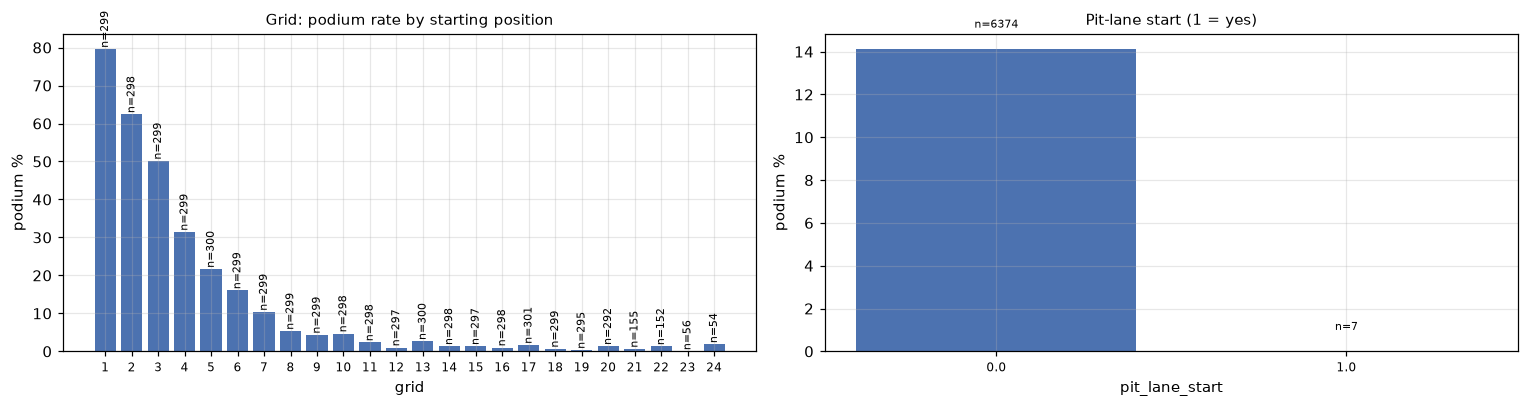

In [67]:
def rate_plot(ax, df, col, bins=None, labels=None, title=None, xlabel=None):
    x = df[col] if bins is None else pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    t = df.groupby(x, observed=True)["podium"].agg(["mean", "size"])
    ax.bar(t.index.astype(str), 100 * t["mean"], color="#4C72B0")
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, 100 * m + 1, f"n={n}", ha="center", fontsize=7, rotation=90 if len(t) > 12 else 0)
    ax.set_title(title or col, fontsize=10)
    ax.set_xlabel(xlabel or col)
    ax.set_ylabel("podium %")
    ax.tick_params(axis="x", labelsize=8)


fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
rate_plot(axes[0], TRAIN_A[TRAIN_A["grid"] <= 24].assign(grid=lambda d: d["grid"].astype(int)), "grid",
          title="Grid: podium rate by starting position")
rate_plot(axes[1], TRAIN_A, "pit_lane_start", title="Pit-lane start (1 = yes)")
plt.tight_layout()
plt.show()

**Grid:** the strongest single signal. From pole, 79% of drivers finish on the podium; from 2nd 62%, 3rd 50%, 5th 22%, and from 8th or lower under 5%. The drop is steep, not a straight line, which matters for the linear model (it can only draw a gradual curve). `pit_lane_start` has only 7 training rows (none on the podium), so it can't show a pattern on its own; it is kept with `grid` because it tells the model that the grid number of those rows is a recode (2.6), not a real slot.

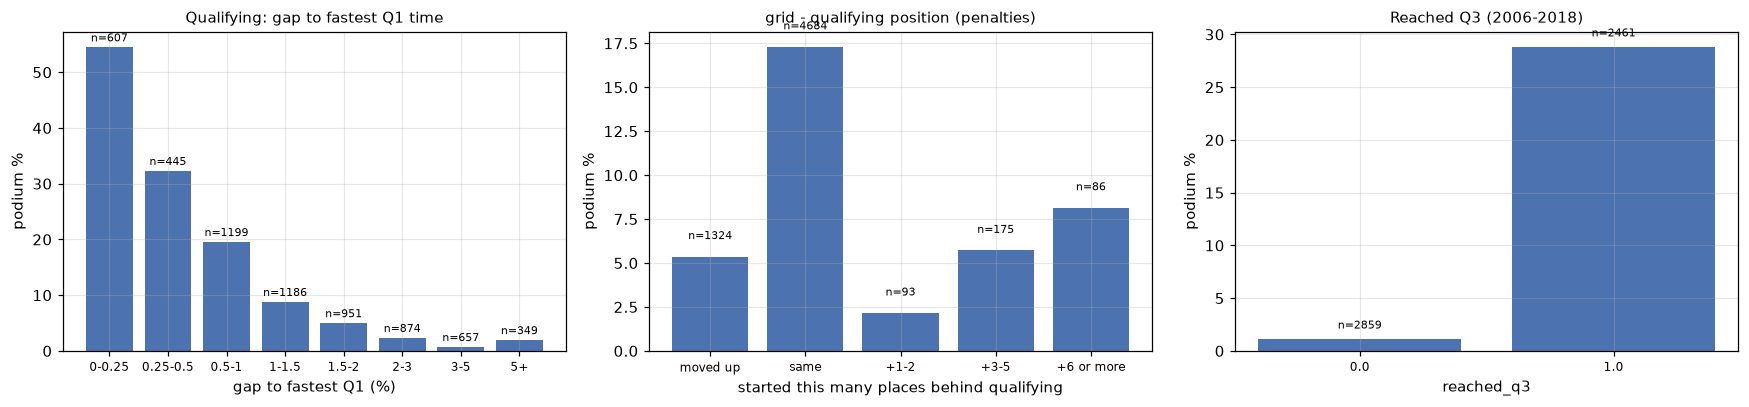

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_plot(axes[0], TRAIN_A, "gap_q1_pct", bins=[0, 0.25, 0.5, 1, 1.5, 2, 3, 5, 100],
          labels=["0-0.25", "0.25-0.5", "0.5-1", "1-1.5", "1.5-2", "2-3", "3-5", "5+"],
          title="Qualifying: gap to fastest Q1 time", xlabel="gap to fastest Q1 (%)")
rate_plot(axes[1], TRAIN_A, "grid_minus_quali", bins=[-30, -1, 0, 2, 5, 30],
          labels=["moved up", "same", "+1-2", "+3-5", "+6 or more"],
          title="grid - qualifying position (penalties)", xlabel="started this many places behind qualifying")
rate_plot(axes[2], TRAIN_A[TRAIN_A["no_q3_format"] == 0], "reached_q3", title="Reached Q3 (2006-2018)")
plt.tight_layout()
plt.show()

**Qualifying:** pace matters on top of grid position. Drivers within 0.25% of the fastest Q1 time reach the podium 54% of the time; at 0.5–1% it is 20%, and beyond 2% almost never. Reaching Q3 (2006–2018): 29% vs 1%. The middle plot (`grid − qualifying position`) mixes all grid positions, so on its own it looks odd. The fair comparison is inside the same grid slots (3.1.2): drivers who qualified in the top 3 but started 6th or lower because of a penalty still reached the podium **32%** of the time vs **3.4%** for others starting there. That is the information this feature carries.

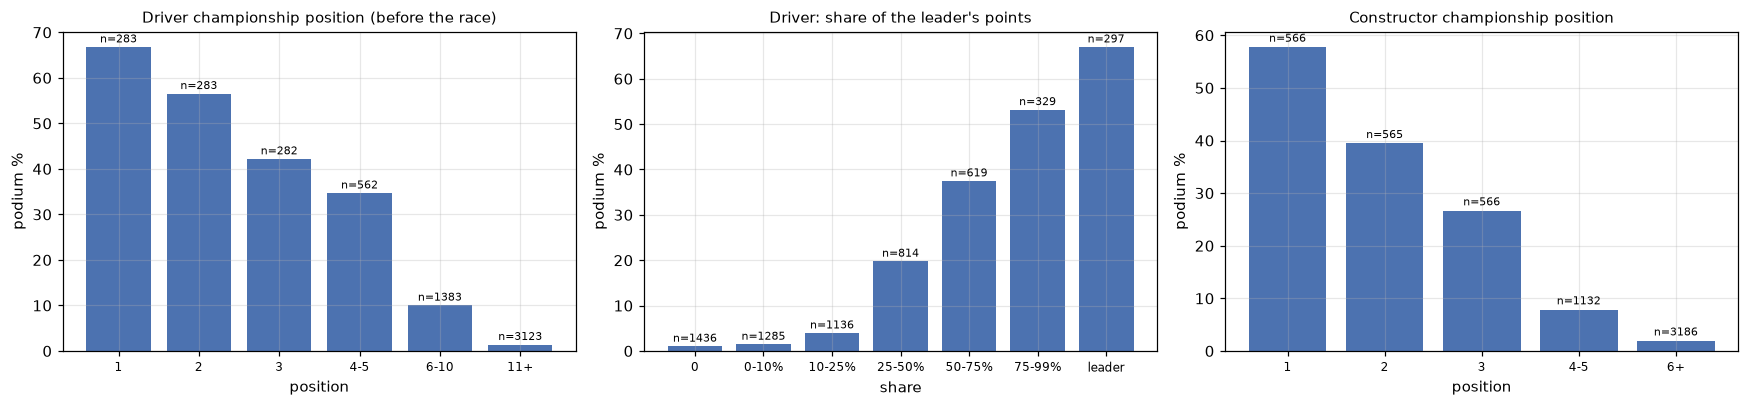

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
ranked_drv = TRAIN_A[TRAIN_A["drv_no_standing_yet"] == 0]
ranked_cons = TRAIN_A[TRAIN_A["cons_no_standing_yet"] == 0]
rate_plot(axes[0], ranked_drv, "drv_champ_pos", bins=[0, 1, 2, 3, 5, 10, 200], labels=["1", "2", "3", "4-5", "6-10", "11+"],
          title="Driver championship position (before the race)", xlabel="position")
rate_plot(axes[1], ranked_drv, "drv_points_share",
          bins=[-0.01, 0, 0.1, 0.25, 0.5, 0.75, 0.99, 1], labels=["0", "0-10%", "10-25%", "25-50%", "50-75%", "75-99%", "leader"],
          title="Driver: share of the leader's points", xlabel="share")
rate_plot(axes[2], ranked_cons, "cons_champ_pos", bins=[0, 1, 2, 3, 5, 100], labels=["1", "2", "3", "4-5", "6+"],
          title="Constructor championship position", xlabel="position")
plt.tight_layout()
plt.show()

**Standings (ranked drivers and teams only):** the championship leader before the race reaches the podium 67% of the time, 2nd 57%, 3rd 42%, and from 11th down about 1%. Share of the leader's points tells the same story (leader 67%, under 10% of the leader's points about 1–2%). Constructor position is even sharper at the bottom (6th or lower: 2%). Rows with no standing yet (round 1, or no points so far) are left out of these plots; the `no_standing_yet` flags carry them.

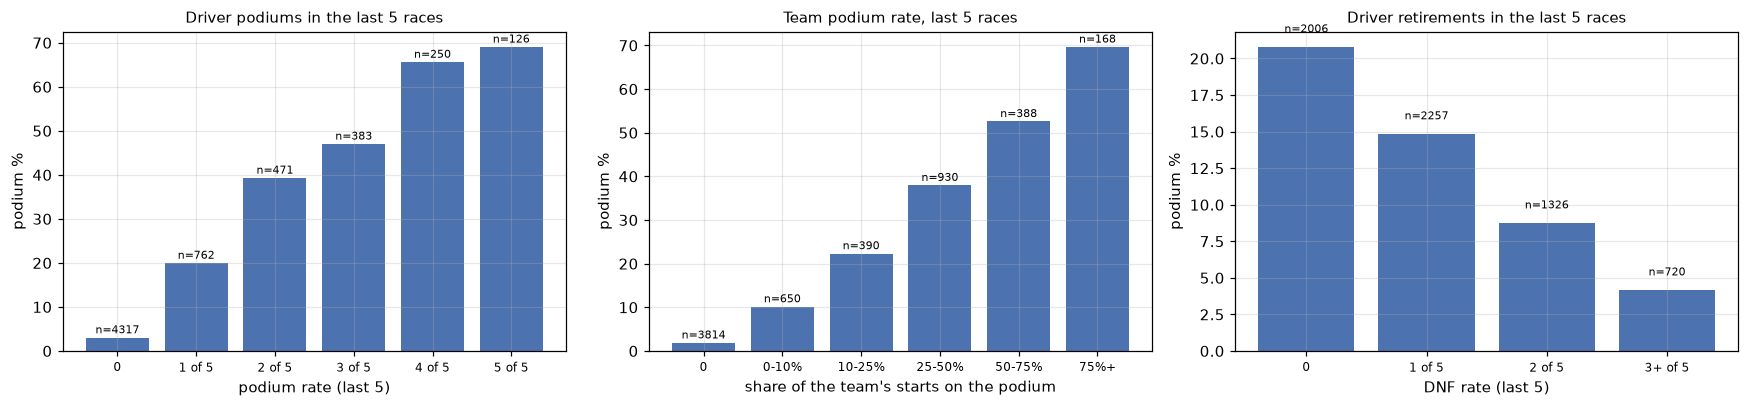

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_plot(axes[0], TRAIN_A, f"drv_podium_rate_{FORM_WINDOW}", bins=[-0.01, 0, 0.2, 0.4, 0.6, 0.8, 1],
          labels=["0", "1 of 5", "2 of 5", "3 of 5", "4 of 5", "5 of 5"],
          title="Driver podiums in the last 5 races", xlabel="podium rate (last 5)")
rate_plot(axes[1], TRAIN_A, f"cons_podium_rate_{FORM_WINDOW}", bins=[-0.01, 0, 0.1, 0.25, 0.5, 0.75, 1],
          labels=["0", "0-10%", "10-25%", "25-50%", "50-75%", "75%+"],
          title="Team podium rate, last 5 races", xlabel="share of the team's starts on the podium")
rate_plot(axes[2], TRAIN_A, f"drv_dnf_rate_{FORM_WINDOW}", bins=[-0.01, 0, 0.2, 0.4, 1],
          labels=["0", "1 of 5", "2 of 5", "3+ of 5"], title="Driver retirements in the last 5 races", xlabel="DNF rate (last 5)")
plt.tight_layout()
plt.show()

**Form (last 5 races, current race excluded):** a driver with no podium in the last 5 races gets one only 3% of the time; with 2 of 5 it is 39%, with 4–5 of 5 about 65–69%. The team's recent podium rate shows the same climb (2% → 70%). Recent retirements lower the chance too (no DNF in 5 races: 21%; 3 or more: 4%).

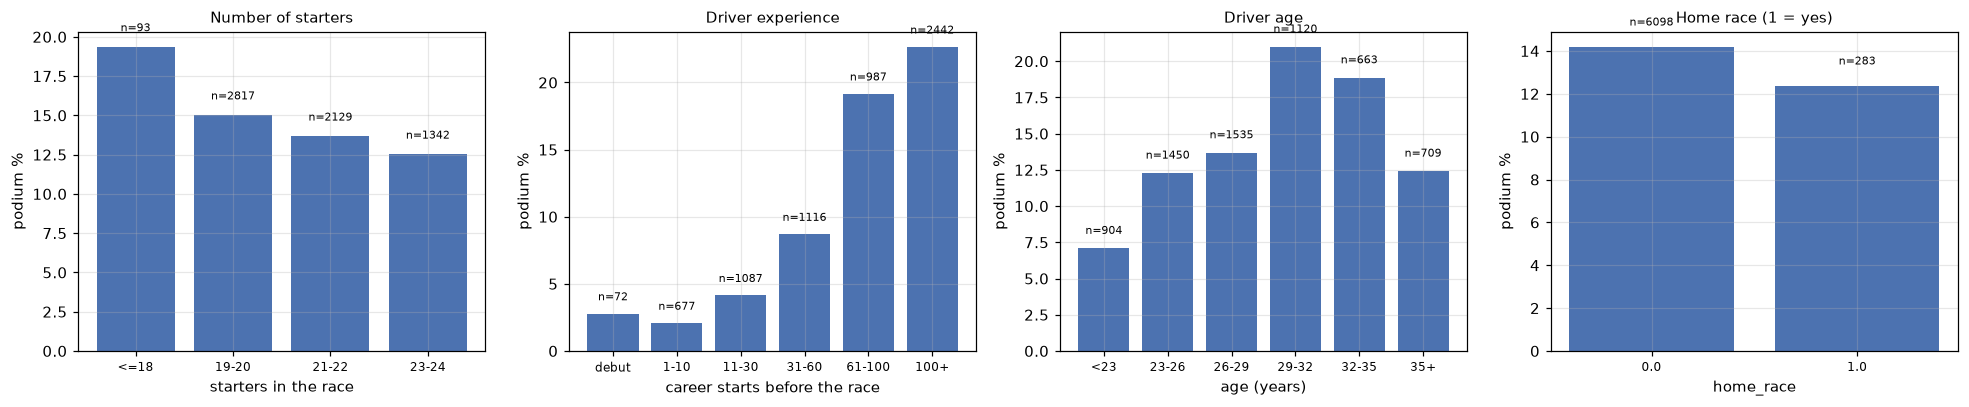

In [71]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
rate_plot(axes[0], TRAIN_A, "n_starters", bins=[0, 18, 20, 22, 24, 30], labels=["<=18", "19-20", "21-22", "23-24", "25+"],
          title="Number of starters", xlabel="starters in the race")
rate_plot(axes[1], TRAIN_A, "drv_experience", bins=[-1, 0, 10, 30, 60, 100, 400],
          labels=["debut", "1-10", "11-30", "31-60", "61-100", "100+"], title="Driver experience", xlabel="career starts before the race")
rate_plot(axes[2], TRAIN_A, "drv_age", bins=[0, 23, 26, 29, 32, 35, 50], labels=["<23", "23-26", "26-29", "29-32", "32-35", "35+"],
          title="Driver age", xlabel="age (years)")
rate_plot(axes[3], TRAIN_A, "home_race", title="Home race (1 = yes)")
plt.tight_layout()
plt.show()

**Context:** weaker effects, but real ones. Fewer starters means a higher podium rate (19% with 18 or fewer cars vs 12.5% with 23–24), simply because 3 podium places are shared by fewer drivers. Experience rises steadily (debut 3%, 100+ starts 23%). Age peaks at 29–32 (21%) and is lower for young (<23: 7%) and older (35+: 12.5%) drivers. **Home race** shows 12.4% vs 14.2%, the same misleading raw gap as Q2 (home drivers start further back). Q2 found no effect once grid is accounted for.

In [72]:
# One number per feature: how well does it rank podium finishers on its own? (training seasons of model A)
from sklearn.metrics import roc_auc_score

single = []
for group, cols in FEATURE_GROUPS.items():
    for c in cols:
        d = TRAIN_A[[c, "podium"]].dropna()
        if d[c].nunique() < 2:
            continue
        auc = roc_auc_score(d["podium"], d[c])
        single.append({"group": group, "feature": c, "rows": len(d),
                       "AUC alone": round(max(auc, 1 - auc), 3), "direction": "higher -> more podiums" if auc >= 0.5 else "lower -> more podiums"})
single = pd.DataFrame(single).sort_values("AUC alone", ascending=False).reset_index(drop=True)
display(single)

,group,feature,rows,AUC alone,direction
0,qualifying,quali_pos,6362,0.909,lower -> more podiums
1,grid,grid,6381,0.907,lower -> more podiums
2,form,cons_podium_rate_5,6340,0.872,higher -> more podiums
3,form,drv_avg_finish_5,6309,0.862,lower -> more podiums
4,standings,cons_points_share,6381,0.856,higher -> more podiums
5,standings,drv_champ_pos,6381,0.854,lower -> more podiums
6,form,drv_podium_rate_5,6309,0.853,higher -> more podiums
7,standings,drv_points_share,6381,0.852,higher -> more podiums
8,qualifying,gap_q1_pct,6268,0.829,lower -> more podiums
9,standings,cons_champ_pos,6381,0.826,lower -> more podiums


**Ranking the features one at a time.** "AUC alone" is the chance that a random podium row has a "better" value than a random non-podium row (0.5 = useless, 1 = perfect). Starting position (grid 0.907, qualifying position 0.909) is the best single signal, followed by team form (0.872), the driver's recent average finish (0.862) and the standings (0.83–0.86). The flags (`no_standing_yet`, `quali_missing`, `no_q3_format`, `pit_lane_start`) score about 0.5 on purpose: they don't predict podiums on their own; they tell the model when another feature is missing or means something different.

## 4.4 Redundancy: features that say the same thing

Two features that move together carry almost the same information. Keeping both makes a linear model's coefficients unstable and its explanations harder to read, without adding much. We look at the **Spearman correlation** (rank-based, so it works for positions) on the training seasons.

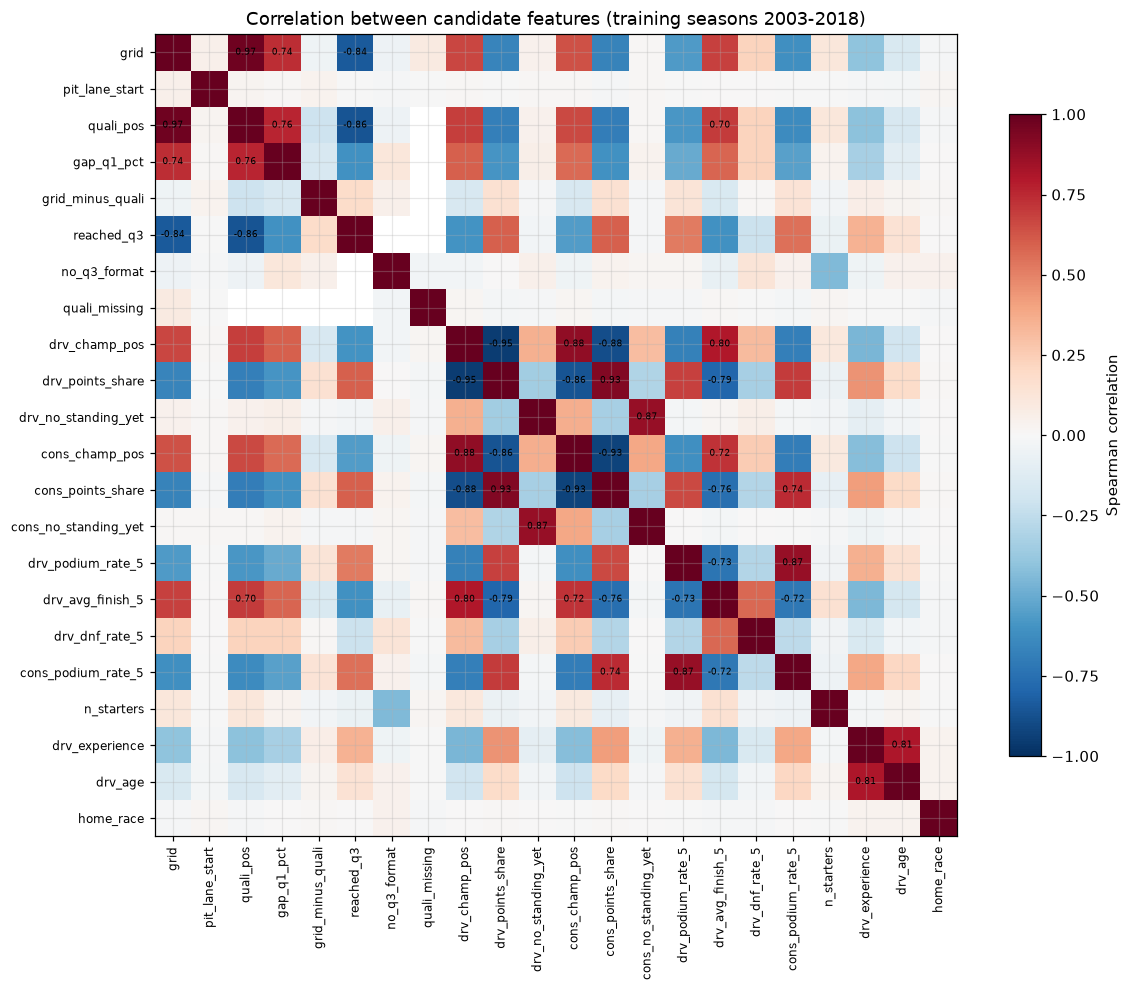

,feature 1,feature 2,spearman
0,grid,quali_pos,0.97
1,drv_champ_pos,drv_points_share,-0.95
2,cons_champ_pos,cons_points_share,-0.93
3,drv_points_share,cons_points_share,0.93
4,drv_champ_pos,cons_points_share,-0.88
5,drv_champ_pos,cons_champ_pos,0.88
6,drv_podium_rate_5,cons_podium_rate_5,0.87
7,drv_no_standing_yet,cons_no_standing_yet,0.87
8,quali_pos,reached_q3,-0.86
9,drv_points_share,cons_champ_pos,-0.86


In [73]:
corr = TRAIN_A[ALL_CANDIDATES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        if i != j and abs(corr.iloc[i, j]) >= 0.7:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Correlation between candidate features (training seasons 2003-2018)")
plt.tight_layout()
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("spearman").reset_index()
         .rename(columns={"level_0": "feature 1", "level_1": "feature 2"}))
display(pairs[pairs["spearman"].abs() >= 0.7].sort_values("spearman", key=abs, ascending=False).round(2).reset_index(drop=True))

In [74]:
auc_alone = single.set_index("feature")["AUC alone"]
DECISIONS = []

# 1. grid vs qualifying position: keep grid (where the car actually starts) and express qualifying as
#    the difference grid - quali_pos, so the penalty information stays without a near-duplicate column.
DECISIONS.append(("grid vs quali_pos", "keep grid + grid_minus_quali, drop quali_pos",
                  f"Spearman {corr.loc['grid', 'quali_pos']:.2f}; AUC alone grid {auc_alone['grid']:.3f} vs quali_pos {auc_alone['quali_pos']:.3f}"))

# 2. championship position vs points share (driver and constructor): keep the one that ranks podiums better on its own.
STANDINGS_KEEP = []
for who in ["drv", "cons"]:
    pos, share = f"{who}_champ_pos", f"{who}_points_share"
    keep = share if auc_alone[share] >= auc_alone[pos] else pos
    STANDINGS_KEEP.append(keep)
    DECISIONS.append((f"{pos} vs {share}", f"keep {keep}",
                      f"Spearman {corr.loc[pos, share]:.2f}; AUC alone {pos} {auc_alone[pos]:.3f} vs {share} {auc_alone[share]:.3f}"))
display(pd.DataFrame(DECISIONS, columns=["pair", "decision", "evidence (training seasons)"]))

FEATURE_GROUPS["qualifying"] = ["gap_q1_pct", "grid_minus_quali", "reached_q3", "no_q3_format", "quali_missing"]
FEATURE_GROUPS["standings"] = STANDINGS_KEEP + ["drv_no_standing_yet", "cons_no_standing_yet"]
print("Qualifying group now:", FEATURE_GROUPS["qualifying"])
print("Standings group now: ", FEATURE_GROUPS["standings"])

,pair,decision,evidence (training seasons)
0,grid vs quali_pos,"keep grid + grid_minus_quali, drop quali_pos",Spearman 0.97; AUC alone grid 0.907 vs quali_pos 0.909
1,drv_champ_pos vs drv_points_share,keep drv_champ_pos,Spearman -0.95; AUC alone drv_champ_pos 0.854 vs drv_poi...
2,cons_champ_pos vs cons_points_share,keep cons_points_share,Spearman -0.93; AUC alone cons_champ_pos 0.826 vs cons_p...


Qualifying group now: ['gap_q1_pct', 'grid_minus_quali', 'reached_q3', 'no_q3_format', 'quali_missing']
Standings group now:  ['drv_champ_pos', 'cons_points_share', 'drv_no_standing_yet', 'cons_no_standing_yet']


**Decisions.**
- **grid vs qualifying position (correlation 0.97): keep `grid`**, drop `quali_pos`. Grid is where the car actually starts the race. The qualifying information isn't lost: `grid_minus_quali` keeps the penalty signal and `gap_q1_pct` keeps the pace. (For a linear model, `grid` + `quali_pos` and `grid` + `grid − quali_pos` hold exactly the same information, so this costs nothing and avoids two near-identical columns.)
- **Driver: championship position vs share of the leader's points (−0.95): keep position.** They rank podiums almost equally well on their own (0.854 vs 0.852); position is the simpler one to explain.
- **Constructor: position vs points share (−0.93): keep points share**, which ranks podiums clearly better (0.856 vs 0.826). It also shows *how far* ahead the top team is, not just its rank.
- **Other strongly linked pairs are kept on purpose:** driver vs team standings (0.89–0.93), form vs standings (~0.8), experience vs age (0.81). Each pair measures something different (the driver vs the car; recent races vs the whole season; years of racing vs age). The trials in 4.5 check whether they add anything.

## 4.5 Feature trials on the validation seasons

**Method:** a **logistic regression** (the simplest reasonable model) is trained on the training seasons (2003–2018) and scored on the validation seasons (2019–2021).
- We start with **grid only**, then add **one group at a time**.
- **Score: PR-AUC** (average precision). Podiums are only ~15% of rows, and PR-AUC focuses on how well the true podium finishers are ranked at the top. ROC-AUC is shown too.
- **Keep rule:** a group is kept if **(1)** its plots in 4.3 show a clear link with podiums, and **(2)** adding it **does not lower** validation PR-AUC.
- **Noise:** the validation period has only 60 races, so the score moves by luck. For every decision we also show a **95% interval for the gain**, from resampling the validation races 500 times. An interval that includes 0 means "too small to call either way". The groups then stand on their 4.3 evidence, and the feature-group ablation in the model-experiments section (after pre-processing) measures their contribution for every model.
- **Provisional pre-processing** (the final choice comes in the next section): missing values are filled with the training median plus a "was missing" indicator, then features are standardised. Both are fitted on the training seasons only.

Every trial has its own cell and is collected in `TRIALS`.

In [75]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TRIALS = []
PREDS = {}                                   # validation predictions of each trial (for the gain intervals)
val_y = VAL["podium"].to_numpy()
val_race = VAL["raceId"].to_numpy()
rng_boot = np.random.default_rng(42)
BOOT_RACES = [rng_boot.choice(np.unique(val_race), len(np.unique(val_race))) for _ in range(500)]
BOOT_IDX = [np.concatenate([np.flatnonzero(val_race == r) for r in races]) for races in BOOT_RACES]


def run_trial(name, cols, note=""):
    tr, va = TRAIN_A, VAL
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                          LogisticRegression(max_iter=5000))
    model.fit(tr[cols].astype(float), tr["podium"])
    p_tr = model.predict_proba(tr[cols].astype(float))[:, 1]
    p_va = model.predict_proba(va[cols].astype(float))[:, 1]
    PREDS[name] = p_va
    res = {"trial": name, "n features": len(cols),
           "train PR-AUC": round(average_precision_score(tr["podium"], p_tr), 4),
           "val PR-AUC": round(average_precision_score(va["podium"], p_va), 4),
           "val ROC-AUC": round(roc_auc_score(va["podium"], p_va), 4), "note": note}
    TRIALS.append(res)
    display(pd.DataFrame([res]))
    return name


def gain_interval(before, after):
    """95% interval of the PR-AUC gain, resampling the validation races (same resamples for both)."""
    pa, pb = PREDS[before], PREDS[after]
    gains = [average_precision_score(val_y[i], pb[i]) - average_precision_score(val_y[i], pa[i]) for i in BOOT_IDX]
    return np.percentile(gains, [2.5, 97.5])


def decide(group, before, after):
    s_before = next(t["val PR-AUC"] for t in TRIALS if t["trial"] == before)
    s_after = next(t["val PR-AUC"] for t in TRIALS if t["trial"] == after)
    gain = s_after - s_before
    lo, hi = gain_interval(before, after)
    kept = gain >= 0
    print(f"{group}: validation PR-AUC {s_before:.4f} -> {s_after:.4f}, gain {gain:+.4f} "
          f"(95% interval {lo:+.4f} to {hi:+.4f}) -> {'KEEP' if kept else 'DROP'}")
    TRIALS[-1].update({"gain": round(gain, 4), "gain 95% interval": f"[{lo:+.3f}, {hi:+.3f}]",
                       "note": "keep" if kept else "drop"})
    return kept


print(f"Training rows: {len(TRAIN_A):,} | validation rows: {len(VAL):,} ({int(VAL['podium'].sum())} podiums)")

Training rows: 6,381 | validation rows: 1,199 (180 podiums)


### Trial 1: grid only (baseline)

In [76]:
current = list(FEATURE_GROUPS["grid"])
best = run_trial("1. grid only", current, "baseline")

,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note
0,1. grid only,2,0.6196,0.6765,0.9164,baseline


### Trial 2: + qualifying

In [77]:
s = run_trial("2. + qualifying (gap from Q1)", current + FEATURE_GROUPS["qualifying"])
if decide("qualifying", best, s):
    current, best = current + FEATURE_GROUPS["qualifying"], s

,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note
0,2. + qualifying (gap from Q1),7,0.6449,0.721,0.9341,


qualifying: validation PR-AUC 0.6765 -> 0.7210, gain +0.0445 (95% interval +0.0193 to +0.0708) -> KEEP


### Trial 2b: gap to pole from Q1 only vs from the best session (written trial)

The gap to pole could also use each driver's **best time of Q1/Q2/Q3**. We use **Q1 only**, because:
- **2006–2009:** Q3 was run with the **race fuel load** on board, so Q3 times were slower than Q2 times and depended on each team's fuel strategy, not just pace.
- **Early 2005** (first 6 races): two sessions whose times were **added together**; the best single session isn't what decided the grid.
- **Almost every driver sets a Q1 time**, so the Q1 gap exists for nearly the whole field, while Q2/Q3 times exist only for the faster drivers.

**Limits of the Q1 gap (it is not a perfectly equal comparison):**
- **2003–2005:** there was no knockout. `q1` is the single qualifying lap that set the grid, and from 2003 to most of 2005 it was run **with race fuel**, so these gaps also mix in fuel strategy (the same problem as the 2006–2009 Q3). In the first 6 races of 2005, `q1` is only the first of two sessions whose times were added together.
- **Within one session,** conditions still differ: track grip improves, rain can arrive mid-session, and top teams sometimes do just enough in Q1 to get through. The Q1 gap is therefore a **noisy** pace measure, not an exact one.
- These limits affect every gap definition. The choice of Q1 rests on it being the most widely available and least strategy-dependent time, plus the check below.

The table shows how often the pole-sitter was **not** the fastest driver by best-of-sessions time, per season (training seasons only), followed by the trial.

In [78]:
qq = CLEAN["qualifying"].merge(CLEAN["races"][["raceId", "year"]], on="raceId")
qq = qq[qq["year"].between(2003, 2018)]
qq["best_sec"] = qq[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
pole = qq[qq["position"] == 1].set_index("raceId")["best_sec"]
fastest = qq.groupby("raceId")["best_sec"].min()
not_fastest = (pole > fastest.loc[pole.index]).groupby(qq.drop_duplicates("raceId").set_index("raceId").loc[pole.index, "year"]).sum()
display(not_fastest.rename("races where the pole-sitter isn't fastest by best-of-sessions").to_frame().T)

swap = [c if c != "gap_q1_pct" else "gap_best_pct" for c in current] if "gap_q1_pct" in current \
    else current + [c if c != "gap_q1_pct" else "gap_best_pct" for c in FEATURE_GROUPS["qualifying"]]
s_best = run_trial("2b. qualifying with gap from best-of-Q1/Q2/Q3", swap, "written trial: alternative gap definition")
s_q1 = run_trial("2b. qualifying with gap from Q1 (same set)", [c for c in swap if c != "gap_best_pct"] + ["gap_q1_pct"],
                 "written trial: chosen gap definition")
score_of = {t["trial"]: t["val PR-AUC"] for t in TRIALS}
print(f"Gap from Q1: {score_of[s_q1]:.4f} | gap from best session: {score_of[s_best]:.4f}")
lo, hi = gain_interval(s_best, s_q1)
print(f"Q1 minus best-of-sessions: {score_of[s_q1] - score_of[s_best]:+.4f} (95% interval {lo:+.4f} to {hi:+.4f})")

year,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
races where the pole-sitter isn't fastest by best-of-sessions,0,0,2,10,9,11,9,1,1,2,3,3,1,0,0,2


,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note
0,2b. qualifying with gap from best-of-Q1/Q2/Q3,7,0.6492,0.7099,0.9348,written trial: alternative gap definition


,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note
0,2b. qualifying with gap from Q1 (same set),7,0.6449,0.721,0.9341,written trial: chosen gap definition


Gap from Q1: 0.7210 | gap from best session: 0.7099


Q1 minus best-of-sessions: +0.0111 (95% interval -0.0082 to +0.0325)


**Result of trial 2b:** the gap from **Q1** scores a little better than the gap from the best session (0.7210 vs 0.7099). The difference is within the noise of 60 races (95% interval −0.0082 to +0.0325), so the trial doesn't prove Q1 is better; the decision rests mainly on the reasoning above, and the data supports that reasoning: in 2006–2009 the pole-sitter was **not** the fastest driver by best-of-sessions time in 9–11 races every season (race-fuel Q3), against 0–3 races in other seasons. **We keep the Q1 gap**, with the limits listed above.

### Trial 3: + standings

In [79]:
s = run_trial("3. + standings", current + FEATURE_GROUPS["standings"])
if decide("standings", best, s):
    current, best = current + FEATURE_GROUPS["standings"], s

,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note
0,3. + standings,11,0.686,0.7343,0.9398,


standings: validation PR-AUC 0.7210 -> 0.7343, gain +0.0133 (95% interval -0.0281 to +0.0641) -> KEEP


### Trial 4: + form (last 5 races)

In [80]:
s = run_trial(f"4. + form (last {FORM_WINDOW})", current + FEATURE_GROUPS["form"])
if decide("form", best, s):
    current, best = current + FEATURE_GROUPS["form"], s

,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note
0,4. + form (last 5),15,0.6887,0.7382,0.938,


form: validation PR-AUC 0.7343 -> 0.7382, gain +0.0039 (95% interval -0.0218 to +0.0249) -> KEEP


### Trial 4b: how many past races for form? (3 vs 5 vs 10)

In [81]:
base_wo_form = [c for c in current if c not in FEATURE_GROUPS["form"]]
window_scores = {}
for n in [3, 5, 10]:
    f_n = form_features(n)
    cols_n = [c for c in f_n.columns if c not in ("raceId", "driverId")]
    tmp = feat.drop(columns=[c for c in feat.columns if c in cols_n]).merge(f_n, on=["raceId", "driverId"], how="left")
    TRAIN_A_n = tmp[(tmp["split"] == "train") & (tmp["year"] >= MODEL_START_YEAR)]
    VAL_n = tmp[tmp["split"] == "validation"]
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LogisticRegression(max_iter=5000))
    model.fit(TRAIN_A_n[base_wo_form + cols_n].astype(float), TRAIN_A_n["podium"])
    assert (VAL_n["raceId"].to_numpy() == val_race).all()          # same validation rows, same order
    PREDS[f"4b. window {n}"] = model.predict_proba(VAL_n[base_wo_form + cols_n].astype(float))[:, 1]
    window_scores[n] = average_precision_score(VAL_n["podium"], PREDS[f"4b. window {n}"])
    TRIALS.append({"trial": f"4b. form window = last {n} races", "n features": len(base_wo_form + cols_n),
                   "val PR-AUC": round(window_scores[n], 4), "note": "written trial: form window"})
display(pd.Series(window_scores, name="validation PR-AUC").rename_axis("form window (races)").round(4).to_frame().T)
for other in [3, 10]:
    lo, hi = gain_interval(f"4b. window {other}", f"4b. window {FORM_WINDOW}")
    print(f"window {FORM_WINDOW} minus window {other}: {window_scores[FORM_WINDOW] - window_scores[other]:+.4f} "
          f"(95% interval {lo:+.4f} to {hi:+.4f})")

form window (races),3,5,10
validation PR-AUC,0.7351,0.7382,0.7302


window 5 minus window 3: +0.0031 (95% interval -0.0096 to +0.0170)


window 5 minus window 10: +0.0080 (95% interval -0.0097 to +0.0233)


**Result of trial 4b:** the last **5** races scores highest (0.7382), ahead of 3 races (0.7351) and 10 races (0.7302), but the differences are small and **both 95% intervals include 0**, so this trial does **not** show that 5 is better. **We keep 5 as a reasonable middle value**, chosen before the trial: 3 races can swing on one lucky or unlucky weekend, and 10 races reach back about half a season, to a car that may have changed. The trial only confirms that 5 isn't worse than the alternatives.

### Trial 5: + context (starters, experience, age)

In [82]:
context_core = ["n_starters", "drv_experience", "drv_age"]
s = run_trial("5. + context", current + context_core)
if decide("context", best, s):
    current, best = current + context_core, s

,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note
0,5. + context,18,0.6896,0.7384,0.9388,


context: validation PR-AUC 0.7382 -> 0.7384, gain +0.0002 (95% interval -0.0138 to +0.0152) -> KEEP


### Trial 6: + home race

Q2 found no home advantage once starting position is accounted for, so we expect no gain. This trial checks it on the validation seasons.

In [83]:
s = run_trial("6. + home race", current + ["home_race"])
if decide("home race", best, s):
    current, best = current + ["home_race"], s

,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note
0,6. + home race,19,0.6902,0.7351,0.9386,


home race: validation PR-AUC 0.7384 -> 0.7351, gain -0.0033 (95% interval -0.0073 to -0.0006) -> DROP


### Summary of all trials

,trial,n features,train PR-AUC,val PR-AUC,val ROC-AUC,note,gain,gain 95% interval
0,1. grid only,2,0.6196,0.6765,0.9164,baseline,NaN,NaN
1,2. + qualifying (gap from Q1),7,0.6449,0.7210,0.9341,keep,0.0445,"[+0.019, +0.071]"
2,2b. qualifying with gap from best-of-Q1/Q2/Q3,7,0.6492,0.7099,0.9348,written trial: alternative gap definition,NaN,NaN
3,2b. qualifying with gap from Q1 (same set),7,0.6449,0.7210,0.9341,written trial: chosen gap definition,NaN,NaN
4,3. + standings,11,0.6860,0.7343,0.9398,keep,0.0133,"[-0.028, +0.064]"
5,4. + form (last 5),15,0.6887,0.7382,0.9380,keep,0.0039,"[-0.022, +0.025]"
6,4b. form window = last 3 races,15,NaN,0.7351,NaN,written trial: form window,NaN,NaN
7,4b. form window = last 5 races,15,NaN,0.7382,NaN,written trial: form window,NaN,NaN
8,4b. form window = last 10 races,15,NaN,0.7302,NaN,written trial: form window,NaN,NaN
9,5. + context,18,0.6896,0.7384,0.9388,keep,0.0002,"[-0.014, +0.015]"


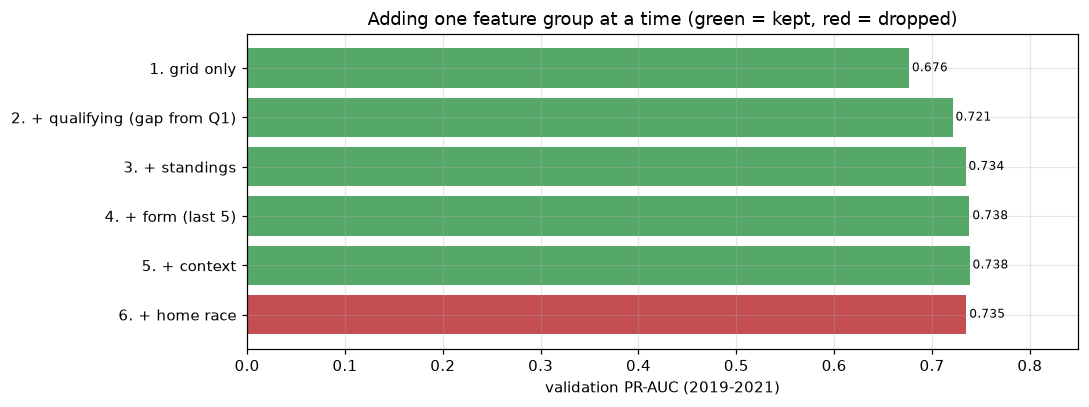

Final feature set: ['grid', 'pit_lane_start', 'gap_q1_pct', 'grid_minus_quali', 'reached_q3', 'no_q3_format', 'quali_missing', 'drv_champ_pos', 'cons_points_share', 'drv_no_standing_yet', 'cons_no_standing_yet', 'drv_podium_rate_5', 'drv_avg_finish_5', 'drv_dnf_rate_5', 'cons_podium_rate_5', 'n_starters', 'drv_experience', 'drv_age']


In [84]:
trials_df = pd.DataFrame(TRIALS)
display(trials_df)

main = trials_df[trials_df["trial"].str.match(r"^\d\. ")]
fig, ax = plt.subplots(figsize=(10, 3.8))
colors = ["#55A868" if ("keep" in str(n) or n == "baseline") else "#C44E52" for n in main["note"]]
ax.barh(main["trial"], main["val PR-AUC"], color=colors)
for y, v in enumerate(main["val PR-AUC"]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, max(main["val PR-AUC"]) * 1.15)
ax.set_xlabel("validation PR-AUC (2019-2021)")
ax.set_title("Adding one feature group at a time (green = kept, red = dropped)")
plt.tight_layout()
plt.show()
print("Final feature set:", current)

**What the trials show.**
- **Grid alone** already gives validation PR-AUC **0.676**.
- **Qualifying** adds the most (+0.045 to **0.721**). Together with grid, it is the clearest evidence of predictive value: it is the only gain whose 95% interval is entirely above 0 (+0.019 to +0.071).
- **Standings** (+0.013), **form** (+0.004) and **context** (+0.0002) each raise the score only a little, and **all three intervals include 0**. So this trial does **not** show that they help; for this linear model, most of what they say is already in grid and qualifying.
- They are **kept** for two reasons, not because of these gains: (1) their 4.3 plots on the training seasons show a clear link with podiums, and (2) adding them doesn't clearly lower the validation score. Form is also required by the brief.
- These trials use **logistic regression only**. A feature that adds little to a linear model can still help a tree model or a neural network (or the reverse), so the feature-group ablation in the **model-experiments section** (after pre-processing) re-tests each group with every model.
- **Home race** lowers the score (−0.003, interval entirely below 0) and is **dropped**. That drop is small too; the main reason is Q2, which found no home advantage once the starting position is known.
- The model doesn't overfit: training PR-AUC (0.69) is close to validation (0.74). Validation being slightly higher is most likely because a few teams dominated 2019–2021, which makes podiums easier to predict.
- **Final set: 18 features** in four groups (grid, qualifying, standings, form) plus context. Final validation PR-AUC **0.738** for this simple model, up from 0.676 with grid only.

## 4.6 Final feature set

The features below are used by all models in the next sections (model A, and model B with the same features). For each one: the group, why it is known **before the race**, and the evidence behind it.

In [85]:
WHY_PRE_RACE = {
    "grid": "starting order, fixed before the start", "pit_lane_start": "known from the starting order",
    "gap_q1_pct": "Q1 lap times, set before the race", "grid_minus_quali": "grid and qualifying, both known before the start",
    "reached_q3": "qualifying result", "no_q3_format": "qualifying format of the season", "quali_missing": "whether qualifying data exists",
    "quali_pos": "qualifying result",
    "drv_champ_pos": "standings after the PREVIOUS race", "drv_points_share": "standings after the PREVIOUS race",
    "drv_no_standing_yet": "standings after the PREVIOUS race", "cons_champ_pos": "standings after the PREVIOUS race",
    "cons_points_share": "standings after the PREVIOUS race", "cons_no_standing_yet": "standings after the PREVIOUS race",
    f"drv_podium_rate_{FORM_WINDOW}": "earlier races only (shift(1), asserted)", f"drv_avg_finish_{FORM_WINDOW}": "earlier races only (shift(1), asserted)",
    f"drv_dnf_rate_{FORM_WINDOW}": "earlier races only (shift(1), asserted)", f"cons_podium_rate_{FORM_WINDOW}": "earlier races only (shift(1), asserted)",
    "n_starters": "entry list / starting grid", "drv_experience": "count of earlier starts", "drv_age": "birth date and race date",
    "home_race": "nationality and circuit country",
}
group_of = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}
TRIAL_OF_GROUP = {"grid": 1, "qualifying": 2, "standings": 3, "form": 4, "context": 5}
FINAL_FEATURES = list(current)
final_table = pd.DataFrame({
    "feature": FINAL_FEATURES,
    "group": [group_of.get(c, "context") for c in FINAL_FEATURES],
    "known before the race because": [WHY_PRE_RACE[c] for c in FINAL_FEATURES],
    "AUC alone (train)": [auc_alone.get(c, np.nan) for c in FINAL_FEATURES],
    "evidence": [f"4.3 plot + trial {TRIAL_OF_GROUP[group_of.get(c, 'context')]} (4.5)" for c in FINAL_FEATURES],
})
display(final_table)

dropped = [c for c in ALL_CANDIDATES + ["quali_pos", "drv_champ_pos", "drv_points_share", "cons_champ_pos", "cons_points_share"]
           if c not in FINAL_FEATURES]
print("Candidates not used:", sorted(set(dropped)))
assert not set(FINAL_FEATURES) & set(POST_RACE)

,feature,group,known before the race because,AUC alone (train),evidence
0,grid,grid,"starting order, fixed before the start",0.907,4.3 plot + trial 1 (4.5)
1,pit_lane_start,grid,known from the starting order,0.501,4.3 plot + trial 1 (4.5)
2,gap_q1_pct,qualifying,"Q1 lap times, set before the race",0.829,4.3 plot + trial 2 (4.5)
3,grid_minus_quali,qualifying,"grid and qualifying, both known before the start",0.556,4.3 plot + trial 2 (4.5)
4,reached_q3,qualifying,qualifying result,0.787,4.3 plot + trial 2 (4.5)
5,no_q3_format,qualifying,qualifying format of the season,0.508,4.3 plot + trial 2 (4.5)
6,quali_missing,qualifying,whether qualifying data exists,0.502,4.3 plot + trial 2 (4.5)
7,drv_champ_pos,standings,standings after the PREVIOUS race,0.854,4.3 plot + trial 3 (4.5)
8,cons_points_share,standings,standings after the PREVIOUS race,0.856,4.3 plot + trial 3 (4.5)
9,drv_no_standing_yet,standings,standings after the PREVIOUS race,0.507,4.3 plot + trial 3 (4.5)


Candidates not used: ['cons_champ_pos', 'drv_points_share', 'home_race', 'quali_pos']


**Summary.** The models will use **18 features**: grid (2), qualifying (5, including the format flags), standings (4), form (4) and context (3). Every one is known before the race starts. Standings come from the previous race, and form was proven by the asserts in 4.2 to use only earlier races. Not used: `quali_pos` and `drv_points_share` / `cons_champ_pos` (near-duplicates, 4.4), and `home_race` (lowered the score, 4.5). Model B uses the same 18 features; its `quali_missing` flag marks the seasons without qualifying data. Missing values (a driver's first race, a team's first race or first race after a long absence, `reached_q3` before 2006) are handled in the pre-processing section.

**How strong is the evidence?** Grid and qualifying clearly help (4.5). Standings, form and context are kept because of their training-season plots (4.3) and because they don't clearly hurt the validation score; their gains in the logistic-regression trials are small and uncertain. Whether they help the other models is tested in the feature-group ablation of the model-experiments section.

## 4.7 Final feature table in memory

`final_features_df` contains all 1950–2024 rows, split labels, target and 18 features (23 columns total). Rows remain sorted by race chronology, grid, and driverId. Missing values remain missing until training-only preprocessing.

In [86]:
EXPORT_COLUMNS = ["raceId", "driverId", "year", "split", "podium"] + list(FINAL_FEATURES)
assert len(FINAL_FEATURES) == 18 and len(EXPORT_COLUMNS) == 23 and len(set(EXPORT_COLUMNS)) == 23
assert not set(FINAL_FEATURES) & set(POST_RACE)

final_features_df = (feat.sort_values(["race_seq", "grid", "driverId"])[EXPORT_COLUMNS]
                     .reset_index(drop=True))
assert not final_features_df.duplicated(["raceId", "driverId"]).any()
assert len(final_features_df) == len(feat)


# Read the file back: same rows, same values, missing values still missing.
back = final_features_df.copy(deep=True)
assert list(back.columns) == EXPORT_COLUMNS
pd.testing.assert_frame_equal(back, final_features_df, check_dtype=False, check_exact=True)
print(f"In-memory features: {len(back):,} rows x {back.shape[1]} columns.")

print("Missing values per feature (%), only features with gaps; 'train' here is all training seasons 1950-2018:")
display(pd.DataFrame({f"{s} {lo}-{hi}": back.loc[back["split"] == s, FINAL_FEATURES].isna().mean().mul(100).round(1)
                      for s, (lo, hi) in [("train", (back["year"].min(), SPLIT_YEARS["train"][1])),
                                          ("validation", SPLIT_YEARS["validation"]), ("test", SPLIT_YEARS["test"])]})
        .loc[lambda d: d.max(axis=1) > 0])
display(back["split"].value_counts().rename("rows").to_frame().T)

In-memory features: 24,645 rows x 23 columns.
Missing values per feature (%), only features with gaps; 'train' here is all training seasons 1950-2018:


,train 1950-2018,validation 2019-2021,test 2022-2024
gap_q1_pct,64.8,1.7,1.0
grid_minus_quali,64.2,0.3,0.0
reached_q3,75.9,0.3,0.0
drv_podium_rate_5,3.0,0.8,0.6
drv_avg_finish_5,3.0,0.8,0.6
drv_dnf_rate_5,3.0,0.8,0.6
cons_podium_rate_5,1.4,0.8,0.3


split,train,test,validation
rows,22092,1354,1199


# 5. Pre-processing

**Goal:** turn the 18 final features into model inputs with **no missing values** and comparable scales, without leaking anything from the validation or test seasons.

Rules for this section:
- **Every learned value** (percentiles, medians, scaler means and spreads) is **fitted on training rows only**, then applied unchanged to validation (and, in the final evaluation, test). Model A fits on 2003–2018, model B on 1950–2018, **separately**.
- `final_features_df` is **copied, never changed**; it keeps the 18 features with their missing values. Pre-processing happens inside a scikit-learn `Pipeline`, so the same steps can be applied to a single new record later.
- The **test seasons are not used** in this section.
- The only model here is a temporary **logistic regression**, used to compare pre-processing alternatives. Model training and tuning come in the next section.

Plan: 5.1 load and feature types · 5.2 missing-value audit · 5.3 the imputation step · 5.4 outliers (`gap_q1_pct` cap) · 5.5 scaling · 5.6 order experiments · 5.7 final pipelines · 5.8 leakage and behaviour checks.

## 5.1 Feature types

Use an independent copy of the section 4 feature table. Continuous features and binary flags are classified below. Identifiers, year, split and target are never inputs.

In [87]:
import hashlib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.metrics import f1_score, precision_recall_curve
from sklearn.pipeline import Pipeline

FF_SHA_BEFORE = hashlib.sha256(final_features_df.to_csv(index=False).encode()).hexdigest()   # checked again in 5.8
data = final_features_df.copy(deep=True)
pd.testing.assert_frame_equal(data, final_features_df, check_dtype=False, check_exact=True)

NOT_INPUTS = ["raceId", "driverId", "year", "split", "podium"]
BINARY_FEATURES = ["pit_lane_start", "reached_q3", "no_q3_format", "quali_missing", "drv_no_standing_yet", "cons_no_standing_yet"]
CONTINUOUS_FEATURES = [c for c in FINAL_FEATURES if c not in BINARY_FEATURES]
DRV_FORM = [f"drv_podium_rate_{FORM_WINDOW}", f"drv_avg_finish_{FORM_WINDOW}", f"drv_dnf_rate_{FORM_WINDOW}"]
CONS_FORM = f"cons_podium_rate_{FORM_WINDOW}"
assert set(CONTINUOUS_FEATURES) | set(BINARY_FEATURES) == set(FINAL_FEATURES) and not set(NOT_INPUTS) & set(FINAL_FEATURES)
assert all(set(data[c].dropna().unique()) <= {0, 1} for c in BINARY_FEATURES)

# The three row sets used in this section. Test rows are never selected.
TRAIN_A_ROWS = data[(data["split"] == "train") & (data["year"] >= MODEL_START_YEAR)].reset_index(drop=True)
TRAIN_B_ROWS = data[data["split"] == "train"].reset_index(drop=True)
VAL_ROWS = data[data["split"] == "validation"].reset_index(drop=True)
SETS = {"train A (2003-2018)": TRAIN_A_ROWS, "train B (1950-2018)": TRAIN_B_ROWS, "validation (2019-2021)": VAL_ROWS}

display(pd.DataFrame({"feature": FINAL_FEATURES,
                      "type": ["binary 0/1" if c in BINARY_FEATURES else "continuous" for c in FINAL_FEATURES],
                      "range in train A": [f"{TRAIN_A_ROWS[c].min():g} to {TRAIN_A_ROWS[c].max():g}" for c in FINAL_FEATURES]}))
print({name: len(rows) for name, rows in SETS.items()}, "| not inputs:", NOT_INPUTS)

,feature,type,range in train A
0,grid,continuous,1 to 24
1,pit_lane_start,binary 0/1,0 to 1
2,gap_q1_pct,continuous,0 to 33.2853
3,grid_minus_quali,continuous,-7 to 23
4,reached_q3,binary 0/1,0 to 1
5,no_q3_format,binary 0/1,0 to 1
6,quali_missing,binary 0/1,0 to 1
7,drv_champ_pos,continuous,1 to 28
8,cons_points_share,continuous,0 to 1
9,drv_no_standing_yet,binary 0/1,0 to 1


{'train A (2003-2018)': 6381, 'train B (1950-2018)': 22092, 'validation (2019-2021)': 1199} | not inputs: ['raceId', 'driverId', 'year', 'split', 'podium']


## 5.2 Missing-value audit

Seven of the 18 features have gaps. Before choosing how to fill them, we check **why** each one is missing and whether the fact that it is missing says something about podium chances.

,train A (2003-2018) n,train B (1950-2018) n,validation (2019-2021) n,train A (2003-2018) %,train B (1950-2018) %,validation (2019-2021) %
gap_q1_pct,113,14314,20,1.8,64.8,1.7
grid_minus_quali,19,14189,3,0.3,64.2,0.3
reached_q3,1061,16772,3,16.6,75.9,0.3
drv_podium_rate_5,72,669,9,1.1,3.0,0.8
drv_avg_finish_5,72,669,9,1.1,3.0,0.8
drv_dnf_rate_5,72,669,9,1.1,3.0,0.8
cons_podium_rate_5,41,320,10,0.6,1.4,0.8


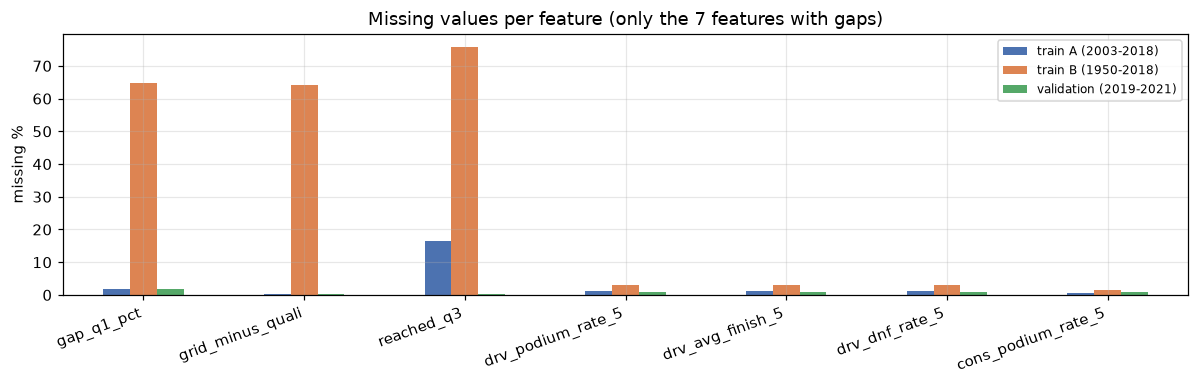

In [88]:
miss = pd.DataFrame({f"{name} n": rows[FINAL_FEATURES].isna().sum() for name, rows in SETS.items()})
for name, rows in SETS.items():
    miss[f"{name} %"] = (100 * rows[FINAL_FEATURES].isna().mean()).round(1)
miss = miss[miss.filter(like=" n").sum(axis=1) > 0]
display(miss)

fig, ax = plt.subplots(figsize=(11, 3.6))
pct = miss.filter(like=" %")
pct.plot.bar(ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylabel("missing %")
ax.set_title("Missing values per feature (only the 7 features with gaps)")
ax.legend([c.replace(" %", "") for c in pct.columns], fontsize=8)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [89]:
# WHY values are missing: each gap has one exact cause (checked on all non-test rows).
nontest = pd.concat([TRAIN_B_ROWS, VAL_ROWS])
causes = {
    "grid_minus_quali missing  <=>  quali_missing = 1":
        (nontest["grid_minus_quali"].isna() == (nontest["quali_missing"] == 1)).all(),
    "reached_q3 missing  <=>  no_q3_format = 1 or quali_missing = 1":
        (nontest["reached_q3"].isna() == ((nontest["no_q3_format"] == 1) | (nontest["quali_missing"] == 1))).all(),
    "the 3 driver-form features are missing together  <=>  drv_experience = 0 (debut)":
        ((nontest[DRV_FORM].isna().all(axis=1) == nontest[DRV_FORM].isna().any(axis=1))
         & (nontest[DRV_FORM[0]].isna() == (nontest["drv_experience"] == 0))).all(),
}
for k, v in causes.items():
    assert v, k
    print("OK ", k)

# Does missingness carry information? Podium rate when a value is missing vs overall.
def missing_profile(rows):
    no_q1 = rows["gap_q1_pct"].isna() & (rows["quali_missing"] == 0)
    groups = {"qualifying exists, no Q1 time": no_q1, "no qualifying record (quali_missing)": rows["quali_missing"] == 1,
              "driver form missing (debut)": rows[DRV_FORM[0]].isna(), "team form missing (new team / comeback)": rows[CONS_FORM].isna(),
              "all rows": pd.Series(True, index=rows.index)}
    return pd.DataFrame({g: {"rows": int(m.sum()), "podium %": round(100 * rows.loc[m, "podium"].mean(), 1) if m.any() else np.nan,
                             "median grid": rows.loc[m, "grid"].median() if m.any() else np.nan} for g, m in groups.items()}).T
print("\nTrain A (2003-2018):")
display(missing_profile(TRAIN_A_ROWS))
print("Train B (1950-2018):")
display(missing_profile(TRAIN_B_ROWS))

OK  grid_minus_quali missing  <=>  quali_missing = 1
OK  reached_q3 missing  <=>  no_q3_format = 1 or quali_missing = 1
OK  the 3 driver-form features are missing together  <=>  drv_experience = 0 (debut)

Train A (2003-2018):


,rows,podium %,median grid
"qualifying exists, no Q1 time",94.0,4.3,20.0
no qualifying record (quali_missing),19.0,0.0,22.0
driver form missing (debut),72.0,2.8,17.0
team form missing (new team / comeback),41.0,4.9,18.0
all rows,6381.0,14.1,11.0


Train B (1950-2018):


,rows,podium %,median grid
"qualifying exists, no Q1 time",125.0,5.6,20.0
no qualifying record (quali_missing),14189.0,13.1,12.0
driver form missing (debut),669.0,2.4,18.0
team form missing (new team / comeback),320.0,4.7,16.5
all rows,22092.0,13.4,12.0


**What the audit shows.**
- **`gap_q1_pct` has two different kinds of gap.** (1) The driver **has a qualifying entry but no Q1 time** (crash, no lap set, lap deleted): these drivers start near the back and rarely reach the podium, so the gap means *slow*. (2) There is **no qualifying record at all** (most of model B's seasons): the data is simply absent, which says nothing about pace; `quali_missing` already marks it.
- **`grid_minus_quali` and `reached_q3`** are missing **exactly** when `quali_missing` (or, for `reached_q3`, `no_q3_format`) is 1. The existing flags already describe these gaps, so a new indicator would only duplicate them.
- **Driver form** is missing **exactly** on a driver's debut (all three columns together), and **team form** on a team's first race (or first race after a long absence). Both groups reach the podium much less often than average, so the fact that the value is missing is useful.
- **Standings have no gaps**: they were filled by rule in 4.2 ("behind the last ranked driver, 0% of the leader's points") and carry the `no_standing_yet` flags.

In model B the picture is the same, only much larger: most old seasons have no qualifying record at all.

## 5.3 The imputation step

One small transformer, `F1Imputer`, does all of the filling. Steps, in this order:
1. **Indicators first**, from the raw values (before anything is filled):
   - `q1_time_missing` = no Q1 time **while a qualifying record exists** (it is never 1 when `quali_missing` is 1, so it doesn't duplicate that flag);
   - `drv_form_missing` = the driver has no earlier race (debut);
   - `cons_form_missing` = the team has no earlier race in its current history segment.
2. **Fit on the training rows** (observed values only): the 95th and 99th percentiles and the median of `gap_q1_pct`, and the median of every continuous feature.
3. **Fill:**

| Gap | Filled with | Why |
|---|---|---|
| `gap_q1_pct`, qualifying record but no Q1 time | training **95th percentile** of the gap (a slow lap) | these drivers start at the back; the median would make them look mid-field, and 0 would make them look fastest |
| `gap_q1_pct`, no qualifying record | training **median** (neutral) | the data is absent, not slow; `quali_missing` stays in the model |
| `grid_minus_quali` | **0** ("no known penalty"; also the training median) | missing exactly when `quali_missing` = 1 |
| `reached_q3` | **0**, keeping the column 0/1 | missing exactly when `no_q3_format` or `quali_missing` = 1; with those flags in the model, the constant doesn't limit what a linear model can learn |
| driver form (3), team form | training **median** | the indicators carry the "debut / new team" information |
| anything else (only possible in a new, partial record) | training median (continuous) or 0 (flags); a missing `quali_missing` is derived from whether the qualifying features are present | lets one incomplete record be scored safely |

4. **Cap** `gap_q1_pct` at the training **99th percentile** (5.4). The cap is fitted on **observed** laps only, before any filling, so filled values can't move it.

The output has **21 columns**: the 18 features (no missing values left) + the 3 indicators.

In [90]:
INDICATORS = ["q1_time_missing", "drv_form_missing", "cons_form_missing"]


class F1Imputer(BaseEstimator, TransformerMixin):
    """Missingness indicators, gap_q1_pct cap and fills for the 18 final features.

    Every learned value comes from the rows passed to fit(). fill=False only adds the indicators and the cap
    (used by experiment E1, where KNN imputation does the filling). cap_before_impute=False fits the cap on the
    filled column instead of the observed laps (experiment E2).
    """

    def __init__(self, cap_quantile=0.99, slow_quantile=0.95, cap_before_impute=True, fill=True):
        self.cap_quantile = cap_quantile
        self.slow_quantile = slow_quantile
        self.cap_before_impute = cap_before_impute
        self.fill = fill

    @staticmethod
    def _prepare(X):
        X = pd.DataFrame(X, columns=FINAL_FEATURES) if not isinstance(X, pd.DataFrame) else X[FINAL_FEATURES]
        X = X.astype(float).copy()
        # A partial record may lack the flag itself: no qualifying features at all -> no qualifying record.
        unknown = X["quali_missing"].isna()
        X.loc[unknown, "quali_missing"] = (X.loc[unknown, "gap_q1_pct"].isna()
                                           & X.loc[unknown, "grid_minus_quali"].isna()).astype(float)
        return X

    @staticmethod
    def _indicators(X):
        return pd.DataFrame({"q1_time_missing": (X["gap_q1_pct"].isna() & (X["quali_missing"] == 0)).astype(float),
                             "drv_form_missing": X[DRV_FORM].isna().all(axis=1).astype(float),
                             "cons_form_missing": X[CONS_FORM].isna().astype(float)}, index=X.index)

    def _fill_gap(self, X, ind):
        gap = X["gap_q1_pct"].copy()
        gap[ind["q1_time_missing"] == 1] = self.gap_slow_
        return gap.fillna(self.gap_neutral_)

    def fit(self, X, y=None):
        X = self._prepare(X)
        observed = X["gap_q1_pct"].dropna()
        self.gap_slow_ = float(observed.quantile(self.slow_quantile))
        self.gap_neutral_ = float(observed.median())
        self.medians_ = X[CONTINUOUS_FEATURES].median()
        if self.cap_before_impute:
            self.gap_cap_ = float(observed.quantile(self.cap_quantile))
        else:
            self.gap_cap_ = float(self._fill_gap(X, self._indicators(X)).quantile(self.cap_quantile))
        self.n_features_in_ = len(FINAL_FEATURES)
        self.feature_names_in_ = np.array(FINAL_FEATURES, dtype=object)
        return self

    def transform(self, X):
        X = self._prepare(X)
        ind = self._indicators(X)                       # 1. indicators from the raw values
        if self.fill:
            X["gap_q1_pct"] = self._fill_gap(X, ind)
            X["grid_minus_quali"] = X["grid_minus_quali"].fillna(0.0)
            X["reached_q3"] = X["reached_q3"].fillna(0.0)
            X[CONTINUOUS_FEATURES] = X[CONTINUOUS_FEATURES].fillna(self.medians_)   # form features + partial records
            X[BINARY_FEATURES] = X[BINARY_FEATURES].fillna(0.0)
        X["gap_q1_pct"] = X["gap_q1_pct"].clip(upper=self.gap_cap_)
        return pd.concat([X, ind], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.array(FINAL_FEATURES + INDICATORS, dtype=object)


def make_preprocessor(scaled=True, **imputer_args):
    """scaled=True: for logistic regression and the neural network. scaled=False: for tree models."""
    steps = [("impute", F1Imputer(**imputer_args))]
    if scaled:
        steps.append(("scale", ColumnTransformer([("continuous", StandardScaler(), CONTINUOUS_FEATURES)],
                                                 remainder="passthrough", verbose_feature_names_out=False)))
    return Pipeline(steps).set_output(transform="pandas")


FIT_LOG = []   # every pre-processing fit in this section is recorded, to prove that only training rows were used


def fit_on_training(pipe, rows, label):
    assert set(rows["split"]) == {"train"}, f"{label}: fit on non-training rows"
    FIT_LOG.append({"fit": label, "rows": len(rows), "splits": ",".join(sorted(set(rows["split"]))),
                    "seasons": f"{rows['year'].min()}-{rows['year'].max()}"})
    return pipe.fit(rows[FINAL_FEATURES])


imp_A = fit_on_training(F1Imputer(), TRAIN_A_ROWS, "F1Imputer, model A")
imp_B = fit_on_training(F1Imputer(), TRAIN_B_ROWS, "F1Imputer, model B")
display(pd.DataFrame({
    "model A (fitted on 2003-2018)": [imp_A.gap_slow_, imp_A.gap_neutral_, imp_A.gap_cap_] + list(imp_A.medians_[DRV_FORM + [CONS_FORM]]),
    "model B (fitted on 1950-2018)": [imp_B.gap_slow_, imp_B.gap_neutral_, imp_B.gap_cap_] + list(imp_B.medians_[DRV_FORM + [CONS_FORM]]),
}, index=["gap_q1_pct fill: no Q1 time (95th pct)", "gap_q1_pct fill: no qualifying record (median)", "gap_q1_pct cap (99th pct)"]
   + [f"{c} fill (median)" for c in DRV_FORM + [CONS_FORM]]).round(3))

# Model B check: does the rule still make sense with its very different qualifying coverage?
for name, rows, imp in [("A", TRAIN_A_ROWS, imp_A), ("B", TRAIN_B_ROWS, imp_B)]:
    out = imp.transform(rows[FINAL_FEATURES])
    print(f"Model {name}: q1_time_missing = 1 on {int(out['q1_time_missing'].sum())} rows "
          f"(podium {100 * rows.loc[out['q1_time_missing'] == 1, 'podium'].mean():.1f}%), "
          f"quali_missing = 1 on {int(rows['quali_missing'].sum())} rows; "
          f"q1_time_missing and quali_missing both 1: {int(((out['q1_time_missing'] == 1) & (out['quali_missing'] == 1)).sum())}; "
          f"missing values left: {int(out.isna().sum().sum())}")

,model A (fitted on 2003-2018),model B (fitted on 1950-2018)
gap_q1_pct fill: no Q1 time (95th pct),5.185,5.697
gap_q1_pct fill: no qualifying record (median),1.359,1.533
gap_q1_pct cap (99th pct),7.856,9.015
drv_podium_rate_5 fill (median),0.000,0.000
drv_avg_finish_5 fill (median),11.400,12.000
drv_dnf_rate_5 fill (median),0.200,0.400
cons_podium_rate_5 fill (median),0.000,0.000


Model A: q1_time_missing = 1 on 94 rows (podium 4.3%), quali_missing = 1 on 19 rows; q1_time_missing and quali_missing both 1: 0; missing values left: 0
Model B: q1_time_missing = 1 on 125 rows (podium 5.6%), quali_missing = 1 on 14189 rows; q1_time_missing and quali_missing both 1: 0; missing values left: 0


**What this did.**
- The fitted values differ between the models because their training seasons differ (model B also includes the 1994–2002 qualifying data, with bigger gaps). Each model keeps its own values.
- **Model B check:** the rule holds. `q1_time_missing` is 1 only for drivers who have a qualifying record without a Q1 time; it never overlaps with `quali_missing`. The thousands of model-B rows with no qualifying record get the **neutral** median and keep `quali_missing = 1`, so old seasons are not treated as "slow".
- No missing values are left after this step.

## 5.4 Outliers: capping `gap_q1_pct`

`gap_q1_pct` has a long right tail: a handful of Q1 laps are 10–33% slower than the fastest (rain, a damaged car, a lap aborted early). Beyond a few percent these drivers almost never reach the podium, so the exact size of the gap adds nothing, but one extreme lap stretches the scale that the neural network and the scaler rely on. We **cap** it at the training 99th percentile: every row is kept and the order of the values is unchanged; only the extreme values are pulled in.

Not capped, on purpose:
- **`grid_minus_quali`** (up to +23): a big value is a real penalty start, exactly the "qualified fast, started at the back" signal found in Q1.
- **Model B's** `drv_champ_pos` (up to 104), `n_starters` (up to 34), `drv_avg_finish_5` (up to 31): real field sizes of the 1950s–80s.

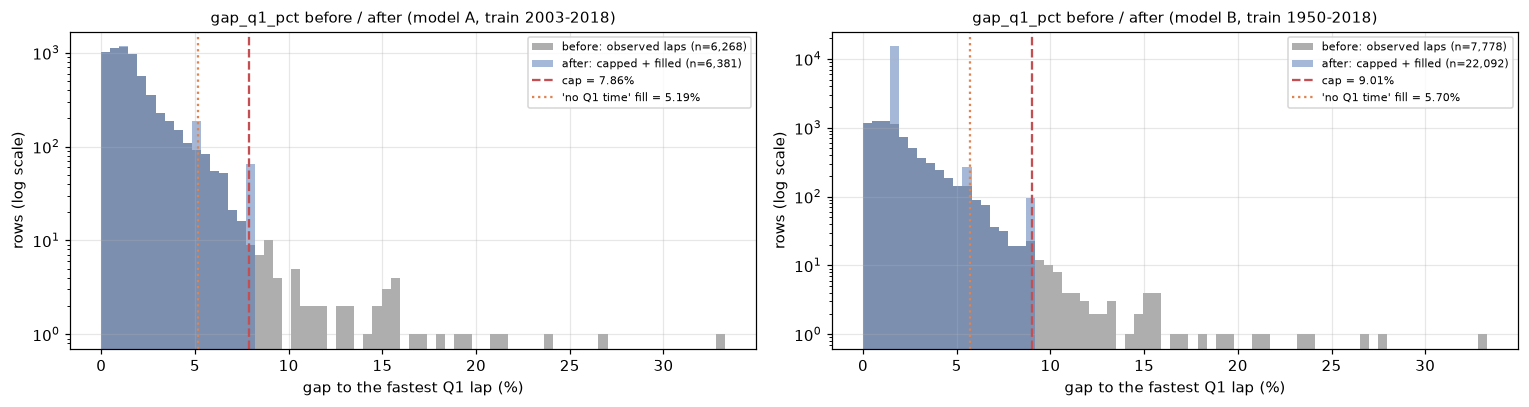

,model,cap (%),rows capped,largest value before,podiums among capped rows,rows kept
0,A,7.86,63,33.29,4,6381
1,B,9.01,78,33.29,3,22092


In [91]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (name, rows, imp) in zip(axes, [("model A, train 2003-2018", TRAIN_A_ROWS, imp_A), ("model B, train 1950-2018", TRAIN_B_ROWS, imp_B)]):
    raw = rows["gap_q1_pct"].dropna()
    after = imp.transform(rows[FINAL_FEATURES])["gap_q1_pct"]
    bins = np.linspace(0, max(raw.max(), 1), 70)
    ax.hist(raw, bins=bins, color="#8C8C8C", alpha=0.7, label=f"before: observed laps (n={len(raw):,})")
    ax.hist(after, bins=bins, color="#4C72B0", alpha=0.5, label=f"after: capped + filled (n={len(after):,})")
    ax.axvline(imp.gap_cap_, color="#C44E52", ls="--", label=f"cap = {imp.gap_cap_:.2f}%")
    ax.axvline(imp.gap_slow_, color="#DD8452", ls=":", label=f"'no Q1 time' fill = {imp.gap_slow_:.2f}%")
    ax.set_yscale("log")
    ax.set_xlabel("gap to the fastest Q1 lap (%)")
    ax.set_ylabel("rows (log scale)")
    ax.set_title(f"gap_q1_pct before / after ({name})", fontsize=10)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

cap_table = []
for name, rows, imp in [("A", TRAIN_A_ROWS, imp_A), ("B", TRAIN_B_ROWS, imp_B)]:
    raw = rows["gap_q1_pct"]
    capped = raw > imp.gap_cap_
    cap_table.append({"model": name, "cap (%)": round(imp.gap_cap_, 2), "rows capped": int(capped.sum()),
                      "largest value before": round(raw.max(), 2), "podiums among capped rows": int(rows.loc[capped, "podium"].sum()),
                      "rows kept": len(rows)})
display(pd.DataFrame(cap_table))

**What this shows.** The cap only touches the far tail (about 1% of observed laps; the table gives the counts). A few of those drivers still reached the podium (a slow Q1 lap in changing weather, or a quick driver who only needed one run to get through): after the cap they are still among the slowest Q1 laps, just not by an extreme number, and their rows are kept. The order of the values doesn't change, so a tree model sees the same splits. The second spike in the "after" histogram is the "no Q1 time" fill (a slow lap), and the neutral median fill for rows with no qualifying record sits in the bulk of the distribution (in model B this is a large spike, because most old seasons have no qualifying data).

## 5.5 Scaling

- **Logistic regression and the neural network:** the 12 continuous features are **standardised** (training mean 0, standard deviation 1). Logistic regression's penalty and neural-network training both work best when features have similar scales; here they range from 0–1 (rates) to 0–324 (`drv_experience`).
- **The 6 flags and 3 indicators stay 0/1**, so a coefficient still reads as "the effect of the flag being on".
- **Tree models** (random forest, gradient boosting) get the same imputed table **without scaling**: a tree only uses the order of a feature's values, which scaling doesn't change.
- No other transformation (log of grid, 1/grid, log of experience, log of the gap, a robust scaler) is applied: the check at the end of 5.6 shows none of them improves validation PR-AUC beyond noise, so they would add complexity without evidence.

Column names are kept (pandas output), so later explanations (SHAP) can name every input.

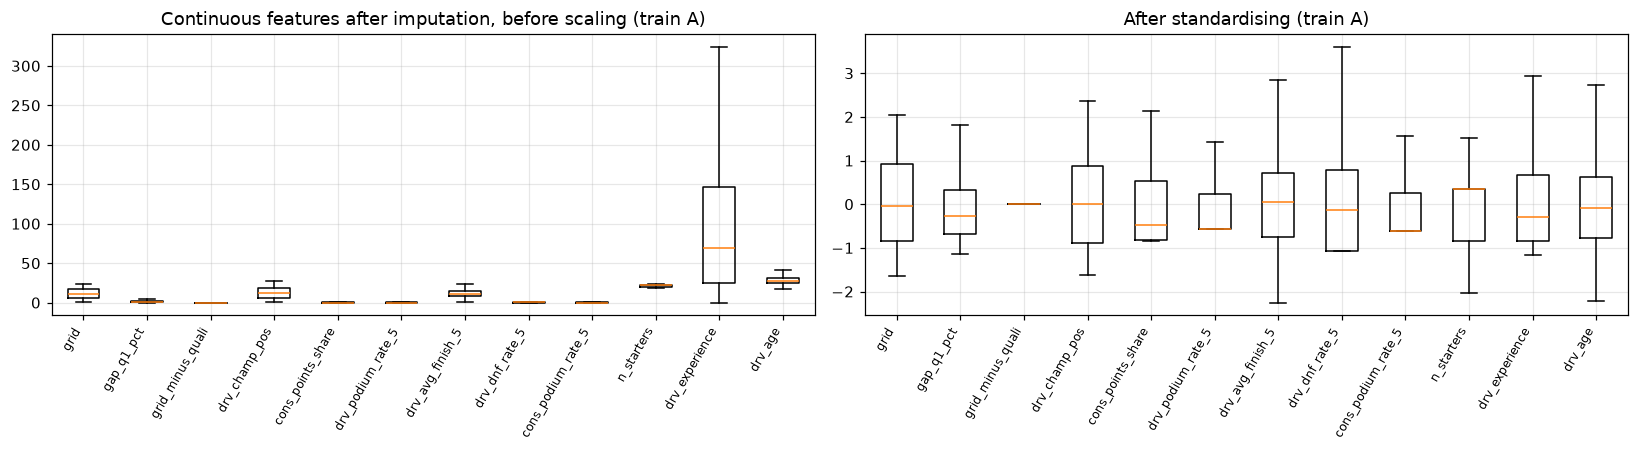

Train A after scaling: every continuous feature has mean 0 and standard deviation 1.
Flags and indicators are still 0/1. Output columns: ['grid', 'gap_q1_pct', 'grid_minus_quali', 'drv_champ_pos', 'cons_points_share', 'drv_podium_rate_5', 'drv_avg_finish_5', 'drv_dnf_rate_5', 'cons_podium_rate_5', 'n_starters', 'drv_experience', 'drv_age', 'pit_lane_start', 'reached_q3', 'no_q3_format', 'quali_missing', 'drv_no_standing_yet', 'cons_no_standing_yet', 'q1_time_missing', 'drv_form_missing', 'cons_form_missing']


In [92]:
scaled_A = fit_on_training(make_preprocessor(scaled=True), TRAIN_A_ROWS, "scaled pipeline, model A")
after = scaled_A.transform(TRAIN_A_ROWS[FINAL_FEATURES])
before = imp_A.transform(TRAIN_A_ROWS[FINAL_FEATURES])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].boxplot([before[c] for c in CONTINUOUS_FEATURES], showfliers=False)
axes[0].set_title("Continuous features after imputation, before scaling (train A)")
axes[1].boxplot([after[c] for c in CONTINUOUS_FEATURES], showfliers=False)
axes[1].set_title("After standardising (train A)")
for ax in axes:
    ax.set_xticks(range(1, len(CONTINUOUS_FEATURES) + 1), CONTINUOUS_FEATURES, rotation=60, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({"mean": after[CONTINUOUS_FEATURES].mean(), "std": after[CONTINUOUS_FEATURES].std(ddof=0)}).round(3)
assert np.allclose(summary["mean"], 0, atol=1e-9) and np.allclose(summary["std"], 1, atol=1e-9)
print("Train A after scaling: every continuous feature has mean 0 and standard deviation 1.")
assert all(set(after[c].unique()) <= {0, 1} for c in BINARY_FEATURES + INDICATORS)
print("Flags and indicators are still 0/1. Output columns:", list(after.columns))

## 5.6 Pre-processing order experiments

The brief asks for at least two experiments where only the **order** of pre-processing steps changes. Common setup for every experiment:
- the same **model A training rows** (2003–2018, unless stated) and the same **1,199 validation rows**;
- the same downstream model: logistic regression (default settings, `max_iter=5000`), refitted for each version;
- every learned value fitted on **training rows only**;
- scores: validation **PR-AUC** (main) and **ROC-AUC**, and **F1** at the threshold that maximises F1 on the *training* predictions (so validation isn't used to choose it). The 95% interval of the PR-AUC difference comes from resampling the 60 validation races 500 times.

A first check showed which orders are worth testing:
- **Median imputation then scaling vs scaling then median imputation** is *not* a real experiment: the scaler ignores missing values when it is fitted, so both orders give almost the same numbers (only the scaler's mean and spread move slightly). It is shown below as a consistency check.
- **E1** (KNN imputation vs scaling) and **E2** (capping vs imputation) do change the transformed data, so they are the two experiments.

In [93]:
y_val = VAL_ROWS["podium"].to_numpy()
val_race = VAL_ROWS["raceId"].to_numpy()
rng_s5 = np.random.default_rng(42)
val_races = np.unique(val_race)
VAL_BOOT = [np.concatenate([np.flatnonzero(val_race == r) for r in rng_s5.choice(val_races, len(val_races))]) for _ in range(500)]
EXPERIMENTS = []
EXP_PREDS = {}


def evaluate_preprocessing(name, pre, train_rows=None, model_rows=None, fit_label=None, valid=True):
    """Fit `pre` on training rows, fit logistic regression on the model rows, score validation."""
    train_rows = TRAIN_A_ROWS if train_rows is None else train_rows
    model_rows = train_rows if model_rows is None else model_rows
    if valid:
        fit_on_training(pre, train_rows, fit_label or name)
    else:
        pre.fit(train_rows[FINAL_FEATURES])                     # only for the labelled INVALID demonstration
    X_tr, X_va = pre.transform(model_rows[FINAL_FEATURES]), pre.transform(VAL_ROWS[FINAL_FEATURES])
    assert not X_tr.isna().any().any() and not X_va.isna().any().any()
    lr = LogisticRegression(max_iter=5000).fit(X_tr, model_rows["podium"])
    p_tr, p_va = lr.predict_proba(X_tr)[:, 1], lr.predict_proba(X_va)[:, 1]
    prec, rec, thr = precision_recall_curve(model_rows["podium"], p_tr)
    f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    threshold = thr[np.argmax(f1s)]
    EXP_PREDS[name] = p_va
    res = {"version": name, "val PR-AUC": round(average_precision_score(y_val, p_va), 4),
           "val ROC-AUC": round(roc_auc_score(y_val, p_va), 4), "threshold (from train)": round(float(threshold), 3),
           "val F1": round(f1_score(y_val, p_va >= threshold), 4)}
    EXPERIMENTS.append(res)
    return res, pre


def pr_auc_difference(a, b):
    """PR-AUC(b) - PR-AUC(a) with a 95% race-resampling interval."""
    pa, pb = EXP_PREDS[a], EXP_PREDS[b]
    d = [average_precision_score(y_val[i], pb[i]) - average_precision_score(y_val[i], pa[i]) for i in VAL_BOOT]
    point = average_precision_score(y_val, pb) - average_precision_score(y_val, pa)
    lo, hi = np.percentile(d, [2.5, 97.5])
    return f"{point:+.4f} (95% interval {lo:+.4f} to {hi:+.4f})"


# Consistency check: median imputation and standard scaling in both orders (no cap, no indicators).
r1, _ = evaluate_preprocessing("check: median impute -> scale",
                               make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).set_output(transform="pandas"))
r2, _ = evaluate_preprocessing("check: scale -> median impute",
                               make_pipeline(StandardScaler(), SimpleImputer(strategy="median")).set_output(transform="pandas"))
display(pd.DataFrame([r1, r2]))
diff = np.abs(EXP_PREDS["check: median impute -> scale"] - EXP_PREDS["check: scale -> median impute"])
print(f"Largest difference in a validation probability: {diff.max():.4f}; PR-AUC difference "
      f"{pr_auc_difference('check: median impute -> scale', 'check: scale -> median impute')}")

,version,val PR-AUC,val ROC-AUC,threshold (from train),val F1
0,check: median impute -> scale,0.7331,0.9319,0.353,0.7172
1,check: scale -> median impute,0.7330,0.9319,0.269,0.7150


Largest difference in a validation probability: 0.0026; PR-AUC difference -0.0000 (95% interval -0.0007 to +0.0009)


**Consistency check.** As expected, the two orders give nearly the same model: the imputed value is the same median either way, and only the scaler's statistics shift a little (they include the filled values in one order and not in the other). This pair is therefore **not** used as one of the two experiments.

### E1: KNN imputation before scaling vs scaling before KNN imputation

**What KNN imputation does:** a missing value is filled with the average of the **5 most similar training rows**, where "similar" is a distance computed over all features.
- **Hypothesis:** without scaling, the distance is dominated by the features with large numbers (`drv_experience` 0–324, `drv_champ_pos`, `grid`), so the "similar" rows are mostly drivers with similar experience. After scaling, every feature counts equally. The **filled values should change**; whether the model's quality changes is the question.
- **A:** indicators + cap → **KNN impute → scale** → logistic regression. **B:** indicators + cap → **scale → KNN impute** → logistic regression.
- **Only the order changes.** Same rows, same 21 inputs, same indicators and cap (both fitted on training rows), same model.

,version,val PR-AUC,val ROC-AUC,threshold (from train),val F1
0,E1-A: KNN impute -> scale,0.7368,0.9364,0.331,0.7168
1,E1-B: scale -> KNN impute,0.7370,0.9364,0.333,0.7136


PR-AUC difference (B - A): +0.0002 (95% interval -0.0016 to +0.0021)


,feature,filled cells,"mean fill, A (raw scale)","mean fill, B (scaled)",mean |A - B|,cells that differ
0,gap_q1_pct,113,3.241,3.447,0.943,113
1,grid_minus_quali,19,1.211,1.811,1.611,17
2,reached_q3,1061,0.500,0.494,0.081,279
3,drv_podium_rate_5,72,0.001,0.009,0.008,9
4,drv_avg_finish_5,72,16.246,14.857,2.103,72
5,drv_dnf_rate_5,72,0.486,0.378,0.255,72
6,cons_podium_rate_5,41,0.058,0.053,0.054,20


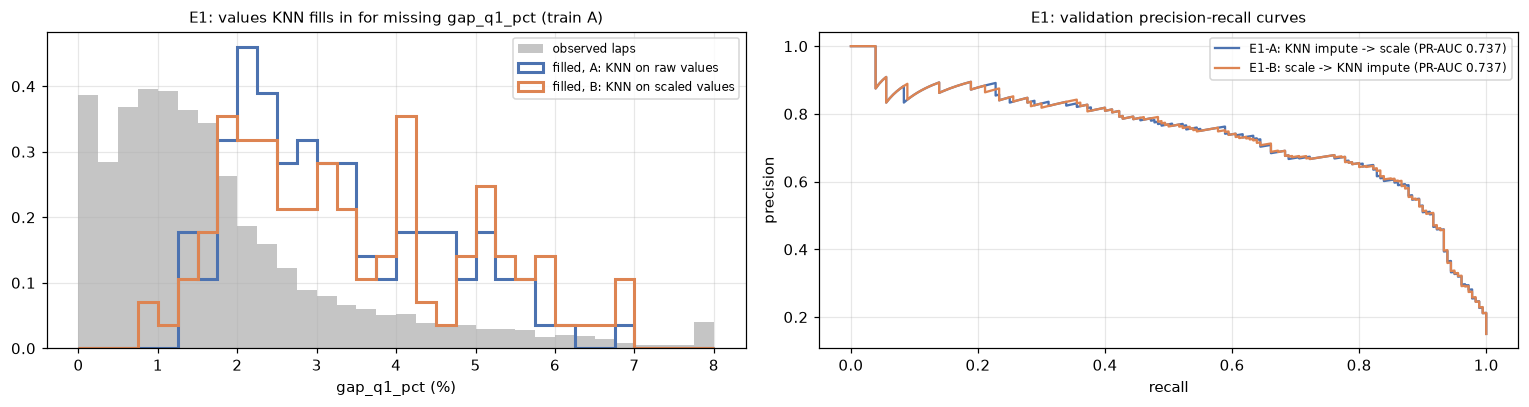

In [94]:
scale_step = lambda: ColumnTransformer([("continuous", StandardScaler(), CONTINUOUS_FEATURES)], remainder="passthrough",
                                       verbose_feature_names_out=False)
E1_A = Pipeline([("indicators_cap", F1Imputer(fill=False)), ("knn", KNNImputer(n_neighbors=5)), ("scale", scale_step())]).set_output(transform="pandas")
E1_B = Pipeline([("indicators_cap", F1Imputer(fill=False)), ("scale", scale_step()), ("knn", KNNImputer(n_neighbors=5))]).set_output(transform="pandas")
rA, E1_A = evaluate_preprocessing("E1-A: KNN impute -> scale", E1_A)
rB, E1_B = evaluate_preprocessing("E1-B: scale -> KNN impute", E1_B)
display(pd.DataFrame([rA, rB]))
print("PR-AUC difference (B - A):", pr_auc_difference("E1-A: KNN impute -> scale", "E1-B: scale -> KNN impute"))

# How different are the FILLED values? Compare both in original units (train A rows that had a gap).
raw = TRAIN_A_ROWS[FINAL_FEATURES]
filled_A = E1_A[:-1].transform(raw)                                        # before scaling = original units
sc_B = E1_B.named_steps["scale"].named_transformers_["continuous"]
filled_B = E1_B.transform(raw)
filled_B[CONTINUOUS_FEATURES] = sc_B.inverse_transform(filled_B[CONTINUOUS_FEATURES])
rows_e1 = []
for c in ["gap_q1_pct", "grid_minus_quali", "reached_q3"] + DRV_FORM + [CONS_FORM]:
    m = raw[c].isna().to_numpy()
    a, b = filled_A.loc[m, c].to_numpy(), filled_B.loc[m, c].to_numpy()
    rows_e1.append({"feature": c, "filled cells": int(m.sum()), "mean fill, A (raw scale)": round(a.mean(), 3),
                    "mean fill, B (scaled)": round(b.mean(), 3), "mean |A - B|": round(np.abs(a - b).mean(), 3),
                    "cells that differ": int((~np.isclose(a, b)).sum())})
display(pd.DataFrame(rows_e1))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
m = raw["gap_q1_pct"].isna().to_numpy()
bins = np.linspace(0, 8, 33)
axes[0].hist(raw["gap_q1_pct"].dropna().clip(upper=8), bins=bins, density=True, color="#8C8C8C", alpha=0.5, label="observed laps")
axes[0].hist(filled_A.loc[m, "gap_q1_pct"], bins=bins, density=True, histtype="step", lw=2, color="#4C72B0", label="filled, A: KNN on raw values")
axes[0].hist(filled_B.loc[m, "gap_q1_pct"], bins=bins, density=True, histtype="step", lw=2, color="#DD8452", label="filled, B: KNN on scaled values")
axes[0].set_xlabel("gap_q1_pct (%)")
axes[0].set_title("E1: values KNN fills in for missing gap_q1_pct (train A)", fontsize=10)
axes[0].legend(fontsize=8)
for name, color in [("E1-A: KNN impute -> scale", "#4C72B0"), ("E1-B: scale -> KNN impute", "#DD8452")]:
    p, r, _ = precision_recall_curve(y_val, EXP_PREDS[name])
    axes[1].plot(r, p, color=color, label=f"{name} (PR-AUC {average_precision_score(y_val, EXP_PREDS[name]):.3f})")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("E1: validation precision-recall curves", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### E2: capping before imputation vs imputation before capping

- **Hypothesis:** the cap is a percentile. If it is fitted **after** filling, the filled values take part in the percentile and pull it toward them. That matters most where many values are filled, i.e. **model B** (most old seasons have no qualifying record, filled with the median).
- **A (our pipeline):** fit the cap on the **observed** laps → fill → cap. **B:** fill → fit the cap on the **filled** column → cap.
- **Only the order changes.** Same fills, same scaling, same model; every value fitted on the training rows of the model concerned.
- **Run for both models.** A first check showed that for **model A** the two orders are almost identical (few values are filled, so the cap barely moves), while for **model B** they genuinely differ. So E2 is reported mainly on **model B** (trained on 1950–2018, scored on the same validation rows), with model A shown for comparison.

model,B,A
cap A (observed),9.015,7.856
cap B (filled),6.542,7.764
training rows whose gap changes,221,64
largest change (pct points),2.473,0.092
val PR-AUC A,0.7236,0.735
val PR-AUC B,0.7245,0.7348
val ROC-AUC A,0.9318,0.9365
val ROC-AUC B,0.932,0.9365
val F1 A,0.7146,0.7126
val F1 B,0.7146,0.7126


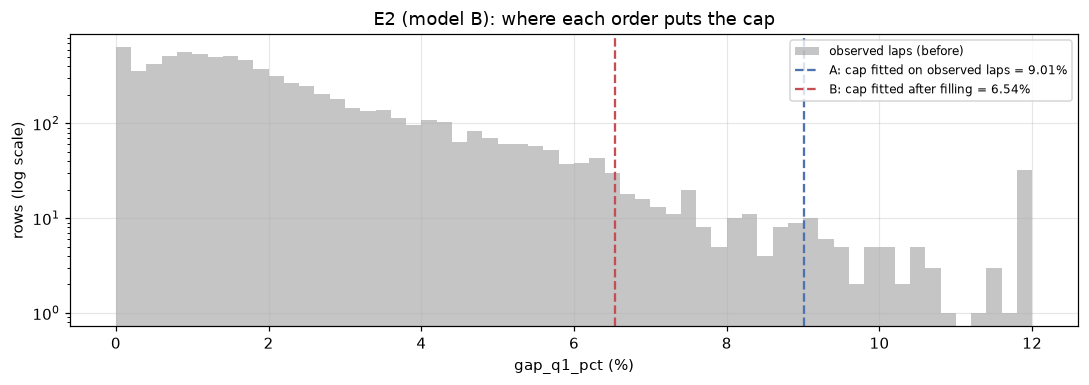

In [95]:
e2_rows = []
for model, rows in [("B", TRAIN_B_ROWS), ("A", TRAIN_A_ROWS)]:
    ra, pa = evaluate_preprocessing(f"E2-A ({model}): cap fitted on observed laps -> impute",
                                    make_preprocessor(scaled=True, cap_before_impute=True), train_rows=rows)
    rb, pb = evaluate_preprocessing(f"E2-B ({model}): impute -> cap fitted on filled column",
                                    make_preprocessor(scaled=True, cap_before_impute=False), train_rows=rows)
    cap_a, cap_b = pa.named_steps["impute"].gap_cap_, pb.named_steps["impute"].gap_cap_
    gap_a = pa.named_steps["impute"].transform(rows[FINAL_FEATURES])["gap_q1_pct"]
    gap_b = pb.named_steps["impute"].transform(rows[FINAL_FEATURES])["gap_q1_pct"]
    changed = ~np.isclose(gap_a, gap_b)
    e2_rows.append({"model": model, "cap A (observed)": round(cap_a, 3), "cap B (filled)": round(cap_b, 3),
                    "training rows whose gap changes": int(changed.sum()), "largest change (pct points)": round(float(np.abs(gap_a - gap_b).max()), 3),
                    "val PR-AUC A": ra["val PR-AUC"], "val PR-AUC B": rb["val PR-AUC"], "val ROC-AUC A": ra["val ROC-AUC"],
                    "val ROC-AUC B": rb["val ROC-AUC"], "val F1 A": ra["val F1"], "val F1 B": rb["val F1"],
                    "PR-AUC difference (B - A)": pr_auc_difference(ra["version"], rb["version"])})
    if model == "B":
        E2_PLOT = (rows, gap_a, gap_b, cap_a, cap_b)
display(pd.DataFrame(e2_rows).set_index("model").T)

rows, gap_a, gap_b, cap_a, cap_b = E2_PLOT
observed = rows["gap_q1_pct"].notna()
fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.linspace(0, 12, 61)
ax.hist(rows.loc[observed, "gap_q1_pct"].clip(upper=12), bins=bins, color="#8C8C8C", alpha=0.5, label="observed laps (before)")
ax.axvline(cap_a, color="#4C72B0", ls="--", label=f"A: cap fitted on observed laps = {cap_a:.2f}%")
ax.axvline(cap_b, color="#C44E52", ls="--", label=f"B: cap fitted after filling = {cap_b:.2f}%")
ax.set_yscale("log")
ax.set_xlabel("gap_q1_pct (%)")
ax.set_ylabel("rows (log scale)")
ax.set_title("E2 (model B): where each order puts the cap")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Supporting diagnostic: fit pre-processing before vs after the era filter

Relevant to the model A vs model B comparison. Model A's logistic regression is trained on 2003–2018 rows in both versions; only the rows used to **fit the pre-processing** change: 2003–2018 (A's own) vs 1950–2018 (B's). Old seasons have different typical values (e.g. many more retirements), so the medians and the scaler move.

In [96]:
ra, pa = evaluate_preprocessing("era: pre-processing fitted on 2003-2018", make_preprocessor(scaled=True), train_rows=TRAIN_A_ROWS)
rb, pb = evaluate_preprocessing("era: pre-processing fitted on 1950-2018", make_preprocessor(scaled=True),
                                train_rows=TRAIN_B_ROWS, model_rows=TRAIN_A_ROWS)
display(pd.DataFrame([ra, rb]))
print("PR-AUC difference:", pr_auc_difference(ra["version"], rb["version"]))
sa, sb = pa.named_steps["scale"].named_transformers_["continuous"], pb.named_steps["scale"].named_transformers_["continuous"]
display(pd.DataFrame({"scaler mean, fitted on 2003-2018": sa.mean_, "scaler mean, fitted on 1950-2018": sb.mean_},
                     index=CONTINUOUS_FEATURES).round(2).loc[["drv_dnf_rate_5", "drv_experience", "drv_champ_pos", "n_starters"]])

,version,val PR-AUC,val ROC-AUC,threshold (from train),val F1
0,era: pre-processing fitted on 2003-2018,0.735,0.9365,0.252,0.7126
1,era: pre-processing fitted on 1950-2018,0.735,0.9365,0.250,0.7109


PR-AUC difference: -0.0000 (95% interval -0.0007 to +0.0007)


,"scaler mean, fitted on 2003-2018","scaler mean, fitted on 1950-2018"
drv_dnf_rate_5,0.23,0.42
drv_experience,92.30,60.72
drv_champ_pos,12.01,15.11
n_starters,21.43,22.85


### Educational demonstration (INVALID, not used): fitting pre-processing on training + validation rows

This shows the leak that the pipeline design prevents. The medians, percentiles and scaler are fitted on **training + validation** rows (so the validation seasons influence how they themselves are transformed), while the model is still trained on training rows only. **This is wrong by design** and is not one of the two experiments.

In [97]:
ra, pa = evaluate_preprocessing("valid: pre-processing fitted on training rows", make_preprocessor(scaled=True))
rb, pb = evaluate_preprocessing("INVALID: pre-processing fitted on training + validation rows", make_preprocessor(scaled=True),
                                train_rows=pd.concat([TRAIN_A_ROWS, VAL_ROWS]), model_rows=TRAIN_A_ROWS, valid=False)
display(pd.DataFrame([ra, rb]))
moved = np.abs(EXP_PREDS[ra["version"]] - EXP_PREDS[rb["version"]])
print(f"PR-AUC difference: {pr_auc_difference(ra['version'], rb['version'])}; "
      f"largest change in a validation probability: {moved.max():.4f}")

,version,val PR-AUC,val ROC-AUC,threshold (from train),val F1
0,valid: pre-processing fitted on training rows,0.735,0.9365,0.252,0.7126
1,INVALID: pre-processing fitted on training + validation ...,0.735,0.9365,0.252,0.7126


PR-AUC difference: -0.0000 (95% interval -0.0005 to +0.0004); largest change in a validation probability: 0.0043


### Transformation check (not an order experiment)

Should any feature be transformed before scaling? Each version changes **one** thing in the final pipeline (5.7) and is compared with it on the same rows. This compares transformations, not orders, so it is not one of the two experiments; it is the evidence for the "no extra transformation" decision in 5.5.

In [98]:
from sklearn.preprocessing import FunctionTransformer, RobustScaler


def with_extra_step(fn=None, scaler=StandardScaler):
    steps = [("impute", F1Imputer())]
    if fn is not None:
        steps.append(("transform", FunctionTransformer(fn, feature_names_out="one-to-one")))
    steps.append(("scale", ColumnTransformer([("continuous", scaler(), CONTINUOUS_FEATURES)], remainder="passthrough",
                                             verbose_feature_names_out=False)))
    return Pipeline(steps).set_output(transform="pandas")


TRANSFORM_VERSIONS = {
    "final pipeline (no extra transformation)": with_extra_step(),
    "log(grid) instead of grid": with_extra_step(lambda X: X.assign(grid=np.log(X["grid"]))),
    "1/grid instead of grid": with_extra_step(lambda X: X.assign(grid=1 / X["grid"])),
    "log(1 + drv_experience)": with_extra_step(lambda X: X.assign(drv_experience=np.log1p(X["drv_experience"]))),
    "log(1 + gap_q1_pct)": with_extra_step(lambda X: X.assign(gap_q1_pct=np.log1p(X["gap_q1_pct"]))),
    "RobustScaler instead of StandardScaler": with_extra_step(scaler=RobustScaler),
}
transform_rows = []
for name, pipe in TRANSFORM_VERSIONS.items():
    res, _ = evaluate_preprocessing(f"transform check: {name}", pipe)
    res["PR-AUC difference vs final pipeline"] = ("-" if name.startswith("final") else
                                                  pr_auc_difference("transform check: final pipeline (no extra transformation)", res["version"]))
    transform_rows.append(res)
display(pd.DataFrame(transform_rows).set_index("version"))

,val PR-AUC,val ROC-AUC,threshold (from train),val F1,PR-AUC difference vs final pipeline
version,,,,,
transform check: final pipeline (no extra transformation),0.7350,0.9365,0.252,0.7126,-
transform check: log(grid) instead of grid,0.7350,0.9368,0.271,0.7237,+0.0000 (95% interval -0.0191 to +0.0212)
transform check: 1/grid instead of grid,0.7139,0.9296,0.279,0.7105,-0.0211 (95% interval -0.0436 to +0.0090)
transform check: log(1 + drv_experience),0.7286,0.9366,0.289,0.7188,-0.0064 (95% interval -0.0154 to +0.0025)
transform check: log(1 + gap_q1_pct),0.7336,0.9360,0.273,0.7119,-0.0015 (95% interval -0.0081 to +0.0061)
transform check: RobustScaler instead of StandardScaler,0.7345,0.9365,0.268,0.7115,-0.0005 (95% interval -0.0037 to +0.0015)


In [99]:
experiments_df = (pd.DataFrame(EXPERIMENTS).drop_duplicates("version").set_index("version")
                  .drop(columns="PR-AUC difference vs final pipeline", errors="ignore"))
print("All pre-processing comparisons in 5.6 (validation, logistic regression):")
display(experiments_df)

All pre-processing comparisons in 5.6 (validation, logistic regression):


,val PR-AUC,val ROC-AUC,threshold (from train),val F1
version,,,,
check: median impute -> scale,0.7331,0.9319,0.353,0.7172
check: scale -> median impute,0.7330,0.9319,0.269,0.7150
E1-A: KNN impute -> scale,0.7368,0.9364,0.331,0.7168
E1-B: scale -> KNN impute,0.7370,0.9364,0.333,0.7136
E2-A (B): cap fitted on observed laps -> impute,0.7236,0.9318,0.286,0.7146
E2-B (B): impute -> cap fitted on filled column,0.7245,0.9320,0.288,0.7146
E2-A (A): cap fitted on observed laps -> impute,0.7350,0.9365,0.252,0.7126
E2-B (A): impute -> cap fitted on filled column,0.7348,0.9365,0.253,0.7126
era: pre-processing fitted on 2003-2018,0.7350,0.9365,0.252,0.7126


**What the experiments show.**
- **E1 (KNN vs scaling order):** the order genuinely changes the **filled values**: unscaled, the "nearest" rows are chosen mainly by experience and championship position, so the filled gaps and form values differ (table above). But the validation scores of the two versions are within noise of each other: the 95% interval of the difference includes 0. **The order matters for the data, not measurably for this model's quality.** Scaling first is still the principled choice for any distance-based method.
- **E2 (cap vs imputation order):** for **model B** the order changes the cap a lot (table above), because the many median-filled rows pull the 99th percentile down, so the "filled first" version also cuts down hundreds of real laps that the other version keeps. For model A the two orders are nearly identical. The validation scores differ by less than the noise in both models (the interval of the difference includes 0), so the score doesn't decide. We keep the **cap fitted on observed laps** for a reason of principle: the cap should describe real laps, and it shouldn't depend on how many rows happen to have no qualifying data.
- **Era diagnostic:** fitting model A's pre-processing on all seasons moves the medians and scaler (e.g. retirement rates were much higher in old seasons) but changes the score only within noise. Each model keeps its own fit.
- **Invalid demonstration:** fitting on training + validation changes individual validation probabilities but barely the PR-AUC here, because medians and means are stable with thousands of training rows. It is still a leak, which is why every fit in this notebook goes through `fit_on_training`.
- **Transformation check:** no transformation beats the final pipeline beyond noise (every interval includes 0); `log(grid)` ties it, and `1/grid` and `log(1 + drv_experience)` score lower. So no extra transformation is added.
- **Overall:** none of these choices improves validation performance beyond noise. The final pipeline is chosen for **correctness** (no leakage, filled values that mean something, a cap that can't be distorted), not for a score gain.

## 5.7 Final pre-processing pipelines

Four fitted pipelines, used by the next sections:

| | logistic regression / neural network (scaled) | tree models (not scaled) |
|---|---|---|
| **model A** | fitted on 2003–2018 | fitted on 2003–2018 |
| **model B** | fitted on 1950–2018 | fitted on 1950–2018 |

Each takes the **18 features** (raw, with missing values) and returns **21 inputs**. To use one: `PREPROCESSORS[("A", "scaled")].transform(rows[FINAL_FEATURES])`.

In [100]:
PREPROCESSORS = {
    ("A", "scaled"): fit_on_training(make_preprocessor(scaled=True), TRAIN_A_ROWS, "final: model A, scaled"),
    ("A", "tree"): fit_on_training(make_preprocessor(scaled=False), TRAIN_A_ROWS, "final: model A, tree"),
    ("B", "scaled"): fit_on_training(make_preprocessor(scaled=True), TRAIN_B_ROWS, "final: model B, scaled"),
    ("B", "tree"): fit_on_training(make_preprocessor(scaled=False), TRAIN_B_ROWS, "final: model B, tree"),
}
MODEL_INPUTS = {kind: list(PREPROCESSORS[("A", kind)].get_feature_names_out()) for kind in ["scaled", "tree"]}
shapes = []
for (model, kind), pre in PREPROCESSORS.items():
    train_rows = TRAIN_A_ROWS if model == "A" else TRAIN_B_ROWS
    for set_name, rows in [("train", train_rows), ("validation", VAL_ROWS)]:
        out = pre.transform(rows[FINAL_FEATURES])
        shapes.append({"model": model, "pipeline": kind, "rows": set_name, "shape": out.shape,
                       "missing values": int(out.isna().sum().sum())})
display(pd.DataFrame(shapes))
print("Scaled pipeline inputs (21):", MODEL_INPUTS["scaled"])
print("Tree pipeline inputs (21):  ", MODEL_INPUTS["tree"])

,model,pipeline,rows,shape,missing values
0,A,scaled,train,"(6381, 21)",0
1,A,scaled,validation,"(1199, 21)",0
2,A,tree,train,"(6381, 21)",0
3,A,tree,validation,"(1199, 21)",0
4,B,scaled,train,"(22092, 21)",0
5,B,scaled,validation,"(1199, 21)",0
6,B,tree,train,"(22092, 21)",0
7,B,tree,validation,"(1199, 21)",0


Scaled pipeline inputs (21): ['grid', 'gap_q1_pct', 'grid_minus_quali', 'drv_champ_pos', 'cons_points_share', 'drv_podium_rate_5', 'drv_avg_finish_5', 'drv_dnf_rate_5', 'cons_podium_rate_5', 'n_starters', 'drv_experience', 'drv_age', 'pit_lane_start', 'reached_q3', 'no_q3_format', 'quali_missing', 'drv_no_standing_yet', 'cons_no_standing_yet', 'q1_time_missing', 'drv_form_missing', 'cons_form_missing']
Tree pipeline inputs (21):   ['grid', 'pit_lane_start', 'gap_q1_pct', 'grid_minus_quali', 'reached_q3', 'no_q3_format', 'quali_missing', 'drv_champ_pos', 'cons_points_share', 'drv_no_standing_yet', 'cons_no_standing_yet', 'drv_podium_rate_5', 'drv_avg_finish_5', 'drv_dnf_rate_5', 'cons_podium_rate_5', 'n_starters', 'drv_experience', 'drv_age', 'q1_time_missing', 'drv_form_missing', 'cons_form_missing']


## 5.8 Leakage and behaviour checks

Automated checks of the pipelines from 5.7:
1. no missing value in any output;
2. inputs are exactly the 18 features: no target, no identifier;
3. every learned value equals the same value **recomputed by hand from the training rows only**, and every fit in this section used training rows only;
4. partially missing records (a new driver, no qualifying data, no Q1 time, a missing grid) are filled as designed;
5. feature names and dimensions are the same across models;
6. `final_features_df` is unchanged.

In [101]:
checks = []

# 1. No missing values in any output.
for (model, kind), pre in PREPROCESSORS.items():
    for rows in [TRAIN_A_ROWS if model == "A" else TRAIN_B_ROWS, VAL_ROWS]:
        assert not pre.transform(rows[FINAL_FEATURES]).isna().any().any()
checks.append("no missing values in any pipeline output (train and validation, models A and B)")

# 2. Inputs are the 18 features; no target or identifier enters or leaves the pipeline.
for pre in PREPROCESSORS.values():
    assert list(pre.feature_names_in_) == FINAL_FEATURES
    assert not set(pre.get_feature_names_out()) & set(NOT_INPUTS)
checks.append("pipelines take exactly the 18 features; podium, raceId, driverId, year and split never enter")

# 3. Learned values = hand recomputation from training rows only.
for model, rows in [("A", TRAIN_A_ROWS), ("B", TRAIN_B_ROWS)]:
    pre = PREPROCESSORS[(model, "scaled")]
    imp = pre.named_steps["impute"]
    obs = rows["gap_q1_pct"].dropna()
    assert np.isclose(imp.gap_cap_, obs.quantile(0.99)) and np.isclose(imp.gap_slow_, obs.quantile(0.95))
    assert np.isclose(imp.gap_neutral_, obs.median())
    assert np.allclose(imp.medians_, rows[CONTINUOUS_FEATURES].median())
    filled = imp.transform(rows[FINAL_FEATURES])[CONTINUOUS_FEATURES]
    scaler = pre.named_steps["scale"].named_transformers_["continuous"]
    assert np.allclose(scaler.mean_, filled.mean()) and np.allclose(scaler.scale_, filled.std(ddof=0))
fit_log = pd.DataFrame(FIT_LOG)
assert (fit_log["splits"] == "train").all() and (fit_log["seasons"].str[-4:].astype(int) <= SPLIT_YEARS["train"][1]).all()
checks.append(f"all learned values match a recomputation from training rows; all {len(fit_log)} fits in section 5 used training rows only")

# 4. Partially missing records.
pre, imp = PREPROCESSORS[("A", "tree")], PREPROCESSORS[("A", "tree")].named_steps["impute"]
base = VAL_ROWS[FINAL_FEATURES].iloc[[0]].copy()
cases = {"complete record": base.copy(),
         "qualifying record, no Q1 time": base.assign(gap_q1_pct=np.nan),
         "no qualifying data": base.assign(gap_q1_pct=np.nan, grid_minus_quali=np.nan, reached_q3=np.nan, quali_missing=1.0),
         "debut driver, new team": base.assign(**{c: np.nan for c in DRV_FORM + [CONS_FORM]}),
         "grid and quali_missing flag missing": base.assign(grid=np.nan, quali_missing=np.nan)}
partial = pd.concat({k: pre.transform(v) for k, v in cases.items()}).droplevel(1)
assert not partial.isna().any().any()
assert partial.loc["qualifying record, no Q1 time", "gap_q1_pct"] == imp.gap_slow_ and partial.loc["qualifying record, no Q1 time", "q1_time_missing"] == 1
r = partial.loc["no qualifying data"]
assert r["gap_q1_pct"] == imp.gap_neutral_ and r["grid_minus_quali"] == 0 and r["reached_q3"] == 0 and r["q1_time_missing"] == 0 and r["quali_missing"] == 1
r = partial.loc["debut driver, new team"]
assert r["drv_form_missing"] == 1 and r["cons_form_missing"] == 1 and np.allclose(r[DRV_FORM + [CONS_FORM]], imp.medians_[DRV_FORM + [CONS_FORM]])
r = partial.loc["grid and quali_missing flag missing"]
assert r["grid"] == imp.medians_["grid"] and r["quali_missing"] == 0
display(partial[["grid", "gap_q1_pct", "grid_minus_quali", "reached_q3", "quali_missing"] + DRV_FORM[:1] + [CONS_FORM] + INDICATORS])
checks.append("partially missing records are filled as designed (5 cases)")

# 5. Names and dimensions.
for kind in ["scaled", "tree"]:
    assert list(PREPROCESSORS[("B", kind)].get_feature_names_out()) == MODEL_INPUTS[kind] and len(MODEL_INPUTS[kind]) == 21
assert set(MODEL_INPUTS["scaled"]) == set(MODEL_INPUTS["tree"]) == set(FINAL_FEATURES + INDICATORS)
checks.append("models A and B produce the same 21 named inputs")

# 6. The exported feature table is unchanged.
assert hashlib.sha256(final_features_df.to_csv(index=False).encode()).hexdigest() == FF_SHA_BEFORE
checks.append("in-memory feature table is unchanged by section 5")

display(fit_log)
for c in checks:
    print("PASS", c)

,grid,gap_q1_pct,grid_minus_quali,reached_q3,quali_missing,drv_podium_rate_5,cons_podium_rate_5,q1_time_missing,drv_form_missing,cons_form_missing
complete record,1.0,0.031701,0.0,1.0,0.0,0.8,0.5,0.0,0.0,0.0
"qualifying record, no Q1 time",1.0,5.185485,0.0,1.0,0.0,0.8,0.5,1.0,0.0,0.0
no qualifying data,1.0,1.358560,0.0,0.0,1.0,0.8,0.5,0.0,0.0,0.0
"debut driver, new team",1.0,0.031701,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
grid and quali_missing flag missing,11.0,0.031701,0.0,1.0,0.0,0.8,0.5,0.0,0.0,0.0


,fit,rows,splits,seasons
0,"F1Imputer, model A",6381,train,2003-2018
1,"F1Imputer, model B",22092,train,1950-2018
2,"scaled pipeline, model A",6381,train,2003-2018
3,check: median impute -> scale,6381,train,2003-2018
4,check: scale -> median impute,6381,train,2003-2018
5,E1-A: KNN impute -> scale,6381,train,2003-2018
6,E1-B: scale -> KNN impute,6381,train,2003-2018
7,E2-A (B): cap fitted on observed laps -> impute,22092,train,1950-2018
8,E2-B (B): impute -> cap fitted on filled column,22092,train,1950-2018
9,E2-A (A): cap fitted on observed laps -> impute,6381,train,2003-2018


PASS no missing values in any pipeline output (train and validation, models A and B)
PASS pipelines take exactly the 18 features; podium, raceId, driverId, year and split never enter
PASS all learned values match a recomputation from training rows; all 24 fits in section 5 used training rows only
PASS partially missing records are filled as designed (5 cases)
PASS models A and B produce the same 21 named inputs
PASS in-memory feature table is unchanged by section 5


**Summary of section 5.**
- **Inputs:** the 18 features from `final_features_df` (unchanged) → **21 model inputs** (18 features + `q1_time_missing`, `drv_form_missing`, `cons_form_missing`).
- **Missing values:** a missing Q1 time with a qualifying record → a slow lap (training 95th percentile); no qualifying record → the training median, with `quali_missing` kept; `grid_minus_quali` and `reached_q3` → 0 (their flags explain why); form → training medians plus the indicators.
- **Outliers:** only `gap_q1_pct` is capped (training 99th percentile, fitted on observed laps); every row is kept.
- **Scaling:** continuous features standardised for logistic regression and the neural network; flags stay 0/1; tree models get the unscaled version.
- **Model A and model B** fit everything on their own training seasons; validation and test are only transformed.
- **Experiments:** E1 and E2 change the transformed data but not validation performance beyond noise; the pipeline is chosen for correctness, not for a score gain.

# 6. Predictive Modeling

**Goal:** train and compare four model families on the pre-processed inputs, choose each one's settings without looking at the validation seasons, check them once on 2019–2021, and **freeze** everything before the test seasons are ever used.

| | Model | Inputs |
|---|---|---|
| reference | rule "podium if grid ≤ 3"; logistic regression on `grid` only | grid |
| 1 | logistic regression | 21 scaled inputs |
| 2 | random forest | 21 unscaled inputs |
| 3 | gradient boosting (`HistGradientBoostingClassifier`) | 21 unscaled inputs |
| 4 | shallow neural network (PyTorch, 1–2 hidden layers) | 21 scaled inputs |

How the section works:
1. **6.2 Time-ordered cross-validation** inside the training seasons: four folds, each trained only on seasons **before** the two seasons it scores. All settings are chosen here.
2. **6.3–6.7** baselines and the four families, each with a small fixed grid of settings.
3. **6.8 Thresholds** from the out-of-fold predictions, frozen before validation is scored.
4. **6.9** one validation score per final model, with race-resampling intervals; overfitting and probability quality.
5. **6.10** model A (trained on 2003–2018) vs model B (1950–2018), plus training-window experiments.
6. **6.11 Freeze.** The test seasons (2022–2024) are **not** used anywhere in this section.

## 6.1 Set-up: rows, metrics and guards

- **Rows:** the training rows of model A (2003–2018) or model B (1950–2018) and the 1,199 validation rows, from section 5. Every table used here is checked to contain **no test row**.
- **Every fit goes through one guard** (`fit6`), which refuses rows that aren't training rows, and, inside a cross-validation fold, rows from the seasons the fold scores or later. Every fit and every prediction is logged.
- **Primary metric: PR-AUC.** It measures how well the real podium finishers are ranked above everyone else, over all thresholds. It is the right headline for this task because podiums are **rare** (about 15% of rows, 3 per race) and the official output is a **ranking** (the three most likely drivers per race, 7.10). A random guess scores the podium rate (≈ 0.15), so the scale has a clear floor. Every model choice (settings, primary model) uses PR-AUC from cross-validation.
- **Secondary metrics** (reported for every model, never used to pick settings):
  - **ROC-AUC:** chance a podium row is ranked above a non-podium row. It looks high (≈ 0.93) even for simple models, because most non-podium rows are easy.
  - **Binary F1, precision, recall** at the frozen threshold: precision = of the predicted podiums, the share that were real; recall = of the real podiums, the share we found; F1 = their balance.
  - **Accuracy** at the same threshold: the share of all rows classified correctly.
  - **Race-level top-3 F1:** F1 of the official output (exactly three picks per race), 6.8 and 7.10.
  - **Brier score:** the average squared error of the probabilities (lower is better), for calibration.
- **Why accuracy is misleading here:** about 85% of rows are "no podium", so a model that **never** predicts a podium is already about 85% accurate while finding none of the podium finishers (precision, recall and F1 = 0). Accuracy is dominated by the easy majority class, so two models with very different podium-finding ability can have almost the same accuracy. It is reported for completeness, next to a reference row "always 'no podium'" in the validation and test tables, but no decision uses it.
- **Comparing two models:** the PR-AUC difference on validation, with a 95% interval from resampling the 60 validation races 500 times (the same resamples for both models, i.e. paired). A difference only counts if the interval **excludes 0**.

In [102]:
import copy, json, platform, time
import torch
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, brier_score_loss, confusion_matrix, precision_score, recall_score, roc_curve
from sklearn.preprocessing import FunctionTransformer

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)          # small networks: one thread is fast enough and keeps results exactly reproducible
print(f"python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {__import__('sklearn').__version__} | torch {torch.__version__}")

TRAIN_ROWS = {"A": TRAIN_A_ROWS, "B": TRAIN_B_ROWS}
for name, rows in [("train A", TRAIN_A_ROWS), ("train B", TRAIN_B_ROWS), ("validation", VAL_ROWS)]:
    assert "test" not in set(rows["split"]), f"{name} contains test rows"
print({name: f"{len(r):,} rows, {r['raceId'].nunique()} races, podium rate {r['podium'].mean():.3f}"
       for name, r in [("train A", TRAIN_A_ROWS), ("train B", TRAIN_B_ROWS), ("validation", VAL_ROWS)]})

FIT6_LOG, PREDICT6_LOG = [], []


def fit6(estimator, rows, label, before=None, X=None, log=None):
    """Fit on training rows only; inside a fold, only on seasons before `before`. X: already-transformed inputs.
    log: where to record the fit (a worker process records into its own list, merged into FIT6_LOG afterwards)."""
    assert set(rows["split"]) == {"train"}, f"{label}: non-training rows"
    if before is not None:
        assert rows["year"].max() < before, f"{label}: uses seasons from {before} or later"
    (FIT6_LOG if log is None else log).append({"fit": label, "rows": len(rows), "seasons": f"{rows['year'].min()}-{rows['year'].max()}",
                                               "must end before": before})
    return estimator.fit(rows[FINAL_FEATURES] if X is None else X, rows["podium"])


def log_predict(rows, label, log=None):
    assert "test" not in set(rows["split"]), f"{label}: prediction on test rows"
    (PREDICT6_LOG if log is None else log).append({"predict": label, "rows": len(rows), "splits": ",".join(sorted(set(rows["split"])))})


def top3_per_race(p, race):
    """1 for the 3 highest probabilities in each race (ties broken by row order), else 0."""
    order = pd.DataFrame({"p": p, "race": race}).reset_index(drop=True)
    rank = order.groupby("race")["p"].rank(method="first", ascending=False)
    return (rank <= 3).astype(int).to_numpy()


def scores(y, p, threshold=None, race=None):
    out = {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p)}
    if threshold is not None:
        pred = (p >= threshold).astype(int)
        out.update({"precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                    "F1": f1_score(y, pred), "accuracy": accuracy_score(y, pred), "predicted podiums": int(pred.sum())})
    if race is not None:
        out["F1 top-3 per race"] = f1_score(y, top3_per_race(p, race))
    return out


def paired_difference(p_base, p_new, y=None, boot=None):
    """PR-AUC(new) - PR-AUC(base) on validation, with a 95% paired race-resampling interval."""
    y = y_val if y is None else y
    boot = VAL_BOOT if boot is None else boot
    d = [average_precision_score(y[i], p_new[i]) - average_precision_score(y[i], p_base[i]) for i in boot]
    lo, hi = np.percentile(d, [2.5, 97.5])
    return average_precision_score(y, p_new) - average_precision_score(y, p_base), lo, hi

python 3.14.0 | numpy 2.4.1 | pandas 2.3.3 | scikit-learn 1.8.0 | torch 2.10.0+cpu
{'train A': '6,381 rows, 300 races, podium rate 0.141', 'train B': '22,092 rows, 986 races, podium rate 0.134', 'validation': '1,199 rows, 60 races, podium rate 0.150'}


## 6.2 Time-ordered cross-validation inside the training seasons

Settings are chosen with **forward-chaining** folds: each fold trains on all training seasons **before** a two-season block and scores that block. No fold ever uses a later season to predict an earlier one, and a season (so every race in it) is always entirely on one side.

- The scoring blocks are **2011–12, 2013–14, 2015–16, 2017–18**, the same for model A (fold training starts in 2003) and model B (starts in 1950).
- **Pre-processing is re-fitted inside every fold**, on that fold's training seasons only. The pipelines fitted in 5.7 used all of 2003–2018, so reusing them here would leak the scored seasons into their own pre-processing.
- **Why not tune on 2019–2021?** It has only 60 races. The four blocks add up to 158 races of past seasons, so settings are chosen on more evidence, and the validation seasons stay an honest check that is used **once** per final model.

,model,fold,trains on,training rows,scores,scoring rows,scoring races,scoring podiums
0,A,1,2003-2010,2975,2011-2012,930,39,117
1,A,2,2003-2012,3905,2013-2014,823,38,114
2,A,3,2003-2014,4728,2015-2016,834,40,120
3,A,4,2003-2016,5562,2017-2018,819,41,123
4,B,1,1950-2010,18686,2011-2012,930,39,117
5,B,2,1950-2012,19616,2013-2014,823,38,114
6,B,3,1950-2014,20439,2015-2016,834,40,120
7,B,4,1950-2016,21273,2017-2018,819,41,123


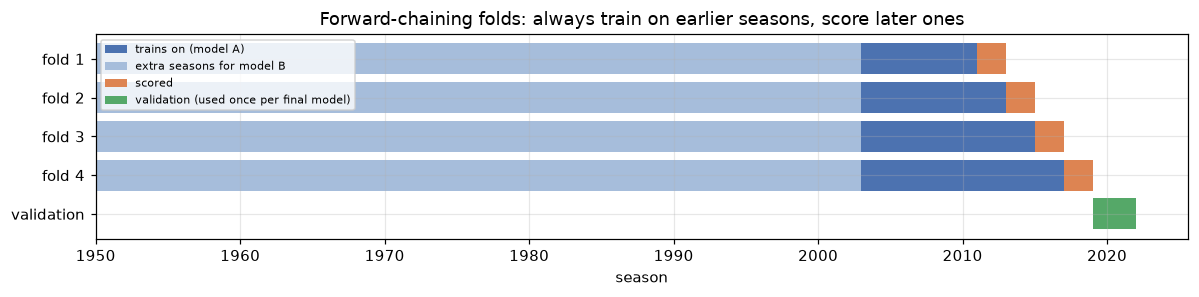

Every fold trains only on earlier seasons; no race is split; models A and B score identical rows.


In [103]:
FOLDS = [(2011, 2012), (2013, 2014), (2015, 2016), (2017, 2018)]


def fold_rows(model, k):
    lo, hi = FOLDS[k]
    rows = TRAIN_ROWS[model]
    return rows[rows["year"] < lo], rows[rows["year"].between(lo, hi)]


fold_table = []
for model in ["A", "B"]:
    for k, (lo, hi) in enumerate(FOLDS):
        tr, sc = fold_rows(model, k)
        assert tr["year"].max() < sc["year"].min(), "a fold trains on a later season"
        assert not set(tr["raceId"]) & set(sc["raceId"]), "a race is split across fold training and scoring"
        fold_table.append({"model": model, "fold": k + 1, "trains on": f"{tr['year'].min()}-{tr['year'].max()}",
                           "training rows": len(tr), "scores": f"{lo}-{hi}", "scoring rows": len(sc),
                           "scoring races": sc["raceId"].nunique(), "scoring podiums": int(sc["podium"].sum())})
fold_table = pd.DataFrame(fold_table)
for k in range(len(FOLDS)):   # both models score exactly the same rows
    a, b = fold_rows("A", k)[1], fold_rows("B", k)[1]
    assert a[["raceId", "driverId"]].reset_index(drop=True).equals(b[["raceId", "driverId"]].reset_index(drop=True))
display(fold_table)

fig, ax = plt.subplots(figsize=(11, 2.8))
for k, (lo, hi) in enumerate(FOLDS):
    ax.barh(k, lo - 2003, left=2003, color="#4C72B0", label="trains on (model A)" if k == 0 else None)
    ax.barh(k, 2003 - 1950, left=1950, color="#A6BDDB", label="extra seasons for model B" if k == 0 else None)
    ax.barh(k, hi - lo + 1, left=lo, color="#DD8452", label="scored" if k == 0 else None)
ax.barh(len(FOLDS), 3, left=2019, color="#55A868", label="validation (used once per final model)")
ax.set_yticks(range(len(FOLDS) + 1), [f"fold {k + 1}" for k in range(len(FOLDS))] + ["validation"])
ax.set_xlabel("season")
ax.set_title("Forward-chaining folds: always train on earlier seasons, score later ones")
ax.legend(fontsize=7, loc="upper left")
ax.invert_yaxis()
plt.tight_layout()
plt.show()
print("Every fold trains only on earlier seasons; no race is split; models A and B score identical rows.")

**Common rules for every model family (fixed before any result is seen):**
- **Score per setting:** the PR-AUC on each fold's scoring block; the **mean over the 4 folds** is the selection score.
- **Tie-breaking (paired one-standard-error rule):** take the setting with the best mean. For every other setting, compute its **shortfall on each fold** (best setting's fold score minus its own) and the standard error of those 4 shortfalls (their standard deviation ÷ √4). A setting is a **tie** if its mean shortfall is at most that standard error, i.e. it is not clearly worse than the best; and any setting whose mean is at least as high as a tie's is a tie too (a better-scoring setting can never be excluded while a worse one is kept). The comparison is **paired** because every setting is scored on exactly the same folds: some seasons are simply harder for every model, and that shared difficulty must not count as uncertainty (the same logic as the paired race resampling used on validation). Among the ties, choose the **simplest / most regularised** one, by a fixed order per family:
  - logistic regression: smaller `C` (stronger penalty), then no class weighting;
  - random forest: shallower trees (`max_depth` 6 < 10 < unlimited), then bigger leaves, then fewer features per split (`sqrt` before 0.5);
  - gradient boosting: fewer leaves per tree, then fewer trees, then bigger leaves, then smaller learning rate;
  - neural network: fewer weights, then stronger weight decay, then more dropout.
- **Out-of-fold predictions:** the chosen setting's predictions on the four scoring blocks (2011–2018), each made by a model that never saw those seasons. They are used for the threshold in 6.8.
- **Final model:** the chosen setting refitted on **all** training seasons, using the pre-processing fitted in 5.7.

In [104]:
GRIDS = {
    "logistic regression": [{"C": c, "class_weight": w} for c in [0.01, 0.1, 1, 10] for w in [None, "balanced"]],
    "random forest": [{"max_depth": d, "min_samples_leaf": l, "max_features": f}
                      for d in [6, 10, None] for l in [5, 20, 50] for f in ["sqrt", 0.5]],
    "gradient boosting": [{"learning_rate": r, "max_leaf_nodes": n, "min_samples_leaf": l, "max_iter": it}
                          for r in [0.05, 0.1] for n in [7, 15] for l in [20, 80] for it in [100, 300]],
    "neural network": [{"hidden": h, "dropout": d, "weight_decay": w}
                       for h in [(16,), (32,), (32, 16)] for d in [0.0, 0.2] for w in [1e-4, 1e-3]],
}
SCALED = {"logistic regression": True, "random forest": False, "gradient boosting": False, "neural network": True}


def make_estimator(family, params, seed=SEED):
    if family == "logistic regression":
        return LogisticRegression(max_iter=5000, **params)
    if family == "random forest":
        return RandomForestClassifier(n_estimators=500, n_jobs=1, random_state=seed, **params)   # 1 job: bit-for-bit reproducible
    if family == "gradient boosting":
        return HistGradientBoostingClassifier(l2_regularization=1.0, early_stopping=False, random_state=seed, **params)
    return ShallowNet(**params, seed=seed)


def n_weights(hidden, n_in=21):
    sizes = [n_in, *hidden, 1]
    return sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))


SIMPLICITY = {   # smaller tuple = simpler / more regularised
    "logistic regression": lambda p: (p["C"], p["class_weight"] is not None),
    "random forest": lambda p: ({6: 0, 10: 1, None: 2}[p["max_depth"]], -p["min_samples_leaf"], 0 if p["max_features"] == "sqrt" else 1),
    "gradient boosting": lambda p: (p["max_leaf_nodes"], p["max_iter"], -p["min_samples_leaf"], p["learning_rate"]),
    "neural network": lambda p: (n_weights(p["hidden"]), -p["weight_decay"], -p["dropout"]),
}
print({family: len(grid) for family, grid in GRIDS.items()}, "settings per family")

{'logistic regression': 8, 'random forest': 18, 'gradient boosting': 16, 'neural network': 12} settings per family


## 6.3 Reference baselines

- **Rule "podium if grid ≤ 3":** no learning at all. It shows what simply trusting the front row gives.
- **Logistic regression on `grid` only:** the **primary baseline**. The question every other model must answer is: *does anything beyond the starting position help?*

Both are scored on the same folds as the models, then once on validation.

In [105]:
grid_only = lambda: Pipeline([("pre", make_preprocessor(scaled=True)),
                              ("grid", FunctionTransformer(lambda X: X[["grid"]], feature_names_out=lambda t, f: np.array(["grid"]))),
                              ("model", LogisticRegression(max_iter=5000))])
baseline_rows, BASELINE_OOF = [], []
for k in range(len(FOLDS)):
    tr, sc = fold_rows("A", k)
    log_predict(sc, f"baseline fold {k + 1}")
    rule = (sc["grid"] <= 3).astype(int)
    pipe = fit6(grid_only(), tr, f"grid-only LR, fold {k + 1}", before=FOLDS[k][0])
    p = pipe.predict_proba(sc[FINAL_FEATURES])[:, 1]
    BASELINE_OOF.append(p)
    baseline_rows.append({"fold": k + 1, "rule grid<=3: precision": precision_score(sc["podium"], rule),
                          "rule grid<=3: recall": recall_score(sc["podium"], rule), "rule grid<=3: F1": f1_score(sc["podium"], rule),
                          "grid-only LR: PR-AUC": average_precision_score(sc["podium"], p), "grid-only LR: ROC-AUC": roc_auc_score(sc["podium"], p)})
BASELINE_OOF = np.concatenate(BASELINE_OOF)
baseline_cv = pd.DataFrame(baseline_rows).set_index("fold")
baseline_cv.loc["mean"] = baseline_cv.mean()
display(baseline_cv.round(4))

,rule grid<=3: precision,rule grid<=3: recall,rule grid<=3: F1,grid-only LR: PR-AUC,grid-only LR: ROC-AUC
fold,,,,,
1,0.5726,0.5726,0.5726,0.5903,0.9025
2,0.6053,0.6053,0.6053,0.5913,0.8973
3,0.7250,0.7250,0.7250,0.7287,0.9434
4,0.7049,0.6992,0.7020,0.6747,0.9262
mean,0.6520,0.6505,0.6512,0.6462,0.9173


### The search procedure (shared by 6.4–6.7)

For each setting and each fold: fit pre-processing + model on the fold's training seasons, predict its scoring block, record the PR-AUC. The neural network adds an inner step (6.7). Every setting's four fold scores are kept in `SEARCH`.

The (setting, fold) jobs are independent and each has a fixed seed, so they run in **parallel processes** (`joblib`) to keep the notebook's run time reasonable; the results are identical to running them one after another. The training-rows guard and the logging run inside every job.

In [106]:
SEARCH, OOF, CHOSEN = {}, {}, {}
FOLD_COLS = [f"fold {k + 1}" for k in range(len(FOLDS))]


def paired_ties(fold_scores, best):
    """Rows not clearly worse than row `best`: mean per-fold shortfall at most one standard error of those paired
    differences. Then every row scoring at least as high (on average) as one of those also counts, so a better-scoring
    row can never be excluded while a worse one is kept."""
    shortfall = fold_scores.rsub(fold_scores.loc[best], axis=1)          # best minus each, fold by fold
    se = shortfall.std(axis=1, ddof=1) / np.sqrt(fold_scores.shape[1])
    within = shortfall.mean(axis=1) <= se
    mean = fold_scores.mean(axis=1)
    return list(fold_scores.index[mean >= mean[within].min()])


def cv_predict(model, family, params, k, seed=SEED, logs=(None, None)):
    """Fit on fold k's training seasons and predict its scoring block. Returns (probabilities, extra info)."""
    tr, sc = fold_rows(model, k)
    lo = FOLDS[k][0]
    log_predict(sc, f"{model} {family} fold {k + 1}", log=logs[1])
    if family != "neural network":
        pipe = Pipeline([("pre", make_preprocessor(scaled=SCALED[family])), ("model", make_estimator(family, params, seed))])
        fit6(pipe, tr, f"{model} {family} fold {k + 1}", before=lo, log=logs[0])
        return pipe.predict_proba(sc[FINAL_FEATURES])[:, 1], {}
    return nn_fold(model, params, k, seed, logs)


def cv_task(model, family, params, k, seed):
    """One (setting, fold) job; runs in a separate process. Returns its predictions and its own fit/predict log."""
    torch.use_deterministic_algorithms(True)
    torch.set_num_threads(1)
    logs = ([], [])
    p, info = cv_predict(model, family, params, k, seed, logs)
    return p, info, logs


# Settings x folds are independent jobs with fixed seeds, so they run in parallel processes; the results are identical to
# running them one by one. Every guard (fit6, log_predict) still runs inside each job.
from joblib import Parallel, delayed
import os
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))


def run_jobs(jobs):
    out = Parallel(n_jobs=N_JOBS)(delayed(cv_task)(*job) for job in jobs)
    for _, _, (fit_log, pred_log) in out:   # merge the workers' logs, in job order
        FIT6_LOG.extend(fit_log)
        PREDICT6_LOG.extend(pred_log)
    return [(p, info) for p, info, _ in out]


def run_search(model, family):
    rows = []
    jobs = [(model, family, params, k, SEED) for params in GRIDS[family] for k in range(len(FOLDS))]
    results = iter(run_jobs(jobs))
    for i, params in enumerate(GRIDS[family]):
        fold_scores, preds, extra = [], [], []
        for k in range(len(FOLDS)):
            p, info = next(results)
            sc = fold_rows(model, k)[1]
            fold_scores.append(average_precision_score(sc["podium"], p))
            preds.append(p)
            extra.append(info)
        row = {"setting": i, **{k: str(v) for k, v in params.items()},
               **{f"fold {k + 1}": s for k, s in enumerate(fold_scores)},
               "mean PR-AUC": np.mean(fold_scores), "fold SD": np.std(fold_scores, ddof=1)}
        if family == "neural network":
            row["best epochs (inner)"] = [e["best_epoch"] for e in extra]
        rows.append(row)
        OOF[(model, family, i)] = np.concatenate(preds)
        if family == "neural network":
            OOF[(model, family, i, "info")] = extra
    table = pd.DataFrame(rows)
    SEARCH[(model, family)] = table
    # Paired one-standard-error rule, then the simplest setting.
    best = table["mean PR-AUC"].idxmax()
    ties = paired_ties(table[FOLD_COLS], best)
    chosen = min(ties, key=lambda i: SIMPLICITY[family](GRIDS[family][i]))
    CHOSEN[(model, family)] = {"setting": int(chosen), "params": GRIDS[family][chosen],
                               "cv mean PR-AUC": table.loc[chosen, "mean PR-AUC"], "cv fold SD": table.loc[chosen, "fold SD"],
                               "best mean PR-AUC": table.loc[best, "mean PR-AUC"], "settings within 1 SE": len(ties)}
    return table


OOF_ROWS = {m: pd.concat([fold_rows(m, k)[1] for k in range(len(FOLDS))]) for m in ["A", "B"]}
y_oof = {m: OOF_ROWS[m]["podium"].to_numpy() for m in ["A", "B"]}


def show_search(model, family):
    t = SEARCH[(model, family)].copy()
    c = CHOSEN[(model, family)]
    t["chosen"] = np.where(t["setting"] == c["setting"], "<= chosen", "")
    display(t.sort_values("mean PR-AUC", ascending=False).round(4).head(10))
    print(f"Model {model}, {family}: best mean CV PR-AUC {c['best mean PR-AUC']:.4f}; {c['settings within 1 SE']} of "
          f"{len(t)} setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {c['params']} -> "
          f"mean {c['cv mean PR-AUC']:.4f} (fold SD {c['cv fold SD']:.4f})")

## 6.4 Model 1: logistic regression

**How it works:** each input gets a weight; the weighted sum is turned into a probability between 0 and 1. It can only draw a smooth, one-direction relationship per input, but it is hard to overfit and easy to explain.
**Settings searched (8):** penalty strength `C` (smaller = stronger penalty, simpler model) × class weighting (none, or "balanced", which counts each podium row about 6 times more).

In [107]:
t0 = time.time()
run_search("A", "logistic regression")
show_search("A", "logistic regression")
print(f"({time.time() - t0:.0f} s)")

,setting,C,class_weight,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,chosen
6,6,10,None,0.6551,0.6846,0.7934,0.6845,0.7044,0.0609,
4,4,1,None,0.6532,0.6864,0.7926,0.6808,0.7032,0.0613,<= chosen
7,7,10,balanced,0.6509,0.6892,0.7940,0.6755,0.7024,0.0631,
5,5,1,balanced,0.6496,0.6889,0.7946,0.6730,0.7015,0.0641,
2,2,0.1,None,0.6527,0.6835,0.7869,0.6707,0.6985,0.0603,
3,3,0.1,balanced,0.6468,0.6835,0.7909,0.6633,0.6961,0.0649,
1,1,0.01,balanced,0.6289,0.6682,0.7663,0.6490,0.6781,0.0610,
0,0,0.01,None,0.6263,0.6619,0.7640,0.6456,0.6744,0.0615,


Model A, logistic regression: best mean CV PR-AUC 0.7044; 4 of 8 setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {'C': 1, 'class_weight': None} -> mean 0.7032 (fold SD 0.0613)
(30 s)


## 6.5 Model 2: random forest

**How it works:** 500 decision trees, each grown on a random sample of rows and choosing among a random subset of inputs at every split; the forest's probability is the average vote. Trees can learn steps and interactions (e.g. "fast in qualifying **and** starting near the front") that a linear model can't.
**Risk:** deep trees memorise the training rows (training scores near perfect). Limiting depth and requiring bigger leaves controls this.
**Settings searched (18):** `max_depth` (6, 10, unlimited) × `min_samples_leaf` (5, 20, 50) × `max_features` (`sqrt` ≈ 4 of 21 inputs, or half of them). 500 trees throughout.

In [108]:
t0 = time.time()
run_search("A", "random forest")
show_search("A", "random forest")
print(f"({time.time() - t0:.0f} s)")

,setting,max_depth,min_samples_leaf,max_features,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,chosen
11,11,10,50,0.5,0.6320,0.6660,0.7686,0.6955,0.6905,0.0581,
17,17,None,50,0.5,0.6319,0.6669,0.7690,0.6918,0.6899,0.0582,
5,5,6,50,0.5,0.6310,0.6669,0.7683,0.6895,0.6889,0.0581,
15,15,None,20,0.5,0.6224,0.6655,0.7651,0.6964,0.6873,0.0601,
3,3,6,20,0.5,0.6206,0.6663,0.7674,0.6928,0.6868,0.0615,
9,9,10,20,0.5,0.6211,0.6638,0.7641,0.6962,0.6863,0.0603,
1,1,6,5,0.5,0.6021,0.6625,0.7737,0.7009,0.6848,0.0719,
0,0,6,5,sqrt,0.6210,0.6595,0.7813,0.6765,0.6846,0.0685,
4,4,6,50,sqrt,0.6374,0.6687,0.7691,0.6597,0.6837,0.0584,<= chosen
6,6,10,5,sqrt,0.6094,0.6651,0.7833,0.6769,0.6837,0.0726,


Model A, random forest: best mean CV PR-AUC 0.6905; 14 of 18 setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {'max_depth': 6, 'min_samples_leaf': 50, 'max_features': 'sqrt'} -> mean 0.6837 (fold SD 0.0584)
(130 s)


## 6.6 Model 3: gradient boosting

**How it works:** small trees are added one at a time, each correcting the errors of the trees so far; the learning rate controls how big each correction is. Usually the strongest family on tables like ours, but it overfits if the trees are too big or too many.
**Settings searched (16):** learning rate (0.05, 0.1) × leaves per tree (7, 15) × minimum rows per leaf (20, 80) × number of trees (100, 300). A fixed L2 penalty of 1. The library's built-in early stopping is **off**: it would hold out a *random* 10% of rows, which splits races and mixes seasons.

In [109]:
t0 = time.time()
run_search("A", "gradient boosting")
show_search("A", "gradient boosting")
print(f"({time.time() - t0:.0f} s)")

,setting,learning_rate,max_leaf_nodes,min_samples_leaf,max_iter,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,chosen
0,0,0.05,7,20,100,0.6514,0.6494,0.7761,0.7122,0.6973,0.0601,
4,4,0.05,15,20,100,0.6590,0.6393,0.7669,0.7175,0.6957,0.0579,
2,2,0.05,7,80,100,0.6546,0.6550,0.7789,0.6828,0.6928,0.0589,<= chosen
10,10,0.1,7,80,100,0.6436,0.6406,0.7763,0.6882,0.6872,0.0633,
6,6,0.05,15,80,100,0.6373,0.6511,0.7696,0.6892,0.6868,0.0594,
8,8,0.1,7,20,100,0.6307,0.6232,0.7803,0.7039,0.6845,0.0735,
3,3,0.05,7,80,300,0.6289,0.6245,0.7729,0.6849,0.6778,0.0691,
1,1,0.05,7,20,300,0.6335,0.6033,0.7802,0.6938,0.6777,0.0780,
12,12,0.1,15,20,100,0.6365,0.6102,0.7566,0.6928,0.6740,0.0649,
14,14,0.1,15,80,100,0.6001,0.6158,0.7649,0.6804,0.6653,0.0749,


Model A, gradient boosting: best mean CV PR-AUC 0.6973; 3 of 16 setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 80, 'max_iter': 100} -> mean 0.6928 (fold SD 0.0589)
(24 s)


## 6.7 Model 4: shallow neural network (PyTorch)

**How it works:** the 21 scaled inputs feed one or two small hidden layers of units (each a weighted sum followed by a ReLU, which lets the network bend the relationship), then one output unit turned into a probability. Trained with the Adam optimiser on the log-loss, in mini-batches of 256 rows.
**Regularisation:** **weight decay** (an L2 penalty on the weights), **dropout** (randomly switching off units during training) and **early stopping**.

**Early stopping without leaking (inside every fold):**
1. The fold's training seasons are split again in time: the **last two training seasons** are an *early-stopping subset*; the earlier seasons train the network (with pre-processing fitted on those earlier seasons only).
2. Training stops when the log-loss on the early-stopping subset hasn't improved for 15 epochs; the best epoch is recorded.
3. The network is then retrained on **all** the fold's training seasons for that many epochs, and only then scores the fold's scoring block. The scoring block never influences when training stops.
4. The **final** network (on all training seasons) trains for the **median** of the four folds' best epochs.

**Settings searched (12):** hidden layers (16), (32) or (32, 16) × dropout (0, 0.2) × weight decay (1e-4, 1e-3). Fixed: learning rate 0.001, batch size 256, at most 200 epochs. Seeds are fixed and PyTorch runs in deterministic mode; the chosen setting is re-run with **3 seeds**.

In [110]:
class ShallowNet:
    """A 1-2 hidden-layer network with dropout and weight decay, trained with Adam on the log-loss."""

    def __init__(self, hidden=(32,), dropout=0.0, weight_decay=1e-4, lr=1e-3, batch_size=256, seed=SEED, epochs=None):
        self.hidden, self.dropout, self.weight_decay = tuple(hidden), dropout, weight_decay
        self.lr, self.batch_size, self.seed, self.epochs = lr, batch_size, seed, epochs

    def _build(self, n_in):
        torch.manual_seed(self.seed)
        layers, size = [], n_in
        for h in self.hidden:
            layers += [torch.nn.Linear(size, h), torch.nn.ReLU(), torch.nn.Dropout(self.dropout)]
            size = h
        layers.append(torch.nn.Linear(size, 1))
        return torch.nn.Sequential(*layers)

    @staticmethod
    def _tensor(X):
        return torch.tensor(np.asarray(X, dtype=np.float32))

    def _loss(self, X, y):
        self.net_.eval()
        with torch.no_grad():
            return torch.nn.functional.binary_cross_entropy_with_logits(self.net_(X).squeeze(1), y).item()

    def fit(self, X, y, X_es=None, y_es=None, max_epochs=200, patience=15):
        """With an early-stopping set: train until its loss stops improving and keep the best epoch's weights.
        Without one: train for exactly self.epochs epochs."""
        X, y = self._tensor(X), torch.tensor(np.asarray(y, dtype=np.float32))
        self.net_ = self._build(X.shape[1])
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        gen = torch.Generator().manual_seed(self.seed)
        early = X_es is not None
        if early:
            X_es, y_es = self._tensor(X_es), torch.tensor(np.asarray(y_es, dtype=np.float32))
        n_epochs = max_epochs if early else self.epochs
        self.history_ = {"train loss": [], "early-stopping loss": []}
        best_loss, self.best_epoch_, best_state = np.inf, 0, None
        for epoch in range(1, n_epochs + 1):
            self.net_.train()
            for idx in torch.randperm(len(X), generator=gen).split(self.batch_size):
                opt.zero_grad()
                loss = torch.nn.functional.binary_cross_entropy_with_logits(self.net_(X[idx]).squeeze(1), y[idx])
                loss.backward()
                opt.step()
            self.history_["train loss"].append(self._loss(X, y))
            if early:
                es_loss = self._loss(X_es, y_es)
                self.history_["early-stopping loss"].append(es_loss)
                if es_loss < best_loss - 1e-6:
                    best_loss, self.best_epoch_, best_state = es_loss, epoch, copy.deepcopy(self.net_.state_dict())
                elif epoch - self.best_epoch_ >= patience:
                    break
        if early:
            self.net_.load_state_dict(best_state)
        else:
            self.best_epoch_ = n_epochs
        return self

    def predict_proba(self, X):
        self.net_.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net_(self._tensor(X)).squeeze(1)).numpy().astype(float)
        return np.column_stack([1 - p, p])


ES_SEASONS = 2   # the last two seasons of a fold's training period form its early-stopping subset


def nn_fold(model, params, k, seed=SEED, logs=(None, None)):
    tr, sc = fold_rows(model, k)
    lo = FOLDS[k][0]
    es_start = lo - ES_SEASONS
    inner_fit, inner_es = tr[tr["year"] < es_start], tr[tr["year"] >= es_start]
    # 1. find the stopping epoch on the inner early-stopping subset (pre-processing fitted on the inner training seasons)
    pre_inner = fit6(make_preprocessor(scaled=True), inner_fit, f"{model} NN fold {k + 1} inner pre-processing",
                     before=es_start, log=logs[0])
    finder = ShallowNet(**params, seed=seed).fit(pre_inner.transform(inner_fit[FINAL_FEATURES]), inner_fit["podium"],
                                                  pre_inner.transform(inner_es[FINAL_FEATURES]), inner_es["podium"])
    epochs = finder.best_epoch_
    # 2. retrain on all of the fold's training seasons for that many epochs, then score the fold
    pre = fit6(make_preprocessor(scaled=True), tr, f"{model} NN fold {k + 1} pre-processing", before=lo, log=logs[0])
    net = ShallowNet(**params, seed=seed, epochs=epochs)
    fit6(net, tr, f"{model} NN fold {k + 1}", before=lo, X=pre.transform(tr[FINAL_FEATURES]), log=logs[0])
    return net.predict_proba(pre.transform(sc[FINAL_FEATURES]))[:, 1], {"best_epoch": epochs, "history": finder.history_}


t0 = time.time()
run_search("A", "neural network")
show_search("A", "neural network")
print(f"({time.time() - t0:.0f} s)")

,setting,hidden,dropout,weight_decay,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,best epochs (inner),chosen
7,7,"(32,)",0.2,0.001,0.6606,0.6907,0.7963,0.6756,0.7058,0.0616,"[195, 78, 77, 89]",
10,10,"(32, 16)",0.2,0.0001,0.6617,0.6772,0.7934,0.6838,0.7040,0.0603,"[89, 67, 40, 63]",
11,11,"(32, 16)",0.2,0.001,0.6664,0.6797,0.7899,0.6766,0.7032,0.0581,"[105, 69, 40, 63]",
4,4,"(32,)",0.0,0.0001,0.6535,0.6829,0.7979,0.6766,0.7027,0.0647,"[138, 83, 57, 110]",
5,5,"(32,)",0.0,0.001,0.6550,0.6910,0.7983,0.6659,0.7026,0.0656,"[167, 78, 68, 76]",
1,1,"(16,)",0.0,0.001,0.6576,0.6775,0.7886,0.6852,0.7022,0.0587,"[168, 120, 77, 186]",<= chosen
6,6,"(32,)",0.2,0.0001,0.6572,0.6873,0.7949,0.6667,0.7015,0.0635,"[195, 78, 75, 71]",
0,0,"(16,)",0.0,0.0001,0.6616,0.6789,0.7795,0.6838,0.7009,0.0532,"[164, 124, 77, 157]",
9,9,"(32, 16)",0.0,0.001,0.6577,0.6720,0.7796,0.6813,0.6976,0.0555,"[74, 43, 29, 70]",
3,3,"(16,)",0.2,0.001,0.6601,0.6700,0.7752,0.6791,0.6961,0.0533,"[199, 107, 85, 109]",


Model A, neural network: best mean CV PR-AUC 0.7058; 8 of 12 setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.001} -> mean 0.7022 (fold SD 0.0587)
(152 s)


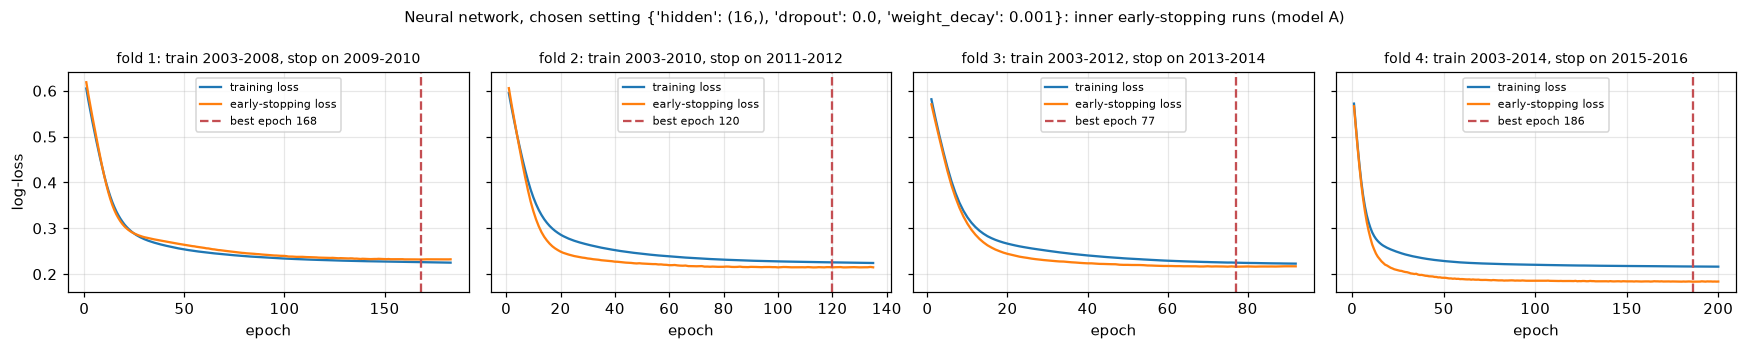

In [111]:
# Loss curves of the chosen setting: the inner early-stopping runs of the four folds.
c = CHOSEN[("A", "neural network")]
info = OOF[("A", "neural network", c["setting"], "info")]
fig, axes = plt.subplots(1, len(FOLDS), figsize=(16, 3.2), sharey=True)
for k, ax in enumerate(axes):
    h = info[k]["history"]
    ax.plot(range(1, len(h["train loss"]) + 1), h["train loss"], label="training loss")
    ax.plot(range(1, len(h["early-stopping loss"]) + 1), h["early-stopping loss"], label="early-stopping loss")
    ax.axvline(info[k]["best_epoch"], color="#C44E52", ls="--", label=f"best epoch {info[k]['best_epoch']}")
    es_from = FOLDS[k][0] - ES_SEASONS
    ax.set_title(f"fold {k + 1}: train 2003-{es_from - 1}, stop on {es_from}-{es_from + 1}", fontsize=9)
    ax.set_xlabel("epoch")
    ax.legend(fontsize=7)
axes[0].set_ylabel("log-loss")
plt.suptitle(f"Neural network, chosen setting {c['params']}: inner early-stopping runs (model A)", fontsize=10)
plt.tight_layout()
plt.show()

### Final models (model A) and the 3-seed check

Each family's chosen setting is refitted on **all** training seasons (2003–2018), with the pre-processing fitted in 5.7. The neural network trains for the median of its four folds' best epochs. Then the chosen network setting is re-run with **3 seeds**, both in cross-validation and as a final model, to show how much it depends on the random start.

In [112]:
FAMILIES = ["logistic regression", "random forest", "gradient boosting", "neural network"]
FINAL6 = {}


def fit_final(model, family, seed=SEED, chosen=None):
    c = (CHOSEN if chosen is None else chosen)[(model, family)]
    pre = PREPROCESSORS[(model, "scaled" if SCALED[family] else "tree")]
    rows = TRAIN_ROWS[model]
    X = pre.transform(rows[FINAL_FEATURES])
    est = make_estimator(family, c["params"], seed)
    if family == "neural network":
        est.epochs = int(np.median([e["best_epoch"] for e in OOF[(model, family, c["setting"], "info")]]))
    fit6(est, rows, f"{model} {family} final (seed {seed})", X=X)
    return {"pre": pre, "model": est}


def predict_final(entry, rows, label):
    log_predict(rows, label)
    return entry["model"].predict_proba(entry["pre"].transform(rows[FINAL_FEATURES]))[:, 1]


for family in FAMILIES:
    FINAL6[("A", family)] = fit_final("A", family)
print("Final model-A fits:", {f: CHOSEN[("A", f)]["params"] for f in FAMILIES})
print("Neural network epochs for the final fit:", FINAL6[("A", "neural network")]["model"].epochs)

# 3-seed check of the chosen network setting (cross-validation and final model).
c = CHOSEN[("A", "neural network")]
seed_rows = []
SEEDS = [SEED, SEED + 1, SEED + 2]
seed_preds = iter(run_jobs([("A", "neural network", c["params"], k, seed) for seed in SEEDS for k in range(len(FOLDS))]))
for seed in SEEDS:
    fold_scores = [average_precision_score(fold_rows("A", k)[1]["podium"], next(seed_preds)[0]) for k in range(len(FOLDS))]
    entry = FINAL6[("A", "neural network")] if seed == SEED else fit_final("A", "neural network", seed)
    p = predict_final(entry, VAL_ROWS, f"A NN seed {seed} validation")
    seed_rows.append({"seed": seed, "mean CV PR-AUC": np.mean(fold_scores), "validation PR-AUC": average_precision_score(y_val, p)})
seed_table = pd.DataFrame(seed_rows)
display(seed_table.round(4))
print(f"Across 3 seeds: CV PR-AUC {seed_table['mean CV PR-AUC'].mean():.4f} ± {seed_table['mean CV PR-AUC'].std():.4f}, "
      f"validation PR-AUC {seed_table['validation PR-AUC'].mean():.4f} ± {seed_table['validation PR-AUC'].std():.4f}")

Final model-A fits: {'logistic regression': {'C': 1, 'class_weight': None}, 'random forest': {'max_depth': 6, 'min_samples_leaf': 50, 'max_features': 'sqrt'}, 'gradient boosting': {'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 80, 'max_iter': 100}, 'neural network': {'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.001}}
Neural network epochs for the final fit: 144


,seed,mean CV PR-AUC,validation PR-AUC
0,42,0.7022,0.7155
1,43,0.6965,0.7322
2,44,0.7023,0.7150


Across 3 seeds: CV PR-AUC 0.7003 ± 0.0033, validation PR-AUC 0.7209 ± 0.0098


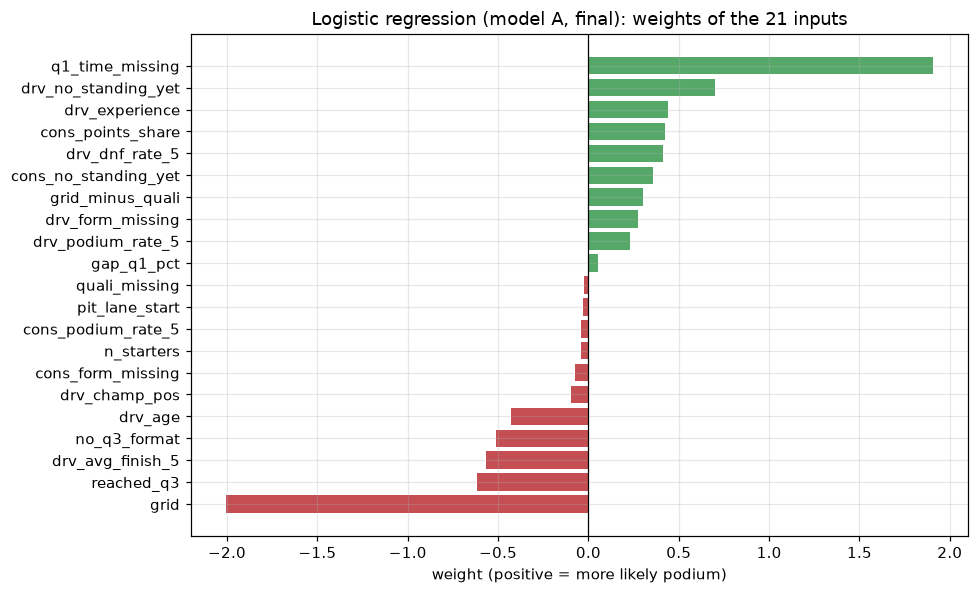

In [113]:
# Logistic regression: what the final model learned (weights on standardised inputs; flags are 0/1).
lr_final = FINAL6[("A", "logistic regression")]["model"]
coef = pd.Series(lr_final.coef_[0], index=MODEL_INPUTS["scaled"]).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(coef.index, coef.values, color=np.where(coef.values > 0, "#55A868", "#C44E52"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("weight (positive = more likely podium)")
ax.set_title("Logistic regression (model A, final): weights of the 21 inputs")
plt.tight_layout()
plt.show()

## 6.8 Decision rules: threshold and top-3 per race

A model gives a probability; a yes/no prediction needs a rule. Two rules, both **fixed without validation labels**:
1. **Probability threshold:** "podium" if the probability is at least *t*. *t* is the value that maximises F1 on the **out-of-fold predictions** (2011–2018, each made by a model that never saw those seasons), then frozen. Training-set predictions are not used, because they are overfitted (especially for the forest). This rule can predict any number of podiums per race.
2. **Top-3 per race:** the 3 highest probabilities in each race are "podium". It only compares drivers within the same race (all known before the start) and predicts exactly 3 per race, like reality. With exactly 3 real and 3 predicted podiums per race, its precision, recall and F1 are equal.

Raising the threshold makes predictions fewer but surer: precision goes up, recall goes down. F1 balances the two.

,threshold (frozen),out-of-fold F1 at it
logistic regression,0.3806,0.6843
random forest,0.2990,0.6779
gradient boosting,0.3869,0.6788
neural network,0.3767,0.6835


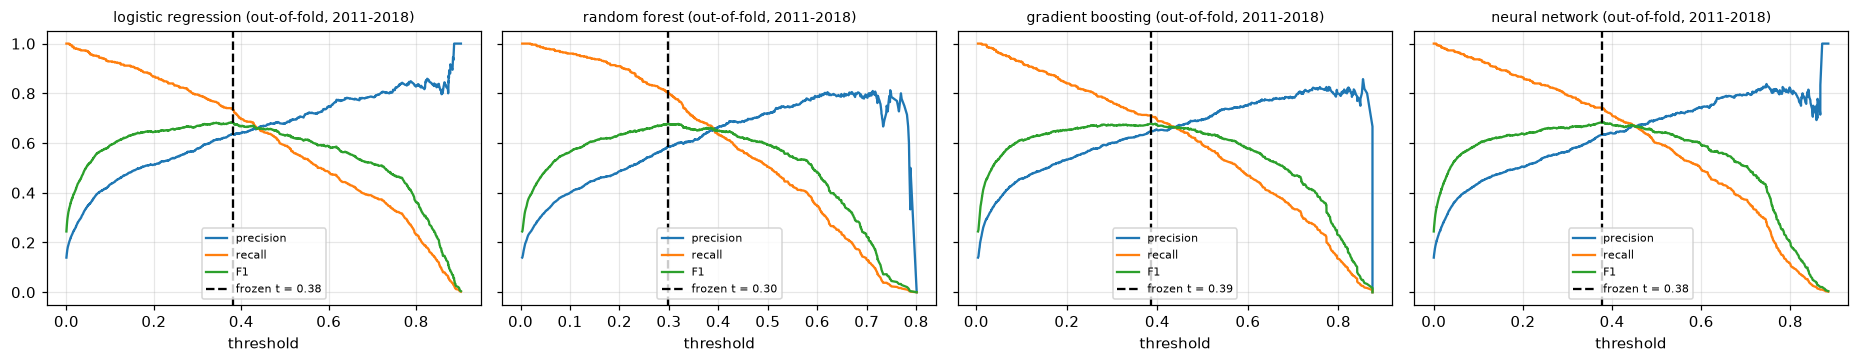

In [114]:
THRESHOLDS = {}


def f1_best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return float(thr[i]), float(f1[i])


for family in FAMILIES:
    p_oof = OOF[("A", family, CHOSEN[("A", family)]["setting"])]
    THRESHOLDS[("A", family)], f1_oof = f1_best_threshold(y_oof["A"], p_oof)
    CHOSEN[("A", family)]["oof F1 at threshold"] = f1_oof
display(pd.DataFrame({f: {"threshold (frozen)": THRESHOLDS[("A", f)], "out-of-fold F1 at it": CHOSEN[("A", f)]["oof F1 at threshold"]}
                      for f in FAMILIES}).T.round(4))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
for ax, family in zip(axes, FAMILIES):
    p_oof = OOF[("A", family, CHOSEN[("A", family)]["setting"])]
    prec, rec, thr = precision_recall_curve(y_oof["A"], p_oof)
    ax.plot(thr, prec[:-1], label="precision")
    ax.plot(thr, rec[:-1], label="recall")
    ax.plot(thr, 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None), label="F1")
    ax.axvline(THRESHOLDS[("A", family)], color="black", ls="--", label=f"frozen t = {THRESHOLDS[('A', family)]:.2f}")
    ax.set_title(f"{family} (out-of-fold, 2011-2018)", fontsize=9)
    ax.set_xlabel("threshold")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 6.9 Validation (2019–2021): one score per final model

Every final model is scored **once** on the validation seasons with its frozen threshold. Nothing below is used to change a setting, a threshold or a model; the "primary model" (6.11) is designated by the cross-validation scores, not by these.

In [115]:
VAL_PRED = {}
for family in FAMILIES:
    VAL_PRED[("A", family)] = predict_final(FINAL6[("A", family)], VAL_ROWS, f"A {family} validation")
# Baselines, fitted on all model-A training seasons
grid_pipe = fit6(grid_only(), TRAIN_A_ROWS, "grid-only LR final")
log_predict(VAL_ROWS, "grid-only LR validation")
VAL_PRED[("A", "grid-only LR")] = grid_pipe.predict_proba(VAL_ROWS[FINAL_FEATURES])[:, 1]
rule_val = (VAL_ROWS["grid"] <= 3).astype(int).to_numpy()

THRESHOLDS[("A", "grid-only LR")], _ = f1_best_threshold(y_oof["A"], BASELINE_OOF)
CV_MEAN = {("A", f): CHOSEN[("A", f)]["cv mean PR-AUC"] for f in FAMILIES}
CV_MEAN[("A", "grid-only LR")] = baseline_cv.loc["mean", "grid-only LR: PR-AUC"]

val_table = [{"model": "always 'no podium' (accuracy reference)", "mean CV PR-AUC": np.nan, "PR-AUC": np.nan, "ROC-AUC": np.nan,
              "Brier": np.nan, "threshold": np.nan, "precision": 0.0, "recall": 0.0, "F1": 0.0,
              "accuracy": accuracy_score(y_val, np.zeros_like(y_val)), "predicted podiums": 0, "F1 top-3 per race": np.nan},
             {"model": "rule: grid <= 3", "mean CV PR-AUC": np.nan, "PR-AUC": np.nan, "ROC-AUC": np.nan, "Brier": np.nan,
              "threshold": np.nan, "precision": precision_score(y_val, rule_val), "recall": recall_score(y_val, rule_val),
              "F1": f1_score(y_val, rule_val), "accuracy": accuracy_score(y_val, rule_val), "predicted podiums": int(rule_val.sum()),
              "F1 top-3 per race": np.nan}]
for name in ["grid-only LR"] + FAMILIES:
    s = scores(y_val, VAL_PRED[("A", name)], THRESHOLDS[("A", name)], val_race)
    val_table.append({"model": name, "mean CV PR-AUC": CV_MEAN[("A", name)], "threshold": THRESHOLDS[("A", name)], **s})
val_table = pd.DataFrame(val_table).set_index("model")
print(f"Validation 2019-2021: {len(VAL_ROWS):,} rows, {int(y_val.sum())} podiums (3 per race); every model-A final model, frozen thresholds")
display(val_table.round(4))

diff_rows = []
for name in FAMILIES:
    for base in ["grid-only LR", "logistic regression"]:
        if name == base:
            continue
        d, lo, hi = paired_difference(VAL_PRED[("A", base)], VAL_PRED[("A", name)])
        diff_rows.append({"model": name, "compared with": base, "PR-AUC difference": d, "95% interval": f"[{lo:+.4f}, {hi:+.4f}]",
                          "clearly different?": "yes" if lo > 0 or hi < 0 else "no (interval includes 0)"})
print("Paired race-resampling comparison on validation (500 resamples of the 60 races):")
display(pd.DataFrame(diff_rows).round(4))

Validation 2019-2021: 1,199 rows, 180 podiums (3 per race); every model-A final model, frozen thresholds


,mean CV PR-AUC,PR-AUC,ROC-AUC,Brier,threshold,precision,recall,F1,accuracy,predicted podiums,F1 top-3 per race
model,,,,,,,,,,,
always 'no podium' (accuracy reference),NaN,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.8499,0,NaN
rule: grid <= 3,NaN,NaN,NaN,NaN,NaN,0.7167,0.7167,0.7167,0.9149,180,NaN
grid-only LR,0.6462,0.6765,0.9168,0.0708,0.3634,0.6167,0.8222,0.7048,0.8966,240,0.7167
logistic regression,0.7032,0.7350,0.9365,0.0647,0.3806,0.6635,0.7778,0.7161,0.9074,211,0.7000
random forest,0.6837,0.7333,0.9363,0.0654,0.2990,0.6348,0.8111,0.7122,0.9016,230,0.7000
gradient boosting,0.6928,0.7208,0.9378,0.0638,0.3869,0.6746,0.7833,0.7249,0.9108,209,0.7167
neural network,0.7022,0.7155,0.9355,0.0651,0.3767,0.6560,0.7944,0.7186,0.9066,218,0.7000


Paired race-resampling comparison on validation (500 resamples of the 60 races):


,model,compared with,PR-AUC difference,95% interval,clearly different?
0,logistic regression,grid-only LR,0.0585,"[+0.0108, +0.1070]",yes
1,random forest,grid-only LR,0.0568,"[+0.0121, +0.1038]",yes
2,random forest,logistic regression,-0.0018,"[-0.0314, +0.0291]",no (interval includes 0)
3,gradient boosting,grid-only LR,0.0443,"[+0.0113, +0.0854]",yes
4,gradient boosting,logistic regression,-0.0142,"[-0.0453, +0.0206]",no (interval includes 0)
5,neural network,grid-only LR,0.0390,"[-0.0015, +0.0922]",no (interval includes 0)
6,neural network,logistic regression,-0.0195,"[-0.0408, +0.0120]",no (interval includes 0)


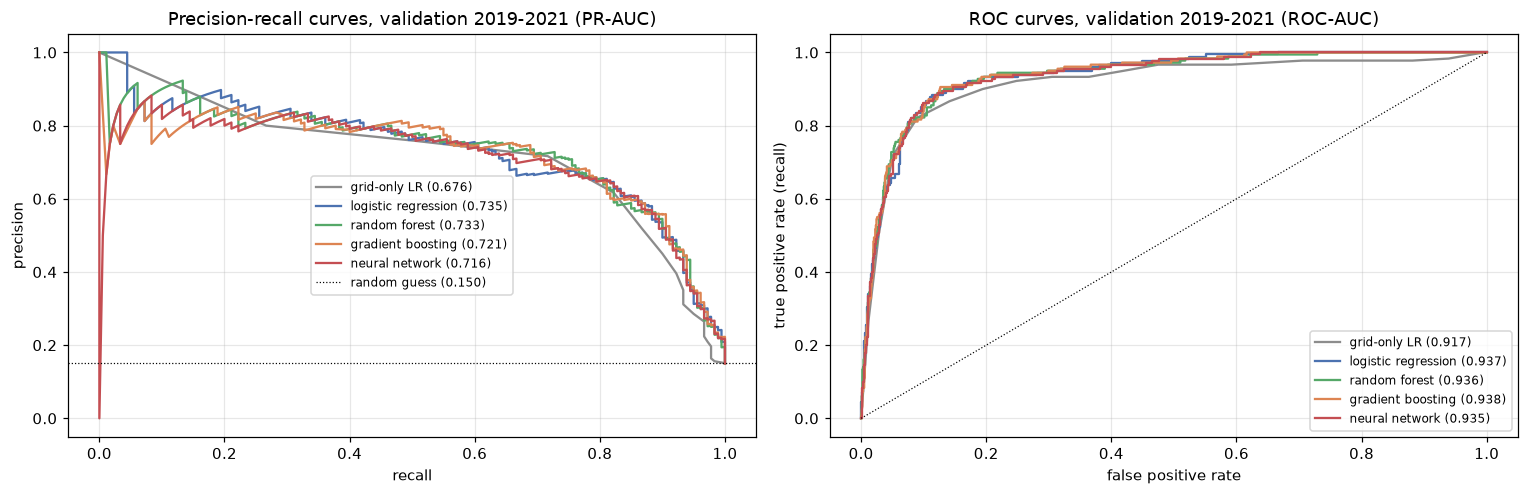

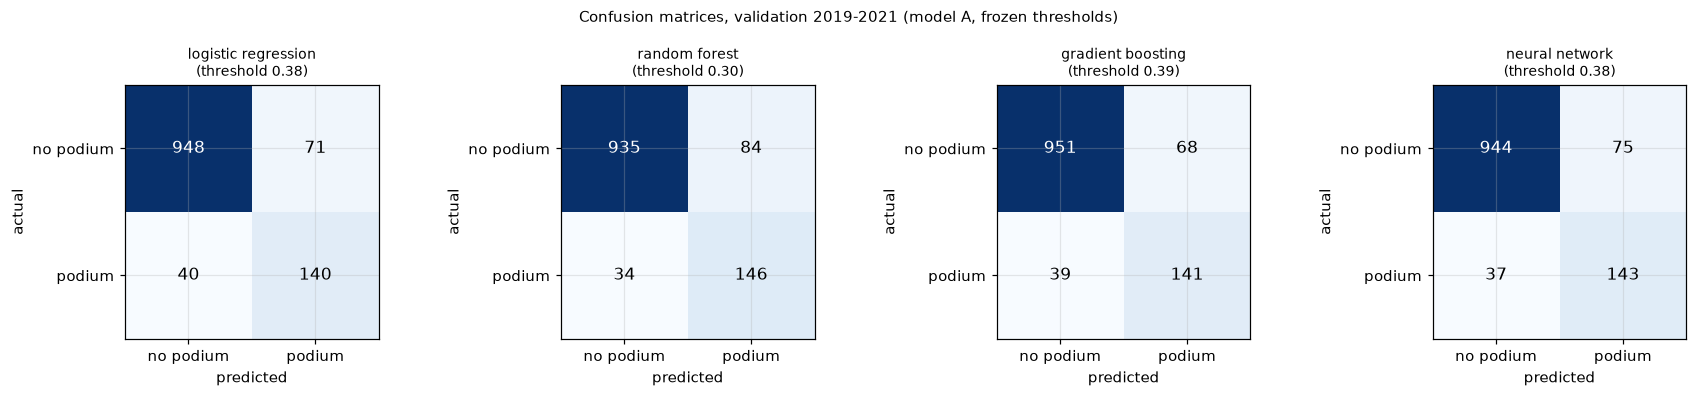

In [116]:
COLORS = {"grid-only LR": "#8C8C8C", "logistic regression": "#4C72B0", "random forest": "#55A868",
          "gradient boosting": "#DD8452", "neural network": "#C44E52"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for name in ["grid-only LR"] + FAMILIES:
    p = VAL_PRED[("A", name)]
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[0].plot(rec, prec, color=COLORS[name], label=f"{name} ({average_precision_score(y_val, p):.3f})")
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[1].plot(fpr, tpr, color=COLORS[name], label=f"{name} ({roc_auc_score(y_val, p):.3f})")
axes[0].axhline(y_val.mean(), color="black", ls=":", lw=0.8, label=f"random guess ({y_val.mean():.3f})")
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title("Precision-recall curves, validation 2019-2021 (PR-AUC)")
axes[1].plot([0, 1], [0, 1], color="black", ls=":", lw=0.8)
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate (recall)")
axes[1].set_title("ROC curves, validation 2019-2021 (ROC-AUC)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, family in zip(axes, FAMILIES):
    pred = (VAL_PRED[("A", family)] >= THRESHOLDS[("A", family)]).astype(int)
    cm = confusion_matrix(y_val, pred)
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1], ["no podium", "podium"])
    ax.set_yticks([0, 1], ["no podium", "podium"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(f"{family}\n(threshold {THRESHOLDS[('A', family)]:.2f})", fontsize=9)
plt.suptitle("Confusion matrices, validation 2019-2021 (model A, frozen thresholds)", fontsize=10)
plt.tight_layout()
plt.show()

**What validation shows.**
- **All four families rank podium finishers about equally well:** validation PR-AUC 0.716–0.735 (logistic regression 0.735, random forest 0.733, gradient boosting 0.721, neural network 0.716). **No family is clearly better than logistic regression**: every interval of the difference includes 0.
- **Three of the four clearly beat the grid-only baseline** (0.676): logistic regression +0.059 (interval +0.011 to +0.107), random forest +0.057, gradient boosting +0.044. The neural network's +0.039 is not clearly different (its interval just includes 0). So the other features (qualifying pace, standings, form) **do** add information beyond the starting position.
- **F1 tells a more modest story.** With the frozen thresholds the models reach F1 0.712–0.725, and the top-3-per-race rule 0.700–0.717. The plain rule "podium if grid ≤ 3" scores **0.717**. As yes/no predictions, the models are about as good as trusting the front row; their gain is in **ranking and probabilities** (PR-AUC, Brier score), e.g. recognising a fast car that starts further back, not in many more correct yes/no calls.
- The thresholds chosen on 2011–2018 transfer reasonably: every model predicts 209–230 podiums for the 180 real ones, i.e. it leans towards recall (0.78–0.81) over precision (0.63–0.67).

### Overfitting: training vs cross-validation vs validation

- **Training** = the final model scored on the rows it was trained on (optimistic by nature).
- **Cross-validation** = the mean over the four folds (each scored on seasons the fold's model never saw); F1 here uses the out-of-fold predictions at the frozen threshold.
- **Validation** = 2019–2021.

A large gap between training and the other two means the model memorised its training rows.

,PR-AUC train,PR-AUC CV,PR-AUC validation,ROC-AUC train,ROC-AUC CV (out-of-fold),ROC-AUC validation,F1 train,F1 CV (out-of-fold),F1 validation
model,,,,,,,,,
logistic regression,0.6876,0.7032,0.7350,0.9300,0.9366,0.9365,0.6632,0.6843,0.7161
random forest,0.7054,0.6837,0.7333,0.9377,0.9403,0.9363,0.6757,0.6779,0.7122
gradient boosting,0.7358,0.6928,0.7208,0.9441,0.9407,0.9378,0.6911,0.6788,0.7249
neural network,0.7060,0.7022,0.7155,0.9372,0.9376,0.9355,0.6749,0.6835,0.7186


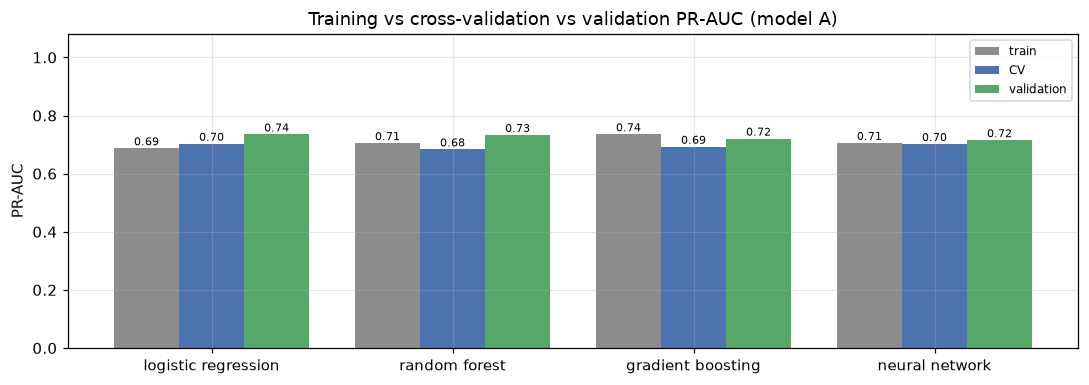

In [117]:
over = []
for family in FAMILIES:
    entry = FINAL6[("A", family)]
    p_tr = predict_final(entry, TRAIN_A_ROWS, f"A {family} training rows (overfitting check)")
    p_oof = OOF[("A", family, CHOSEN[("A", family)]["setting"])]
    t = THRESHOLDS[("A", family)]
    over.append({"model": family,
                 "PR-AUC train": average_precision_score(TRAIN_A_ROWS["podium"], p_tr), "PR-AUC CV": CV_MEAN[("A", family)],
                 "PR-AUC validation": average_precision_score(y_val, VAL_PRED[("A", family)]),
                 "ROC-AUC train": roc_auc_score(TRAIN_A_ROWS["podium"], p_tr),
                 "ROC-AUC CV (out-of-fold)": roc_auc_score(y_oof["A"], p_oof),
                 "ROC-AUC validation": roc_auc_score(y_val, VAL_PRED[("A", family)]),
                 "F1 train": f1_score(TRAIN_A_ROWS["podium"], p_tr >= t), "F1 CV (out-of-fold)": f1_score(y_oof["A"], p_oof >= t),
                 "F1 validation": f1_score(y_val, VAL_PRED[("A", family)] >= t)})
over = pd.DataFrame(over).set_index("model")
display(over.round(4))

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(FAMILIES))
for i, (col, color) in enumerate([("PR-AUC train", "#8C8C8C"), ("PR-AUC CV", "#4C72B0"), ("PR-AUC validation", "#55A868")]):
    ax.bar(x + (i - 1) * 0.27, over[col], 0.27, color=color, label=col.replace("PR-AUC ", ""))
    for xi, v in zip(x, over[col]):
        ax.text(xi + (i - 1) * 0.27, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
ax.set_xticks(x, FAMILIES)
ax.set_ylim(0, 1.08)
ax.set_ylabel("PR-AUC")
ax.set_title("Training vs cross-validation vs validation PR-AUC (model A)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Overfitting.** Small, by design.
- Logistic regression and the network score about the same on their training rows as in cross-validation (0.69–0.71), so they did not memorise the training seasons.
- The tree models show a modest gap: gradient boosting 0.736 on training vs 0.693 in cross-validation, the random forest 0.705 vs 0.684. The chosen settings are the shallow, heavily regularised ones (depth 6 with at least 50 rows per leaf; 7 leaves per tree, 100 trees), which kept the gap small.
- **Validation is higher than cross-validation for every model** (by 0.01–0.05). That is not overfitting in reverse: 2019–2021 were dominated by a few teams, which makes podiums easier to predict, and the earlier CV seasons were harder (fold scores range from about 0.64 to 0.79 by season).

### Probability quality (calibration)

A probability of 0.3 should come true about 30% of the time. Three checks on validation:
- **Brier score** (in the validation table above; lower is better);
- a **reliability diagram**: rows grouped by predicted probability, the actual podium rate of each group against the predicted one (perfect = the diagonal);
- the **sum of predicted probabilities per race**: every race has exactly 3 podiums, so well-calibrated probabilities should add up to about 3. No re-calibration is applied (by decision); this only reports.

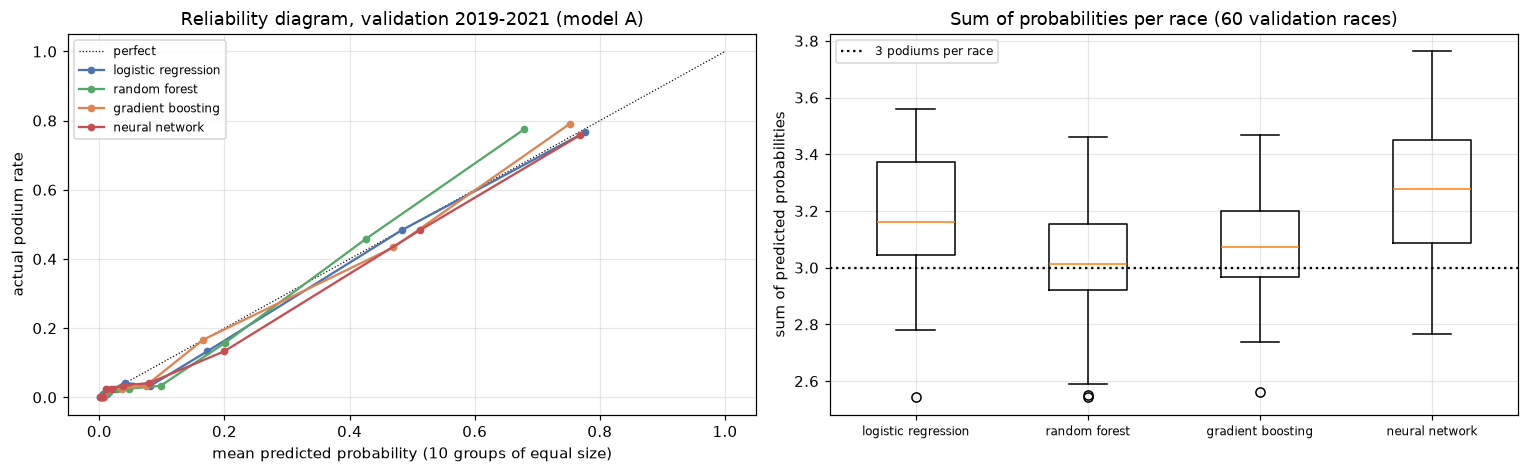

,logistic regression,random forest,gradient boosting,neural network
mean,3.20,3.03,3.08,3.28
min,2.54,2.54,2.56,2.77
max,3.56,3.46,3.47,3.76


In [118]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].plot([0, 1], [0, 1], color="black", ls=":", lw=0.8, label="perfect")
for family in FAMILIES:
    frac, mean_pred = calibration_curve(y_val, VAL_PRED[("A", family)], n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred, frac, marker="o", ms=4, color=COLORS[family], label=family)
axes[0].set_xlabel("mean predicted probability (10 groups of equal size)")
axes[0].set_ylabel("actual podium rate")
axes[0].set_title("Reliability diagram, validation 2019-2021 (model A)")
axes[0].legend(fontsize=8)

race_sums = pd.DataFrame({f: pd.Series(VAL_PRED[("A", f)]).groupby(val_race).sum().to_numpy() for f in FAMILIES})
axes[1].boxplot([race_sums[f] for f in FAMILIES])
axes[1].set_xticks(range(1, len(FAMILIES) + 1), FAMILIES, fontsize=8)
axes[1].axhline(3, color="black", ls=":", label="3 podiums per race")
axes[1].set_ylabel("sum of predicted probabilities")
axes[1].set_title("Sum of probabilities per race (60 validation races)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(race_sums.describe().loc[["mean", "min", "max"]].round(2))

**Probability quality.** Reasonable for every family.
- Brier scores 0.064–0.065, better than the grid-only baseline (0.071).
- On average the probabilities in a race add up to **3.0–3.3** for the 3 real podiums, so they are slightly too high overall, but not by much (no model uses class weighting, which would have inflated them).
- The reliability diagram shows, group by group, how far each family's probabilities are from the diagonal. The groups are small (120 rows each), so a single group's deviation is mostly noise.
- No re-calibration is applied, as decided.

## 6.10 Model A (2003–2018) vs model B (1950–2018)

Model B gets **exactly the same treatment** as model A: the same four grids, the same four fold scoring blocks (fold training simply starts in 1950), the same tie-breaking rule, pre-processing re-fitted inside every fold and its own pipelines from 5.7 for the final fit, its own out-of-fold thresholds, and one validation score per final model.

*Note:* the model-B searches are the most expensive cells of the notebook (four families on up to 20,000 rows per fold).

In [119]:
t0 = time.time()
for family in FAMILIES:
    run_search("B", family)
    show_search("B", family)
    FINAL6[("B", family)] = fit_final("B", family)
    THRESHOLDS[("B", family)], f1_oof_b = f1_best_threshold(y_oof["B"], OOF[("B", family, CHOSEN[("B", family)]["setting"])])
    CHOSEN[("B", family)]["oof F1 at threshold"] = f1_oof_b
    VAL_PRED[("B", family)] = predict_final(FINAL6[("B", family)], VAL_ROWS, f"B {family} validation")
print(f"({time.time() - t0:.0f} s for the model-B searches)")

,setting,C,class_weight,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,chosen
4,4,1,None,0.6475,0.6592,0.7728,0.6858,0.6913,0.0566,
6,6,10,None,0.6471,0.6581,0.7717,0.6859,0.6907,0.0564,
2,2,0.1,None,0.6464,0.6577,0.7720,0.6823,0.6896,0.0570,<= chosen
5,5,1,balanced,0.6407,0.6652,0.7712,0.6783,0.6888,0.0571,
7,7,10,balanced,0.6412,0.6611,0.7716,0.6788,0.6882,0.0577,
3,3,0.1,balanced,0.6367,0.6633,0.7737,0.6759,0.6874,0.0598,
1,1,0.01,balanced,0.6368,0.6619,0.7728,0.6696,0.6853,0.0600,
0,0,0.01,None,0.6381,0.6569,0.7642,0.6724,0.6829,0.0560,


Model B, logistic regression: best mean CV PR-AUC 0.6913; 4 of 8 setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {'C': 0.1, 'class_weight': None} -> mean 0.6896 (fold SD 0.0570)


D:\semster 9\ACL Project\.verification-env\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,setting,max_depth,min_samples_leaf,max_features,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,chosen
5,5,6,50,0.5,0.6412,0.6610,0.7732,0.6948,0.6926,0.0582,
17,17,None,50,0.5,0.6388,0.6638,0.7711,0.6964,0.6925,0.0574,
11,11,10,50,0.5,0.6398,0.6619,0.7707,0.6956,0.6920,0.0572,
1,1,6,5,0.5,0.6312,0.6564,0.7770,0.6888,0.6884,0.0636,
9,9,10,20,0.5,0.6252,0.6591,0.7749,0.6936,0.6882,0.0642,
15,15,None,20,0.5,0.6229,0.6571,0.7724,0.6991,0.6879,0.0644,
10,10,10,50,sqrt,0.6440,0.6645,0.7752,0.6678,0.6879,0.0592,
3,3,6,20,0.5,0.6324,0.6569,0.7718,0.6897,0.6877,0.0608,
16,16,None,50,sqrt,0.6450,0.6636,0.7674,0.6698,0.6865,0.0550,
6,6,10,5,sqrt,0.6164,0.6653,0.7818,0.6782,0.6854,0.0695,


Model B, random forest: best mean CV PR-AUC 0.6926; 18 of 18 setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {'max_depth': 6, 'min_samples_leaf': 50, 'max_features': 'sqrt'} -> mean 0.6841 (fold SD 0.0553)


,setting,learning_rate,max_leaf_nodes,min_samples_leaf,max_iter,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,chosen
1,1,0.05,7,20,300,0.6538,0.6414,0.7740,0.7158,0.6962,0.0612,
4,4,0.05,15,20,100,0.6518,0.6488,0.7729,0.7023,0.6939,0.0581,
0,0,0.05,7,20,100,0.6578,0.6530,0.7595,0.7046,0.6937,0.0496,
2,2,0.05,7,80,100,0.6565,0.6513,0.7594,0.7005,0.6919,0.0501,<= chosen
8,8,0.1,7,20,100,0.6575,0.6415,0.7612,0.7049,0.6913,0.0538,
6,6,0.05,15,80,100,0.6540,0.6469,0.7499,0.6994,0.6876,0.0476,
5,5,0.05,15,20,300,0.6332,0.6381,0.7673,0.7094,0.6870,0.0639,
10,10,0.1,7,80,100,0.6498,0.6406,0.7539,0.7001,0.6861,0.0522,
9,9,0.1,7,20,300,0.6334,0.6346,0.7646,0.7013,0.6834,0.0627,
12,12,0.1,15,20,100,0.6376,0.6376,0.7658,0.6917,0.6832,0.0607,


Model B, gradient boosting: best mean CV PR-AUC 0.6962; 4 of 16 setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 80, 'max_iter': 100} -> mean 0.6919 (fold SD 0.0501)


,setting,hidden,dropout,weight_decay,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,best epochs (inner),chosen
0,0,"(16,)",0.0,0.0001,0.6507,0.6800,0.7904,0.6940,0.7038,0.0605,"[122, 110, 62, 114]",<= chosen
4,4,"(32,)",0.0,0.0001,0.6457,0.6880,0.7908,0.6707,0.6988,0.0637,"[105, 83, 62, 174]",
6,6,"(32,)",0.2,0.0001,0.6490,0.6767,0.7848,0.6842,0.6987,0.0594,"[122, 92, 41, 69]",
8,8,"(32, 16)",0.0,0.0001,0.6521,0.6820,0.7822,0.6760,0.6981,0.0575,"[49, 61, 28, 63]",
3,3,"(16,)",0.2,0.001,0.6594,0.6620,0.7845,0.6855,0.6979,0.0589,"[112, 73, 62, 82]",
5,5,"(32,)",0.0,0.001,0.6524,0.6815,0.7841,0.6728,0.6977,0.0589,"[122, 110, 62, 46]",
9,9,"(32, 16)",0.0,0.001,0.6395,0.6805,0.7835,0.6812,0.6962,0.0614,"[115, 59, 41, 122]",
2,2,"(16,)",0.2,0.0001,0.6503,0.6628,0.7753,0.6949,0.6958,0.0562,"[113, 85, 94, 82]",
7,7,"(32,)",0.2,0.001,0.6510,0.6705,0.7773,0.6838,0.6957,0.0561,"[72, 124, 52, 69]",
10,10,"(32, 16)",0.2,0.0001,0.6525,0.6550,0.7848,0.6882,0.6951,0.0619,"[41, 67, 28, 45]",


Model B, neural network: best mean CV PR-AUC 0.7038; 2 of 12 setting(s) not clearly worse (paired one-SE rule); chosen (simplest of those): {'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.0001} -> mean 0.7038 (fold SD 0.0605)


(305 s for the model-B searches)


,CV PR-AUC A,CV PR-AUC B,val PR-AUC A,val PR-AUC B,val PR-AUC B - A,95% interval,val ROC-AUC A,val ROC-AUC B,val F1 A,val F1 B,val F1 top-3 A,val F1 top-3 B,Brier A,Brier B,chosen B
model,,,,,,,,,,,,,,,
logistic regression,0.7032,0.6896,0.7350,0.7210,-0.0141,"[-0.0383, +0.0125]",0.9365,0.9293,0.7161,0.7186,0.7000,0.6944,0.0647,0.0663,"{'C': 0.1, 'class_weight': None}"
random forest,0.6837,0.6841,0.7333,0.7314,-0.0019,"[-0.0104, +0.0082]",0.9363,0.9358,0.7122,0.6950,0.7000,0.6944,0.0654,0.0661,"{'max_depth': 6, 'min_samples_leaf': 50, 'max_features':..."
gradient boosting,0.6928,0.6919,0.7208,0.7271,0.0064,"[-0.0101, +0.0228]",0.9378,0.9333,0.7249,0.7236,0.7167,0.7111,0.0638,0.0641,"{'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_sample..."
neural network,0.7022,0.7038,0.7155,0.7314,0.0159,"[-0.0061, +0.0301]",0.9355,0.9367,0.7186,0.7136,0.7000,0.6944,0.0651,0.0645,"{'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.0001}"


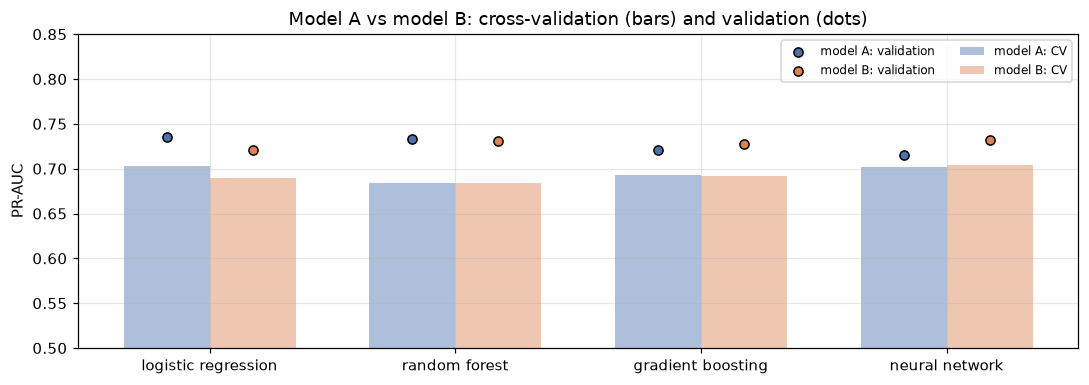

In [120]:
ab = []
for family in FAMILIES:
    sa = scores(y_val, VAL_PRED[("A", family)], THRESHOLDS[("A", family)], val_race)
    sb = scores(y_val, VAL_PRED[("B", family)], THRESHOLDS[("B", family)], val_race)
    d, lo, hi = paired_difference(VAL_PRED[("A", family)], VAL_PRED[("B", family)])
    ab.append({"model": family, "CV PR-AUC A": CHOSEN[("A", family)]["cv mean PR-AUC"], "CV PR-AUC B": CHOSEN[("B", family)]["cv mean PR-AUC"],
               "val PR-AUC A": sa["PR-AUC"], "val PR-AUC B": sb["PR-AUC"], "val PR-AUC B - A": d, "95% interval": f"[{lo:+.4f}, {hi:+.4f}]",
               "val ROC-AUC A": sa["ROC-AUC"], "val ROC-AUC B": sb["ROC-AUC"], "val F1 A": sa["F1"], "val F1 B": sb["F1"],
               "val F1 top-3 A": sa["F1 top-3 per race"], "val F1 top-3 B": sb["F1 top-3 per race"],
               "Brier A": sa["Brier"], "Brier B": sb["Brier"], "chosen B": str(CHOSEN[("B", family)]["params"])})
ab = pd.DataFrame(ab).set_index("model")
display(ab.round(4))

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(FAMILIES))
for i, (m, color) in enumerate([("A", "#4C72B0"), ("B", "#DD8452")]):
    ax.bar(x + (i - 0.5) * 0.35, ab[f"CV PR-AUC {m}"], 0.35, color=color, alpha=0.45, label=f"model {m}: CV")
    ax.scatter(x + (i - 0.5) * 0.35, ab[f"val PR-AUC {m}"], color=color, edgecolor="black", zorder=3, label=f"model {m}: validation")
ax.set_xticks(x, FAMILIES)
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("PR-AUC")
ax.set_title("Model A vs model B: cross-validation (bars) and validation (dots)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**Model A vs model B.** No meaningful difference.
- In cross-validation the two are within about 0.014 of each other for every family (model A ahead for logistic regression, equal elsewhere).
- On validation, model B is slightly lower for logistic regression (−0.014) and the random forest (−0.002), and slightly higher for gradient boosting (+0.006) and the network (+0.016). **Every interval includes 0.**
- **Fifty extra seasons (3.5× more rows) do not buy better podium predictions for 2019–2021.**

### Is it the amount of data or the age of the data?

Model B differs from model A in two ways at once: **more** rows and **older** rows. Two analyses separate them. They use validation only to **describe** the effect (no setting is changed because of them), with logistic regression and gradient boosting at model A's chosen settings and pre-processing re-fitted on each training window.
1. **Training start year:** train on `start`–2018 for start = 1950, 1970, 1980, 1994, 2003, 2010.
2. **Same size, mixed eras:** five random samples of whole races from 1950–2018 with as many rows as model A (6,381), compared with model A (same size, modern only) and full model B (all rows).

val PR-AUC                     difference vs 2003-2018                            95% interval                    
model                  gradient boosting logistic regression       gradient boosting logistic regression   gradient boosting logistic regression
training seasons rows                                                                                                                           
1950-2018        22092          0.727132            0.723588                0.006358           -0.011435  [-0.0101, +0.0228]  [-0.0339, +0.0135]
1970-2018        18724          0.723353            0.723696                0.002579           -0.011327  [-0.0156, +0.0208]  [-0.0296, +0.0126]
1980-2018        15280          0.722169            0.722786                0.001395           -0.012237  [-0.0169, +0.0178]  [-0.0303, +0.0104]
1994-2018        9709           0.723024              0.7233                 0.00225           -0.011723  [-0.0116, +0.0173]  [-0.0265, +0.0076]
2003-2018        6381           0.720774            0.735023                     0.0                 0.0  [+0.0000, +0.0000]  [+0.0000, +0.0000]
2010-2018        3862           0.719706             0.73174               -0.001069           -0.003283  [-0.0202, +0.0175]  [-0.0119, +0.0055]

,"A: 2003-2018 (6,381 rows, modern)","same size, mixed eras (mean of 5)","same size, mixed eras (SD)","B: 1950-2018 (22,092 rows)"
model,,,,
logistic regression,0.7350,0.7161,0.0093,0.7236
gradient boosting,0.7208,0.7122,0.0100,0.7271


Rows and race counts of the same-size samples: {'rows': [6391, 6389, 6400, 6401, 6394], 'races': [282, 285, 285, 289, 288]}


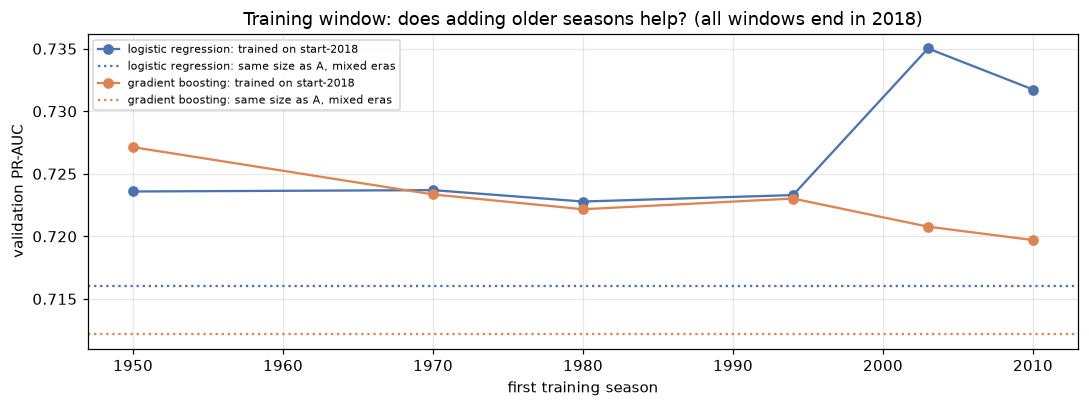

In [121]:
def window_score(family, rows, label):
    params = CHOSEN[("A", family)]["params"]
    pipe = Pipeline([("pre", make_preprocessor(scaled=SCALED[family])), ("model", make_estimator(family, params))])
    fit6(pipe, rows, label)
    log_predict(VAL_ROWS, f"{label} validation")
    return pipe.predict_proba(VAL_ROWS[FINAL_FEATURES])[:, 1]


WINDOW_FAMILIES = ["logistic regression", "gradient boosting"]
window = []
win_pred = {}
for start in [1950, 1970, 1980, 1994, 2003, 2010]:
    rows = TRAIN_B_ROWS[TRAIN_B_ROWS["year"] >= start]
    for family in WINDOW_FAMILIES:
        win_pred[(family, start)] = window_score(family, rows, f"window {start}-2018 {family}")
for start in [1950, 1970, 1980, 1994, 2003, 2010]:
    rows = TRAIN_B_ROWS[TRAIN_B_ROWS["year"] >= start]
    for family in WINDOW_FAMILIES:
        d, lo, hi = paired_difference(win_pred[(family, 2003)], win_pred[(family, start)])
        window.append({"training seasons": f"{start}-2018", "start": start, "rows": len(rows), "model": family,
                       "val PR-AUC": average_precision_score(y_val, win_pred[(family, start)]),
                       "difference vs 2003-2018": d, "95% interval": f"[{lo:+.4f}, {hi:+.4f}]", "low": lo, "high": hi})
window = pd.DataFrame(window)
display(window.pivot(index=["training seasons", "rows"], columns="model",
                     values=["val PR-AUC", "difference vs 2003-2018", "95% interval"]).round(4))

rng_sub = np.random.default_rng(SEED)
races_b = TRAIN_B_ROWS.groupby("raceId").size()
sub = []
for s in range(5):
    order = rng_sub.permutation(races_b.index.to_numpy())
    keep = order[: int(np.searchsorted(races_b.loc[order].cumsum().to_numpy(), len(TRAIN_A_ROWS))) + 1]
    rows = TRAIN_B_ROWS[TRAIN_B_ROWS["raceId"].isin(keep)]
    for family in WINDOW_FAMILIES:
        p = window_score(family, rows, f"same-size sample {s + 1} {family}")
        sub.append({"sample": s + 1, "model": family, "rows": len(rows), "races": len(keep),
                    "share of rows from 2003+": (rows["year"] >= 2003).mean(), "val PR-AUC": average_precision_score(y_val, p)})
sub = pd.DataFrame(sub)
size_era = []
for family in WINDOW_FAMILIES:
    s = sub[sub["model"] == family]["val PR-AUC"]
    size_era.append({"model": family, "A: 2003-2018 (6,381 rows, modern)": average_precision_score(y_val, win_pred[(family, 2003)]),
                     "same size, mixed eras (mean of 5)": s.mean(), "same size, mixed eras (SD)": s.std(),
                     "B: 1950-2018 (22,092 rows)": average_precision_score(y_val, win_pred[(family, 1950)])})
display(pd.DataFrame(size_era).set_index("model").round(4))
print("Rows and race counts of the same-size samples:", sub.groupby("sample")[["rows", "races"]].first().to_dict("list"))

fig, ax = plt.subplots(figsize=(10, 3.8))
for family, color in [("logistic regression", "#4C72B0"), ("gradient boosting", "#DD8452")]:
    w = window[window["model"] == family]
    ax.plot(w["start"], w["val PR-AUC"], marker="o", color=color, label=f"{family}: trained on start-2018")
    ax.axhline(sub[sub["model"] == family]["val PR-AUC"].mean(), color=color, ls=":", label=f"{family}: same size as A, mixed eras")
ax.set_xlabel("first training season")
ax.set_ylabel("validation PR-AUC")
ax.set_title("Training window: does adding older seasons help? (all windows end in 2018)")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Amount vs age of data** (descriptive only; nothing was changed because of it).
- **Same size, different eras:** with the same number of rows, the modern-only window (model A) scores higher than random samples of races from all eras: logistic regression 0.735 vs 0.716 (± 0.009 over the five samples), gradient boosting 0.721 vs 0.712 (± 0.010). At equal size, **old races are less useful** than modern ones, because the relationships changed (reliability, grid sizes, how often the front row converts).
- **Adding older seasons on top of 2003–2018** slightly hurts logistic regression (about −0.011 for every start before 2003) and slightly helps gradient boosting (+0.001 to +0.006), which can treat old and new seasons differently through `quali_missing` and the other era-linked inputs. Both effects are small compared with the noise of 60 races.
- **Conclusion:** model A's 2003+ window is a sound default. Model B is kept for comparison, as planned.

## 6.11 Final selection and freeze

**Everything below is frozen now, before the test seasons are used:** for each of the 8 final models (4 families × model A and model B) and the two baselines: the chosen setting, the fitted pre-processing, the fitted model, the training seasons, the threshold, and (for the network) the number of epochs and the seed. Nothing is re-tuned after this point.

**Primary model (rule fixed in advance):** among the model-A families, the highest **mean cross-validation** PR-AUC; if a simpler family is not clearly worse by the same paired one-standard-error rule (on the four folds), the simpler family wins (logistic regression < random forest < gradient boosting < neural network). Validation scores do **not** decide it, so the validation comparison in 6.9 stays an honest check.

The frozen settings are retained in `FROZEN` (settings, thresholds and a fingerprint; no data), so the later test evaluation can show it uses exactly these.

In [122]:
SIMPLER_FAMILY = {f: i for i, f in enumerate(FAMILIES)}
family_folds = pd.DataFrame({f: SEARCH[("A", f)].loc[CHOSEN[("A", f)]["setting"], FOLD_COLS] for f in FAMILIES}).T.astype(float)
best = family_folds.mean(axis=1).idxmax()
near = paired_ties(family_folds, best)
PRIMARY_MODEL = ("A", min(near, key=SIMPLER_FAMILY.get))
display(family_folds.assign(mean=family_folds.mean(axis=1)).round(4))
print(f"Highest mean CV PR-AUC: {best} ({family_folds.loc[best].mean():.4f}); not clearly worse (paired one-SE rule): {near}")
print(f"Primary model: {PRIMARY_MODEL[1]}, model {PRIMARY_MODEL[0]}")

FROZEN = {}
for (m, family), entry in FINAL6.items():
    c = CHOSEN[(m, family)]
    FROZEN[f"{m} | {family}"] = {
        "model version": m, "training seasons": f"{TRAIN_ROWS[m]['year'].min()}-{TRAIN_ROWS[m]['year'].max()}",
        "family": family, "settings": {k: (list(v) if isinstance(v, tuple) else v) for k, v in c["params"].items()},
        "pre-processing": f"PREPROCESSORS[('{m}', '{'scaled' if SCALED[family] else 'tree'}')]",
        "threshold": round(THRESHOLDS[(m, family)], 6), "seed": SEED,
        "epochs": int(entry["model"].epochs) if family == "neural network" else None,
        "mean CV PR-AUC": round(c["cv mean PR-AUC"], 6),
        "validation PR-AUC": round(average_precision_score(y_val, VAL_PRED[(m, family)]), 6),
        "primary": (m, family) == PRIMARY_MODEL}
FROZEN["A | grid-only LR (baseline)"] = {"model version": "A", "training seasons": "2003-2018", "family": "logistic regression on grid",
                                         "threshold": round(THRESHOLDS[("A", "grid-only LR")], 6),
                                         "validation PR-AUC": round(average_precision_score(y_val, VAL_PRED[("A", "grid-only LR")]), 6)}
FROZEN["rule: grid <= 3 (baseline)"] = {"rule": "podium if grid <= 3"}
FROZEN_MODELS = {**FINAL6, ("A", "grid-only LR"): {"pipe": grid_pipe}}
FROZEN_FINGERPRINT = hashlib.sha256(json.dumps(FROZEN, sort_keys=True).encode()).hexdigest()
display(pd.DataFrame(FROZEN).T.drop(columns=["rule"], errors="ignore"))
print(f"Frozen {len(FROZEN)} entries in memory | fingerprint {FROZEN_FINGERPRINT[:16]}...")


def predict_frozen(key, rows):
    """Probabilities and both decision rules of a frozen model, for any rows (used later for the test seasons)."""
    if key == ("A", "grid-only LR"):
        p = FROZEN_MODELS[key]["pipe"].predict_proba(rows[FINAL_FEATURES])[:, 1]
    else:
        e = FROZEN_MODELS[key]
        p = e["model"].predict_proba(e["pre"].transform(rows[FINAL_FEATURES]))[:, 1]
    return pd.DataFrame({"probability": p, "threshold rule": (p >= THRESHOLDS[key]).astype(int),
                         "top-3 rule": top3_per_race(p, rows["raceId"].to_numpy())}, index=rows.index)


# The frozen objects reproduce the validation predictions exactly (so they can be reused unchanged later).
for key in FROZEN_MODELS:
    assert np.array_equal(predict_frozen(key, VAL_ROWS)["probability"].to_numpy(), VAL_PRED[key]), key
print("predict_frozen reproduces every frozen model's validation predictions exactly.")

,fold 1,fold 2,fold 3,fold 4,mean
logistic regression,0.6532,0.6864,0.7926,0.6808,0.7032
random forest,0.6374,0.6687,0.7691,0.6597,0.6837
gradient boosting,0.6546,0.6550,0.7789,0.6828,0.6928
neural network,0.6576,0.6775,0.7886,0.6852,0.7022


Highest mean CV PR-AUC: logistic regression (0.7032); not clearly worse (paired one-SE rule): ['logistic regression', 'neural network']
Primary model: logistic regression, model A


,model version,training seasons,family,settings,pre-processing,threshold,seed,epochs,mean CV PR-AUC,validation PR-AUC,primary
A | logistic regression,A,2003-2018,logistic regression,"{'C': 1, 'class_weight': None}","PREPROCESSORS[('A', 'scaled')]",0.380597,42,None,0.703218,0.735023,True
A | random forest,A,2003-2018,random forest,"{'max_depth': 6, 'min_samples_leaf': 50, 'max_features':...","PREPROCESSORS[('A', 'tree')]",0.298957,42,None,0.68372,0.733263,False
A | gradient boosting,A,2003-2018,gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_sample...","PREPROCESSORS[('A', 'tree')]",0.386861,42,None,0.692831,0.720774,False
A | neural network,A,2003-2018,neural network,"{'hidden': [16], 'dropout': 0.0, 'weight_decay': 0.001}","PREPROCESSORS[('A', 'scaled')]",0.376662,42,144,0.702206,0.715529,False
B | logistic regression,B,1950-2018,logistic regression,"{'C': 0.1, 'class_weight': None}","PREPROCESSORS[('B', 'scaled')]",0.298557,42,None,0.689618,0.720972,False
B | random forest,B,1950-2018,random forest,"{'max_depth': 6, 'min_samples_leaf': 50, 'max_features':...","PREPROCESSORS[('B', 'tree')]",0.287421,42,None,0.684118,0.731371,False
B | gradient boosting,B,1950-2018,gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_sample...","PREPROCESSORS[('B', 'tree')]",0.352762,42,None,0.691927,0.727132,False
B | neural network,B,1950-2018,neural network,"{'hidden': [16], 'dropout': 0.0, 'weight_decay': 0.0001}","PREPROCESSORS[('B', 'scaled')]",0.315648,42,112,0.703771,0.731424,False
A | grid-only LR (baseline),A,2003-2018,logistic regression on grid,NaN,NaN,0.363429,NaN,NaN,NaN,0.676492,NaN
rule: grid <= 3 (baseline),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Frozen 10 entries in memory | fingerprint 53625c66acf187ca...


predict_frozen reproduces every frozen model's validation predictions exactly.


In [123]:
# Final guards for section 6.
fit_log6, pred_log6 = pd.DataFrame(FIT6_LOG), pd.DataFrame(PREDICT6_LOG)
fold_fits = fit_log6[fit_log6["must end before"].notna()]
assert (fold_fits["seasons"].str[-4:].astype(int) < fold_fits["must end before"]).all(), "a fold fit used a later season"
assert fit_log6["seasons"].str[-4:].astype(int).max() <= SPLIT_YEARS["train"][1], "a fit used a non-training season"
assert pred_log6["splits"].isin(["train", "validation"]).all(), "a prediction was made on test rows"
assert not any("test" in field.lower() for record in FROZEN.values() for field in record), "a test metric in the frozen record"
assert hashlib.sha256(final_features_df.to_csv(index=False).encode()).hexdigest() == FF_SHA_BEFORE, "feature table changed"
print(f"PASS {len(fit_log6)} fits in section 6, all on training rows; all {len(fold_fits)} cross-validation fits used only seasons "
      f"before their scoring block (asserted at fit time and re-checked from the log)")
print(f"PASS {len(pred_log6)} predictions, only on training or validation rows; no test row was used and no test metric computed")
print("PASS in-memory feature table unchanged")
display(fit_log6.groupby("seasons").size().rename("fits").to_frame().T)

PASS 697 fits in section 6, all on training rows; all 664 cross-validation fits used only seasons before their scoring block (asserted at fit time and re-checked from the log)
PASS 486 predictions, only on training or validation rows; no test row was used and no test metric computed
PASS in-memory feature table unchanged


seasons,1950-2008,1950-2010,1950-2012,1950-2014,1950-2016,1950-2018,1970-2018,1980-2018,1994-2018,2003-2008,2003-2010,2003-2012,2003-2014,2003-2016,2003-2018,2010-2018
fits,12,78,78,78,66,16,2,2,2,15,88,88,88,73,9,2


**Summary of section 6.**
- **Settings** were chosen by time-ordered cross-validation on 2003–2018 (paired one-standard-error rule, simplest of the ties). Model A chose:
  - logistic regression: `C = 1`, no class weighting;
  - random forest: depth 6, at least 50 rows per leaf, `sqrt` features;
  - gradient boosting: learning rate 0.05, 7 leaves, at least 80 rows per leaf, 100 trees;
  - neural network: one hidden layer of 16 units, no dropout, weight decay 0.001, 144 epochs.
- **Validation (2019–2021, used once):** PR-AUC 0.716–0.735 for the four families. Three clearly beat the grid-only baseline (0.676); none is clearly better than logistic regression. As yes/no predictions (F1 ≈ 0.71–0.72), the models are about as good as the rule "grid ≤ 3" (0.717); their value is in ranking and probabilities.
- **Primary model: logistic regression, model A.** Highest mean cross-validation PR-AUC (0.703), the simplest family, and well-calibrated probabilities. Its improvement over the grid-only baseline is clear (+0.059, interval +0.011 to +0.107); its edge over the other families is not.
- **Model A vs model B:** no meaningful difference. At equal size, modern seasons are more useful than old ones.
- **Frozen:** 8 models (4 families × A and B) + 2 baselines, with settings, fitted pipelines, thresholds and a fingerprint (`FROZEN` (in memory)). **The test seasons 2022–2024 have not been used**; they are evaluated once, in a separate step, with exactly these frozen models.

## 6.12 Reusing fitted models in memory

Bind each already-fitted model and its own preprocessor to a prediction function. Keep full-precision thresholds, feature order, versions and the pre-test fingerprint in memory. No model is retrained in this step.

In [124]:
artifact_name = lambda key: f"{key[0]}_{key[1].replace(' ', '_').replace('-', '_')}"

def bind_fitted_models(models, thresholds, primary, fingerprint):
    """Bind already-fitted objects, preserving full-precision thresholds and feature order."""
    bound, metadata = {}, {}
    for key, entry in models.items():
        name = artifact_name(key)
        def predict(rows, entry=entry):
            if "pipe" in entry:
                return entry["pipe"].predict_proba(rows[FINAL_FEATURES])[:, 1]
            return entry["model"].predict_proba(entry["pre"].transform(rows[FINAL_FEATURES]))[:, 1]
        bound[name] = {"key": key, "predict": predict, "threshold": thresholds[key]}
        metadata[name] = {"key": key, "primary": key == primary,
                          "model inputs (after pre-processing)": MODEL_INPUTS["scaled" if SCALED.get(key[1], True) else "tree"]}
    versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                "scikit-learn": __import__("sklearn").__version__, "torch": torch.__version__}
    return bound, {"frozen fingerprint": fingerprint, "input columns": list(FINAL_FEATURES),
                   "models": metadata, "versions": versions}

loaded_models, manifest = bind_fitted_models(FROZEN_MODELS, THRESHOLDS, PRIMARY_MODEL, FROZEN_FINGERPRINT)


### In-memory reproduction check

Recompute validation probabilities from the fitted objects and check differences ≤ 1e-9, exact thresholds and identical threshold/top-three decisions.

In [125]:
TOLERANCE = 1e-9

def verify_bound_models(bound, reference, thresholds):
    rows = []
    for name, entry in bound.items():
        key = entry["key"]
        p = entry["predict"](VAL_ROWS)
        delta = float(np.max(np.abs(p - reference[key])))
        assert delta <= TOLERANCE
        assert entry["threshold"] == thresholds[key]
        assert np.array_equal(p >= thresholds[key], reference[key] >= thresholds[key])
        assert np.array_equal(top3_per_race(p, val_race), top3_per_race(reference[key], val_race))
        rows.append({"model": name, "largest |difference|": delta, "same decisions": True})
    display(pd.DataFrame(rows))

verify_bound_models(loaded_models, VAL_PRED, THRESHOLDS)


,model,largest |difference|,same decisions
0,A_logistic_regression,0.0,True
1,A_random_forest,0.0,True
2,A_gradient_boosting,0.0,True
3,A_neural_network,0.0,True
4,B_logistic_regression,0.0,True
5,B_random_forest,0.0,True
6,B_gradient_boosting,0.0,True
7,B_neural_network,0.0,True
8,A_grid_only_LR,0.0,True


**Portability.** Run All rebuilds models from raw CSVs. No serialized Python objects or external loader are needed. CPU threads and seeds remain fixed; section 7 reports library-version differences and checks the original pre-test configuration.

# 7. Final optimisation, second freeze and the test evaluation

This section runs four phases in a fixed order:
1. **Phase 1, final optimisation (7.1–7.2):** a small, rule-based extension of the section-6 grids, tuned exactly like section 6 (same forward-chaining folds inside the training seasons, pre-processing re-fitted in every fold, same paired one-standard-error rule, same simplicity order). Validation is **not** used to choose anything.
2. **Phase 2, second freeze (7.3–7.4):** final fits, out-of-fold thresholds, a new frozen record (`FROZEN_V2` (in memory)) and fitted models (`FINAL_V2` (in memory)), verified in memory. **Section 6 stays untouched** as the first freeze (v1), with its in-memory record and objects, for comparison.
3. **Phase 3, test evaluation (7.5–7.8):** the 2022–2024 seasons are used for the first time, with the models reused from the fitted v2 objects. Before that, the test cell checks that the v2 fingerprint equals the value recorded when v2 was frozen, i.e. before any test result existed.
4. **Phase 4, interpretation (7.9).**

**Rule after Phase 3:** no retraining, re-tuning, feature change, threshold change or change of the primary model because of test results. Ideas raised by the test results are labelled *post-test, exploratory*.

## 7.1 Phase 1: which settings are worth testing?

In section 6, several best or chosen settings sit on the **edge** of their grid (e.g. the smallest learning rate or the largest leaf size tried). Then the real optimum might lie just outside the grid. **Rule (fixed before running anything new):** for every setting dimension where the best or the chosen setting of model A **or** model B uses the smallest (or largest) value tried, add **one** value beyond that edge from a fixed list. The extended grid is the full combination of the old and new values; only the new combinations are run. Both models get the same extended grid.

The values beyond each edge:

| Family | Setting | Below the smallest | Above the largest |
|---|---|---|---|
| logistic regression | `C` | 0.001 | 100 |
| random forest | `max_depth` | 4 | (none: "unlimited" is already the top) |
| random forest | `min_samples_leaf` | 2 | 100 |
| gradient boosting | `learning_rate` | 0.02 | 0.2 |
| gradient boosting | `max_leaf_nodes` | 3 | 31 |
| gradient boosting | `min_samples_leaf` | 10 | 160 |
| gradient boosting | `max_iter` | 50 | 600 |
| neural network | hidden layers (by size) | (8,) | (64,) |
| neural network | `dropout` | (none: 0 is the minimum) | 0.4 |
| neural network | `weight_decay` | 1e-5 | 1e-2 |

Categorical settings (`class_weight`, `max_features`) have no edge and are not extended. Nothing else changes: same features, same pre-processing, same training windows, same folds, same selection rule (applied to the old and new settings together, so a new setting is chosen only if it is not clearly worse than the best **and** simpler, or clearly better).

In [126]:
BEYOND = {   # (below the smallest, above the largest); None = no extension in that direction
    "logistic regression": {"C": (0.001, 100)},
    "random forest": {"max_depth": (4, None), "min_samples_leaf": (2, 100)},
    "gradient boosting": {"learning_rate": (0.02, 0.2), "max_leaf_nodes": (3, 31), "min_samples_leaf": (10, 160), "max_iter": (50, 600)},
    "neural network": {"hidden": ((8,), (64,)), "dropout": (None, 0.4), "weight_decay": (1e-5, 1e-2)},
}
ORDER_KEY = {"max_depth": lambda v: np.inf if v is None else v, "hidden": n_weights}   # how values are ordered


def grid_values(family):
    names = list(GRIDS[family][0])
    return {n: list(dict.fromkeys(p[n] for p in GRIDS[family])) for n in names}


edge_rows, GRIDS_V2 = [], {}
for family in FAMILIES:
    values = grid_values(family)
    used = {(m, which): CHOSEN[(m, family)]["params"] if which == "chosen" else
            GRIDS[family][int(SEARCH[(m, family)]["mean PR-AUC"].idxmax())]
            for m in ["A", "B"] for which in ["best", "chosen"]}
    extended = {n: list(v) for n, v in values.items()}
    for name, (below, above) in BEYOND[family].items():
        key = ORDER_KEY.get(name, lambda v: v)
        lo_v, hi_v = min(values[name], key=key), max(values[name], key=key)
        hit_lo = [f"{m} {w}" for (m, w), p in used.items() if p[name] == lo_v]
        hit_hi = [f"{m} {w}" for (m, w), p in used.items() if p[name] == hi_v]
        if hit_lo and below is not None:
            extended[name] = [below] + extended[name]
        if hit_hi and above is not None:
            extended[name] = extended[name] + [above]
        edge_rows.append({"family": family, "setting": name, "values tried": values[name],
                          "smallest used by": ", ".join(hit_lo) or "-", "largest used by": ", ".join(hit_hi) or "-",
                          "added": [v for v in extended[name] if v not in values[name]] or "-"})
    combos = [dict(zip(extended, vals)) for vals in __import__("itertools").product(*extended.values())]
    GRIDS_V2[family] = GRIDS[family] + [c for c in combos if c not in GRIDS[family]]   # old settings keep their numbers
display(pd.DataFrame(edge_rows))
display(pd.DataFrame({"settings in section 6": {f: len(GRIDS[f]) for f in FAMILIES},
                      "new settings": {f: len(GRIDS_V2[f]) - len(GRIDS[f]) for f in FAMILIES},
                      "extended grid": {f: len(GRIDS_V2[f]) for f in FAMILIES}}))

,family,setting,values tried,smallest used by,largest used by,added
0,logistic regression,C,"[0.01, 0.1, 1, 10]",-,A best,[100]
1,random forest,max_depth,"[6, 10, None]","A chosen, B best, B chosen",-,[4]
2,random forest,min_samples_leaf,"[5, 20, 50]",-,"A best, A chosen, B best, B chosen",[100]
3,gradient boosting,learning_rate,"[0.05, 0.1]","A best, A chosen, B best, B chosen",-,[0.02]
4,gradient boosting,max_leaf_nodes,"[7, 15]","A best, A chosen, B best, B chosen",-,[3]
5,gradient boosting,min_samples_leaf,"[20, 80]","A best, B best","A chosen, B chosen","[10, 160]"
6,gradient boosting,max_iter,"[100, 300]","A best, A chosen, B chosen",B best,"[50, 600]"
7,neural network,hidden,"[(16,), (32,), (32, 16)]","A chosen, B best, B chosen",-,"[(8,)]"
8,neural network,dropout,"[0.0, 0.2]","A chosen, B best, B chosen",A best,[0.4]
9,neural network,weight_decay,"[0.0001, 0.001]","B best, B chosen","A best, A chosen","[1e-05, 0.01]"


,settings in section 6,new settings,extended grid
logistic regression,8,2,10
random forest,18,14,32
gradient boosting,16,128,144
neural network,12,36,48


## 7.2 Phase 1: tuning the extended grids

Only the new settings are run (the section-6 fold scores of the old settings are reused unchanged; they are deterministic). Then the **same rule** chooses among old + new settings: paired one-standard-error ties, closed upwards, simplest first. The random forest's simplicity order gains `max_depth` 4 (the shallowest); all other orders already cover the new values. The jobs run in chunks so progress is reported regularly.

In [127]:
SIMPLICITY_V2 = dict(SIMPLICITY)
SIMPLICITY_V2["random forest"] = lambda p: ({4: 0, 6: 1, 10: 2, None: 3}[p["max_depth"]], -p["min_samples_leaf"],
                                            0 if p["max_features"] == "sqrt" else 1)
SEARCH_V2, CHOSEN_V2 = {}, {}


def run_jobs_in_chunks(jobs, label, chunk=48):
    out = []
    for start in range(0, len(jobs), chunk):
        out += run_jobs(jobs[start:start + chunk])
        print(f"  {label}: {min(start + chunk, len(jobs))}/{len(jobs)} jobs done", flush=True)
    return out


def run_search_v2(model, family):
    n_old = len(GRIDS[family])
    new_settings = list(enumerate(GRIDS_V2[family]))[n_old:]
    jobs = [(model, family, params, k, SEED) for _, params in new_settings for k in range(len(FOLDS))]
    results = iter(run_jobs_in_chunks(jobs, f"{model} {family}"))
    rows = []
    for i, params in new_settings:
        fold_scores, preds, extra = [], [], []
        for k in range(len(FOLDS)):
            p, info = next(results)
            fold_scores.append(average_precision_score(fold_rows(model, k)[1]["podium"], p))
            preds.append(p)
            extra.append(info)
        row = {"setting": i, **{k: str(v) for k, v in params.items()}, **dict(zip(FOLD_COLS, fold_scores)),
               "mean PR-AUC": np.mean(fold_scores), "fold SD": np.std(fold_scores, ddof=1), "new in 7.2": True}
        if family == "neural network":
            row["best epochs (inner)"] = [e["best_epoch"] for e in extra]
            OOF[(model, family, i, "info")] = extra
        OOF[(model, family, i)] = np.concatenate(preds)
        rows.append(row)
    table = pd.concat([SEARCH[(model, family)].assign(**{"new in 7.2": False}), pd.DataFrame(rows)], ignore_index=True)
    table = table.set_index("setting", drop=False)
    best = table["mean PR-AUC"].idxmax()
    ties = paired_ties(table[FOLD_COLS], best)
    chosen = min(ties, key=lambda i: SIMPLICITY_V2[family](GRIDS_V2[family][i]))
    SEARCH_V2[(model, family)] = table
    CHOSEN_V2[(model, family)] = {"setting": int(chosen), "params": GRIDS_V2[family][chosen],
                                  "cv mean PR-AUC": table.loc[chosen, "mean PR-AUC"], "cv fold SD": table.loc[chosen, "fold SD"],
                                  "best mean PR-AUC": table.loc[best, "mean PR-AUC"], "settings within 1 SE": len(ties),
                                  "best is new": bool(table.loc[best, "new in 7.2"])}
    c1, c2 = CHOSEN[(model, family)], CHOSEN_V2[(model, family)]
    print(f"Model {model}, {family}: best mean CV PR-AUC {c2['best mean PR-AUC']:.4f} (v1 best {c1['best mean PR-AUC']:.4f}); "
          f"{len(ties)} of {len(table)} settings tied; chosen {c2['params']} -> {c2['cv mean PR-AUC']:.4f} "
          f"({'unchanged' if c2['params'] == c1['params'] else 'CHANGED from ' + str(c1['params'])})")


t0 = time.time()
for model in ["A", "B"]:
    for family in FAMILIES:
        run_search_v2(model, family)
print(f"({time.time() - t0:.0f} s)")

  A logistic regression: 8/8 jobs done


Model A, logistic regression: best mean CV PR-AUC 0.7046 (v1 best 0.7044); 6 of 10 settings tied; chosen {'C': 1, 'class_weight': None} -> 0.7032 (unchanged)


D:\semster 9\ACL Project\.verification-env\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  A random forest: 48/56 jobs done


  A random forest: 56/56 jobs done


...

D:\semster 9\ACL Project\.verification-env\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  B neural network: 48/144 jobs done


  B neural network: 96/144 jobs done


  B neural network: 144/144 jobs done


Model B, neural network: best mean CV PR-AUC 0.7038 (v1 best 0.7038); 21 of 48 settings tied; chosen {'hidden': (8,), 'dropout': 0.0, 'weight_decay': 0.001} -> 0.7009 (CHANGED from {'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.0001})
(1747 s)


In [128]:
compare_v = []
for model in ["A", "B"]:
    for family in FAMILIES:
        c1, c2 = CHOSEN[(model, family)], CHOSEN_V2[(model, family)]
        compare_v.append({"model": model, "family": family, "v1 setting": str(c1["params"]), "v1 CV PR-AUC": c1["cv mean PR-AUC"],
                          "v2 setting": str(c2["params"]), "v2 CV PR-AUC": c2["cv mean PR-AUC"],
                          "changed": c1["params"] != c2["params"], "best overall is a new setting": c2["best is new"],
                          "settings tied (v2)": c2["settings within 1 SE"]})
compare_v = pd.DataFrame(compare_v)
display(compare_v.round(4))
for model in ["A", "B"]:
    for family in FAMILIES:
        t = SEARCH_V2[(model, family)]
        top = t.sort_values("mean PR-AUC", ascending=False).head(5)
        print(f"Model {model}, {family}: top 5 of {len(t)} settings")
        display(top.drop(columns=["setting"]).round(4))

,model,family,v1 setting,v1 CV PR-AUC,v2 setting,v2 CV PR-AUC,changed,best overall is a new setting,settings tied (v2)
0,A,logistic regression,"{'C': 1, 'class_weight': None}",0.7032,"{'C': 1, 'class_weight': None}",0.7032,False,True,6
1,A,random forest,"{'max_depth': 6, 'min_samples_leaf': 50, 'max_features':...",0.6837,"{'max_depth': 4, 'min_samples_leaf': 100, 'max_features'...",0.6867,True,True,21
2,A,gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_sample...",0.6928,"{'learning_rate': 0.1, 'max_leaf_nodes': 3, 'min_samples...",0.6937,True,True,25
3,A,neural network,"{'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.001}",0.7022,"{'hidden': (8,), 'dropout': 0.0, 'weight_decay': 0.001}",0.7062,True,True,13
4,B,logistic regression,"{'C': 0.1, 'class_weight': None}",0.6896,"{'C': 0.1, 'class_weight': None}",0.6896,False,False,5
5,B,random forest,"{'max_depth': 6, 'min_samples_leaf': 50, 'max_features':...",0.6841,"{'max_depth': 4, 'min_samples_leaf': 100, 'max_features'...",0.6887,True,False,26
6,B,gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_sample...",0.6919,"{'learning_rate': 0.1, 'max_leaf_nodes': 3, 'min_samples...",0.6897,True,False,50
7,B,neural network,"{'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.0001}",0.7038,"{'hidden': (8,), 'dropout': 0.0, 'weight_decay': 0.001}",0.7009,True,False,21


Model A, logistic regression: top 5 of 10 settings


,C,class_weight,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,new in 7.2
setting,,,,,,,,,
8,100,None,0.6555,0.6837,0.7936,0.6854,0.7046,0.0609,True
6,10,None,0.6551,0.6846,0.7934,0.6845,0.7044,0.0609,False
4,1,None,0.6532,0.6864,0.7926,0.6808,0.7032,0.0613,False
9,100,balanced,0.6514,0.6897,0.7943,0.6759,0.7028,0.0630,True
7,10,balanced,0.6509,0.6892,0.7940,0.6755,0.7024,0.0631,False


Model A, random forest: top 5 of 32 settings


,max_depth,min_samples_leaf,max_features,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,new in 7.2
setting,,,,,,,,,,
19,4,5,0.5,0.6285,0.6672,0.7721,0.6972,0.6912,0.0608,True
21,4,20,0.5,0.6314,0.6672,0.7679,0.6983,0.6912,0.0580,True
11,10,50,0.5,0.6320,0.6660,0.7686,0.6955,0.6905,0.0581,False
17,None,50,0.5,0.6319,0.6669,0.7690,0.6918,0.6899,0.0582,False
5,6,50,0.5,0.6310,0.6669,0.7683,0.6895,0.6889,0.0581,False


...

,max_depth,min_samples_leaf,max_features,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,new in 7.2
setting,,,,,,,,,,
5,6,50,0.5,0.6412,0.6610,0.7732,0.6948,0.6926,0.0582,False
17,None,50,0.5,0.6388,0.6638,0.7711,0.6964,0.6925,0.0574,False
11,10,50,0.5,0.6398,0.6619,0.7707,0.6956,0.6920,0.0572,False
23,4,50,0.5,0.6465,0.6577,0.7665,0.6844,0.6888,0.0542,True
25,4,100,0.5,0.6489,0.6576,0.7637,0.6846,0.6887,0.0523,True


Model B, gradient boosting: top 5 of 144 settings


,learning_rate,max_leaf_nodes,min_samples_leaf,max_iter,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,new in 7.2
setting,,,,,,,,,,,
1,0.05,7,20,300,0.6538,0.6414,0.7740,0.7158,0.6962,0.0612,False
124,0.1,7,20,50,0.6605,0.6537,0.7628,0.7074,0.6961,0.0505,True
39,0.02,7,20,600,0.6539,0.6447,0.7661,0.7178,0.6956,0.0571,True
120,0.1,7,10,50,0.6593,0.6542,0.7594,0.7086,0.6954,0.0492,True
34,0.02,7,10,300,0.6618,0.6500,0.7556,0.7140,0.6954,0.0488,True


Model B, neural network: top 5 of 48 settings


,hidden,dropout,weight_decay,fold 1,fold 2,fold 3,fold 4,mean PR-AUC,fold SD,best epochs (inner),new in 7.2
setting,,,,,,,,,,,
0,"(16,)",0.0,0.0001,0.6507,0.6800,0.7904,0.6940,0.7038,0.0605,"[122, 110, 62, 114]",False
24,"(16,)",0.0,1e-05,0.6475,0.6813,0.7895,0.6967,0.7037,0.0608,"[122, 92, 62, 117]",True
14,"(8,)",0.0,0.001,0.6512,0.6962,0.7925,0.6636,0.7009,0.0640,"[122, 143, 116, 110]",True
26,"(16,)",0.2,1e-05,0.6574,0.6648,0.7804,0.6990,0.7004,0.0563,"[113, 86, 73, 107]",True
34,"(32,)",0.2,1e-05,0.6522,0.6781,0.7828,0.6865,0.6999,0.0572,"[124, 66, 41, 65]",True


## 7.3 Phase 2: final fits, thresholds and the primary model (v2)

Exactly as in section 6, for every family and both models:
- **Final fit:** the chosen setting refitted on **all** training seasons (model A 2003–2018, model B 1950–2018) with the fitted pre-processing of 5.7; the network trains for the median of its folds' best epochs; seed 42.
- **Threshold:** the value that maximises F1 on the chosen setting's **out-of-fold** predictions (2011–2018).
- **Primary model:** the same rule as 6.11, applied to the v2 cross-validation scores.

Then each final model is scored **once** on validation (2019–2021), only to report it; the grid-only baseline and the rule "grid ≤ 3" are unchanged from section 6.

In [129]:
FINAL_V2, THRESHOLDS_V2, VAL_PRED_V2 = {}, {}, {}
for model in ["A", "B"]:
    for family in FAMILIES:
        key = (model, family)
        FINAL_V2[key] = fit_final(model, family, chosen=CHOSEN_V2)
        THRESHOLDS_V2[key], f1_oof = f1_best_threshold(y_oof[model], OOF[(model, family, CHOSEN_V2[key]["setting"])])
        CHOSEN_V2[key]["oof F1 at threshold"] = f1_oof
        VAL_PRED_V2[key] = predict_final(FINAL_V2[key], VAL_ROWS, f"{model} {family} v2 validation")
FINAL_V2[("A", "grid-only LR")] = {"pipe": grid_pipe}            # baseline unchanged
THRESHOLDS_V2[("A", "grid-only LR")] = THRESHOLDS[("A", "grid-only LR")]
VAL_PRED_V2[("A", "grid-only LR")] = VAL_PRED[("A", "grid-only LR")]

family_folds_v2 = pd.DataFrame({f: SEARCH_V2[("A", f)].loc[CHOSEN_V2[("A", f)]["setting"], FOLD_COLS] for f in FAMILIES}).T.astype(float)
best_v2 = family_folds_v2.mean(axis=1).idxmax()
near_v2 = paired_ties(family_folds_v2, best_v2)
PRIMARY_MODEL_V2 = ("A", min(near_v2, key=SIMPLER_FAMILY.get))
print(f"v2 primary-model rule: highest mean CV PR-AUC {best_v2} ({family_folds_v2.loc[best_v2].mean():.4f}); "
      f"not clearly worse: {near_v2} -> primary model: {PRIMARY_MODEL_V2[1]}, model {PRIMARY_MODEL_V2[0]} "
      f"(v1: {PRIMARY_MODEL[1]}, model {PRIMARY_MODEL[0]})")

v12 = []
for model in ["A", "B"]:
    for family in FAMILIES:
        key = (model, family)
        s1 = scores(y_val, VAL_PRED[key], THRESHOLDS[key], val_race)
        s2 = scores(y_val, VAL_PRED_V2[key], THRESHOLDS_V2[key], val_race)
        d, lo, hi = paired_difference(VAL_PRED[key], VAL_PRED_V2[key])
        v12.append({"model": model, "family": family, "changed": CHOSEN[key]["params"] != CHOSEN_V2[key]["params"],
                    "CV PR-AUC v1": CHOSEN[key]["cv mean PR-AUC"], "CV PR-AUC v2": CHOSEN_V2[key]["cv mean PR-AUC"],
                    "val PR-AUC v1": s1["PR-AUC"], "val PR-AUC v2": s2["PR-AUC"], "val v2 - v1": d, "95% interval": f"[{lo:+.4f}, {hi:+.4f}]",
                    "threshold v1": THRESHOLDS[key], "threshold v2": THRESHOLDS_V2[key], "val F1 v1": s1["F1"], "val F1 v2": s2["F1"],
                    "Brier v2": s2["Brier"]})
print("Validation, reported once per v2 model (not used for any choice):")
display(pd.DataFrame(v12).round(4))

v2 primary-model rule: highest mean CV PR-AUC neural network (0.7062); not clearly worse: ['logistic regression', 'neural network'] -> primary model: logistic regression, model A (v1: logistic regression, model A)


Validation, reported once per v2 model (not used for any choice):


,model,family,changed,CV PR-AUC v1,CV PR-AUC v2,val PR-AUC v1,val PR-AUC v2,val v2 - v1,95% interval,threshold v1,threshold v2,val F1 v1,val F1 v2,Brier v2
0,A,logistic regression,False,0.7032,0.7032,0.7350,0.7350,0.0000,"[+0.0000, +0.0000]",0.3806,0.3806,0.7161,0.7161,0.0647
1,A,random forest,True,0.6837,0.6867,0.7333,0.7354,0.0021,"[-0.0138, +0.0159]",0.2990,0.3315,0.7122,0.7216,0.0633
2,A,gradient boosting,True,0.6928,0.6937,0.7208,0.7326,0.0119,"[-0.0042, +0.0244]",0.3869,0.3090,0.7249,0.7200,0.0631
3,A,neural network,True,0.7022,0.7062,0.7155,0.7385,0.0229,"[+0.0010, +0.0377]",0.3767,0.4441,0.7186,0.7188,0.0648
4,B,logistic regression,False,0.6896,0.6896,0.7210,0.7210,0.0000,"[+0.0000, +0.0000]",0.2986,0.2986,0.7186,0.7186,0.0663
5,B,random forest,True,0.6841,0.6887,0.7314,0.7299,-0.0014,"[-0.0126, +0.0105]",0.2874,0.3660,0.6950,0.7306,0.0652
6,B,gradient boosting,True,0.6919,0.6897,0.7271,0.7289,0.0018,"[-0.0143, +0.0150]",0.3528,0.3686,0.7236,0.7282,0.0648
7,B,neural network,True,0.7038,0.7009,0.7314,0.7306,-0.0008,"[-0.0181, +0.0148]",0.3156,0.2922,0.7136,0.7122,0.0653


## 7.4 Phase 2: the second freeze (v2)

Keep the second frozen record, fitted models, preprocessing, full-precision thresholds and validation probabilities in memory. Both experiment versions remain available for comparison. No test results enter selection.

In [130]:
FROZEN_V2 = {}
for (m, family), entry in FINAL_V2.items():
    if family == "grid-only LR":
        continue
    c = CHOSEN_V2[(m, family)]
    FROZEN_V2[f"{m} | {family}"] = {
        "model version": m, "training seasons": f"{TRAIN_ROWS[m]['year'].min()}-{TRAIN_ROWS[m]['year'].max()}",
        "family": family, "settings": {k: (list(v) if isinstance(v, tuple) else v) for k, v in c["params"].items()},
        "pre-processing": f"PREPROCESSORS[('{m}', '{'scaled' if SCALED[family] else 'tree'}')]",
        "threshold": round(THRESHOLDS_V2[(m, family)], 6), "seed": SEED,
        "epochs": int(entry["model"].epochs) if family == "neural network" else None,
        "mean CV PR-AUC": round(c["cv mean PR-AUC"], 6),
        "validation PR-AUC": round(average_precision_score(y_val, VAL_PRED_V2[(m, family)]), 6),
        "changed from v1": CHOSEN[(m, family)]["params"] != c["params"], "primary": (m, family) == PRIMARY_MODEL_V2}
FROZEN_V2["A | grid-only LR (baseline)"] = FROZEN["A | grid-only LR (baseline)"]
FROZEN_V2["rule: grid <= 3 (baseline)"] = FROZEN["rule: grid <= 3 (baseline)"]
FROZEN_V2_FINGERPRINT = hashlib.sha256(json.dumps(FROZEN_V2, sort_keys=True).encode()).hexdigest()
display(pd.DataFrame(FROZEN_V2).T.drop(columns=["rule"], errors="ignore"))
print("v2 frozen in memory:", FROZEN_V2_FINGERPRINT)
loaded_models_v2, manifest_v2 = bind_fitted_models(FINAL_V2, THRESHOLDS_V2, PRIMARY_MODEL_V2, FROZEN_V2_FINGERPRINT)
verify_bound_models(loaded_models_v2, VAL_PRED_V2, THRESHOLDS_V2)


,model version,training seasons,family,settings,pre-processing,threshold,seed,epochs,mean CV PR-AUC,validation PR-AUC,changed from v1,primary
A | logistic regression,A,2003-2018,logistic regression,"{'C': 1, 'class_weight': None}","PREPROCESSORS[('A', 'scaled')]",0.380597,42,None,0.703218,0.735023,False,True
A | random forest,A,2003-2018,random forest,"{'max_depth': 4, 'min_samples_leaf': 100, 'max_features'...","PREPROCESSORS[('A', 'tree')]",0.331495,42,None,0.686698,0.735383,True,False
A | gradient boosting,A,2003-2018,gradient boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 3, 'min_samples...","PREPROCESSORS[('A', 'tree')]",0.308988,42,None,0.693678,0.732625,True,False
A | neural network,A,2003-2018,neural network,"{'hidden': [8], 'dropout': 0.0, 'weight_decay': 0.001}","PREPROCESSORS[('A', 'scaled')]",0.444054,42,158,0.706245,0.738472,True,False
B | logistic regression,B,1950-2018,logistic regression,"{'C': 0.1, 'class_weight': None}","PREPROCESSORS[('B', 'scaled')]",0.298557,42,None,0.689618,0.720972,False,False
B | random forest,B,1950-2018,random forest,"{'max_depth': 4, 'min_samples_leaf': 100, 'max_features'...","PREPROCESSORS[('B', 'tree')]",0.365998,42,None,0.688713,0.729946,True,False
B | gradient boosting,B,1950-2018,gradient boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 3, 'min_samples...","PREPROCESSORS[('B', 'tree')]",0.368611,42,None,0.689708,0.728927,True,False
B | neural network,B,1950-2018,neural network,"{'hidden': [8], 'dropout': 0.0, 'weight_decay': 0.001}","PREPROCESSORS[('B', 'scaled')]",0.29219,42,119,0.700853,0.730649,True,False
A | grid-only LR (baseline),A,2003-2018,logistic regression on grid,NaN,NaN,0.363429,NaN,NaN,NaN,0.676492,NaN,NaN
rule: grid <= 3 (baseline),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


v2 frozen in memory: 2ebc3457f47525afaf17b679d98bffc83bd3481b8261f4c5b3da25e108abafaa


,model,largest |difference|,same decisions
0,A_logistic_regression,0.0,True
1,A_random_forest,0.0,True
2,A_gradient_boosting,0.0,True
3,A_neural_network,0.0,True
4,B_logistic_regression,0.0,True
5,B_random_forest,0.0,True
6,B_gradient_boosting,0.0,True
7,B_neural_network,0.0,True
8,A_grid_only_LR,0.0,True


## 7.5 Phase 3: the test evaluation (2022–2024)

The test seasons are used here **for the first time**. The models are the v2 models **reused from `FINAL_V2` in memory**, with their frozen thresholds. Before anything is scored, the next cell verifies the v2 freeze against the record frozen in 7.4 (fingerprint `2ebc3457f47525af...`, recorded on 17 Oct 2026 at 17:46, before the test cells were written): strictly for structure, and with a documented tolerance for numbers only under other library versions (e.g. on Kaggle). Every model is scored in one pass; the results below are reported as they come out and change nothing above.

The same metrics as in section 6: PR-AUC (main), ROC-AUC, Brier score, precision / recall / F1 at the frozen threshold, F1 of the top-3-per-race rule, and confusion matrices. Comparisons use the paired race-resampling interval (500 resamples of the test races).

### Freeze verification before the test (works across environments)

The test below must use exactly the configuration frozen in 7.4. This cell compares the current v2 freeze with the record as it was frozen on 17 Oct 2026 (embedded below, fingerprint `2ebc3457...`):
- **Structure, checked strictly; any difference stops the notebook:** the same 10 entries; every model's family, settings, training seasons, pre-processing, seed, primary flag and "changed from v1" flag; the 18 input columns (names, order, count) and both 21-input lists; the pre-processing steps and model types of every fitted model.
- **Numbers (thresholds, CV and validation PR-AUC, network epochs):** identical fingerprint → exact match. If they differ **under the same library versions** that froze v2, the difference is unexplained and the notebook **stops**. If they differ under **other** library versions (e.g. on Kaggle), small numerical differences are expected: they are listed with a clear **warning**, and the notebook stops only if one exceeds its tolerance (threshold 0.05, CV PR-AUC 0.02, validation PR-AUC 0.03).

In [131]:
EXPECTED_V2_FINGERPRINT = "2ebc3457f47525afaf17b679d98bffc83bd3481b8261f4c5b3da25e108abafaa"   # printed by 7.4 when v2 was frozen, before the test cells were written
EXPECTED_V2_VERSIONS = {"python": "3.14.0", "numpy": "2.4.1", "pandas": "2.3.3", "scikit-learn": "1.8.0", "torch": "2.10.0+cpu"}
EXPECTED_INPUT_COLUMNS = ["grid", "pit_lane_start", "gap_q1_pct", "grid_minus_quali", "reached_q3", "no_q3_format", "quali_missing", "drv_champ_pos", "cons_points_share", "drv_no_standing_yet", "cons_no_standing_yet", "drv_podium_rate_5", "drv_avg_finish_5", "drv_dnf_rate_5", "cons_podium_rate_5", "n_starters", "drv_experience", "drv_age"]
EXPECTED_MODEL_INPUTS = {"scaled": ["grid", "gap_q1_pct", "grid_minus_quali", "drv_champ_pos", "cons_points_share", "drv_podium_rate_5", "drv_avg_finish_5", "drv_dnf_rate_5", "cons_podium_rate_5", "n_starters", "drv_experience", "drv_age", "pit_lane_start", "reached_q3", "no_q3_format", "quali_missing", "drv_no_standing_yet", "cons_no_standing_yet", "q1_time_missing", "drv_form_missing", "cons_form_missing"],
                         "tree": ["grid", "pit_lane_start", "gap_q1_pct", "grid_minus_quali", "reached_q3", "no_q3_format", "quali_missing", "drv_champ_pos", "cons_points_share", "drv_no_standing_yet", "cons_no_standing_yet", "drv_podium_rate_5", "drv_avg_finish_5", "drv_dnf_rate_5", "cons_podium_rate_5", "n_starters", "drv_experience", "drv_age", "q1_time_missing", "drv_form_missing", "cons_form_missing"]}
EXPECTED_V2_RECORD = json.loads(r"""{
 "A | gradient boosting": {
  "changed from v1": true,
  "epochs": null,
  "family": "gradient boosting",
  "mean CV PR-AUC": 0.693678,
  "model version": "A",
  "pre-processing": "PREPROCESSORS[('A', 'tree')]",
  "primary": false,
  "seed": 42,
  "settings": {
   "learning_rate": 0.1,
   "max_iter": 50,
   "max_leaf_nodes": 3,
   "min_samples_leaf": 80
  },
  "threshold": 0.308988,
  "training seasons": "2003-2018",
  "validation PR-AUC": 0.732625
 },
 "A | grid-only LR (baseline)": {
  "family": "logistic regression on grid",
  "model version": "A",
  "threshold": 0.363429,
  "training seasons": "2003-2018",
  "validation PR-AUC": 0.676492
 },
 "A | logistic regression": {
  "changed from v1": false,
  "epochs": null,
  "family": "logistic regression",
  "mean CV PR-AUC": 0.703218,
  "model version": "A",
  "pre-processing": "PREPROCESSORS[('A', 'scaled')]",
  "primary": true,
  "seed": 42,
  "settings": {
   "C": 1,
   "class_weight": null
  },
  "threshold": 0.380597,
  "training seasons": "2003-2018",
  "validation PR-AUC": 0.735023
 },
 "A | neural network": {
  "changed from v1": true,
  "epochs": 158,
  "family": "neural network",
  "mean CV PR-AUC": 0.706245,
  "model version": "A",
  "pre-processing": "PREPROCESSORS[('A', 'scaled')]",
  "primary": false,
  "seed": 42,
  "settings": {
   "dropout": 0.0,
   "hidden": [
    8
   ],
   "weight_decay": 0.001
  },
  "threshold": 0.444054,
  "training seasons": "2003-2018",
  "validation PR-AUC": 0.738472
 },
 "A | random forest": {
  "changed from v1": true,
  "epochs": null,
  "family": "random forest",
  "mean CV PR-AUC": 0.686698,
  "model version": "A",
  "pre-processing": "PREPROCESSORS[('A', 'tree')]",
  "primary": false,
  "seed": 42,
  "settings": {
   "max_depth": 4,
   "max_features": 0.5,
   "min_samples_leaf": 100
  },
  "threshold": 0.331495,
  "training seasons": "2003-2018",
  "validation PR-AUC": 0.735383
 },
 "B | gradient boosting": {
  "changed from v1": true,
  "epochs": null,
  "family": "gradient boosting",
  "mean CV PR-AUC": 0.689708,
  "model version": "B",
  "pre-processing": "PREPROCESSORS[('B', 'tree')]",
  "primary": false,
  "seed": 42,
  "settings": {
   "learning_rate": 0.1,
   "max_iter": 100,
   "max_leaf_nodes": 3,
   "min_samples_leaf": 160
  },
  "threshold": 0.368611,
  "training seasons": "1950-2018",
  "validation PR-AUC": 0.728927
 },
 "B | logistic regression": {
  "changed from v1": false,
  "epochs": null,
  "family": "logistic regression",
  "mean CV PR-AUC": 0.689618,
  "model version": "B",
  "pre-processing": "PREPROCESSORS[('B', 'scaled')]",
  "primary": false,
  "seed": 42,
  "settings": {
   "C": 0.1,
   "class_weight": null
  },
  "threshold": 0.298557,
  "training seasons": "1950-2018",
  "validation PR-AUC": 0.720972
 },
 "B | neural network": {
  "changed from v1": true,
  "epochs": 119,
  "family": "neural network",
  "mean CV PR-AUC": 0.700853,
  "model version": "B",
  "pre-processing": "PREPROCESSORS[('B', 'scaled')]",
  "primary": false,
  "seed": 42,
  "settings": {
   "dropout": 0.0,
   "hidden": [
    8
   ],
   "weight_decay": 0.001
  },
  "threshold": 0.29219,
  "training seasons": "1950-2018",
  "validation PR-AUC": 0.730649
 },
 "B | random forest": {
  "changed from v1": true,
  "epochs": null,
  "family": "random forest",
  "mean CV PR-AUC": 0.688713,
  "model version": "B",
  "pre-processing": "PREPROCESSORS[('B', 'tree')]",
  "primary": false,
  "seed": 42,
  "settings": {
   "max_depth": 4,
   "max_features": 0.5,
   "min_samples_leaf": 100
  },
  "threshold": 0.365998,
  "training seasons": "1950-2018",
  "validation PR-AUC": 0.729946
 },
 "rule: grid <= 3 (baseline)": {
  "rule": "podium if grid <= 3"
 }
}""")
NUMERIC_TOLERANCE = {"threshold": 0.05, "mean CV PR-AUC": 0.02, "validation PR-AUC": 0.03, "epochs": None}   # None = report only
EXPECTED_CLASSES = {"logistic regression": "LogisticRegression", "random forest": "RandomForestClassifier",
                    "gradient boosting": "HistGradientBoostingClassifier", "neural network": "ShallowNet"}


def verify_v2_freeze():
    structural, numeric = [], []
    if set(FROZEN_V2) != set(EXPECTED_V2_RECORD):
        structural.append(f"entries differ: {sorted(set(FROZEN_V2) ^ set(EXPECTED_V2_RECORD))}")
    for key, expected in EXPECTED_V2_RECORD.items():
        current = FROZEN_V2.get(key, {})
        for field in set(expected) | set(current):
            e, c = expected.get(field), current.get(field)
            if field in NUMERIC_TOLERANCE:
                if e != c:
                    tol = NUMERIC_TOLERANCE[field]
                    too_far = tol is not None and (e is None or c is None or abs(c - e) > tol)
                    numeric.append({"entry": key, "field": field, "frozen": e, "now": c, "beyond tolerance": too_far})
            elif e != c:
                structural.append(f"{key}: {field} frozen {e!r}, now {c!r}")
    if FINAL_FEATURES != EXPECTED_INPUT_COLUMNS or manifest_v2["input columns"] != EXPECTED_INPUT_COLUMNS:
        structural.append("the 18 input columns (names, order or count) changed")
    for kind in ["scaled", "tree"]:
        if MODEL_INPUTS[kind] != EXPECTED_MODEL_INPUTS[kind]:
            structural.append(f"the 21 model inputs ({kind}) changed")
    for (m, family), entry in FINAL_V2.items():
        if family == "grid-only LR":
            if [s for s, _ in entry["pipe"].steps] != ["pre", "grid", "model"] or type(entry["pipe"][-1]).__name__ != "LogisticRegression":
                structural.append("grid-only baseline structure changed")
            continue
        steps = [(s, type(o).__name__) for s, o in entry["pre"].steps]
        expected_steps = [("impute", "F1Imputer")] + ([("scale", "ColumnTransformer")] if SCALED[family] else [])
        if steps != expected_steps:
            structural.append(f"{m} {family}: pre-processing steps {steps} != {expected_steps}")
        if type(entry["model"]).__name__ != EXPECTED_CLASSES[family]:
            structural.append(f"{m} {family}: model type {type(entry['model']).__name__}")
        if list(entry["pre"].get_feature_names_out()) != EXPECTED_MODEL_INPUTS["scaled" if SCALED[family] else "tree"]:
            structural.append(f"{m} {family}: fitted input names or order changed")
    assert not structural, "STRUCTURAL CHANGE in the v2 freeze - not allowed:\n" + "\n".join(structural)
    assert not any(n["beyond tolerance"] for n in numeric), f"numerical change beyond tolerance: {numeric}"
    versions_now = manifest_v2["versions"]
    if FROZEN_V2_FINGERPRINT == EXPECTED_V2_FINGERPRINT:
        print(f"v2 freeze verified: EXACT match with the recorded fingerprint {EXPECTED_V2_FINGERPRINT[:16]}...; "
              f"structure, features, pre-processing and model types checked.")
        return
    assert versions_now != EXPECTED_V2_VERSIONS, ("numbers changed although the library versions are the ones that froze v2: "
                                                  f"unexplained change {numeric}")
    print("WARNING: the v2 fingerprint differs from the recorded one, but ONLY in numbers, under different library versions.")
    print(f"  recorded {EXPECTED_V2_FINGERPRINT[:16]}... with {EXPECTED_V2_VERSIONS}")
    print(f"  now      {FROZEN_V2_FINGERPRINT[:16]}... with {versions_now}")
    print("  Structure, settings, training seasons, features and pre-processing are identical. Numerical differences (within tolerance):")
    display(pd.DataFrame(numeric))


verify_v2_freeze()
assert hashlib.sha256(json.dumps(FROZEN_V2, sort_keys=True).encode()).hexdigest() == FROZEN_V2_FINGERPRINT

v2 freeze verified: EXACT match with the recorded fingerprint 2ebc3457f47525af...; structure, features, pre-processing and model types checked.


In [132]:
TEST_ROWS = data[data["split"] == "test"].reset_index(drop=True)         # the 2022-2024 seasons: first use
y_test = TEST_ROWS["podium"].to_numpy()
test_race = TEST_ROWS["raceId"].to_numpy()
test_models, test_manifest = (loaded_models_v2, manifest_v2)       # the frozen v2 models, from memory
assert test_manifest["frozen fingerprint"] == FROZEN_V2_FINGERPRINT                # the files of this run = the verified freeze
TEST_PRED = {m["key"]: m["predict"](TEST_ROWS) for m in test_models.values()}
TEST_THRESHOLDS = {m["key"]: m["threshold"] for m in test_models.values()}
assert all(TEST_THRESHOLDS[k] == THRESHOLDS_V2[k] for k in TEST_THRESHOLDS)
rule_test = (TEST_ROWS["grid"] <= 3).astype(int).to_numpy()

rng_test = np.random.default_rng(SEED)
test_races = np.unique(test_race)
TEST_BOOT = [np.concatenate([np.flatnonzero(test_race == r) for r in rng_test.choice(test_races, len(test_races))]) for _ in range(500)]
print(f"Test 2022-2024: {len(TEST_ROWS):,} rows, {len(test_races)} races, {int(y_test.sum())} podiums "
      f"(podium rate {y_test.mean():.3f}); every race has 3 podiums: {bool((pd.Series(y_test).groupby(test_race).sum() == 3).all())}")

KEYS_A = [("A", f) for f in FAMILIES]
KEYS_B = [("B", f) for f in FAMILIES]
test_table = [{"model": "always 'no podium' (accuracy reference)", "version": "-", "PR-AUC": np.nan, "ROC-AUC": np.nan, "Brier": np.nan,
               "threshold": np.nan, "precision": 0.0, "recall": 0.0, "F1": 0.0, "accuracy": accuracy_score(y_test, np.zeros_like(y_test)),
               "predicted podiums": 0, "F1 top-3 per race": np.nan},
              {"model": "rule: grid <= 3", "version": "-", "PR-AUC": np.nan, "ROC-AUC": np.nan, "Brier": np.nan, "threshold": np.nan,
               "precision": precision_score(y_test, rule_test), "recall": recall_score(y_test, rule_test), "F1": f1_score(y_test, rule_test),
               "accuracy": accuracy_score(y_test, rule_test), "predicted podiums": int(rule_test.sum()), "F1 top-3 per race": np.nan}]
for key in [("A", "grid-only LR")] + KEYS_A + KEYS_B:
    s = scores(y_test, TEST_PRED[key], TEST_THRESHOLDS[key], test_race)
    test_table.append({"model": key[1] + (" (primary)" if key == PRIMARY_MODEL_V2 else ""), "version": key[0],
                       "threshold": TEST_THRESHOLDS[key], **s})
test_table = pd.DataFrame(test_table)
print("TEST RESULTS (2022-2024), frozen v2 models:")
display(test_table.round(4))

Test 2022-2024: 1,354 rows, 68 races, 204 podiums (podium rate 0.151); every race has 3 podiums: True
TEST RESULTS (2022-2024), frozen v2 models:


,model,version,PR-AUC,ROC-AUC,Brier,threshold,precision,recall,F1,accuracy,predicted podiums,F1 top-3 per race
0,always 'no podium' (accuracy reference),-,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.8493,0,NaN
1,rule: grid <= 3,-,NaN,NaN,NaN,NaN,0.6502,0.6471,0.6486,0.8944,203,NaN
2,grid-only LR,A,0.6474,0.9135,0.0749,0.3634,0.5830,0.7745,0.6653,0.8826,271,0.6520
3,logistic regression (primary),A,0.7047,0.9374,0.0696,0.3806,0.6157,0.7304,0.6682,0.8907,242,0.6667
4,random forest,A,0.7192,0.9386,0.0691,0.3315,0.6135,0.7549,0.6769,0.8914,251,0.6422
5,gradient boosting,A,0.7180,0.9379,0.0683,0.3090,0.5971,0.7990,0.6834,0.8885,273,0.6422
6,neural network,A,0.6979,0.9346,0.0718,0.4441,0.6213,0.7157,0.6651,0.8914,235,0.6275
7,logistic regression,B,0.7122,0.9374,0.0701,0.2986,0.5851,0.8088,0.6790,0.8848,282,0.6569
8,random forest,B,0.7250,0.9405,0.0700,0.3660,0.6410,0.7353,0.6849,0.8981,234,0.6667
9,gradient boosting,B,0.7175,0.9388,0.0687,0.3686,0.6250,0.7353,0.6757,0.8936,240,0.6520


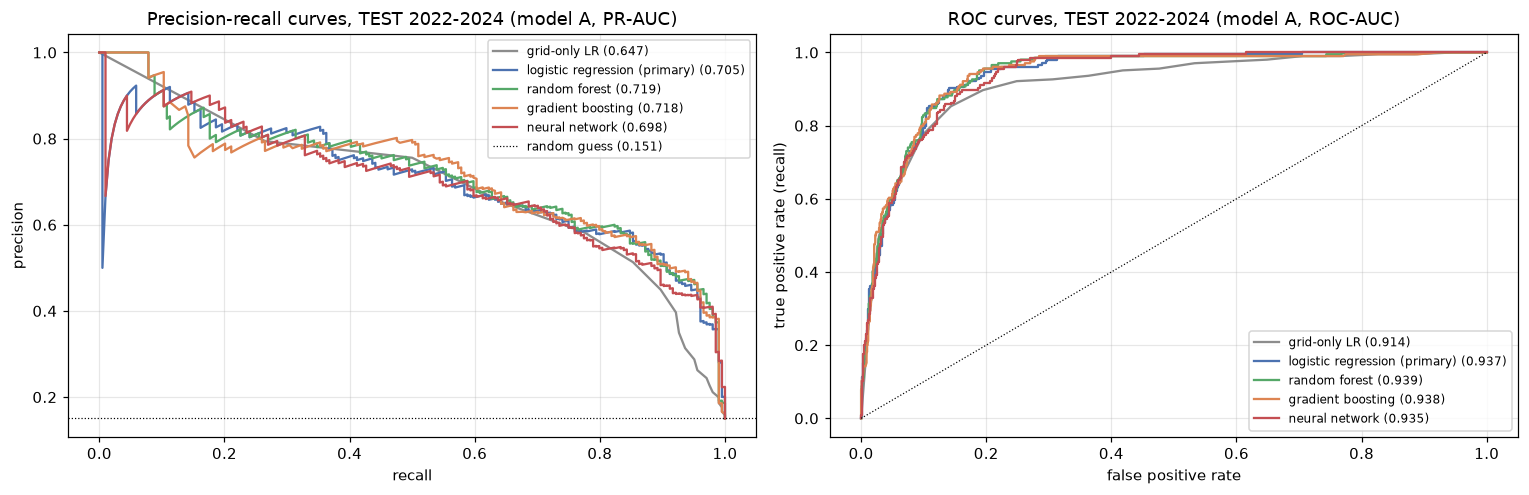

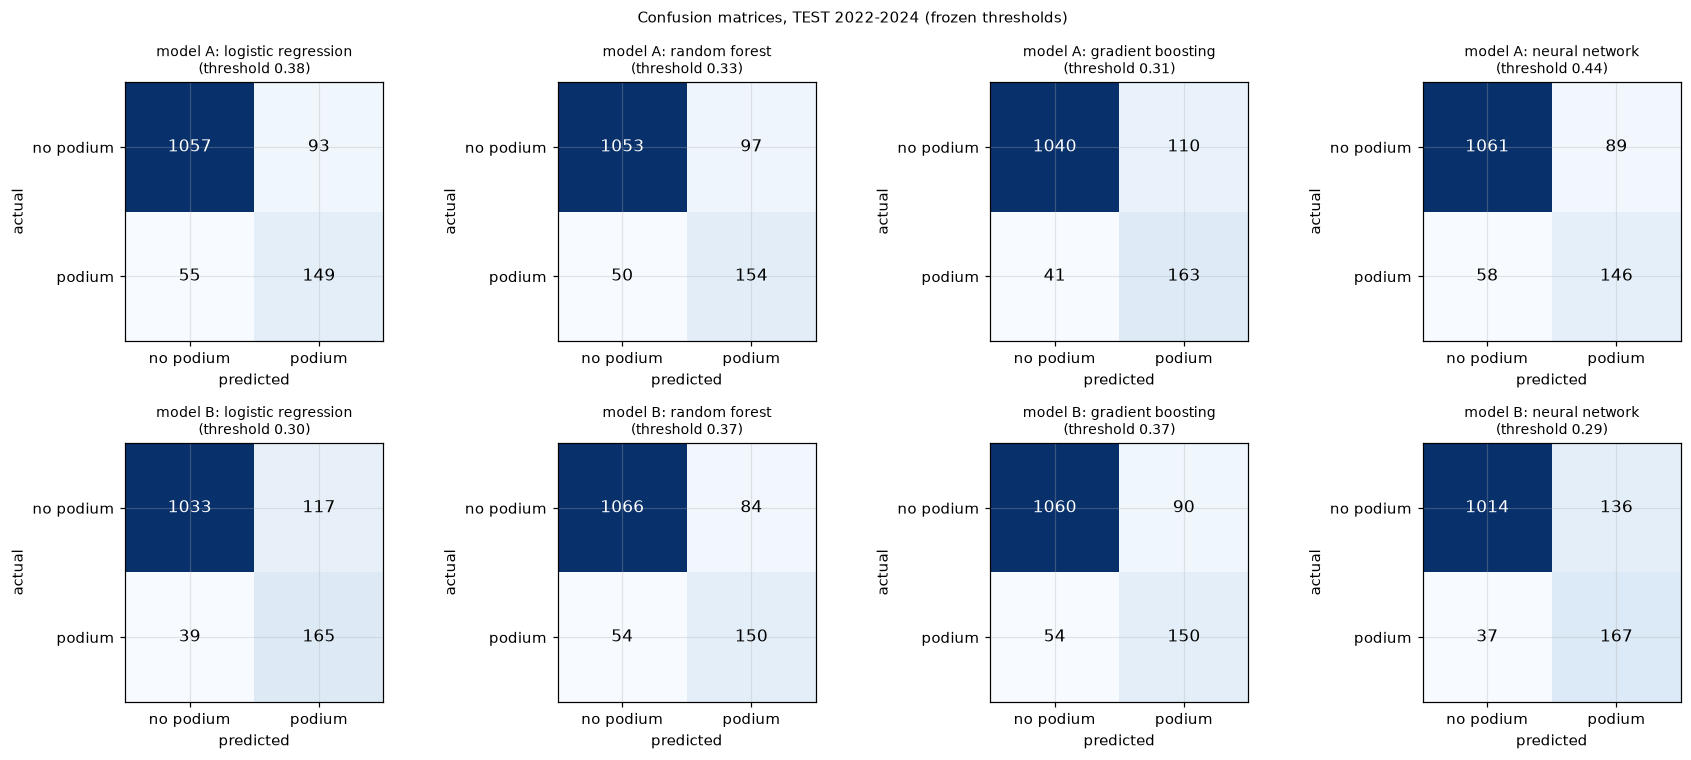

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for key in [("A", "grid-only LR")] + KEYS_A:
    p = TEST_PRED[key]
    prec, rec, _ = precision_recall_curve(y_test, p)
    fpr, tpr, _ = roc_curve(y_test, p)
    label = f"{key[1]}{' (primary)' if key == PRIMARY_MODEL_V2 else ''}"
    axes[0].plot(rec, prec, color=COLORS[key[1]], label=f"{label} ({average_precision_score(y_test, p):.3f})")
    axes[1].plot(fpr, tpr, color=COLORS[key[1]], label=f"{label} ({roc_auc_score(y_test, p):.3f})")
axes[0].axhline(y_test.mean(), color="black", ls=":", lw=0.8, label=f"random guess ({y_test.mean():.3f})")
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title("Precision-recall curves, TEST 2022-2024 (model A, PR-AUC)")
axes[1].plot([0, 1], [0, 1], color="black", ls=":", lw=0.8)
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate (recall)")
axes[1].set_title("ROC curves, TEST 2022-2024 (model A, ROC-AUC)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for row, keys in enumerate([KEYS_A, KEYS_B]):
    for ax, key in zip(axes[row], keys):
        cm = confusion_matrix(y_test, (TEST_PRED[key] >= TEST_THRESHOLDS[key]).astype(int))
        ax.imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
        ax.set_xticks([0, 1], ["no podium", "podium"])
        ax.set_yticks([0, 1], ["no podium", "podium"])
        ax.set_xlabel("predicted")
        ax.set_ylabel("actual")
        ax.set_title(f"model {key[0]}: {key[1]}\n(threshold {TEST_THRESHOLDS[key]:.2f})", fontsize=9)
plt.suptitle("Confusion matrices, TEST 2022-2024 (frozen thresholds)", fontsize=10)
plt.tight_layout()
plt.show()

## 7.6 Training vs cross-validation vs validation vs test

The same frozen models scored on four kinds of rows: their own training rows (optimistic), the forward-chaining folds (cross-validation mean; F1 from the out-of-fold predictions), the validation seasons 2019–2021 and the test seasons 2022–2024.

PR-AUC train  PR-AUC CV  PR-AUC validation  PR-AUC test  ROC-AUC train  ROC-AUC validation  ROC-AUC test  F1 train  F1 CV (out-of-fold)  F1 validation  F1 test  Brier validation  Brier test
model family                                                                                                                                                                                                            
A     logistic regression        0.6876     0.7032             0.7350       0.7047         0.9300              0.9365        0.9374    0.6632               0.6843         0.7161   0.6682            0.0647      0.0696
      random forest              0.6991     0.6867             0.7354       0.7192         0.9347              0.9386        0.9386    0.6731               0.6724         0.7216   0.6769            0.0633      0.0691
      gradient boosting          0.7050     0.6937             0.7326       0.7180         0.9357              0.9384        0.9379    0.6738               0.6685         0.7200   0.6834            0.0631      0.0683
      neural network             0.7027     0.7062             0.7385       0.6979         0.9371              0.9354        0.9346    0.6641               0.6777         0.7188   0.6651            0.0648      0.0718
B     logistic regression        0.5632     0.6896             0.7210       0.7122         0.8985              0.9293        0.9374    0.5792               0.6839         0.7186   0.6790            0.0663      0.0701
      random forest              0.5796     0.6887             0.7299       0.7250         0.9016              0.9367        0.9405    0.5715               0.6773         0.7306   0.6849            0.0652      0.0700
      gradient boosting          0.5787     0.6897             0.7289       0.7175         0.9029              0.9328        0.9388    0.5722               0.6717         0.7282   0.6757            0.0648      0.0687
      neural network             0.5807     0.7009             0.7306       0.7035         0.9033              0.9338        0.9365    0.5865               0.6748         0.7122   0.6588            0.0653      0.0704

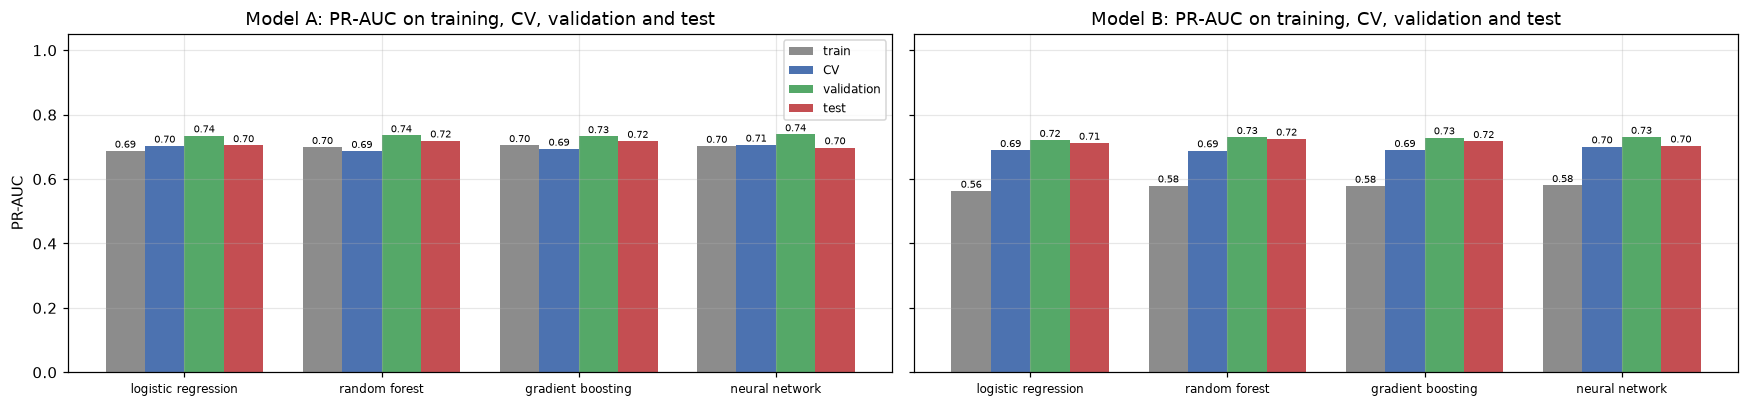

In [134]:
four = []
for key in KEYS_A + KEYS_B:
    m, family = key
    p_tr = predict_final(FINAL_V2[key], TRAIN_ROWS[m], f"{m} {family} v2 training rows")
    p_oof = OOF[(m, family, CHOSEN_V2[key]["setting"])]
    t = THRESHOLDS_V2[key]
    four.append({"model": m, "family": family,
                 "PR-AUC train": average_precision_score(TRAIN_ROWS[m]["podium"], p_tr), "PR-AUC CV": CHOSEN_V2[key]["cv mean PR-AUC"],
                 "PR-AUC validation": average_precision_score(y_val, VAL_PRED_V2[key]), "PR-AUC test": average_precision_score(y_test, TEST_PRED[key]),
                 "ROC-AUC train": roc_auc_score(TRAIN_ROWS[m]["podium"], p_tr), "ROC-AUC validation": roc_auc_score(y_val, VAL_PRED_V2[key]),
                 "ROC-AUC test": roc_auc_score(y_test, TEST_PRED[key]),
                 "F1 train": f1_score(TRAIN_ROWS[m]["podium"], p_tr >= t), "F1 CV (out-of-fold)": f1_score(y_oof[m], p_oof >= t),
                 "F1 validation": f1_score(y_val, VAL_PRED_V2[key] >= t), "F1 test": f1_score(y_test, TEST_PRED[key] >= t),
                 "Brier validation": brier_score_loss(y_val, VAL_PRED_V2[key]), "Brier test": brier_score_loss(y_test, TEST_PRED[key])})
four = pd.DataFrame(four).set_index(["model", "family"])
display(four.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), sharey=True)
for ax, m in zip(axes, ["A", "B"]):
    sub = four.loc[m]
    x = np.arange(len(FAMILIES))
    for i, (col, color) in enumerate([("PR-AUC train", "#8C8C8C"), ("PR-AUC CV", "#4C72B0"), ("PR-AUC validation", "#55A868"),
                                      ("PR-AUC test", "#C44E52")]):
        ax.bar(x + (i - 1.5) * 0.2, sub[col], 0.2, color=color, label=col.replace("PR-AUC ", ""))
        for xi, v in zip(x, sub[col]):
            ax.text(xi + (i - 1.5) * 0.2, v + 0.01, f"{v:.2f}", ha="center", fontsize=6.5)
    ax.set_xticks(x, FAMILIES, fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"Model {m}: PR-AUC on training, CV, validation and test")
axes[0].set_ylabel("PR-AUC")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7.7 Test comparisons with paired race-resampling intervals

Differences in test PR-AUC, each with a 95% interval from resampling the 68 test races 500 times (the same resamples for both models). A difference only counts if the interval **excludes 0**.

,question,model,compared with,test PR-AUC difference,95% interval,clearly different?
0,better than the grid-only baseline?,A logistic regression,A grid-only LR,0.0573,"[+0.0087, +0.1044]",yes
1,better than the grid-only baseline?,A random forest,A grid-only LR,0.0718,"[+0.0359, +0.1084]",yes
2,better than the grid-only baseline?,A gradient boosting,A grid-only LR,0.0706,"[+0.0419, +0.0975]",yes
3,better than the grid-only baseline?,A neural network,A grid-only LR,0.0506,"[+0.0060, +0.0949]",yes
4,different from the primary model?,A random forest,A logistic regression,0.0145,"[-0.0169, +0.0437]",no (interval includes 0)
5,different from the primary model?,A gradient boosting,A logistic regression,0.0133,"[-0.0165, +0.0434]",no (interval includes 0)
6,different from the primary model?,A neural network,A logistic regression,-0.0067,"[-0.0283, +0.0135]",no (interval includes 0)
7,model B (1950-2018) vs model A (2003-2018),B logistic regression,A logistic regression,0.0075,"[-0.0059, +0.0231]",no (interval includes 0)
8,model B (1950-2018) vs model A (2003-2018),B random forest,A random forest,0.0058,"[-0.0076, +0.0193]",no (interval includes 0)
9,model B (1950-2018) vs model A (2003-2018),B gradient boosting,A gradient boosting,-0.0005,"[-0.0126, +0.0117]",no (interval includes 0)


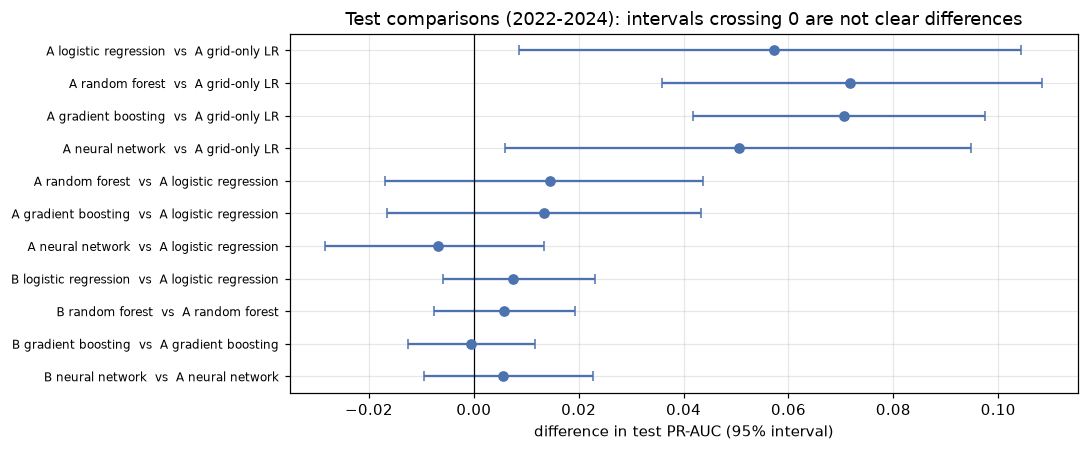

In [135]:
cmp_rows = []


def add_comparison(question, base_key, new_key):
    d, lo, hi = paired_difference(TEST_PRED[base_key], TEST_PRED[new_key], y=y_test, boot=TEST_BOOT)
    cmp_rows.append({"question": question, "model": f"{new_key[0]} {new_key[1]}", "compared with": f"{base_key[0]} {base_key[1]}",
                     "test PR-AUC difference": d, "low": lo, "high": hi, "95% interval": f"[{lo:+.4f}, {hi:+.4f}]",
                     "clearly different?": "yes" if lo > 0 or hi < 0 else "no (interval includes 0)"})


for key in KEYS_A:
    add_comparison("better than the grid-only baseline?", ("A", "grid-only LR"), key)
for key in KEYS_A:
    if key != PRIMARY_MODEL_V2:
        add_comparison("different from the primary model?", PRIMARY_MODEL_V2, key)
for family in FAMILIES:
    add_comparison("model B (1950-2018) vs model A (2003-2018)", ("A", family), ("B", family))
comparisons = pd.DataFrame(cmp_rows)
display(comparisons.drop(columns=["low", "high"]).round(4))

fig, ax = plt.subplots(figsize=(10, 4.2))
y_pos = np.arange(len(comparisons))[::-1]
ax.errorbar(comparisons["test PR-AUC difference"], y_pos,
            xerr=[comparisons["test PR-AUC difference"] - comparisons["low"], comparisons["high"] - comparisons["test PR-AUC difference"]],
            fmt="o", color="#4C72B0", capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y_pos, [f"{r['model']}  vs  {r['compared with']}" for _, r in comparisons.iterrows()], fontsize=8)
ax.set_xlabel("difference in test PR-AUC (95% interval)")
ax.set_title("Test comparisons (2022-2024): intervals crossing 0 are not clear differences")
plt.tight_layout()
plt.show()

## 7.8 Did the 2022 regulation change hurt the predictions?

2022 brought completely new car rules. If the models had learned patterns that only held under the old cars, their scores should drop from 2022. We look at:
- **validation (2019–2021) vs test (2022–2024)** for every model, with a 95% interval for the difference (the two periods have different races, so both are resampled independently);
- **season by season** (2019–2024) for the primary model and the grid-only baseline, each with a 95% race-resampling interval.

A drop could also come from other changes (which teams dominated, the number of races), so this can show an *association*, not a cause.

,model,validation PR-AUC,test PR-AUC,test - validation,95% interval,clear change?
0,A grid-only LR,0.6765,0.6474,-0.0291,"[-0.1285, +0.0683]",no (interval includes 0)
1,A logistic regression,0.7350,0.7047,-0.0303,"[-0.1346, +0.0829]",no (interval includes 0)
2,A random forest,0.7354,0.7192,-0.0162,"[-0.1188, +0.0992]",no (interval includes 0)
3,A gradient boosting,0.7326,0.7180,-0.0146,"[-0.1238, +0.1001]",no (interval includes 0)
4,A neural network,0.7385,0.6979,-0.0405,"[-0.1409, +0.0723]",no (interval includes 0)
5,B logistic regression,0.7210,0.7122,-0.0088,"[-0.1135, +0.1077]",no (interval includes 0)
6,B random forest,0.7299,0.7250,-0.0050,"[-0.1112, +0.1143]",no (interval includes 0)
7,B gradient boosting,0.7289,0.7175,-0.0114,"[-0.1143, +0.1006]",no (interval includes 0)
8,B neural network,0.7306,0.7035,-0.0271,"[-0.1319, +0.0861]",no (interval includes 0)


,season,races,rows,podium rate,primary PR-AUC,primary low,primary high,grid-only PR-AUC,grid-only low,grid-only high
0,2019,21,420,0.150,0.737,0.586,0.872,0.754,0.644,0.868
1,2020,17,340,0.150,0.726,0.554,0.898,0.633,0.479,0.810
2,2021,22,439,0.150,0.742,0.614,0.866,0.645,0.525,0.774
3,2022,22,439,0.150,0.696,0.606,0.791,0.616,0.543,0.714
4,2023,22,438,0.151,0.783,0.719,0.850,0.678,0.602,0.779
5,2024,24,477,0.151,0.645,0.545,0.779,0.657,0.547,0.772


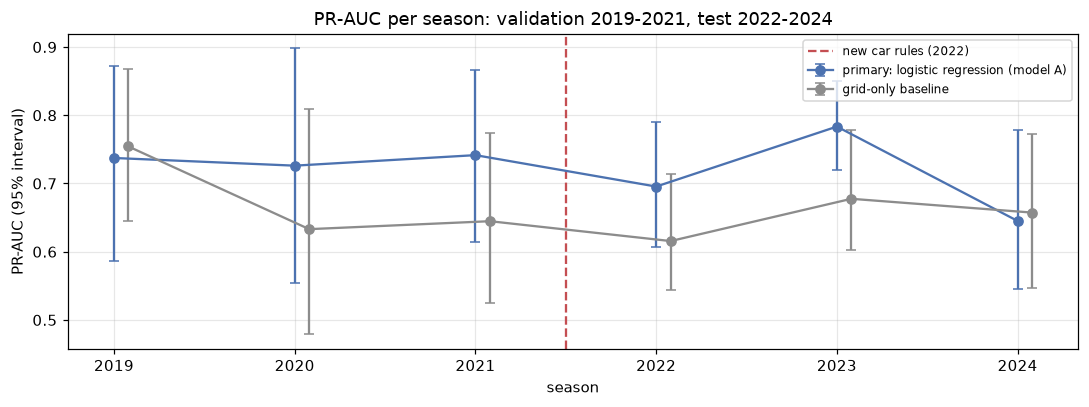

In [136]:
def period_difference(p_val, p_test, n=500):
    rng = np.random.default_rng(SEED)
    vr, tr_ = np.unique(val_race), np.unique(test_race)
    d = []
    for _ in range(n):
        iv = np.concatenate([np.flatnonzero(val_race == r) for r in rng.choice(vr, len(vr))])
        it = np.concatenate([np.flatnonzero(test_race == r) for r in rng.choice(tr_, len(tr_))])
        d.append(average_precision_score(y_test[it], p_test[it]) - average_precision_score(y_val[iv], p_val[iv]))
    return average_precision_score(y_test, p_test) - average_precision_score(y_val, p_val), *np.percentile(d, [2.5, 97.5])


period = []
for key in [("A", "grid-only LR")] + KEYS_A + KEYS_B:
    d, lo, hi = period_difference(VAL_PRED_V2[key], TEST_PRED[key])
    period.append({"model": f"{key[0]} {key[1]}", "validation PR-AUC": average_precision_score(y_val, VAL_PRED_V2[key]),
                   "test PR-AUC": average_precision_score(y_test, TEST_PRED[key]), "test - validation": d,
                   "95% interval": f"[{lo:+.4f}, {hi:+.4f}]", "clear change?": "yes" if lo > 0 or hi < 0 else "no (interval includes 0)"})
display(pd.DataFrame(period).round(4))

seasons = pd.concat([VAL_ROWS.assign(p_primary=VAL_PRED_V2[PRIMARY_MODEL_V2], p_grid=VAL_PRED_V2[("A", "grid-only LR")]),
                     TEST_ROWS.assign(p_primary=TEST_PRED[PRIMARY_MODEL_V2], p_grid=TEST_PRED[("A", "grid-only LR")])])
season_rows = []
rng_season = np.random.default_rng(SEED)
for year, g in seasons.groupby("year"):
    races = g["raceId"].unique()
    row = {"season": year, "races": len(races), "rows": len(g), "podium rate": g["podium"].mean()}
    for col, name in [("p_primary", "primary"), ("p_grid", "grid-only")]:
        boot = []
        for _ in range(500):
            idx = np.concatenate([np.flatnonzero(g["raceId"].to_numpy() == r) for r in rng_season.choice(races, len(races))])
            boot.append(average_precision_score(g["podium"].to_numpy()[idx], g[col].to_numpy()[idx]))
        row[f"{name} PR-AUC"] = average_precision_score(g["podium"], g[col])
        row[f"{name} low"], row[f"{name} high"] = np.percentile(boot, [2.5, 97.5])
    season_rows.append(row)
season_table = pd.DataFrame(season_rows)
display(season_table.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
for name, color in [("primary", "#4C72B0"), ("grid-only", "#8C8C8C")]:
    ax.errorbar(season_table["season"] + (0.08 if name == "grid-only" else 0), season_table[f"{name} PR-AUC"],
                yerr=[season_table[f"{name} PR-AUC"] - season_table[f"{name} low"], season_table[f"{name} high"] - season_table[f"{name} PR-AUC"]],
                fmt="o-", color=color, capsize=3,
                label=f"{'primary: ' + PRIMARY_MODEL_V2[1] + ' (model A)' if name == 'primary' else 'grid-only baseline'}")
ax.axvline(2021.5, color="#C44E52", ls="--", label="new car rules (2022)")
ax.set_xlabel("season")
ax.set_ylabel("PR-AUC (95% interval)")
ax.set_title("PR-AUC per season: validation 2019-2021, test 2022-2024")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Probability quality on the test seasons, and the first freeze (v1) for comparison

Brier score and the sum of predicted probabilities per race (3 real podiums per race) on the test seasons. Then the **v1** models of section 6, frozen earlier, are scored on the test seasons too, **for comparison only**: the official results are the v2 ones above, and nothing is chosen from this table.

In [137]:
test_sums = pd.DataFrame({f"{k[0]} {k[1]}": pd.Series(TEST_PRED[k]).groupby(test_race).sum().to_numpy() for k in KEYS_A + KEYS_B})
display(pd.DataFrame({"Brier (test)": {f"{k[0]} {k[1]}": brier_score_loss(y_test, TEST_PRED[k]) for k in KEYS_A + KEYS_B},
                      "mean probability sum per race": test_sums.mean(), "min": test_sums.min(), "max": test_sums.max()}).round(3))

v1_models, v1_manifest = (loaded_models, manifest)
assert v1_manifest["frozen fingerprint"] == FROZEN_FINGERPRINT
v1_rows = []
for m in v1_models.values():
    key = m["key"]
    if key[1] == "grid-only LR":
        continue
    p = m["predict"](TEST_ROWS)
    v1_rows.append({"model": key[0], "family": key[1], "v1 setting": str(CHOSEN[key]["params"]),
                    "v1 test PR-AUC": average_precision_score(y_test, p), "v2 test PR-AUC": average_precision_score(y_test, TEST_PRED[key]),
                    "v1 test F1": f1_score(y_test, p >= m["threshold"]), "v2 test F1": f1_score(y_test, TEST_PRED[key] >= TEST_THRESHOLDS[key]),
                    "setting changed in v2": CHOSEN[key]["params"] != CHOSEN_V2[key]["params"]})
print("First freeze (v1, section 6) on the test seasons - for comparison only, not used for any decision:")
display(pd.DataFrame(v1_rows).round(4))
TEST_EVALUATED_WITH = FROZEN_V2_FINGERPRINT
print(f"Test evaluation complete with the v2 freeze {TEST_EVALUATED_WITH[:16]}... ; no model, setting or threshold was changed afterwards.")

,Brier (test),mean probability sum per race,min,max
A logistic regression,0.070,3.265,2.374,3.939
A random forest,0.069,3.048,2.219,3.542
A gradient boosting,0.068,3.071,2.504,3.563
A neural network,0.072,3.314,2.623,3.967
B logistic regression,0.070,3.073,2.425,3.540
B random forest,0.070,3.166,2.467,3.532
B gradient boosting,0.069,3.097,2.452,3.573
B neural network,0.070,3.116,2.434,3.679


First freeze (v1, section 6) on the test seasons - for comparison only, not used for any decision:


,model,family,v1 setting,v1 test PR-AUC,v2 test PR-AUC,v1 test F1,v2 test F1,setting changed in v2
0,A,logistic regression,"{'C': 1, 'class_weight': None}",0.7047,0.7047,0.6682,0.6682,False
1,A,random forest,"{'max_depth': 6, 'min_samples_leaf': 50, 'max_features':...",0.7132,0.7192,0.6773,0.6769,True
2,A,gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_sample...",0.7096,0.7180,0.6667,0.6834,True
3,A,neural network,"{'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.001}",0.7003,0.6979,0.6681,0.6651,True
4,B,logistic regression,"{'C': 0.1, 'class_weight': None}",0.7122,0.7122,0.6790,0.6790,False
5,B,random forest,"{'max_depth': 6, 'min_samples_leaf': 50, 'max_features':...",0.7162,0.7250,0.6641,0.6849,True
6,B,gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_sample...",0.7055,0.7175,0.6940,0.6757,True
7,B,neural network,"{'hidden': (16,), 'dropout': 0.0, 'weight_decay': 0.0001}",0.6918,0.7035,0.6640,0.6588,True


Test evaluation complete with the v2 freeze 2ebc3457f47525af... ; no model, setting or threshold was changed afterwards.


## 7.9 Phase 4: what the test seasons show

All numbers are from the one test evaluation above (2022–2024: 68 races, 1,354 rows, 204 podiums). Nothing was changed after it.

**1. Which model performs best on the test seasons?**
- Highest test PR-AUC: random forest, model B (0.725), followed by random forest A (0.719), gradient boosting A (0.718) and B (0.718), logistic regression B (0.712), the primary logistic regression A (0.705), the network B (0.704) and A (0.698).
- **None of these differences is clear.** Compared with the primary model, random forest A is +0.015 (interval −0.017 to +0.044), gradient boosting A +0.013 (−0.017 to +0.043) and the network A −0.007 (−0.028 to +0.014). The honest answer is: **the four families perform about equally well on unseen seasons**, with the tree models slightly ahead in this sample.

**2. Does the primary model (logistic regression, model A) generalise?**
- **Yes, for ranking and probabilities.** Test PR-AUC 0.705 is in line with its cross-validation score (0.703) and below the validation score (0.735); that drop of −0.030 has an interval of −0.135 to +0.083, i.e. it is not distinguishable from noise. ROC-AUC is unchanged (0.937 on both validation and test). Brier 0.070, and probabilities sum to 3.27 per race on average (3 real podiums), so they are slightly too high, as on validation.
- **Yes/no predictions are weaker than on validation:** F1 0.668 (validation 0.716) at the frozen threshold, top-3-per-race F1 0.667. On the test seasons every model beats the rule "grid ≤ 3" in F1 (rule 0.649; models 0.659–0.685), which was **not** the case on validation; this comparison has no interval and is descriptive.

**3. Does old historical data help?**
- **No evidence either way.** Model B (1950–2018) minus model A (2003–2018) in test PR-AUC: logistic regression +0.008, random forest +0.006, gradient boosting −0.001, network +0.006; **every interval includes 0**. This agrees with cross-validation, validation and the training-window experiments of 6.10: fifty extra seasons neither help nor hurt measurably.

**4. Is the 2022 regulation change associated with lower performance?**
- Every model scores a little lower on 2022–2024 than on 2019–2021 (model A: −0.015 to −0.040 in PR-AUC), but **every interval includes 0** (they are wide, about ±0.10, because two different sets of about 60 races are compared).
- Season by season, the primary model scores 0.74 / 0.73 / 0.74 in 2019–2021 and **0.70 in 2022, 0.78 in 2023, 0.65 in 2024**. The best season of all six is a post-change season (2023, one dominant team), and the weakest is 2024, a season with several competitive teams. The grid-only baseline moves in a similar way (2023 0.68, 2024 0.66). So the scores depend more on **how predictable a season is** (how dominant one team is) than on the rule change itself. There is no clear evidence that the 2022 rules broke the models, but with 3 seasons of 22–24 races this can't be ruled out.

**5. Which models show overfitting?**
- **No model shows clear overfitting.** For model A the training PR-AUC (0.69–0.71) is close to cross-validation (0.69–0.71) and to the test score (0.70–0.72). The v2 tree settings are shallower than v1 (random forest depth 4 with leaves of at least 100 rows; boosting with 3 leaves per tree), and their training-vs-CV gap shrank (gradient boosting: 0.736 → 0.705 on training rows, vs 0.694 in CV).
- The network A dropped most from validation to test (0.738 → 0.698), but the drop is within noise and it also had the highest validation score, which is partly luck.
- Model B's training PR-AUC is **lower** (0.56–0.58) than its other scores: its training rows include the 1950s–1990s, which are harder to predict. That is a property of the old data, not overfitting.

**6. Do the improvements over the grid-only baseline remain?**
- **Yes, and more clearly than on validation.** On the test seasons all four model-A families beat the grid-only baseline (PR-AUC 0.647) with intervals entirely above 0: logistic regression +0.057 (+0.009 to +0.104), random forest +0.072 (+0.036 to +0.108), gradient boosting +0.071 (+0.042 to +0.098), network +0.051 (+0.006 to +0.095). On validation the network's gain was not clear.
- So qualifying pace, standings and form **do** add real information beyond the starting position, and this holds on seasons the models never saw, under new car rules.

**Comparison with the first freeze (v1, for information only):** where the setting changed, v2 scores slightly higher on the test seasons for the tree models (e.g. gradient boosting A 0.710 → 0.718) and model B's network (0.692 → 0.704), and slightly lower for model A's network (0.700 → 0.698). These differences are small, have no interval, and did not and do not influence any choice; the logistic regressions are identical in v1 and v2.

**Post-test, exploratory ideas (not applied; they would need new, unseen seasons to test fairly):**
- normalising each race's probabilities so they sum to 3 (they currently sum to 3.0–3.3);
- features describing how dominant the leading team is in the current season, since season predictability drives most of the score changes;
- evaluating on the 2025 season when its data becomes available, as a second genuine test.

## 7.10 The official prediction output: the three most likely podium finishers of each race

**Decision (taken after the test, about how results are presented, not about the model):** for a complete race, the official prediction is the **three drivers with the highest podium probabilities** from the frozen primary model (logistic regression, model A, v2). Nothing about the model changes: same pre-processing, settings, thresholds and fingerprints. This rule was already part of the frozen plan (6.8: "top-3 per race") and was evaluated on the test seasons in 7.5; on the test seasons it scores about the same as the threshold rule (F1 0.667 vs 0.668), so it is not chosen because it scored better. It is chosen because it matches the sport: every race has exactly 3 podium places.

What the outputs mean:
- **Complete race → the predicted podium:** the 3 most likely podium finishers. They are *not* a prediction of 1st, 2nd and 3rd place in that order; the model only estimates "podium or not".
- **A single driver → a podium probability** (e.g. 0.42), not a claim about the whole podium, because the top-3 rule needs every driver of the race.
- **Threshold rule (probability ≥ the frozen threshold) → secondary, academic result.** It answers "is this driver likely enough?" for each driver separately and can give any number of "yes" per race (242 for 204 real podiums on the test seasons). Its precision / recall / F1 stay reported in 6.9, 7.5 and 7.6.

Below: the race-level evaluation of the **already-frozen** predictions (`VAL_PRED_V2`, `TEST_PRED`); nothing is re-fitted. The comparison is the simplest possible podium pick: **the three drivers starting at the front of the grid**. Ties in probability within a race are broken by row order (grid position, then `driverId`), so the picks are deterministic.

In [138]:
def race_level(y, p, race):
    """Top-3 pick per race and how many of the 3 picks were real podium finishers."""
    picks = top3_per_race(p, race)
    correct = pd.Series(y * picks).groupby(race).sum()
    return picks, correct


def race_level_summary(name, y, p, race):
    picks, correct = race_level(y, p, race)
    return {"prediction": name, "races": len(correct), "top-3 F1": f1_score(y, picks),
            "correct podium picks per race (of 3)": correct.mean(),
            "races with all 3 right": int((correct == 3).sum()), "all 3 right %": 100 * (correct == 3).mean(),
            "races with at least 2 right %": 100 * (correct >= 2).mean(), "races with 0 right": int((correct == 0).sum())}


def correct_difference_interval(y, p_new, p_base, race, seed=SEED, n=500):
    """Paired race resampling of the difference in correct picks per race (per-race counts, so no grouping issue)."""
    diff = race_level(y, p_new, race)[1] - race_level(y, p_base, race)[1]
    rng = np.random.default_rng(seed)
    boots = [rng.choice(diff.to_numpy(), len(diff)).mean() for _ in range(n)]
    return diff.mean(), *np.percentile(boots, [2.5, 97.5])


OFFICIAL = PRIMARY_MODEL_V2
race_rows = []
for period, rows, preds, y, race in [("validation 2019-2021", VAL_ROWS, VAL_PRED_V2, y_val, val_race),
                                      ("TEST 2022-2024", TEST_ROWS, TEST_PRED, y_test, test_race)]:
    grid_score = -rows["grid"].to_numpy()                      # front of the grid first
    race_rows.append({"period": period, **race_level_summary("top 3 on the starting grid", y, grid_score, race)})
    for key in [OFFICIAL] + [k for k in KEYS_A if k != OFFICIAL]:
        label = f"{key[1]} (model {key[0]})" + ("  <- OFFICIAL" if key == OFFICIAL else "")
        race_rows.append({"period": period, **race_level_summary(label, y, preds[key], race)})
RACE_LEVEL = pd.DataFrame(race_rows)
print(f"Official output: the 3 most likely podium finishers per race, from {OFFICIAL[1]} (model {OFFICIAL[0]}, frozen v2 "
      f"{FROZEN_V2_FINGERPRINT[:16]}...). Race-level evaluation of the frozen predictions:")
display(RACE_LEVEL.round(3))

for period, rows, preds, y, race in [("validation 2019-2021", VAL_ROWS, VAL_PRED_V2, y_val, val_race),
                                      ("TEST 2022-2024", TEST_ROWS, TEST_PRED, y_test, test_race)]:
    d, lo, hi = correct_difference_interval(y, preds[OFFICIAL], -rows["grid"].to_numpy(), race)
    print(f"{period}: official pick minus grid pick = {d:+.3f} correct podium drivers per race "
          f"(95% race-resampling interval {lo:+.3f} to {hi:+.3f}) -> "
          f"{'clear' if lo > 0 or hi < 0 else 'not clear (interval includes 0)'}")

Official output: the 3 most likely podium finishers per race, from logistic regression (model A, frozen v2 2ebc3457f47525af...). Race-level evaluation of the frozen predictions:


,period,prediction,races,top-3 F1,correct podium picks per race (of 3),races with all 3 right,all 3 right %,races with at least 2 right %,races with 0 right
0,validation 2019-2021,top 3 on the starting grid,60,0.717,2.150,20,33.333,85.000,2
1,validation 2019-2021,logistic regression (model A) <- OFFICIAL,60,0.700,2.100,21,35.000,80.000,3
2,validation 2019-2021,random forest (model A),60,0.711,2.133,20,33.333,85.000,3
3,validation 2019-2021,gradient boosting (model A),60,0.711,2.133,21,35.000,83.333,3
4,validation 2019-2021,neural network (model A),60,0.711,2.133,22,36.667,81.667,3
5,TEST 2022-2024,top 3 on the starting grid,68,0.652,1.956,11,16.176,80.882,1
6,TEST 2022-2024,logistic regression (model A) <- OFFICIAL,68,0.667,2.000,16,23.529,77.941,1
7,TEST 2022-2024,random forest (model A),68,0.642,1.926,10,14.706,79.412,1
8,TEST 2022-2024,gradient boosting (model A),68,0.642,1.926,9,13.235,80.882,1
9,TEST 2022-2024,neural network (model A),68,0.627,1.882,12,17.647,72.059,1


validation 2019-2021: official pick minus grid pick = -0.050 correct podium drivers per race (95% race-resampling interval -0.183 to +0.067) -> not clear (interval includes 0)
TEST 2022-2024: official pick minus grid pick = +0.044 correct podium drivers per race (95% race-resampling interval -0.088 to +0.176) -> not clear (interval includes 0)


Races where the 3rd and 4th probabilities are exactly equal: validation 0, test 0 (ties would be broken by grid position, then driverId)
Official test picks: 204 drivers in 68 races; picks fingerprint 5de40cb915d35a8d...


,race,predicted podium driver,grid,podium probability,actually on the podium
0,2022 Bahrain Grand Prix,Max Verstappen,2,0.824,False
1,2022 Bahrain Grand Prix,Lewis Hamilton,5,0.577,True
2,2022 Bahrain Grand Prix,Charles Leclerc,1,0.506,True
3,2023 Bahrain Grand Prix,Max Verstappen,1,0.840,True
4,2023 Bahrain Grand Prix,Sergio Pérez,2,0.659,True
5,2023 Bahrain Grand Prix,Charles Leclerc,3,0.586,False
6,2024 Bahrain Grand Prix,Max Verstappen,1,0.882,True
7,2024 Bahrain Grand Prix,Charles Leclerc,2,0.675,False
8,2024 Bahrain Grand Prix,George Russell,3,0.471,False


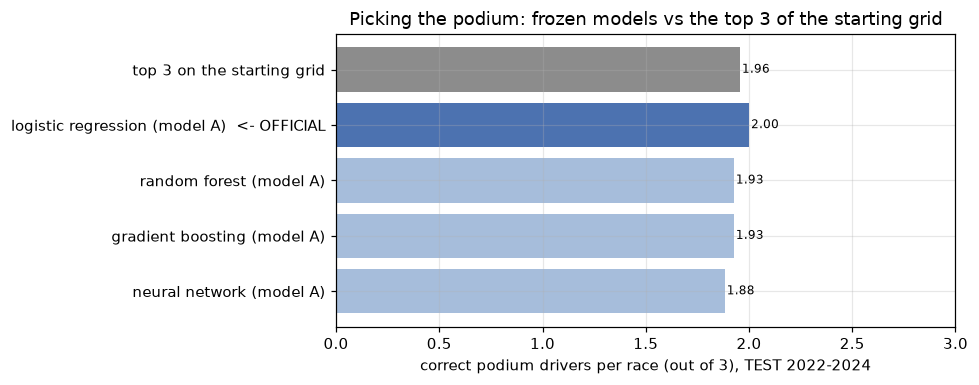

In [139]:
# Determinism: ties at the cut (3rd vs 4th most likely) and a fingerprint of the official test picks.
def tie_at_cut(p, race):
    s = pd.DataFrame({"p": p, "race": race}).sort_values(["race", "p"], ascending=[True, False])
    third_fourth = s.groupby("race")["p"].apply(lambda v: len(v) > 3 and v.iloc[2] == v.iloc[3])
    return int(third_fourth.sum())


official_test_picks = TEST_ROWS.loc[top3_per_race(TEST_PRED[OFFICIAL], test_race) == 1, ["raceId", "driverId"]]
assert len(official_test_picks) == 3 * len(np.unique(test_race))
PICKS_FINGERPRINT = hashlib.sha256(official_test_picks.sort_values(["raceId", "driverId"]).to_csv(index=False).encode()).hexdigest()
print(f"Races where the 3rd and 4th probabilities are exactly equal: validation {tie_at_cut(VAL_PRED_V2[OFFICIAL], val_race)}, "
      f"test {tie_at_cut(TEST_PRED[OFFICIAL], test_race)} (ties would be broken by grid position, then driverId)")
print(f"Official test picks: {len(official_test_picks)} drivers in {len(np.unique(test_race))} races; picks fingerprint {PICKS_FINGERPRINT[:16]}...")

# Example: the official prediction for the first race of each test season (names for reading only).
names = CLEAN["drivers"].assign(driver=CLEAN["drivers"]["forename"] + " " + CLEAN["drivers"]["surname"]).set_index("driverId")["driver"]
race_names = CLEAN["races"].set_index("raceId")
examples = []
for year in sorted(TEST_ROWS["year"].unique()):
    first_race = race_names[race_names["year"] == year].sort_values("round").index
    rid = next(r for r in first_race if r in set(TEST_ROWS["raceId"]))
    g = TEST_ROWS[TEST_ROWS["raceId"] == rid].assign(probability=TEST_PRED[OFFICIAL][TEST_ROWS["raceId"].to_numpy() == rid])
    g = g.sort_values("probability", ascending=False).head(3)
    for _, r in g.iterrows():
        examples.append({"race": f"{year} {race_names.loc[rid, 'name']}", "predicted podium driver": names[r["driverId"]],
                         "grid": int(r["grid"]), "podium probability": round(r["probability"], 3), "actually on the podium": bool(r["podium"])})
display(pd.DataFrame(examples))

fig, ax = plt.subplots(figsize=(9, 3.6))
test_part = RACE_LEVEL[RACE_LEVEL["period"] == "TEST 2022-2024"].set_index("prediction")
order = ["top 3 on the starting grid"] + [p for p in test_part.index if p != "top 3 on the starting grid"]
ax.barh(order, test_part.loc[order, "correct podium picks per race (of 3)"],
        color=["#8C8C8C"] + ["#4C72B0" if "OFFICIAL" in p else "#A6BDDB" for p in order[1:]])
for i, v in enumerate(test_part.loc[order, "correct podium picks per race (of 3)"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 3)
ax.set_xlabel("correct podium drivers per race (out of 3), TEST 2022-2024")
ax.set_title("Picking the podium: frozen models vs the top 3 of the starting grid")
plt.tight_layout()
plt.show()

**What the race-level evaluation shows** (frozen predictions; nothing re-fitted or chosen here):
- **Test 2022–2024, official pick:** top-3 F1 **0.667**, i.e. **2.00 of the 3 podium drivers** correctly picked per race on average; **all three right in 16 of 68 races (23.5%)**, at least two right in 78%, none right in 1 race.
- **Top 3 on the starting grid:** 1.96 correct per race, all three right in 11 races (16.2%).
- **The difference is not clear:** +0.044 correct picks per race for the official model, 95% interval −0.088 to +0.176. On the validation seasons it went the other way (grid 2.15 vs model 2.10, also not clear). So, **as a podium pick, the model is about as good as the front three on the grid.** Its advantage, shown in 7.7, is in **ranking and probabilities** across the whole field (PR-AUC 0.705 vs 0.647 for the grid-only baseline, a clear difference): it knows *how likely* each driver is, including fast cars starting further back, even when that rarely changes the top three.
- **Deterministic:** no race has equal 3rd and 4th probabilities in validation or test, and the picks have a fixed fingerprint (printed above).
- **Exact order is not predicted:** the three picks are the most likely podium finishers, not a forecast of 1st, 2nd and 3rd.

# 8. Exploratory, after the test: can podium selection be improved cheaply?

> **This section is exploratory and comes after the test evaluation.** The 2022–2024 results of section 7 have already been seen, so nothing here can claim an unbiased test improvement, and the test seasons are **not used** in this section. The validation seasons 2019–2021 have been explored before and are **not used** either. Everything is judged on the four historical forward-chaining folds (scoring 2011–2018, model A training seasons). The frozen v1/v2 models, their fingerprints, the primary model and the section-7 results are **unchanged**.

**Question:** do a nicer shape for the grid or a few *race-relative* features improve the actual podium pick (the 3 most likely drivers of each race)?

**Budget (fixed in advance): 8 configurations × 4 folds = 32 fits**, no neural network, no further tuning afterwards.

| # | Configuration | What changes vs the baseline |
|---|---|---|
| C0 | **baseline**: logistic regression, `C` = 1 (the frozen v2 primary setting), 21 inputs | nothing |
| C1 | + `log(grid)` | lets the linear model follow the steep drop from pole |
| C2 | + a compact spline of `grid` (4 knots, cubic) | a flexible grid curve |
| C3 | + relative team strength | each driver's team's rank **within the race** by `cons_points_share` and by `cons_podium_rate_5` |
| C4 | + relative qualifying pace | `gap_q1_pct` as a z-score **within the race** (how far from the field's typical pace) |
| C5 | + relative driver form | rank **within the race** by `drv_avg_finish_5` |
| C6 | + `log(grid)` and all race-relative features | C1 + C3 + C4 + C5 |
| C7 | reference: gradient boosting with the frozen v2 setting, 21 inputs | another existing model, unchanged |

**Why these are allowed:** every race-relative feature is computed **inside one race** from that race's **pre-race** features (standings after the previous race, form from earlier races, qualifying). No result of the race enters. The new columns are filled and scaled inside each fold, on that fold's training seasons only.

**Metrics** on each fold's scoring seasons: PR-AUC, ROC-AUC and three podium-pick measures for the top-3-per-race rule: **top-3 F1**, the **average number of correctly picked podium drivers per race** (0–3), and the **exact-three rate** (share of races where all three picks are right). Every race in these folds has exactly 3 podiums, so top-3 F1 = correct picks per race ÷ 3; both are shown because they read differently.

**Decision rule (fixed before the results):** a configuration is a candidate for a *future, independently evaluated* version only if (a) its mean top-3 F1 is higher than the baseline's, (b) it improves top-3 F1 in **at least 3 of the 4 folds**, (c) its mean PR-AUC is not lower, and (d) the 95% interval of its top-3 F1 gain, from resampling the 158 fold races (paired), excludes 0. Otherwise the existing model stays.

*Note:* rescaling each race's probabilities (e.g. so they add up to 3) keeps their order within the race, so it cannot change which three drivers are picked; it is not tested here as a way to improve the podium pick.

In [140]:
import json, time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import SplineTransformer

EXP_SEED = 42
EXP_FOLDS = [(2011, 2012), (2013, 2014), (2015, 2016), (2017, 2018)]     # the same scoring blocks as sections 6-7
frozen_v2_record = {"fingerprint": FROZEN_V2_FINGERPRINT, "models": FROZEN_V2}
LR_V2_SETTING = frozen_v2_record["models"]["A | logistic regression"]["settings"]
HGB_V2_SETTING = frozen_v2_record["models"]["A | gradient boosting"]["settings"]
print("frozen v2 record", frozen_v2_record["fingerprint"][:16], "| baseline LR setting", LR_V2_SETTING, "| HGB setting", HGB_V2_SETTING)


def add_race_relative(rows):
    """Race-relative features, each computed within one race from that race's pre-race features only."""
    r = rows.copy()
    by_race = r.groupby("raceId")
    r["log_grid"] = np.log(r["grid"])
    r["team_strength_rank"] = by_race["cons_points_share"].rank(ascending=False, pct=True)     # small = strongest team
    r["team_form_rank"] = by_race[CONS_FORM].rank(ascending=False, pct=True)
    gap = r["gap_q1_pct"]
    r["quali_pace_z"] = (gap - by_race["gap_q1_pct"].transform("mean")) / by_race["gap_q1_pct"].transform("std")
    r["driver_form_rank"] = by_race[DRV_FORM[1]].rank(ascending=True, pct=True)                # drv_avg_finish_5
    return r


EXP_ROWS = add_race_relative(TRAIN_A_ROWS)            # model-A training seasons 2003-2018 only
RELATIVE = ["team_strength_rank", "team_form_rank", "quali_pace_z", "driver_form_rank"]
CONFIGS = {
    "C0 baseline (LR, 21 inputs)": {"extra": [], "spline": False, "model": "lr"},
    "C1 + log(grid)": {"extra": ["log_grid"], "spline": False, "model": "lr"},
    "C2 + grid spline": {"extra": [], "spline": True, "model": "lr"},
    "C3 + relative team strength": {"extra": ["team_strength_rank", "team_form_rank"], "spline": False, "model": "lr"},
    "C4 + relative qualifying pace": {"extra": ["quali_pace_z"], "spline": False, "model": "lr"},
    "C5 + relative driver form": {"extra": ["driver_form_rank"], "spline": False, "model": "lr"},
    "C6 + log(grid) + all relative": {"extra": ["log_grid"] + RELATIVE, "spline": False, "model": "lr"},
    "C7 reference: gradient boosting (frozen v2 setting)": {"extra": [], "spline": False, "model": "hgb"},
}
assert len(CONFIGS) <= 8


def exp_pipeline(cfg):
    parts = [("base", make_preprocessor(scaled=cfg["model"] == "lr"), FINAL_FEATURES)]
    if cfg["extra"]:
        parts.append(("extra", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), cfg["extra"]))
    if cfg["spline"]:
        parts.append(("grid_spline", SplineTransformer(n_knots=4, degree=3), ["grid"]))
    model = (LogisticRegression(max_iter=5000, **LR_V2_SETTING) if cfg["model"] == "lr" else
             HistGradientBoostingClassifier(l2_regularization=1.0, early_stopping=False, random_state=EXP_SEED, **HGB_V2_SETTING))
    return Pipeline([("pre", ColumnTransformer(parts)), ("model", model)])


def podium_pick(y, p, race):
    picks = pd.DataFrame({"race": race, "y": y, "p": p})
    picks["pick"] = picks.groupby("race")["p"].rank(method="first", ascending=False) <= 3
    correct = picks[picks["pick"]].groupby("race")["y"].sum()
    return {"top-3 F1": f1_score(picks["y"], picks["pick"]), "correct per race": correct.mean(), "exact-3 rate": (correct == 3).mean()}


EXP_FOLD_SCORES, EXP_OOF = [], {}
t0 = time.time()
for name, cfg in CONFIGS.items():
    preds = []
    for k, (lo, hi) in enumerate(EXP_FOLDS):
        tr, sc = EXP_ROWS[EXP_ROWS["year"] < lo], EXP_ROWS[EXP_ROWS["year"].between(lo, hi)]
        assert tr["year"].max() < lo and set(tr["split"]) == {"train"}
        cols = FINAL_FEATURES + [c for c in cfg["extra"] if c not in FINAL_FEATURES]
        pipe = exp_pipeline(cfg).fit(tr[cols], tr["podium"])
        p = pipe.predict_proba(sc[cols])[:, 1]
        preds.append(p)
        EXP_FOLD_SCORES.append({"configuration": name, "fold": f"{lo}-{hi}", "PR-AUC": average_precision_score(sc["podium"], p),
                                "ROC-AUC": roc_auc_score(sc["podium"], p), **podium_pick(sc["podium"].to_numpy(), p, sc["raceId"].to_numpy())})
    EXP_OOF[name] = np.concatenate(preds)
EXP_FOLD_SCORES = pd.DataFrame(EXP_FOLD_SCORES)
print(f"{len(CONFIGS)} configurations x {len(EXP_FOLDS)} folds = {len(EXP_FOLD_SCORES)} fits in {time.time() - t0:.0f} s; "
      f"test and validation seasons not used.")

frozen v2 record 2ebc3457f47525af | baseline LR setting {'C': 1, 'class_weight': None} | HGB setting {'learning_rate': 0.1, 'max_leaf_nodes': 3, 'min_samples_leaf': 80, 'max_iter': 50}


8 configurations x 4 folds = 32 fits in 3 s; test and validation seasons not used.


In [141]:
oof_rows = pd.concat([EXP_ROWS[EXP_ROWS["year"].between(lo, hi)] for lo, hi in EXP_FOLDS])
oof_y, oof_race = oof_rows["podium"].to_numpy(), oof_rows["raceId"].to_numpy()
rng_exp = np.random.default_rng(EXP_SEED)
oof_races = np.unique(oof_race)
EXP_BOOT = []                                         # resampled races; each copy gets its own id, so a race drawn twice stays two races
for _ in range(500):
    draw = rng_exp.choice(oof_races, len(oof_races))
    idx = [np.flatnonzero(oof_race == r) for r in draw]
    EXP_BOOT.append((np.concatenate(idx), np.concatenate([np.full(len(i), j) for j, i in enumerate(idx)])))
base = "C0 baseline (LR, 21 inputs)"


def top3_f1_gain_interval(name):
    gains = []
    for idx, race_copy in EXP_BOOT:
        a = podium_pick(oof_y[idx], EXP_OOF[base][idx], race_copy)
        b = podium_pick(oof_y[idx], EXP_OOF[name][idx], race_copy)
        gains.append(b["top-3 F1"] - a["top-3 F1"])
    return np.percentile(gains, [2.5, 97.5])


mean = EXP_FOLD_SCORES.groupby("configuration", sort=False)[["PR-AUC", "ROC-AUC", "top-3 F1", "correct per race", "exact-3 rate"]].mean()
wide = EXP_FOLD_SCORES.pivot(index="configuration", columns="fold", values="top-3 F1").loc[mean.index]
wide_pr = EXP_FOLD_SCORES.pivot(index="configuration", columns="fold", values="PR-AUC").loc[mean.index]
summary_rows = []
for name in mean.index:
    gain_folds = wide.loc[name] - wide.loc[base]
    row = {"configuration": name, "CV PR-AUC": mean.loc[name, "PR-AUC"], "CV ROC-AUC": mean.loc[name, "ROC-AUC"],
           "CV top-3 F1": mean.loc[name, "top-3 F1"], "correct podium picks per race": mean.loc[name, "correct per race"],
           "exact-3 rate": mean.loc[name, "exact-3 rate"],
           "top-3 F1 gain vs C0": mean.loc[name, "top-3 F1"] - mean.loc[base, "top-3 F1"],
           "PR-AUC gain vs C0": mean.loc[name, "PR-AUC"] - mean.loc[base, "PR-AUC"],
           "folds improved (top-3 F1)": f"{int((gain_folds > 0).sum())} of 4" if name != base else "-",
           "folds improved (PR-AUC)": f"{int((wide_pr.loc[name] > wide_pr.loc[base]).sum())} of 4" if name != base else "-"}
    if name != base:
        lo, hi = top3_f1_gain_interval(name)
        row["top-3 F1 gain, 95% interval (158 races)"] = f"[{lo:+.4f}, {hi:+.4f}]"
        row["meets the decision rule?"] = ("yes" if row["top-3 F1 gain vs C0"] > 0 and (gain_folds > 0).sum() >= 3
                                           and row["PR-AUC gain vs C0"] >= 0 and lo > 0 else "no")
    summary_rows.append(row)
EXP_SUMMARY = pd.DataFrame(summary_rows).set_index("configuration")
print("Historical forward-chaining CV, model A (scoring 2011-2018; 158 races, 474 podiums). Means over the 4 folds:")
display(EXP_SUMMARY.round(4))
print("Top-3 F1 per fold:")
display(wide.round(4))
print("PR-AUC per fold:")
display(wide_pr.round(4))

Historical forward-chaining CV, model A (scoring 2011-2018; 158 races, 474 podiums). Means over the 4 folds:


,CV PR-AUC,CV ROC-AUC,CV top-3 F1,correct podium picks per race,exact-3 rate,top-3 F1 gain vs C0,PR-AUC gain vs C0,folds improved (top-3 F1),folds improved (PR-AUC),"top-3 F1 gain, 95% interval (158 races)",meets the decision rule?
configuration,,,,,,,,,,,
"C0 baseline (LR, 21 inputs)",0.7032,0.9375,0.6658,1.9974,0.2649,0.0000,0.0000,-,-,NaN,NaN
C1 + log(grid),0.7160,0.9407,0.6676,2.0029,0.2519,0.0018,0.0128,2 of 4,4 of 4,"[-0.0127, +0.0148]",no
C2 + grid spline,0.7129,0.9405,0.6676,2.0029,0.2457,0.0018,0.0097,2 of 4,3 of 4,"[-0.0117, +0.0180]",no
C3 + relative team strength,0.7052,0.9377,0.6596,1.9788,0.2588,-0.0062,0.0020,0 of 4,3 of 4,"[-0.0148, +0.0000]",no
C4 + relative qualifying pace,0.6979,0.9369,0.6700,2.0101,0.2644,0.0042,-0.0053,2 of 4,2 of 4,"[-0.0063, +0.0148]",no
C5 + relative driver form,0.7028,0.9374,0.6575,1.9725,0.2396,-0.0083,-0.0004,0 of 4,1 of 4,"[-0.0190, +0.0000]",no
C6 + log(grid) + all relative,0.7142,0.9403,0.6742,2.0227,0.2524,0.0084,0.0109,3 of 4,3 of 4,"[-0.0063, +0.0232]",no
C7 reference: gradient boosting (frozen v2 setting),0.6937,0.9403,0.6592,1.9775,0.2333,-0.0066,-0.0095,2 of 4,2 of 4,"[-0.0274, +0.0148]",no


Top-3 F1 per fold:


fold,2011-2012,2013-2014,2015-2016,2017-2018
configuration,,,,
"C0 baseline (LR, 21 inputs)",0.6239,0.6228,0.7417,0.6748
C1 + log(grid),0.6154,0.6140,0.7500,0.6911
C2 + grid spline,0.6154,0.6140,0.7500,0.6911
C3 + relative team strength,0.6154,0.6228,0.7417,0.6585
C4 + relative qualifying pace,0.6239,0.6316,0.7417,0.6829
C5 + relative driver form,0.6154,0.6228,0.7333,0.6585
C6 + log(grid) + all relative,0.6154,0.6404,0.7583,0.6829
C7 reference: gradient boosting (frozen v2 setting),0.5897,0.6140,0.7500,0.6829


PR-AUC per fold:


fold,2011-2012,2013-2014,2015-2016,2017-2018
configuration,,,,
"C0 baseline (LR, 21 inputs)",0.6532,0.6864,0.7926,0.6808
C1 + log(grid),0.6688,0.6880,0.7988,0.7084
C2 + grid spline,0.6654,0.6858,0.7993,0.7011
C3 + relative team strength,0.6546,0.6855,0.7977,0.6831
C4 + relative qualifying pace,0.6591,0.6730,0.7759,0.6836
C5 + relative driver form,0.6526,0.6823,0.7961,0.6803
C6 + log(grid) + all relative,0.6713,0.6778,0.7949,0.7126
C7 reference: gradient boosting (frozen v2 setting),0.6575,0.6596,0.7694,0.6883


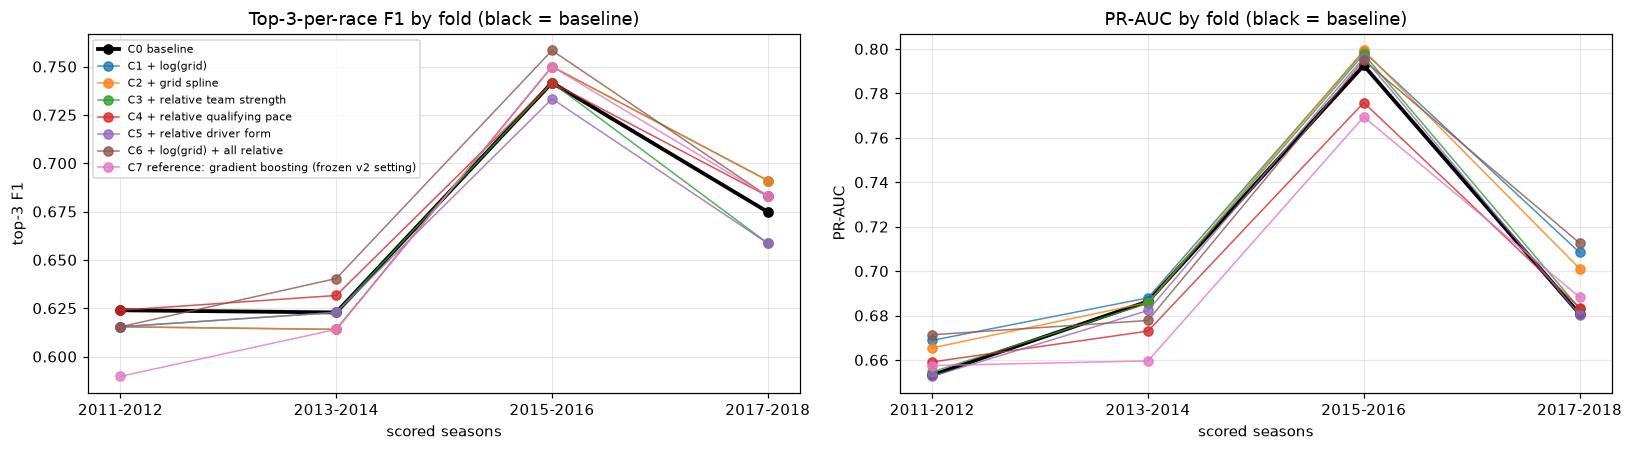

In [142]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
folds = list(wide.columns)
for name in wide.index:
    style = dict(lw=2.5, color="black") if name == base else dict(lw=1, alpha=0.8)
    axes[0].plot(folds, wide.loc[name], marker="o", label=name.split(" (")[0] if name == base else name, **style)
    axes[1].plot(folds, wide_pr.loc[name], marker="o", **style)
axes[0].set_title("Top-3-per-race F1 by fold (black = baseline)")
axes[0].set_ylabel("top-3 F1")
axes[1].set_title("PR-AUC by fold (black = baseline)")
axes[1].set_ylabel("PR-AUC")
for ax in axes:
    ax.set_xlabel("scored seasons")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**What the exploratory round shows** (historical folds only; validation and test seasons not used):
- **No configuration meets the decision rule.** Every 95% interval for the top-3 F1 gain includes 0. Picking the podium is hard to improve with these additions: the changes range from −0.008 to +0.008 in top-3 F1, i.e. at most about 4 more (or fewer) correct picks out of 474 podium places in 158 races.
- **The best podium pick, C6** (`log(grid)` + all race-relative features): top-3 F1 0.674 vs 0.666 (2.02 vs 2.00 correct picks per race), better in 3 of 4 folds, but the interval (−0.006 to +0.023) includes 0.
- **The only consistent change is `log(grid)` (C1):** PR-AUC +0.013, higher in **all 4 folds**; the spline (C2) is similar (+0.010, 3 of 4 folds). A better grid curve ranks the *whole field* more accurately, but it hardly changes **who** the top three are (top-3 F1 +0.002, 2 of 4 folds; exact-three rate 0.252 vs 0.265).
- **Relative team strength and relative driver form slightly hurt** the podium pick (0 of 4 folds improved); relative qualifying pace is neutral.
- **The gradient-boosting reference** (frozen v2 setting) scores below the logistic-regression baseline on these folds (PR-AUC 0.694 vs 0.703, top-3 F1 0.659 vs 0.666).
- **All three picks right happens in about one race in four** (exact-three rate 0.23–0.26) for every configuration; about 2 of the 3 podium drivers are picked correctly per race.

**Recommendation:** keep the existing frozen model (logistic regression, model A, v2) as the official model; this round does not justify a change. If a future version is built, the only idea worth carrying forward is `log(grid)` (a consistent ranking gain across all four historical folds). It would have to be evaluated on **new** seasons (2025 onwards), not on 2019–2024, which have already been used.

# 9. Feature-group ablation

**Question:** how much does each group of inputs contribute *on top of all the others*? For each group, the model is **refitted without that group** and scored again; the drop in performance is the group's **unique contribution**.

- **Models:** logistic regression (the primary model) and gradient boosting, model A, each with its **frozen v2 setting** (no re-tuning). These temporary models are only used here; the frozen models are not changed.
- **Data:** the four historical forward-chaining folds (scoring 2011–12, 13–14, 15–16, 17–18; each trained on the seasons before it, from 2003). Pre-processing is re-fitted inside every fold. The validation and test seasons are **not used**.
- **Groups** (the 21 model inputs, each missing-value flag kept with its features): **grid**, **qualifying**, **standings**, **form**, **context** (table below). A group is removed *after* pre-processing (the imputer needs all 18 raw columns to build the flags), so the remaining inputs are exactly as in the full model.
- **Scores:** PR-AUC, ROC-AUC, top-3-per-race F1, correct podium picks per race, exact-three rate, per fold and on average. **Drop = full model − model without the group** (positive = the group helps), with 95% intervals from resampling the 158 fold races (paired).
- **Correlated groups:** grid and qualifying (and standings and form) carry overlapping information. If one is removed, the other can partly replace it, so a small drop does **not** mean a group is useless on its own.

In [143]:
V2_MODELS, V2_MANIFEST = loaded_models_v2, manifest_v2
V2_RECORD = {"fingerprint": FROZEN_V2_FINGERPRINT, "models": FROZEN_V2}
V2_REFERENCE = {artifact_name(k): p.copy() for k, p in VAL_PRED_V2.items()}
for name in ["A_logistic_regression", "A_gradient_boosting"]:
    assert np.allclose(V2_MODELS[name]["predict"](VAL_ROWS), V2_REFERENCE[name], rtol=0, atol=1e-12)
assert "test" not in set(TRAIN_A_ROWS["split"]) | set(VAL_ROWS["split"])

INPUTS_SCALED = V2_MANIFEST["models"]["A_logistic_regression"]["model inputs (after pre-processing)"]
INPUTS_TREE = V2_MANIFEST["models"]["A_gradient_boosting"]["model inputs (after pre-processing)"]
INPUT_GROUPS = {
    "grid": ["grid", "pit_lane_start"],
    "qualifying": ["gap_q1_pct", "grid_minus_quali", "reached_q3", "no_q3_format", "quali_missing", "q1_time_missing"],
    "standings": ["drv_champ_pos", "cons_points_share", "drv_no_standing_yet", "cons_no_standing_yet"],
    "form": ["drv_podium_rate_5", "drv_avg_finish_5", "drv_dnf_rate_5", "cons_podium_rate_5", "drv_form_missing", "cons_form_missing"],
    "context": ["n_starters", "drv_experience", "drv_age"],
}
GROUP_OF = {c: g for g, cols in INPUT_GROUPS.items() for c in cols}
all_grouped = [c for cols in INPUT_GROUPS.values() for c in cols]
assert len(all_grouped) == len(set(all_grouped)) == 21 and set(all_grouped) == set(INPUTS_SCALED) == set(INPUTS_TREE)
print(f"Frozen v2 models loaded and verified (fingerprint {V2_RECORD['fingerprint'][:16]}...); "
      f"validation predictions reproduced; no test rows involved.")
display(pd.DataFrame([{"group": g, "inputs": ", ".join(cols), "count": len(cols)} for g, cols in INPUT_GROUPS.items()]))

Frozen v2 models loaded and verified (fingerprint 2ebc3457f47525af...); validation predictions reproduced; no test rows involved.


,group,inputs,count
0,grid,"grid, pit_lane_start",2
1,qualifying,"gap_q1_pct, grid_minus_quali, reached_q3, no_q3_format, ...",6
2,standings,"drv_champ_pos, cons_points_share, drv_no_standing_yet, c...",4
3,form,"drv_podium_rate_5, drv_avg_finish_5, drv_dnf_rate_5, con...",6
4,context,"n_starters, drv_experience, drv_age",3


In [144]:
def ablation_model(family, dropped):
    """Pre-processing (fitted in the fold) -> keep the inputs not in `dropped` -> model with the frozen v2 setting."""
    scaled = family == "logistic regression"
    keep = [c for c in (INPUTS_SCALED if scaled else INPUTS_TREE) if c not in dropped]
    model = (LogisticRegression(max_iter=5000, **LR_V2_SETTING) if scaled else
             HistGradientBoostingClassifier(l2_regularization=1.0, early_stopping=False, random_state=EXP_SEED, **HGB_V2_SETTING))
    return Pipeline([("pre", make_preprocessor(scaled=scaled)),
                     ("keep", ColumnTransformer([("keep", "passthrough", keep)], verbose_feature_names_out=False)),
                     ("model", model)])


ABL_FAMILIES = ["logistic regression", "gradient boosting"]
ABL_VARIANTS = {"full model": []} | {f"without {g}": cols for g, cols in INPUT_GROUPS.items()}
ABL_FOLD, ABL_OOF, ABL_FITS = [], {}, []
t0 = time.time()
for family in ABL_FAMILIES:
    for variant, dropped in ABL_VARIANTS.items():
        preds = []
        for lo, hi in EXP_FOLDS:
            tr, sc = EXP_ROWS[EXP_ROWS["year"] < lo], EXP_ROWS[EXP_ROWS["year"].between(lo, hi)]
            assert tr["year"].max() < lo and set(tr["split"]) == {"train"}       # earlier training seasons only
            pipe = ablation_model(family, dropped).fit(tr[FINAL_FEATURES], tr["podium"])
            ABL_FITS.append({"family": family, "variant": variant, "fold": f"{lo}-{hi}", "trained on": f"{tr['year'].min()}-{tr['year'].max()}",
                             "inputs used": pipe.named_steps["model"].n_features_in_})
            p = pipe.predict_proba(sc[FINAL_FEATURES])[:, 1]
            preds.append(p)
            ABL_FOLD.append({"family": family, "variant": variant, "fold": f"{lo}-{hi}",
                             "PR-AUC": average_precision_score(sc["podium"], p), "ROC-AUC": roc_auc_score(sc["podium"], p),
                             **podium_pick(sc["podium"].to_numpy(), p, sc["raceId"].to_numpy())})
        ABL_OOF[(family, variant)] = np.concatenate(preds)
ABL_FOLD = pd.DataFrame(ABL_FOLD)
# The full variants reproduce the section-8 baselines exactly (same folds, same settings, same pre-processing).
assert np.allclose(ABL_OOF[("logistic regression", "full model")], EXP_OOF["C0 baseline (LR, 21 inputs)"])
assert np.allclose(ABL_OOF[("gradient boosting", "full model")], EXP_OOF["C7 reference: gradient boosting (frozen v2 setting)"])
fits = pd.DataFrame(ABL_FITS)
assert (fits.loc[fits["variant"] == "full model", "inputs used"] == 21).all()
print(f"{len(fits)} ablation fits in {time.time() - t0:.0f} s; every fit used only seasons before its scoring fold; "
      f"inputs per variant: {fits.groupby('variant', sort=False)['inputs used'].first().to_dict()}")

48 ablation fits in 4 s; every fit used only seasons before its scoring fold; inputs per variant: {'full model': 21, 'without grid': 19, 'without qualifying': 15, 'without standings': 17, 'without form': 15, 'without context': 18}


In [145]:
# Paired race resampling over the 158 fold races (each race drawn keeps its own identity).
abl_races = np.unique(oof_race)
abl_rows_of = [np.flatnonzero(oof_race == r) for r in abl_races]
rng_abl = np.random.default_rng(EXP_SEED)
ABL_DRAWS = [rng_abl.choice(len(abl_races), len(abl_races)) for _ in range(500)]
ABL_DRAW_ROWS = [np.concatenate([abl_rows_of[j] for j in d]) for d in ABL_DRAWS]


def per_race_correct(p):
    picks = pd.DataFrame({"race": oof_race, "y": oof_y, "p": p})
    picks["pick"] = picks.groupby("race")["p"].rank(method="first", ascending=False) <= 3
    return picks[picks["pick"]].groupby("race")["y"].sum().reindex(abl_races).to_numpy()


abl_rows = []
for family in ABL_FAMILIES:
    full_p = ABL_OOF[(family, "full model")]
    full_c = per_race_correct(full_p)
    means = ABL_FOLD[ABL_FOLD["family"] == family].groupby("variant", sort=False)[["PR-AUC", "ROC-AUC", "top-3 F1", "correct per race", "exact-3 rate"]].mean()
    per_fold = ABL_FOLD[ABL_FOLD["family"] == family].pivot(index="variant", columns="fold", values="PR-AUC")
    per_fold_c = ABL_FOLD[ABL_FOLD["family"] == family].pivot(index="variant", columns="fold", values="correct per race")
    for variant in ABL_VARIANTS:
        row = {"family": family, "variant": variant, **means.loc[variant].to_dict()}
        if variant != "full model":
            p = ABL_OOF[(family, variant)]
            c = per_race_correct(p)
            pr_d = [average_precision_score(oof_y[i], full_p[i]) - average_precision_score(oof_y[i], p[i]) for i in ABL_DRAW_ROWS]
            c_d = [full_c[d].mean() - c[d].mean() for d in ABL_DRAWS]
            e_d = [(full_c[d] == 3).mean() - (c[d] == 3).mean() for d in ABL_DRAWS]
            row.update({
                "PR-AUC drop": means.loc["full model", "PR-AUC"] - means.loc[variant, "PR-AUC"],
                "PR-AUC drop 95% interval": np.percentile(pr_d, [2.5, 97.5]),
                "ROC-AUC drop": means.loc["full model", "ROC-AUC"] - means.loc[variant, "ROC-AUC"],
                "top-3 F1 drop": means.loc["full model", "top-3 F1"] - means.loc[variant, "top-3 F1"],
                "correct-picks drop": full_c.mean() - c.mean(), "correct-picks drop 95% interval": np.percentile(c_d, [2.5, 97.5]),
                "exact-3 drop": (full_c == 3).mean() - (c == 3).mean(), "exact-3 drop 95% interval": np.percentile(e_d, [2.5, 97.5]),
                "folds where removal lowered PR-AUC": int((per_fold.loc["full model"] > per_fold.loc[variant]).sum()),
                "folds where removal lowered correct picks": int((per_fold_c.loc["full model"] > per_fold_c.loc[variant]).sum())})
        abl_rows.append(row)
ABLATION = pd.DataFrame(abl_rows)
fmt = lambda v: f"[{v[0]:+.4f}, {v[1]:+.4f}]" if isinstance(v, np.ndarray) else "-"
show_abl = ABLATION.copy()
for col in ["PR-AUC drop 95% interval", "correct-picks drop 95% interval", "exact-3 drop 95% interval"]:
    show_abl[col] = show_abl[col].map(fmt)
print("Ablation on the historical folds (means over 4 folds; drops = full - without; intervals over the 158 fold races):")
display(show_abl.set_index(["family", "variant"]).round(4))
print("PR-AUC per fold:")
display(ABL_FOLD.pivot_table(index=["family", "variant"], columns="fold", values="PR-AUC", sort=False).round(4))
print("Correct podium picks per race, per fold:")
display(ABL_FOLD.pivot_table(index=["family", "variant"], columns="fold", values="correct per race", sort=False).round(3))

Ablation on the historical folds (means over 4 folds; drops = full - without; intervals over the 158 fold races):


PR-AUC  ROC-AUC  top-3 F1  correct per race  exact-3 rate  PR-AUC drop PR-AUC drop 95% interval  ROC-AUC drop  top-3 F1 drop  correct-picks drop correct-picks drop 95% interval  exact-3 drop  \
family              variant                                                                                                                                                                                                              
logistic regression full model          0.7032   0.9375    0.6658            1.9974        0.2649          NaN                        -           NaN            NaN                 NaN                               -           NaN   
                    without grid        0.6447   0.9263    0.6110            1.8329        0.1321       0.0586       [+0.0371, +0.0829]        0.0112         0.0548              0.1646              [+0.0790, +0.2595]        0.1329   
                    without qualifying  0.6994   0.9364    0.6763            2.0289        0.2526       0.0038       [+0.0007, +0.0096]        0.0011        -0.0105             -0.0316              [-0.0696, +0.0000]        0.0127   
                    without standings   0.7013   0.9358    0.6572            1.9716        0.2392       0.0020       [-0.0105, +0.0095]        0.0017         0.0086              0.0253              [-0.0127, +0.0696]        0.0253   
                    without form        0.6865   0.9343    0.6422            1.9267        0.2073       0.0167       [+0.0016, +0.0332]        0.0031         0.0236              0.0696              [+0.0063, +0.1362]        0.0570   
                    without context     0.7038   0.9374    0.6532            1.9597        0.2274      -0.0006       [-0.0155, +0.0056]        0.0001         0.0126              0.0380              [-0.0223, +0.1013]        0.0380   
gradient boosting   full model          0.6937   0.9403    0.6592            1.9775        0.2333          NaN                        -           NaN            NaN                 NaN                               -           NaN   
                    without grid        0.6166   0.9221    0.5963            1.7888        0.1257       0.0771       [+0.0456, +0.1006]        0.0182         0.0629              0.1899              [+0.0759, +0.3071]        0.1076   
                    without qualifying  0.6915   0.9406    0.6635            1.9905        0.2397       0.0022       [-0.0104, +0.0116]       -0.0003        -0.0043             -0.0127              [-0.0443, +0.0127]       -0.0063   
                    without standings   0.6958   0.9393    0.6632            1.9897        0.2397      -0.0021       [-0.0118, +0.0048]        0.0010        -0.0041             -0.0127              [-0.0443, +0.0190]       -0.0063   
                    without form        0.6804   0.9372    0.6440            1.9320        0.2130       0.0132       [-0.0041, +0.0241]        0.0032         0.0152              0.0443              [-0.0097, +0.0949]        0.0190   
                    without context     0.6941   0.9409    0.6592            1.9775        0.2333      -0.0004       [-0.0099, +0.0028]       -0.0005         0.0000              0.0000              [-0.0190, +0.0127]        0.0000   

                                       exact-3 drop 95% interval  folds where removal lowered PR-AUC  folds where removal lowered correct picks  
family              variant                                                                                                                      
logistic regression full model                                 -                                 NaN                                        NaN  
                    without grid              [+0.0726, +0.1962]                                 4.0                                        4.0  
                    without qualifying        [+0.0000, +0.0316]                                 3.0                                        0.0  
                    without stand

PR-AUC per fold:


fold                                    2011-2012  2013-2014  2015-2016  2017-2018
family              variant                                                       
logistic regression full model             0.6532     0.6864     0.7926     0.6808
                    without grid           0.6109     0.6213     0.7330     0.6134
                    without qualifying     0.6571     0.6800     0.7872     0.6733
                    without standings      0.6581     0.6727     0.7904     0.6839
                    without form           0.6273     0.6658     0.7790     0.6738
                    without context        0.6436     0.6900     0.7887     0.6929
gradient boosting   full model             0.6575     0.6596     0.7694     0.6883
                    without grid           0.5646     0.5732     0.7189     0.6097
                    without qualifying     0.6429     0.6661     0.7791     0.6779
                    without standings      0.6673     0.6564     0.7789     0.6805
                    without form           0.6329     0.6485     0.7529     0.6874
                    without context        0.6500     0.6636     0.7753     0.6873

Correct podium picks per race, per fold:


fold                                    2011-2012  2013-2014  2015-2016  2017-2018
family              variant                                                       
logistic regression full model              1.872      1.868      2.225      2.024
                    without grid            1.590      1.763      2.125      1.854
                    without qualifying      1.872      1.921      2.225      2.098
                    without standings       1.846      1.816      2.200      2.024
                    without form            1.769      1.763      2.150      2.024
                    without context         1.821      1.842      2.225      1.951
gradient boosting   full model              1.769      1.842      2.250      2.049
                    without grid            1.462      1.789      2.075      1.829
                    without qualifying      1.795      1.868      2.250      2.049
                    without standings       1.795      1.816      2.275      2.073
                    without form            1.744      1.737      2.150      2.098
                    without context         1.769      1.842      2.250      2.049

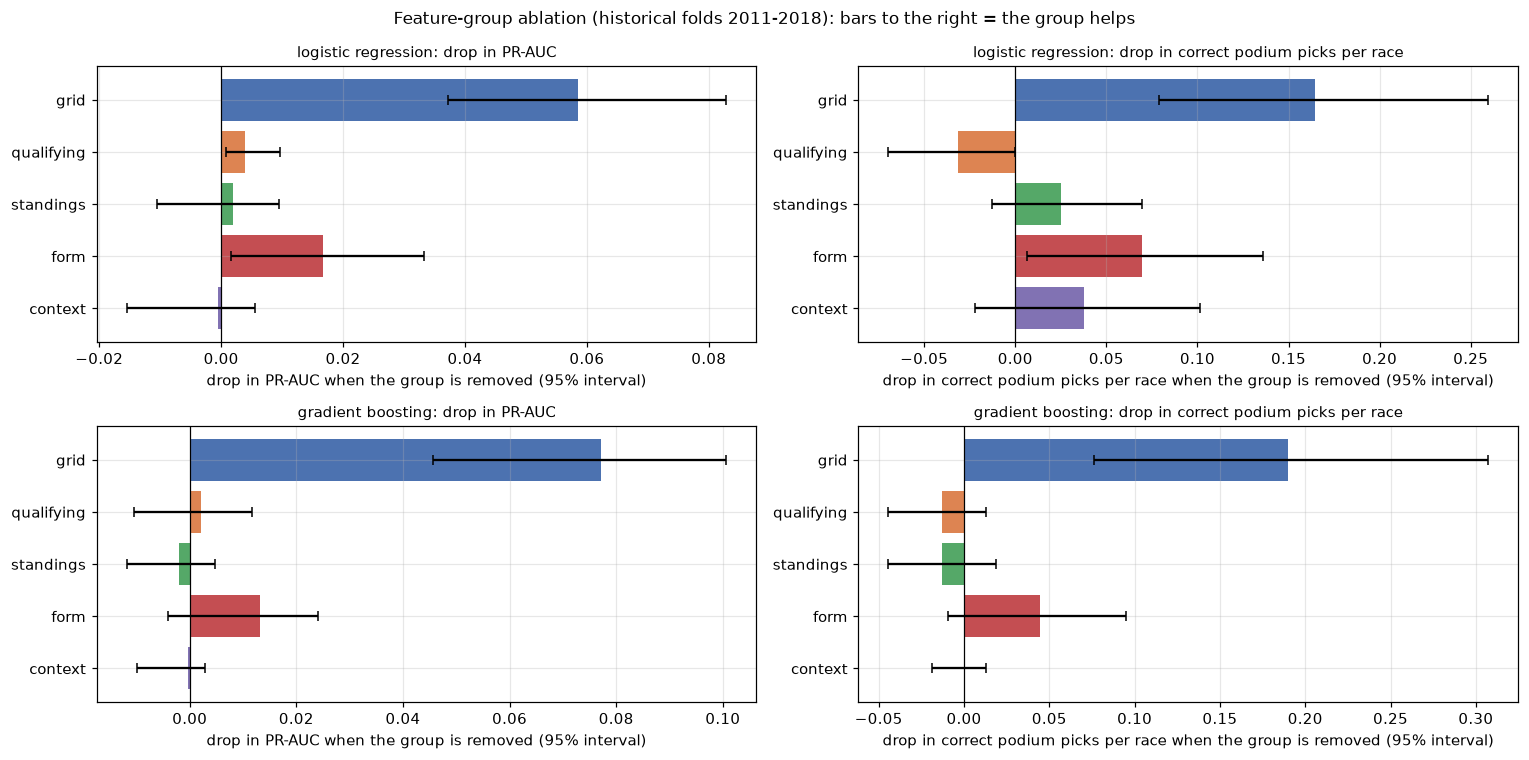

In [146]:
GROUP_COLORS = {"grid": "#4C72B0", "qualifying": "#DD8452", "standings": "#55A868", "form": "#C44E52", "context": "#8172B3"}
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for row, family in enumerate(ABL_FAMILIES):
    sub = ABLATION[(ABLATION["family"] == family) & (ABLATION["variant"] != "full model")]
    groups = [v.replace("without ", "") for v in sub["variant"]]
    for col, (metric, interval, label) in enumerate([("PR-AUC drop", "PR-AUC drop 95% interval", "drop in PR-AUC"),
                                                     ("correct-picks drop", "correct-picks drop 95% interval", "drop in correct podium picks per race")]):
        ax = axes[row, col]
        centre = sub[metric].to_numpy()
        lo = np.array([iv[0] for iv in sub[interval]])
        hi = np.array([iv[1] for iv in sub[interval]])
        ax.barh(groups, centre, color=[GROUP_COLORS[g] for g in groups])
        ax.errorbar(centre, range(len(groups)), xerr=[centre - lo, hi - centre], fmt="none", ecolor="black", capsize=3)
        ax.axvline(0, color="black", lw=0.8)
        ax.invert_yaxis()
        ax.set_xlabel(f"{label} when the group is removed (95% interval)")
        ax.set_title(f"{family}: {label}", fontsize=10)
plt.suptitle("Feature-group ablation (historical folds 2011-2018): bars to the right = the group helps", fontsize=11)
plt.tight_layout()
plt.show()

**What the ablation shows** (historical folds, 158 races; drop = full model − model without the group):
- **Grid is by far the most important group.** Without it, logistic regression loses 0.059 PR-AUC (interval +0.037 to +0.083) and **0.16 correct podium picks per race** (+0.08 to +0.26); the exact-three rate falls from 26% to 13%. Gradient boosting loses even more (0.077 PR-AUC, 0.19 picks per race). It hurts in all 4 folds for both models.
- **Recent form is the second clear group** for logistic regression: −0.017 PR-AUC (+0.002 to +0.033; lower in all 4 folds) and −0.07 correct picks per race (+0.006 to +0.136; lower in 3 folds, equal in the 4th). For gradient boosting the drop has the same size (−0.013 PR-AUC, all 4 folds) but its interval includes 0.
- **Qualifying, standings and context add little on top of the others.** Removing qualifying costs logistic regression only 0.004 PR-AUC (an interval just above 0), and its podium picks are slightly *better* without it (interval includes 0). Standings and context change nothing measurable. This is **not** saying these inputs are useless: qualifying pace and standings are strongly correlated with grid and form, so when one group is removed, the others carry most of its information. (In the section-4 forward selection, which added groups one at a time, qualifying was the clearest gain *after grid alone*; here it is measured *after everything else*.)

# 10. Explainable AI

**This section answers Requirement 6 of the brief (model explainability):**

| Brief requirement | Where it is answered |
|---|---|
| Global explanation: **permutation importance** (plotted and interpreted) | **10.7** (individual inputs and feature groups; across rows → PR-AUC, within race → top-3 F1) |
| Global explanation: **SHAP** (plotted and interpreted) | **10.3** (global SHAP of the primary model), plus **10.8** (tree SHAP of gradient boosting, for comparison) |
| Local explanation of **a single prediction** (LIME and/or local SHAP), plotted and interpreted | **10.4** (local SHAP waterfalls for four drivers, each with its predicted podium probability), **10.5** (a complete race: why these three), **10.6** (LIME, supplementary) |
| Explanations **not presented as causal effects** | stated below, in the caveats of 10.2 and 10.7, and in the conclusion of 10.9 |

Extra context, not required by the brief: 10.2 (logistic-regression weights and odds ratios) and 10.9 (agreement between methods, including the Section 9 ablation).

**Target:** the frozen primary model, **logistic regression, model A (v2)**, exactly as saved (its fitted pre-processing and its 21 inputs). Gradient boosting A (v2) is explained in 10.8 for comparison. Explanations use the **validation seasons 2019–2021** and examples chosen by **rules fixed in advance**; the test seasons are not used.

**How to read the numbers.** Logistic regression adds up a contribution for every input on the **log-odds** scale and then turns the total into a probability:

  log-odds = base value + Σ contributions, probability = 1 / (1 + e^(−log-odds)).

So contributions **add up in log-odds, not in probability**. A contribution of +1.0 log-odds multiplies the odds of a podium by e ≈ 2.7. Every plot below states its scale.

**These are explanations of the model, not of Formula 1.** They show which inputs the model relies on, not what *causes* podiums. Correlated inputs (grid, qualifying pace, standings and form all describe how fast the car is) share credit in ways that depend on the method.

**Caveats to keep in mind (from the pre-XAI audit):**
- **`pit_lane_start`:** pit-lane starts are only recorded as `grid = 0` from 2015, so model A saw just 7 of them in training (none on the podium); its weight is unreliable.
- **`no_q3_format`:** it is 0 for every validation row (Q3 exists in all of 2019–2021), so it contributes nothing here.
- **`drv_no_standing_yet` / `cons_no_standing_yet`:** in 2003–2009 the source data leaves 0-point drivers out of the standings, so these flags mean "no points yet"; later they mostly mean "first race of the season or debut".
- **`grid_minus_quali` on sprint weekends:** in 2021 (and 2022) the race grid came from the sprint, so the value mixes sprint gains/losses with penalties, not only penalties.
- **Correlated inputs:** grid, `gap_q1_pct`, `reached_q3`, standings and form overlap; individual weights and individual importances can understate or redistribute their joint effect. The group-level views below are the more reliable ones.

## 10.1 Reusing the fitted model and validation data

Reuses the fitted v2 objects (checked against the frozen configuration), builds training and validation inputs with their fitted preprocessing, and imports SHAP and LIME (with a clear message if either is unavailable).

In [147]:


try:
    import shap
    SHAP_OK, SHAP_NOTE = True, f"shap {shap.__version__}"
except ImportError:
    try:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True, timeout=300)
        import shap
        SHAP_OK, SHAP_NOTE = True, f"shap {shap.__version__} (installed now)"
    except Exception as e:
        SHAP_OK, SHAP_NOTE = False, f"shap unavailable ({type(e).__name__}); exact SHAP values are still computed by hand (linear model) and plotted with matplotlib"


def load_v2(name):
    key = V2_MODELS[name]["key"]
    entry = FINAL_V2[key]
    return {"preprocessor": entry["pre"], "model": entry["model"]}



_primary = load_v2("A_logistic_regression")
XPRE, XLR = _primary["preprocessor"], _primary["model"]
_tree = load_v2("A_gradient_boosting")
TPRE, THGB = _tree["preprocessor"], _tree["model"]
XAI_INPUTS = list(XPRE.get_feature_names_out())
assert XAI_INPUTS == INPUTS_SCALED == list(XLR.feature_names_in_) and XLR.coef_.shape == (1, 21)
assert list(TPRE.get_feature_names_out()) == INPUTS_TREE == list(THGB.feature_names_in_)

X_TRAIN = XPRE.transform(TRAIN_A_ROWS[FINAL_FEATURES])
X_VAL = XPRE.transform(VAL_ROWS[FINAL_FEATURES])
P_VAL = XLR.predict_proba(X_VAL)[:, 1]
LOGIT_VAL = XLR.decision_function(X_VAL)
assert np.array_equal(P_VAL, V2_REFERENCE["A_logistic_regression"]), "re-loaded primary model differs from the frozen predictions"
FILLED_COLS = list(XPRE.named_steps["impute"].get_feature_names_out())
FILLED_TRAIN = XPRE.named_steps["impute"].transform(TRAIN_A_ROWS[FINAL_FEATURES])
FILLED_VAL = XPRE.named_steps["impute"].transform(VAL_ROWS[FINAL_FEATURES])

# Readable context for every validation row (names are for reading only).
_names = CLEAN["drivers"].assign(driver=CLEAN["drivers"]["forename"] + " " + CLEAN["drivers"]["surname"]).set_index("driverId")["driver"]
_races = CLEAN["races"].set_index("raceId")
VAL_INFO = VAL_ROWS[["raceId", "driverId", "year", "grid", "podium"]].copy()
VAL_INFO["driver"] = VAL_INFO["driverId"].map(_names)
VAL_INFO["race"] = VAL_INFO["year"].astype(str) + " " + VAL_INFO["raceId"].map(_races["name"])
VAL_INFO["round"] = VAL_INFO["raceId"].map(_races["round"])
VAL_INFO["probability"] = P_VAL
VAL_INFO["rank in race"] = VAL_INFO.groupby("raceId")["probability"].rank(method="first", ascending=False).astype(int)
VAL_INFO["top-3 pick"] = VAL_INFO["rank in race"] <= 3

# Values in original units for labels: the 18 features as recorded (missing shown as "missing"), flags as 0/1.
_display = pd.DataFrame(index=VAL_ROWS.index)
for c in XAI_INPUTS:
    raw = VAL_ROWS[c] if c in FINAL_FEATURES else FILLED_VAL[c]
    _display[c] = [("missing" if pd.isna(v) else (int(v) if float(v).is_integer() else round(float(v), 3))) for v in raw]
DISPLAY_VAL = _display
print(f"Primary model reused from memory: 21 inputs, predictions identical to the frozen ones. {SHAP_NOTE}.")

D:\semster 9\ACL Project\.verification-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Primary model reused from memory: 21 inputs, predictions identical to the frozen ones. shap 0.54.1.


## 10.2 Logistic-regression weights and odds ratios

Each weight is the change in **log-odds** of a podium when that input goes up by one unit, **with all other inputs held fixed**:
- **continuous inputs** (standardised): one unit = **one standard deviation** of the training data; the table also converts the weight to **one original unit** (e.g. one grid place, one percentage point of Q1 gap);
- **flags** (0/1, not scaled): the effect of the flag switching **from 0 to 1**.

**Odds ratio** = e^weight: above 1 = the odds of a podium go up, below 1 = they go down. Because the inputs are correlated, "holding all others fixed" is often unrealistic (a car that qualifies faster also starts further forward), so single weights should not be read on their own; sections 10.3–10.8 look at the inputs together.

Intercept: -3.423 log-odds. Weights sorted by size:


,group,type,weight (log-odds),odds ratio,1 SD in original units,weight per original unit,odds ratio per original unit
grid,grid,continuous (per 1 SD),-2.006,0.135,6.262,-0.320,0.726
q1_time_missing,qualifying,flag (0 -> 1),1.905,6.719,NaN,NaN,NaN
drv_no_standing_yet,standings,flag (0 -> 1),0.702,2.018,NaN,NaN,NaN
reached_q3,qualifying,flag (0 -> 1),-0.615,0.540,NaN,NaN,NaN
drv_avg_finish_5,form,continuous (per 1 SD),-0.567,0.567,4.503,-0.126,0.882
no_q3_format,qualifying,flag (0 -> 1),-0.514,0.598,NaN,NaN,NaN
drv_experience,context,continuous (per 1 SD),0.441,1.555,79.177,0.006,1.006
cons_points_share,standings,continuous (per 1 SD),0.426,1.532,0.334,1.275,3.580
drv_age,context,continuous (per 1 SD),-0.426,0.653,4.847,-0.088,0.916
drv_dnf_rate_5,form,continuous (per 1 SD),0.412,1.510,0.214,1.927,6.869


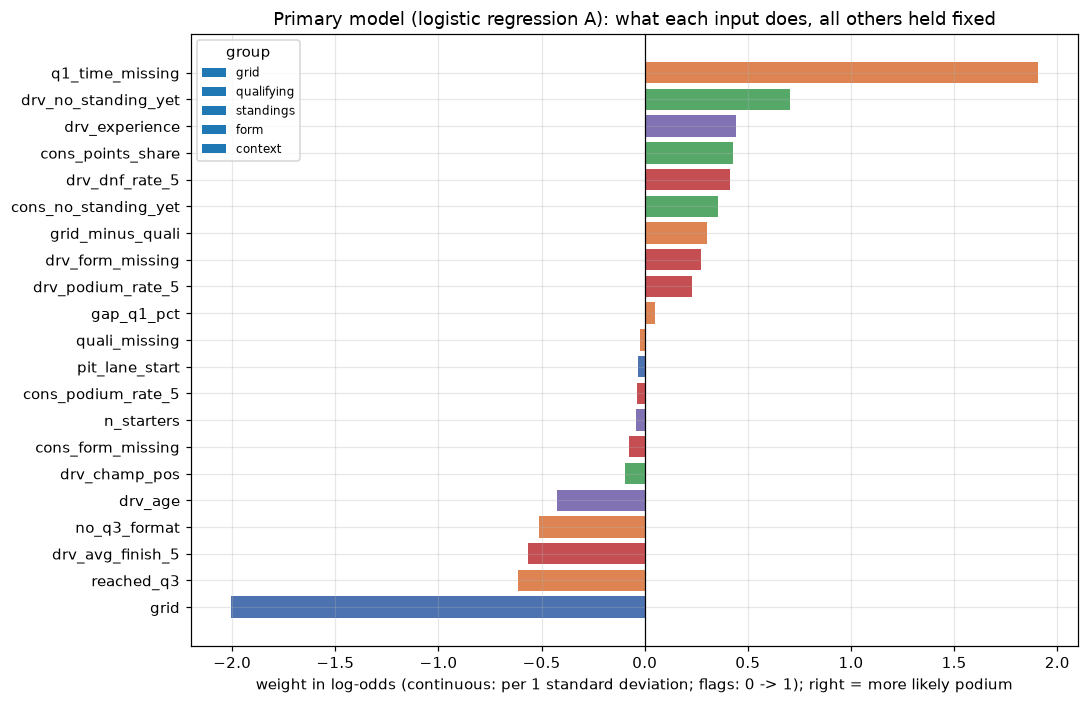

In [148]:
scaler = XPRE.named_steps["scale"].named_transformers_["continuous"]
sd_of = dict(zip(CONTINUOUS_FEATURES, scaler.scale_))
coef = pd.Series(XLR.coef_[0], index=XAI_INPUTS)
coef_table = pd.DataFrame({
    "group": [GROUP_OF[c] for c in XAI_INPUTS],
    "type": ["continuous (per 1 SD)" if c in sd_of else "flag (0 -> 1)" for c in XAI_INPUTS],
    "weight (log-odds)": coef.values,
    "odds ratio": np.exp(coef.values),
    "1 SD in original units": [sd_of.get(c, np.nan) for c in XAI_INPUTS],
    "weight per original unit": [coef[c] / sd_of[c] if c in sd_of else np.nan for c in XAI_INPUTS],
    "odds ratio per original unit": [np.exp(coef[c] / sd_of[c]) if c in sd_of else np.nan for c in XAI_INPUTS],
}, index=XAI_INPUTS)
print(f"Intercept: {XLR.intercept_[0]:+.3f} log-odds. Weights sorted by size:")
display(coef_table.reindex(coef.abs().sort_values(ascending=False).index).round(3))

fig, ax = plt.subplots(figsize=(10, 6.5))
order = coef.sort_values().index
ax.barh(order, coef[order], color=[GROUP_COLORS[GROUP_OF[c]] for c in order])
ax.axvline(0, color="black", lw=0.8)
for g, col in GROUP_COLORS.items():
    ax.barh([], [], color=col, label=g)
ax.legend(title="group", fontsize=8)
ax.set_xlabel("weight in log-odds (continuous: per 1 standard deviation; flags: 0 -> 1); right = more likely podium")
ax.set_title("Primary model (logistic regression A): what each input does, all others held fixed")
plt.tight_layout()
plt.show()

**Reading the weights:**
- **Grid** dominates: −2.0 log-odds per standard deviation (6.3 places), i.e. each grid place further back multiplies the odds of a podium by about 0.73.
- **Some signs look surprising; they come from correlated inputs and from flags that correct a filled value:**
  - `q1_time_missing` +1.9 (odds × 6.7): a driver with a qualifying record but no Q1 time usually starts at the back after a penalty or a problem, and the slow-lap fill makes them look slow. Many of them are in fast cars, so the flag *offsets* the low grid and the slow fill (example (d) in 10.4).
  - `drv_no_standing_yet` +0.7: offsets the "behind everyone" position given to drivers without standings (e.g. everyone in round 1).
  - `reached_q3` −0.6 and `drv_dnf_rate_5` +0.4: these move with grid and with `drv_avg_finish_5`. Once grid and average finish are known, reaching Q3 adds little, and a driver whose average finish is poor *because of retirements* is partly corrected back up.
  - `drv_experience` +0.4 and `drv_age` −0.4 (correlation 0.81): at the same experience an older driver is less likely, at the same age a more experienced one more likely; they largely cancel (see the group view in 10.3).
- `no_q3_format` (−0.5) only matters for 2003–2005 rows and is 0 throughout validation; `pit_lane_start` (−0.03) is based on 7 training rows.

## 10.3 Global SHAP: which inputs drive the predictions?

For a logistic regression, SHAP values are **exact and simple**: the contribution of input *j* for a driver is

  φ_j = weight_j × (value_j − average value_j in the training seasons), in log-odds,

and the **base value** is the log-odds of a driver with average inputs. For every row, base value + Σ φ_j = the model's log-odds (checked below). This uses the standard "interventional" SHAP, which treats inputs as independent; with correlated inputs it explains **the model's formula**, not how the inputs move together in reality.

**Two ways to measure a group's importance** (both reported, because they differ when contributions inside a group cancel out):
- **(A) sum of individual importances:** for each input, the mean of |φ_j| over the validation rows; then add these up within the group;
- **(B) importance of the group's total contribution:** for each row, add the group's φ_j (signed) and take the absolute value; then average over the validation rows. (B) ≤ (A); (B) is the better measure of what the group does *as a whole*.

Base value: -3.642 log-odds = probability 0.026 (a driver with average inputs). Average predicted probability on validation: 0.160 (actual podium rate 0.150). the shap library's LinearExplainer gives the same values (checked).


,group,mean |SHAP| (log-odds)
grid,grid,1.6187
drv_avg_finish_5,form,0.4363
drv_age,context,0.4277
drv_experience,context,0.4114
cons_points_share,standings,0.3406
reached_q3,qualifying,0.3078
drv_dnf_rate_5,form,0.2894
drv_podium_rate_5,form,0.1820
grid_minus_quali,qualifying,0.1427
no_q3_format,qualifying,0.0840


,(A) sum of mean |SHAP| of its inputs,(B) mean |summed group SHAP|
grid,1.6195,1.6195
form,0.9452,0.5127
standings,0.5352,0.4207
qualifying,0.6223,0.3967
context,0.8735,0.2596


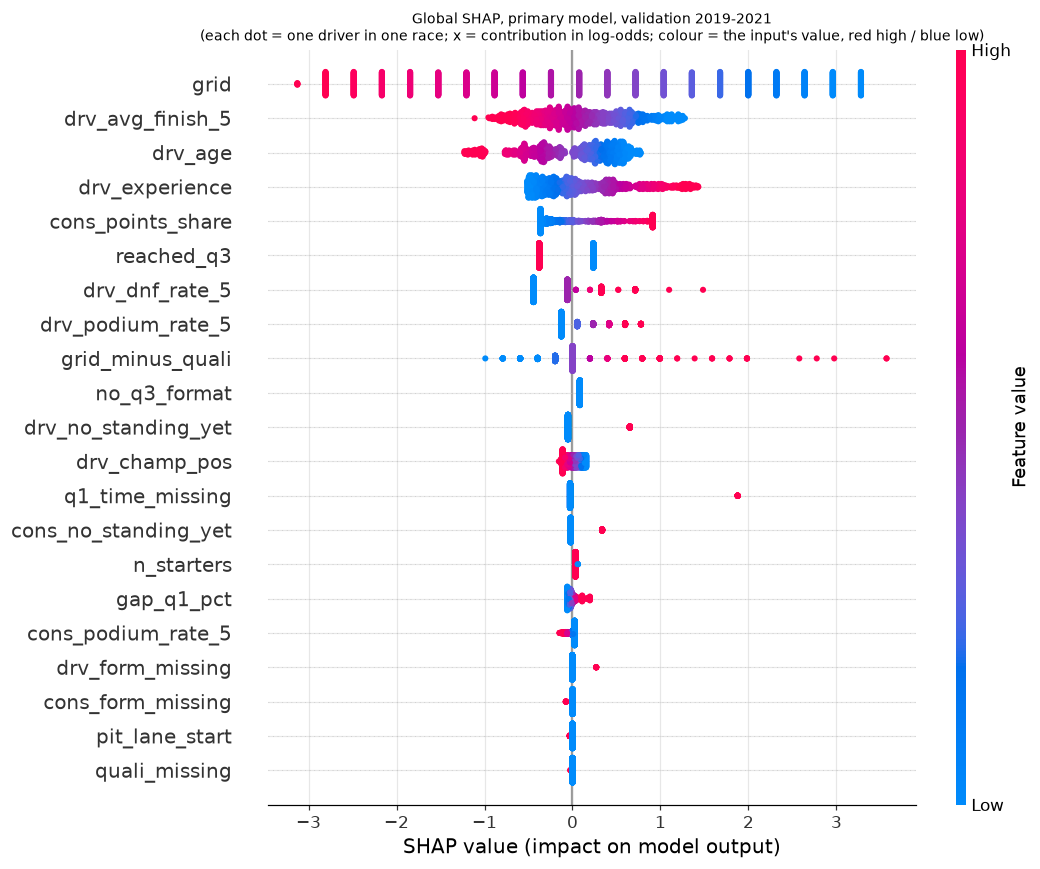

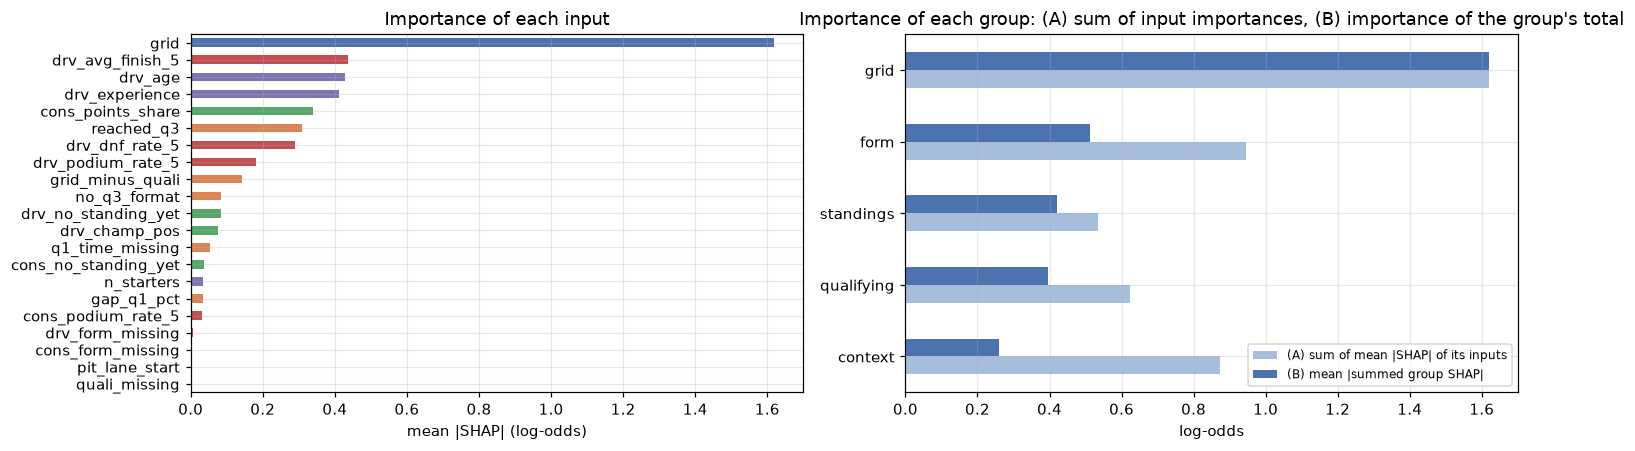

In [149]:
TRAIN_MEAN = X_TRAIN.mean()
PHI = (X_VAL - TRAIN_MEAN) * coef                                  # exact SHAP values (log-odds), rows x 21 inputs
BASE_VALUE = float(XLR.intercept_[0] + coef @ TRAIN_MEAN)
assert np.allclose(PHI.sum(axis=1) + BASE_VALUE, LOGIT_VAL), "SHAP values do not add up to the model's log-odds"
if SHAP_OK:
    _lin = shap.LinearExplainer(XLR, shap.maskers.Independent(X_TRAIN, max_samples=len(X_TRAIN)))
    _sv = _lin(X_VAL)
    assert np.allclose(_sv.values, PHI.to_numpy(), atol=1e-8), "the shap library disagrees with the exact formula"
    SHAP_CHECK = "the shap library's LinearExplainer gives the same values (checked)"
else:
    SHAP_CHECK = "shap library not available: values computed with the exact formula"
print(f"Base value: {BASE_VALUE:+.3f} log-odds = probability {1 / (1 + np.exp(-BASE_VALUE)):.3f} (a driver with average inputs). "
      f"Average predicted probability on validation: {P_VAL.mean():.3f} (actual podium rate {VAL_ROWS['podium'].mean():.3f}). {SHAP_CHECK}.")

mean_abs = PHI.abs().mean().sort_values(ascending=False)
group_A = mean_abs.groupby(lambda c: GROUP_OF[c]).sum()
group_B = pd.Series({g: PHI[cols].sum(axis=1).abs().mean() for g, cols in INPUT_GROUPS.items()})
SHAP_GROUPS_LR = pd.DataFrame({"(A) sum of mean |SHAP| of its inputs": group_A, "(B) mean |summed group SHAP|": group_B}).sort_values(
    "(B) mean |summed group SHAP|", ascending=False)
display(pd.DataFrame({"group": [GROUP_OF[c] for c in mean_abs.index], "mean |SHAP| (log-odds)": mean_abs.values}, index=mean_abs.index).round(4))
display(SHAP_GROUPS_LR.round(4))

EXPL_LR = None
if SHAP_OK:
    EXPL_LR = shap.Explanation(values=PHI.to_numpy(), base_values=np.full(len(PHI), BASE_VALUE), data=X_VAL.to_numpy(),
                               display_data=DISPLAY_VAL.to_numpy(), feature_names=XAI_INPUTS)
    shap.plots.beeswarm(EXPL_LR, max_display=21, show=False)
    plt.title("Global SHAP, primary model, validation 2019-2021\n(each dot = one driver in one race; x = contribution in log-odds; "
              "colour = the input's value, red high / blue low)", fontsize=9)
    plt.gcf().set_size_inches(10, 8)
    plt.tight_layout()
    plt.show()
else:
    fig, ax = plt.subplots(figsize=(10, 8))
    for k, c in enumerate(mean_abs.index[::-1]):
        ax.scatter(PHI[c], np.full(len(PHI), k) + np.random.default_rng(0).uniform(-0.3, 0.3, len(PHI)), s=3, c=X_VAL[c], cmap="coolwarm")
    ax.set_yticks(range(21), mean_abs.index[::-1])
    ax.set_xlabel("contribution (log-odds)")
    ax.set_title("Global SHAP (exact), primary model, validation 2019-2021")
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
mean_abs[::-1].plot.barh(ax=axes[0], color=[GROUP_COLORS[GROUP_OF[c]] for c in mean_abs.index[::-1]])
axes[0].set_xlabel("mean |SHAP| (log-odds)")
axes[0].set_title("Importance of each input")
SHAP_GROUPS_LR[::-1].plot.barh(ax=axes[1], color=["#A6BDDB", "#4C72B0"])
axes[1].set_xlabel("log-odds")
axes[1].set_title("Importance of each group: (A) sum of input importances, (B) importance of the group's total")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Global SHAP findings** (validation, primary model):
- **Base value** −3.64 log-odds = probability 0.026: a driver with *average* inputs (mid-field) rarely reaches the podium. The model's average predicted probability on validation is 0.160 (actual podium rate 0.150).
- **Grid is the main driver of the predictions:** mean |SHAP| 1.62 log-odds, about four times the next input. Then the driver's recent average finish (0.44), age (0.43), experience (0.41), the team's share of the leader's points (0.34) and reaching Q3 (0.31).
- **By group, measure (B), the importance of the group's total contribution:** grid 1.62, form 0.51, standings 0.42, qualifying 0.40, context 0.26. Measure (A) is higher for groups whose inputs **cancel** each other: context drops from 0.87 (A) to 0.26 (B) because age and experience push in opposite directions; form (0.95 → 0.51) and qualifying (0.62 → 0.40) also partly cancel.

## 10.4 Local SHAP: four individual predictions

Four validation drivers, chosen by **rules fixed before looking at their explanations**:
- **(a)** the **most confident correct pick:** the highest-probability driver who was picked in the race's top 3 and did finish on the podium;
- **(b)** the **biggest miss:** the real podium finisher with the lowest predicted probability;
- **(c)** a **fast car starting further back:** the highest-probability top-3 pick who started **5th or lower**;
- **(d)** the highest-probability driver **without a Q1 time** (`q1_time_missing` = 1); if there is none, the highest-probability **debut** driver.

Each waterfall starts at the base value (average driver), adds the inputs' contributions in **log-odds** (red pushes towards a podium, blue away), and ends at the driver's log-odds, whose probability is given in the title. Labels show the inputs' **original values**.

,race,driver,grid,probability,rank in race,top-3 pick,podium
(a) most confident correct pick,2021 Abu Dhabi Grand Prix,Max Verstappen,1.0,0.909,1,True,1
(b) biggest miss,2019 German Grand Prix,Daniil Kvyat,14.0,0.007,15,False,1
(c) top-3 pick starting 5th or lower,2021 Qatar Grand Prix,Max Verstappen,7.0,0.796,2,True,1
(d) no Q1 time,2021 Russian Grand Prix,Max Verstappen,20.0,0.135,6,False,1


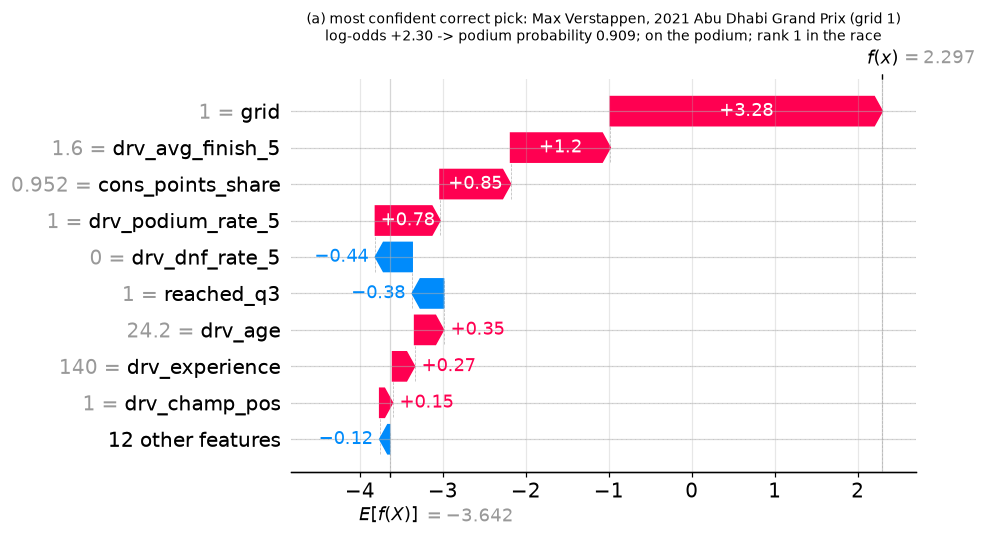

(a) most confident correct pick: largest contributions (log-odds): grid = 1 (+3.28), drv_avg_finish_5 = 1.6 (+1.20), cons_points_share = 0.952 (+0.85), drv_podium_rate_5 = 1 (+0.78)


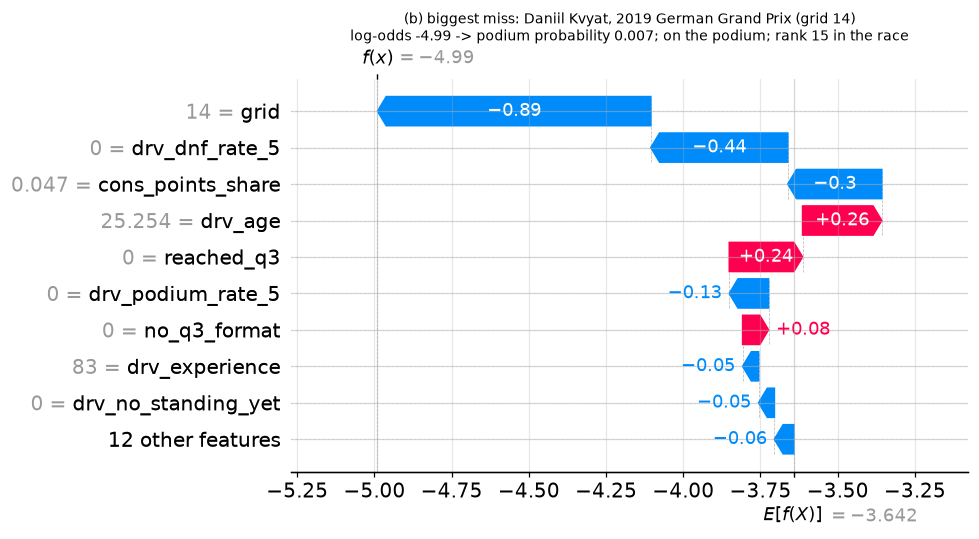

(b) biggest miss: largest contributions (log-odds): grid = 14 (-0.89), drv_dnf_rate_5 = 0 (-0.44), cons_points_share = 0.047 (-0.30), drv_age = 25.254 (+0.26)


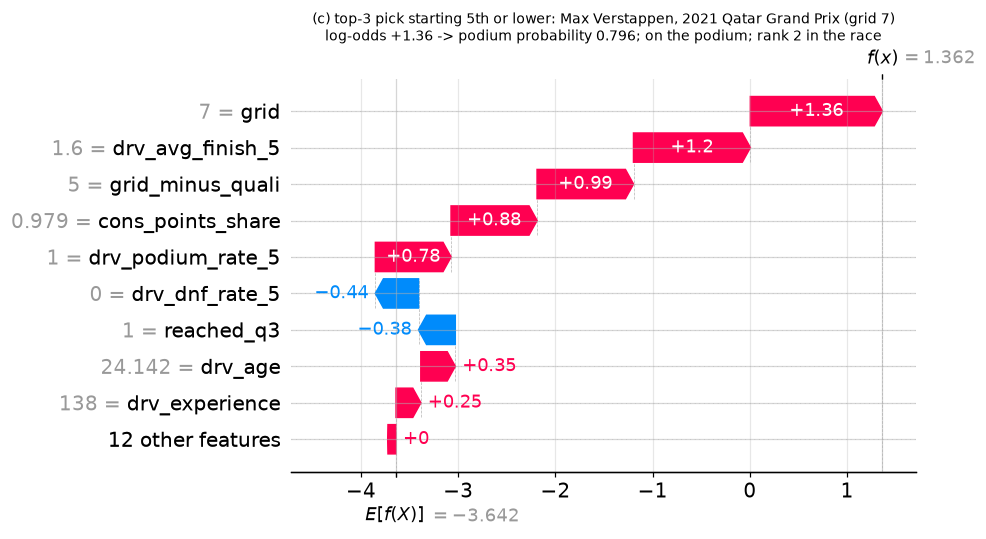

(c) top-3 pick starting 5th or lower: largest contributions (log-odds): grid = 7 (+1.36), drv_avg_finish_5 = 1.6 (+1.20), grid_minus_quali = 5 (+0.99), cons_points_share = 0.979 (+0.88)


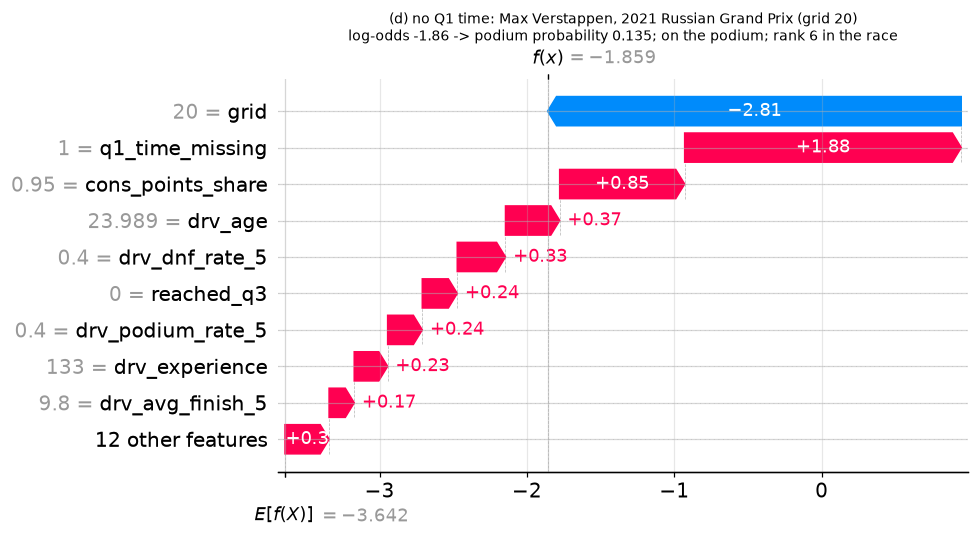

(d) no Q1 time: largest contributions (log-odds): grid = 20 (-2.81), q1_time_missing = 1 (+1.88), cons_points_share = 0.95 (+0.85), drv_age = 23.989 (+0.37)


In [150]:
def pick(mask, by="probability", largest=True):
    cand = VAL_INFO[mask]
    return cand[by].idxmax() if largest else cand[by].idxmin()


q1_missing = FILLED_VAL["q1_time_missing"] == 1
EXAMPLES = {
    "(a) most confident correct pick": pick(VAL_INFO["top-3 pick"] & (VAL_INFO["podium"] == 1)),
    "(b) biggest miss": pick(VAL_INFO["podium"] == 1, largest=False),
    "(c) top-3 pick starting 5th or lower": pick(VAL_INFO["top-3 pick"] & (VAL_INFO["grid"] >= 5)),
    ("(d) no Q1 time" if q1_missing.any() else "(d) debut driver"):
        pick(q1_missing if q1_missing.any() else FILLED_VAL["drv_form_missing"] == 1),
}
ex_table = VAL_INFO.loc[list(EXAMPLES.values()), ["race", "driver", "grid", "probability", "rank in race", "top-3 pick", "podium"]]
ex_table.index = list(EXAMPLES)
display(ex_table.round(3))


def waterfall(i, title, max_display=10):
    if SHAP_OK:
        shap.plots.waterfall(EXPL_LR[i], max_display=max_display, show=False)
        plt.gcf().set_size_inches(9, 5)
        plt.title(title, fontsize=9)
        plt.tight_layout()
        plt.show()
    else:
        contrib = PHI.iloc[i].sort_values(key=abs, ascending=False).head(max_display)[::-1]
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.barh([f"{c} = {DISPLAY_VAL.iloc[i][c]}" for c in contrib.index], contrib, color=np.where(contrib > 0, "#C44E52", "#4C72B0"))
        ax.axvline(0, color="black", lw=0.8)
        ax.set_xlabel("contribution (log-odds)")
        ax.set_title(title, fontsize=9)
        plt.tight_layout()
        plt.show()


for label, i in EXAMPLES.items():
    r = VAL_INFO.loc[i]
    waterfall(i, f"{label}: {r['driver']}, {r['race']} (grid {int(r['grid'])})\n"
                 f"log-odds {LOGIT_VAL[i]:+.2f} -> podium probability {r['probability']:.3f}; "
                 f"{'on the podium' if r['podium'] == 1 else 'not on the podium'}; rank {r['rank in race']} in the race")
    top = PHI.iloc[i].sort_values(key=abs, ascending=False).head(4)
    print(f"{label}: largest contributions (log-odds): " + ", ".join(f"{c} = {DISPLAY_VAL.iloc[i][c]} ({v:+.2f})" for c, v in top.items()))

**Local SHAP findings** (the four rule-chosen drivers; contributions in log-odds):
- **(a) Max Verstappen, 2021 Abu Dhabi GP, pole, probability 0.909, podium.** Starting 1st adds +3.3, an average finish of 1.6 over the last 5 races +1.2, the team's points share +0.85 and a podium in each of his last 5 races +0.8. Everything agrees.
- **(b) Daniil Kvyat, 2019 German GP, grid 14, probability 0.007, finished 3rd** in a chaotic wet race. Grid 14 (−0.9), no recent retirements (−0.4, see the DNF-rate weight) and a weak team (−0.3) all point away from a podium. Nothing known before the start suggested it: a genuine surprise.
- **(c) Max Verstappen, 2021 Qatar GP, grid 7 after a penalty (qualified 2nd), probability 0.796, podium.** Grid 7 is still better than average (+1.4); recent form (+1.2), the penalty signal `grid_minus_quali` = 5 (+1.0, "fast car starting further back") and the team's points share (+0.9) lift him to the 2nd most likely driver of the race.
- **(d) Max Verstappen, 2021 Russian GP, grid 20 with no Q1 time (engine penalty), probability 0.135, finished 2nd.** Starting last costs −2.8; the "no Q1 time" flag gives back +1.9 and the team's points share +0.85. The model saw *something* was unusual (6th most likely), but not enough to pick him.

## 10.5 Explaining a complete race: why these three?

The official output for a race is the **three drivers with the highest podium probability** (7.10). Within one race, the model's ranking is decided by the drivers' log-odds, so the gap between two drivers splits **exactly** into per-input parts: weight × (difference in their input values).

- **Race 1 (rule):** the validation race where the **3rd and 4th** probabilities are **closest**, i.e. the hardest cut. The table lists every driver; the bar chart shows why the 3rd driver is ahead of the 4th.
- **Race 2 (rule):** the **first validation race, in calendar order,** where the model's top 3 differ from the **top 3 on the starting grid**. The chart compares the driver the model brought in with the grid-top-3 driver it left out (if there are several, the highest-probability one brought in vs the lowest-probability one left out).

The three picks are the most likely podium finishers, **not** a forecast of 1st, 2nd and 3rd.

Race 1: 2019 Singapore Grand Prix; 3rd vs 4th probability gap 0.0005 (the smallest of the 60 validation races). The model's three picks got 2 podiums right.


,driver,grid,probability,rank in race,top-3 pick,grid top 3,podium
281,Lewis Hamilton,2.0,0.785,1,True,True,0
280,Charles Leclerc,1.0,0.759,2,True,True,1
283,Max Verstappen,4.0,0.489,3,True,False,1
284,Valtteri Bottas,5.0,0.488,4,False,False,0
282,Sebastian Vettel,3.0,0.461,5,False,True,1
285,Alexander Albon,6.0,0.103,6,False,False,0
286,Carlos Sainz,7.0,0.099,7,False,False,0
288,Lando Norris,9.0,0.045,8,False,False,0
287,Nico Hülkenberg,8.0,0.043,9,False,False,0
290,Pierre Gasly,11.0,0.031,10,False,False,0


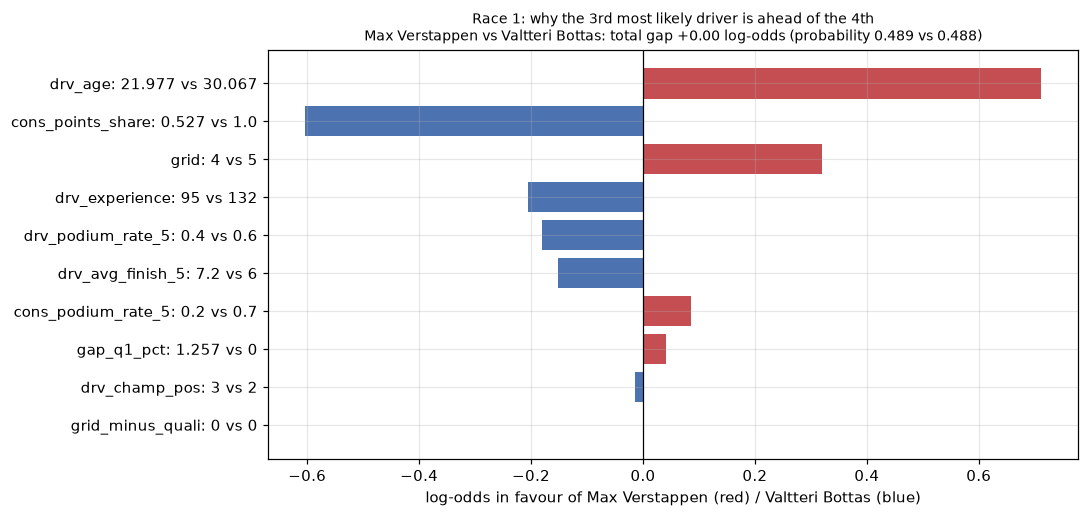

Max Verstappen vs Valtteri Bottas, gap by group (log-odds): standings -0.62, context +0.51, grid +0.32, form -0.25, qualifying +0.04
Race 2: 2019 Australian Grand Prix (first validation race where the model's top 3 differ from the grid's top 3). Model picks right: 2; grid top 3 right: 2.


,driver,grid,probability,rank in race,top-3 pick,grid top 3,podium
0,Lewis Hamilton,1.0,0.782,1,True,True,1
3,Max Verstappen,4.0,0.690,2,True,False,1
2,Sebastian Vettel,3.0,0.556,3,True,True,0
1,Valtteri Bottas,2.0,0.478,4,False,True,1
4,Charles Leclerc,5.0,0.249,5,False,False,0
8,Kimi Räikkönen,9.0,0.158,6,False,False,0
7,Lando Norris,8.0,0.112,7,False,False,0
5,Romain Grosjean,6.0,0.107,8,False,False,0
6,Kevin Magnussen,7.0,0.095,9,False,False,0
11,Daniel Ricciardo,12.0,0.084,10,False,False,0


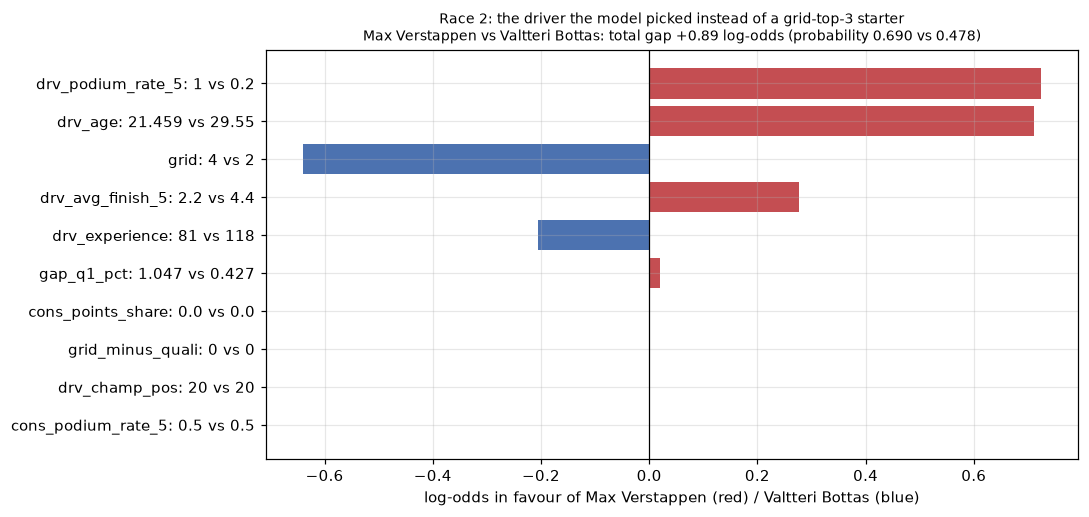

Max Verstappen vs Valtteri Bottas, gap by group (log-odds): form +1.00, grid -0.64, context +0.51, qualifying +0.02, standings +0.00


grid                   -0.640577
gap_q1_pct              0.020261
grid_minus_quali        0.000000
drv_champ_pos           0.000000
cons_points_share       0.000000
drv_podium_rate_5       0.724351
drv_avg_finish_5        0.276753
drv_dnf_rate_5          0.000000
cons_podium_rate_5      0.000000
n_starters              0.000000
drv_experience         -0.206209
drv_age                 0.711515
pit_lane_start          0.000000
reached_q3              0.000000
no_q3_format            0.000000
quali_missing           0.000000
drv_no_standing_yet     0.000000
cons_no_standing_yet    0.000000
q1_time_missing         0.000000
drv_form_missing        0.000000
cons_form_missing       0.000000
dtype: float64

In [151]:
def race_table(race_id):
    t = VAL_INFO[VAL_INFO["raceId"] == race_id].sort_values("rank in race")
    t = t.assign(**{"grid top 3": t["grid"].rank(method="first") <= 3})
    return t[["driver", "grid", "probability", "rank in race", "top-3 pick", "grid top 3", "podium"]]


def pair_explanation(i_ahead, i_behind, title):
    diff = PHI.loc[i_ahead] - PHI.loc[i_behind]                       # = weight x (x_ahead - x_behind), log-odds
    assert np.isclose(diff.sum(), LOGIT_VAL[i_ahead] - LOGIT_VAL[i_behind])
    show = diff.sort_values(key=abs, ascending=False).head(10)[::-1]
    a, b = VAL_INFO.loc[i_ahead, "driver"], VAL_INFO.loc[i_behind, "driver"]
    labels = [f"{c}: {DISPLAY_VAL.loc[i_ahead, c]} vs {DISPLAY_VAL.loc[i_behind, c]}" for c in show.index]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.barh(labels, show, color=np.where(show > 0, "#C44E52", "#4C72B0"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel(f"log-odds in favour of {a} (red) / {b} (blue)")
    ax.set_title(f"{title}\n{a} vs {b}: total gap {diff.sum():+.2f} log-odds "
                 f"(probability {VAL_INFO.loc[i_ahead, 'probability']:.3f} vs {VAL_INFO.loc[i_behind, 'probability']:.3f})", fontsize=9)
    plt.tight_layout()
    plt.show()
    by_group = diff.groupby(lambda c: GROUP_OF[c]).sum().sort_values(key=abs, ascending=False)
    print(f"{a} vs {b}, gap by group (log-odds): " + ", ".join(f"{g} {v:+.2f}" for g, v in by_group.items()))
    return diff


# Race 1: the closest 3rd-vs-4th cut.
cut = (VAL_INFO.sort_values(["raceId", "rank in race"]).groupby("raceId")["probability"]
       .apply(lambda p: p.iloc[2] - p.iloc[3]))
RACE1 = cut.idxmin()
r1 = race_table(RACE1)
print(f"Race 1: {VAL_INFO.loc[VAL_INFO['raceId'] == RACE1, 'race'].iloc[0]}; 3rd vs 4th probability gap {cut.min():.4f} "
      f"(the smallest of the 60 validation races). The model's three picks got {int(r1.loc[r1['top-3 pick'], 'podium'].sum())} podiums right.")
display(r1.round(3))
third = r1.index[r1["rank in race"] == 3][0]
fourth = r1.index[r1["rank in race"] == 4][0]
pair_explanation(third, fourth, "Race 1: why the 3rd most likely driver is ahead of the 4th")

# Race 2: the first race where the model's top 3 differ from the grid's top 3.
order = VAL_INFO.drop_duplicates("raceId").sort_values(["year", "round"])["raceId"]
RACE2 = next(r for r in order if set(race_table(r).query("`top-3 pick`")["driver"]) != set(race_table(r).query("`grid top 3`")["driver"]))
r2 = race_table(RACE2)
print(f"Race 2: {VAL_INFO.loc[VAL_INFO['raceId'] == RACE2, 'race'].iloc[0]} (first validation race where the model's top 3 "
      f"differ from the grid's top 3). Model picks right: {int(r2.loc[r2['top-3 pick'], 'podium'].sum())}; "
      f"grid top 3 right: {int(r2.loc[r2['grid top 3'], 'podium'].sum())}.")
display(r2.round(3))
brought_in = r2[r2["top-3 pick"] & ~r2["grid top 3"]]["probability"].idxmax()
left_out = r2[r2["grid top 3"] & ~r2["top-3 pick"]]["probability"].idxmin()
pair_explanation(brought_in, left_out, "Race 2: the driver the model picked instead of a grid-top-3 starter")

**Race-level findings:**
- **Race 1, 2019 Singapore GP:** the 3rd and 4th most likely drivers are Max Verstappen (grid 4, 0.489) and Valtteri Bottas (grid 5, 0.488), a gap of 0.0005. Verstappen is ahead because of grid (+0.32), age/experience (+0.51) and qualifying (+0.04), while Bottas's championship position and team share (standings −0.62) and form (−0.25) pull the other way. The picks (Hamilton, Leclerc, Verstappen) got **2 of 3** right; the winner, Sebastian Vettel, started 3rd but was only the 5th most likely (0.461).
- **Race 2, 2019 Australian GP:** the model picks Verstappen (grid 4) instead of Bottas (grid 2), mainly on **recent form (+1.00)**, which outweighs the two grid places (−0.64); age/experience add +0.51. Bottas won and Verstappen was 3rd, so the model's picks and the grid's top 3 both got 2 of 3 right.
- These two races show the model's logic in one sentence: **start near the front, be in form, drive for a strong team.** Close calls are decided by small differences across many inputs.

## 10.6 LIME (supplementary local explanation)

LIME explains one prediction by generating many **synthetic** variations of the driver's inputs, asking the model for their probabilities, and fitting a small **weighted linear model** around the driver. Its weights describe that **local approximation**, not the model's own weights, so they are not exact explanations.

**Which input space?** LIME needs a complete table of numbers to sample from:
- **On the 18 original features** (with the pre-processing inside the prediction function): not practical. The training rows contain missing values (e.g. `reached_q3` is missing for 16.6% of model-A training rows), which LIME cannot sample; and LIME would never generate a *missing* value, so the three missing-value flags would always be 0 and the "no Q1 time / no qualifying / debut" situations could not be explained.
- **On the 21 filled inputs in original units** (after the imputation step, before scaling): practical; the prediction function scales them and calls the frozen model. **This is used here.** The 9 flags are marked categorical.

**Known weakness (measured below):** LIME varies inputs **independently**, so many synthetic rows are impossible in real data, e.g. a missing Q1 time together with no qualifying record, `reached_q3` = 1 without qualifying, or a grid position beyond the field size. The model is then asked about cars that cannot exist, which can distort the local fit.

Settings: 5,000 synthetic samples, the top 8 inputs, the same four drivers as 10.4, three seeds (42, 43, 44) to check stability; local fit quality (R²) and agreement with SHAP are reported.

In [152]:
try:
    import lime.lime_tabular
    LIME_OK, LIME_NOTE = True, "lime available"
except ImportError:
    try:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lime"], check=True, timeout=300)
        import lime.lime_tabular
        LIME_OK, LIME_NOTE = True, "lime installed now"
    except Exception as e:
        LIME_OK, LIME_NOTE = False, (f"LIME COULD NOT RUN in this environment ({type(e).__name__}: lime is not installed and could not be "
                                     f"installed, e.g. no internet). The LIME results are missing from this run; SHAP (10.3-10.5) "
                                     f"covers the local explanations.")
print(LIME_NOTE)
print("Missing values in the 18 original features (model-A training rows), the reason LIME is run on the filled inputs:",
      TRAIN_A_ROWS[FINAL_FEATURES].isna().mean().mul(100).round(1)[lambda s: s > 0].to_dict())


def lime_predict(Z):
    filled = pd.DataFrame(np.asarray(Z, dtype=float), columns=FILLED_COLS)
    return XLR.predict_proba(XPRE.named_steps["scale"].transform(filled))


assert np.allclose(lime_predict(FILLED_VAL.to_numpy())[:, 1], P_VAL), "LIME wrapper does not reproduce the model"
CAT_IDX = [FILLED_COLS.index(c) for c in BINARY_FEATURES + INDICATORS]

# How often does independent sampling produce impossible rows? (same independence as LIME's sampling)
rng_lime = np.random.default_rng(EXP_SEED)
sim = pd.DataFrame({c: FILLED_TRAIN[c].to_numpy()[rng_lime.integers(0, len(FILLED_TRAIN), 5000)] for c in FILLED_COLS})
slow = XPRE.named_steps["impute"].gap_slow_
impossible = {
    "no Q1 time and no qualifying record at once": ((sim["q1_time_missing"] == 1) & (sim["quali_missing"] == 1)).mean(),
    "no Q1 time but a real Q1 gap": ((sim["q1_time_missing"] == 1) & ~np.isclose(sim["gap_q1_pct"], slow)).mean(),
    "reached Q3 without a qualifying record": ((sim["reached_q3"] == 1) & (sim["quali_missing"] == 1)).mean(),
    "grid position beyond the field (+ pit lane)": (sim["grid"] > sim["n_starters"] + 1).mean(),
    "'debut' flag with earlier starts": ((sim["drv_form_missing"] == 1) & (sim["drv_experience"] > 0)).mean(),
}
real = FILLED_TRAIN
in_real = {
    "no Q1 time and no qualifying record at once": ((real["q1_time_missing"] == 1) & (real["quali_missing"] == 1)).mean(),
    "no Q1 time but a real Q1 gap": ((real["q1_time_missing"] == 1) & ~np.isclose(real["gap_q1_pct"], slow)).mean(),
    "reached Q3 without a qualifying record": ((real["reached_q3"] == 1) & (real["quali_missing"] == 1)).mean(),
    "grid position beyond the field (+ pit lane)": (real["grid"] > real["n_starters"] + 1).mean(),
    "'debut' flag with earlier starts": ((real["drv_form_missing"] == 1) & (real["drv_experience"] > 0)).mean(),
}
display(pd.DataFrame({"share of independently sampled rows %": pd.Series(impossible) * 100,
                      "share of real training rows %": pd.Series(in_real) * 100}).round(2))

lime available
Missing values in the 18 original features (model-A training rows), the reason LIME is run on the filled inputs: {'gap_q1_pct': 1.8, 'grid_minus_quali': 0.3, 'reached_q3': 16.6, 'drv_podium_rate_5': 1.1, 'drv_avg_finish_5': 1.1, 'drv_dnf_rate_5': 1.1, 'cons_podium_rate_5': 0.6}


,share of independently sampled rows %,share of real training rows %
no Q1 time and no qualifying record at once,0.00,0.00
no Q1 time but a real Q1 gap,1.46,0.00
reached Q3 without a qualifying record,0.16,0.00
grid position beyond the field (+ pit lane),1.98,0.06
'debut' flag with earlier starts,1.40,0.00


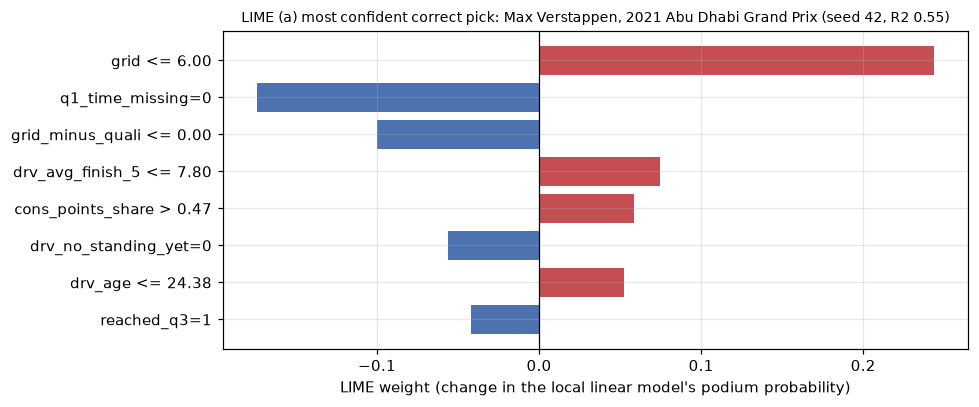

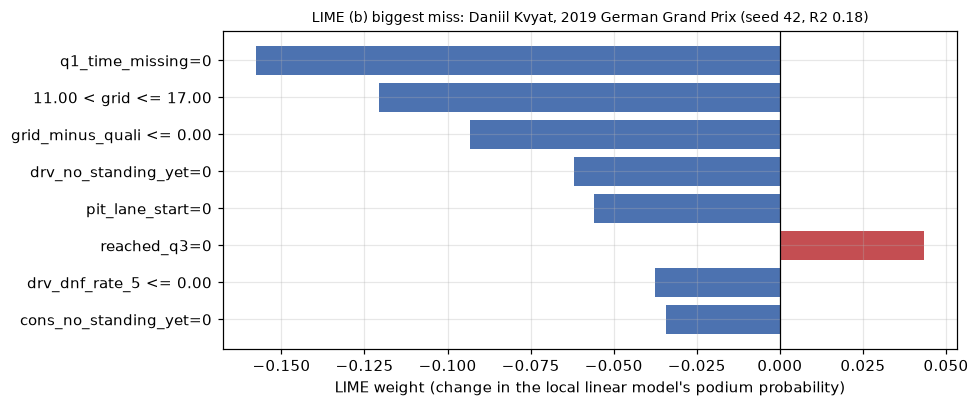

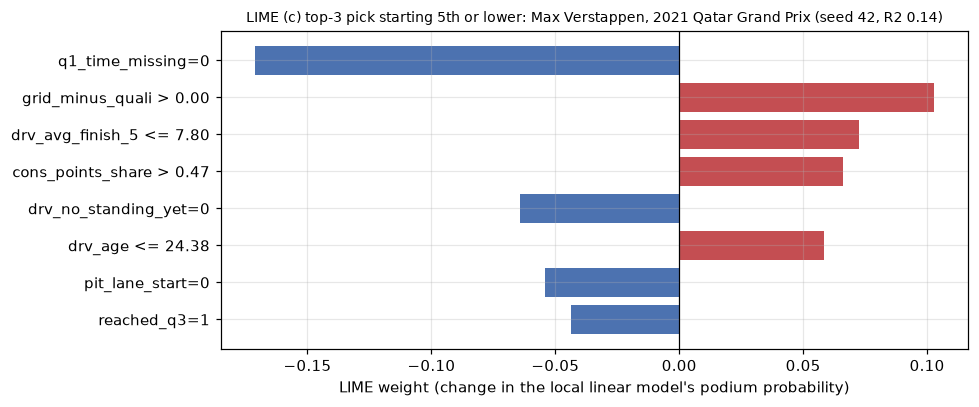

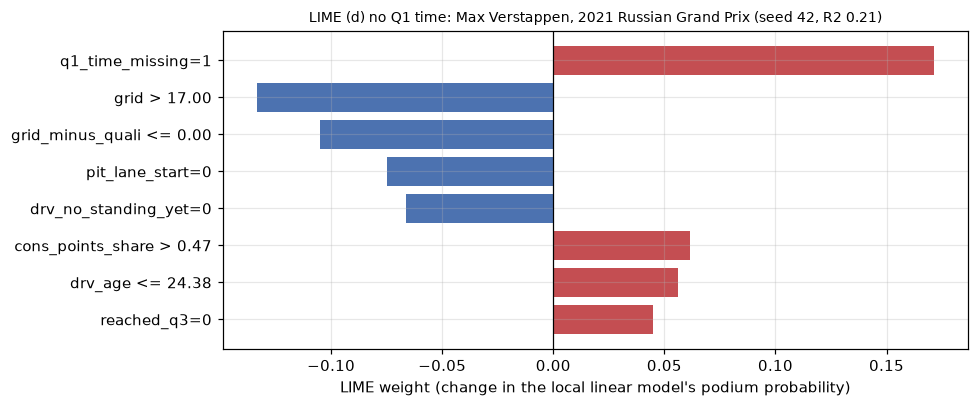

,driver,model probability,LIME local prediction (seed 42),local fit R2 (seeds 42/43/44),"top-5 overlap between seeds (min of 3 pairs, out of 5)","top-5 overlap with SHAP (seed 42, out of 5)",LIME top 5 (seed 42),SHAP top 5
example,,,,,,,,
(a) most confident correct pick,Max Verstappen,0.909,0.384,0.55 / 0.54 / 0.55,4,3,"grid, q1_time_missing, grid_minus_quali, drv_avg_finish_...","grid, drv_avg_finish_5, cons_points_share, drv_podium_ra..."
(b) biggest miss,Daniil Kvyat,0.007,-0.001,0.18 / 0.17 / 0.18,4,1,"q1_time_missing, grid, grid_minus_quali, drv_no_standing...","grid, drv_dnf_rate_5, cons_points_share, drv_age, reache..."
(c) top-3 pick starting 5th or lower,Max Verstappen,0.796,0.319,0.14 / 0.14 / 0.16,4,3,"q1_time_missing, grid_minus_quali, drv_avg_finish_5, con...","grid, drv_avg_finish_5, grid_minus_quali, cons_points_sh..."
(d) no Q1 time,Max Verstappen,0.135,0.267,0.21 / 0.20 / 0.20,3,2,"q1_time_missing, grid, grid_minus_quali, pit_lane_start,...","grid, q1_time_missing, cons_points_share, drv_age, drv_d..."


In [153]:
LIME_ROWS = []
shap_top5 = {label: set(PHI.loc[i].abs().sort_values(ascending=False).head(5).index) for label, i in EXAMPLES.items()}
if LIME_OK:
    for label, i in EXAMPLES.items():
        per_seed = {}
        for seed in [42, 43, 44]:
            explainer = lime.lime_tabular.LimeTabularExplainer(
                FILLED_TRAIN.to_numpy(), feature_names=FILLED_COLS, class_names=["no podium", "podium"],
                categorical_features=CAT_IDX, discretize_continuous=True, mode="classification", random_state=seed)
            exp = explainer.explain_instance(FILLED_VAL.to_numpy()[VAL_ROWS.index.get_loc(i)], lime_predict, num_features=8, num_samples=5000)
            weights = exp.as_map()[1]
            per_seed[seed] = {"names": [FILLED_COLS[j] for j, _ in weights], "conditions": exp.as_list(label=1), "score": exp.score,
                              "local prediction": float(np.ravel(exp.local_pred)[0])}
        top5 = {s: set(v["names"][:5]) for s, v in per_seed.items()}
        LIME_ROWS.append({"example": label, "driver": VAL_INFO.loc[i, "driver"], "model probability": P_VAL[VAL_ROWS.index.get_loc(i)],
                          "LIME local prediction (seed 42)": per_seed[42]["local prediction"],
                          "local fit R2 (seeds 42/43/44)": " / ".join(f"{per_seed[s]['score']:.2f}" for s in per_seed),
                          "top-5 overlap between seeds (min of 3 pairs, out of 5)": min(len(top5[a] & top5[b]) for a, b in [(42, 43), (42, 44), (43, 44)]),
                          "top-5 overlap with SHAP (seed 42, out of 5)": len(top5[42] & shap_top5[label]),
                          "LIME top 5 (seed 42)": ", ".join(per_seed[42]["names"][:5]),
                          "SHAP top 5": ", ".join(PHI.loc[i].abs().sort_values(ascending=False).head(5).index)})
        cond = per_seed[42]["conditions"][::-1]
        fig, ax = plt.subplots(figsize=(9, 3.8))
        ax.barh([c for c, _ in cond], [w for _, w in cond], color=["#C44E52" if w > 0 else "#4C72B0" for _, w in cond])
        ax.axvline(0, color="black", lw=0.8)
        ax.set_xlabel("LIME weight (change in the local linear model's podium probability)")
        ax.set_title(f"LIME {label}: {VAL_INFO.loc[i, 'driver']}, {VAL_INFO.loc[i, 'race']} (seed 42, R2 {per_seed[42]['score']:.2f})", fontsize=9)
        plt.tight_layout()
        plt.show()
    LIME_TABLE = pd.DataFrame(LIME_ROWS).set_index("example")
    display(LIME_TABLE.round(3))
else:
    print("LIME results missing (see the message above); this is a limitation of this run, not an omitted step.")

**LIME findings, and why it stays secondary:**
- **The local linear fits are weak:** R² 0.14–0.55. LIME's own prediction for the driver is far from the model's (0.38 vs 0.91 for (a); 0.32 vs 0.80 for (c); 0.27 vs 0.14 for (d)). The model is very steep near 0 and 1 (the sigmoid), which a straight line over LIME's wide synthetic neighbourhood does not capture.
- **LIME is stable across seeds** (3–4 of the top 5 inputs shared) but **agrees only partly with SHAP** (1–3 of the top 5). It often ranks `q1_time_missing` first even when the driver *has* a Q1 time. Its condition "q1_time_missing = 0" is compared with synthetic rows where the flag is 1, and that flag has the model's second-largest weight.
- **Impossible synthetic rows are present but not dominant:**
  - independent sampling produces "no Q1 time but a real Q1 gap" in 1.5% of rows, a "debut" flag with earlier starts in 1.4%, and a grid position beyond the field in 2.0%;
  - none of these occur in real data (grid beyond the field: 0.06%, pit-lane recodes).
- **Conclusion:** LIME's weights describe a rough local approximation, not the model. SHAP, which is exact for this model, is the reference for local explanations.

## 10.7 Permutation importance

How much worse does the frozen model get if an input's values are **shuffled**, breaking its link with the outcome? 50 shuffles per input; the drop is reported as mean ± standard deviation. Two analyses, answering different questions:
- **Across-row permutation → PR-AUC:** the values are shuffled over all 1,199 validation rows. Measures how much the input helps rank **all** driver-races by podium chance.
- **Within-race permutation → top-3 F1:** the values are shuffled **only among the drivers of the same race**. Measures how much the input helps decide **who the top three of a race are**. (Race-level metrics move in steps of one pick, so these drops are coarse.)
- **Grouped:** all inputs of a group are shuffled **with the same row order**, so the group stays internally consistent (e.g. a flag stays with its feature).

**Caveats:** shuffling one input (or one group) while the others stay put creates combinations that do not occur in real races (e.g. a slow qualifier on pole), and correlated inputs can cover for each other, so individual drops understate inputs that share information. As with SHAP, this describes the **model**, not causes.

Base validation scores: PR-AUC 0.7350, top-3 F1 0.7000; 50 shuffles each; 14 s


,PR-AUC drop (across rows),SD (PR-AUC),top-3 F1 drop (within race),SD (top-3)
input or group,,,,
grid,0.4168,0.0267,0.3747,0.0246
qualifying,0.0472,0.0190,0.0236,0.0135
standings,0.0507,0.0189,0.0313,0.0157
form,0.0742,0.0220,0.0384,0.0227
context,0.0051,0.0096,0.0011,0.0109


,group,PR-AUC drop (across rows),SD (PR-AUC),top-3 F1 drop (within race),SD (top-3)
input or group,,,,,
grid,grid,0.4230,0.0274,0.3748,0.0321
drv_experience,context,0.0566,0.0142,0.0293,0.0154
drv_avg_finish_5,form,0.0552,0.0191,0.0167,0.0179
cons_points_share,standings,0.0399,0.0168,0.0322,0.0130
drv_age,context,0.0265,0.0122,0.0096,0.0122
grid_minus_quali,qualifying,0.0240,0.0188,0.0198,0.0125
drv_dnf_rate_5,form,0.0159,0.0097,0.0147,0.0100
q1_time_missing,qualifying,0.0126,0.0145,0.0033,0.0060
reached_q3,qualifying,0.0112,0.0100,0.0110,0.0119


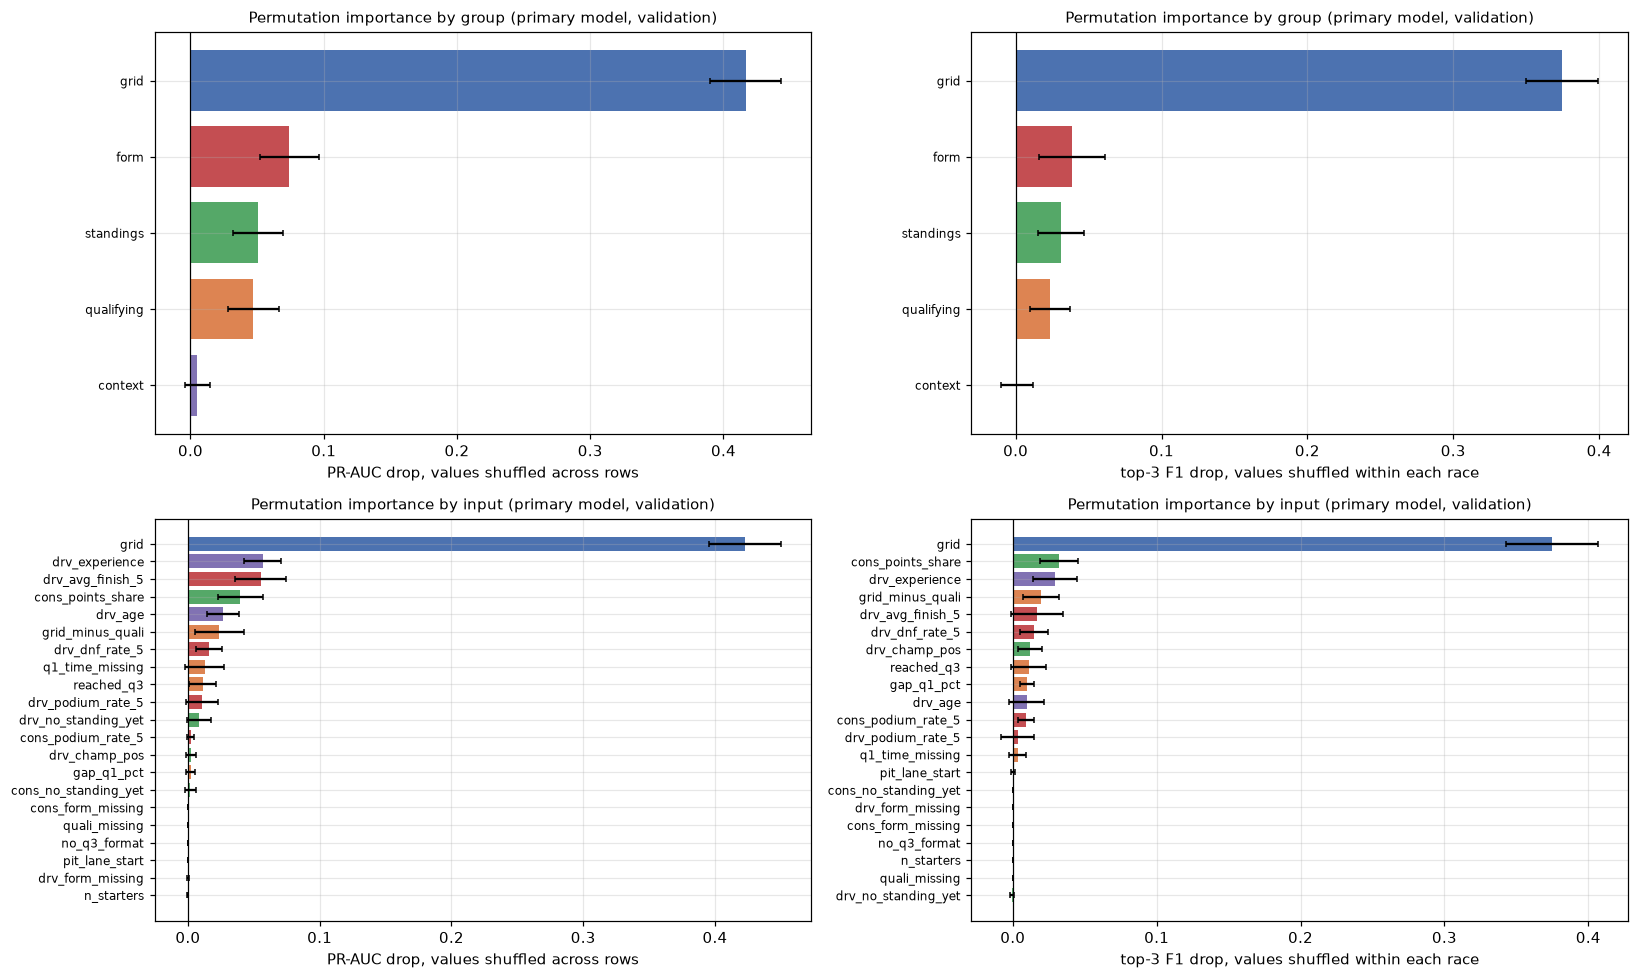

In [154]:
N_REP = 50
y_v, race_v = VAL_ROWS["podium"].to_numpy(), VAL_ROWS["raceId"].to_numpy()
BASE_PR = average_precision_score(y_v, P_VAL)
BASE_TOP3 = podium_pick(y_v, P_VAL, race_v)["top-3 F1"]
val_race_rows = [np.flatnonzero(race_v == r) for r in np.unique(race_v)]
rng_perm = np.random.default_rng(EXP_SEED)


def permutation_drop(cols, within_race):
    drops = []
    for _ in range(N_REP):
        if within_race:
            perm = np.arange(len(y_v))
            for rows in val_race_rows:
                perm[rows] = rows[rng_perm.permutation(len(rows))]
        else:
            perm = rng_perm.permutation(len(y_v))
        Xp = X_VAL.copy()
        Xp[cols] = X_VAL[cols].to_numpy()[perm]                       # same row order for every input of the group
        p = XLR.predict_proba(Xp)[:, 1]
        drops.append(BASE_TOP3 - podium_pick(y_v, p, race_v)["top-3 F1"] if within_race else BASE_PR - average_precision_score(y_v, p))
    return np.mean(drops), np.std(drops)


t0 = time.time()
perm_rows = []
for kind, units in [("input", {c: [c] for c in XAI_INPUTS}), ("group", INPUT_GROUPS)]:
    for unit, cols in units.items():
        m_pr, s_pr = permutation_drop(cols, within_race=False)
        m_t3, s_t3 = permutation_drop(cols, within_race=True)
        perm_rows.append({"level": kind, "input or group": unit, "group": GROUP_OF[cols[0]] if kind == "input" else unit,
                          "PR-AUC drop (across rows)": m_pr, "SD (PR-AUC)": s_pr, "top-3 F1 drop (within race)": m_t3, "SD (top-3)": s_t3})
PERMUTATION = pd.DataFrame(perm_rows)
print(f"Base validation scores: PR-AUC {BASE_PR:.4f}, top-3 F1 {BASE_TOP3:.4f}; {N_REP} shuffles each; {time.time() - t0:.0f} s")
display(PERMUTATION[PERMUTATION["level"] == "group"].drop(columns=["level", "group"]).set_index("input or group").round(4))
display(PERMUTATION[PERMUTATION["level"] == "input"].drop(columns="level").set_index("input or group")
        .sort_values("PR-AUC drop (across rows)", ascending=False).round(4))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for row, kind in enumerate(["group", "input"]):
    sub = PERMUTATION[PERMUTATION["level"] == kind]
    for col, (metric, sd, label) in enumerate([("PR-AUC drop (across rows)", "SD (PR-AUC)", "PR-AUC drop, values shuffled across rows"),
                                               ("top-3 F1 drop (within race)", "SD (top-3)", "top-3 F1 drop, values shuffled within each race")]):
        s = sub.sort_values(metric)
        axes[row, col].barh(s["input or group"], s[metric], xerr=s[sd], color=[GROUP_COLORS[g] for g in s["group"]], capsize=2)
        axes[row, col].axvline(0, color="black", lw=0.8)
        axes[row, col].set_xlabel(label)
        axes[row, col].set_title(f"Permutation importance by {kind} (primary model, validation)", fontsize=10)
        axes[row, col].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Permutation findings** (validation; drop in score when the values are shuffled):
- **Grouped:**

  | Group | PR-AUC drop | Top-3 F1 drop |
  |---|---|---|
  | grid | 0.417 | 0.375 |
  | form | 0.074 | 0.038 |
  | standings | 0.051 | 0.031 |
  | qualifying | 0.047 | 0.024 |
  | context | 0.005 | 0.001 |

  Grid dominates both for ranking all drivers and for picking the top 3 within a race.
- **Individual inputs:** after grid (0.42), the largest PR-AUC drops are `drv_experience` (0.057), `drv_avg_finish_5` (0.055) and `cons_points_share` (0.040).
  - **Correlation shows up clearly:** shuffling `drv_experience` *alone* costs 0.057, but shuffling the whole context group (experience, age and field size together) costs only 0.005. Breaking the link between experience and age creates unrealistic drivers whose two offsetting weights no longer cancel.
- **Unused inputs:** `no_q3_format`, `quali_missing`, `pit_lane_start` and the form flags have ≈ 0 importance in validation; they are constant or very rare there.

## 10.8 Tree SHAP for gradient boosting A (comparison)

The frozen gradient-boosting model A (v2) is explained with SHAP's **tree** explainer (exact for tree models), on its own 21 unscaled inputs and the same validation rows. Its contributions are also in **log-odds**. This shows whether a non-linear model relies on the same groups as the logistic regression.

tree SHAP ran; contributions add up to the model's log-odds: True


,(A) sum of mean |SHAP|,(B) mean |summed group SHAP|
grid,0.8510,0.8510
form,0.6237,0.5320
standings,0.4083,0.3600
qualifying,0.1028,0.1028
context,0.0868,0.0639


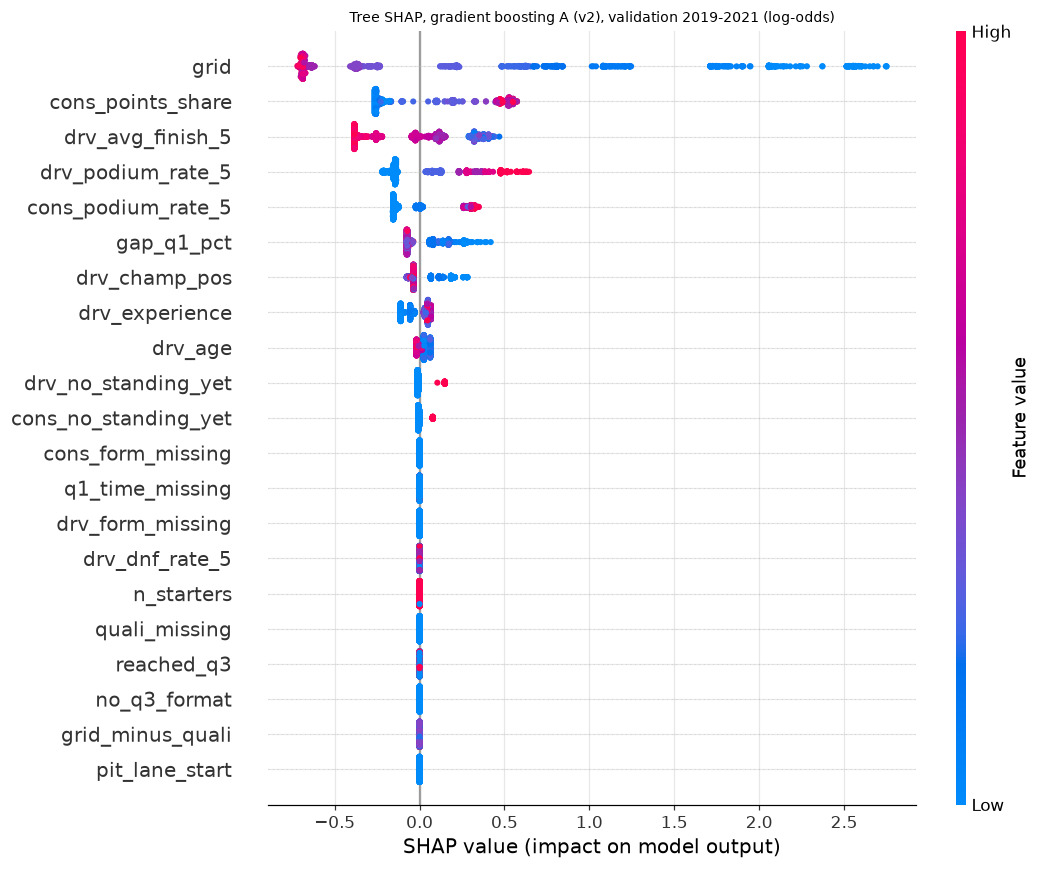

In [155]:
X_VAL_TREE = TPRE.transform(VAL_ROWS[FINAL_FEATURES])
TREE_SHAP_OK, TREE_NOTE = False, ""
if SHAP_OK:
    try:
        _te = shap.TreeExplainer(THGB)
        _tsv = _te(X_VAL_TREE)
        p_tree = THGB.predict_proba(X_VAL_TREE)[:, 1]
        assert np.allclose(p_tree, V2_REFERENCE["A_gradient_boosting"])
        additive = np.allclose(_tsv.values.sum(axis=1) + _tsv.base_values, np.log(p_tree / (1 - p_tree)), atol=1e-6)
        PHI_TREE = pd.DataFrame(_tsv.values, columns=INPUTS_TREE, index=VAL_ROWS.index)
        TREE_SHAP_OK, TREE_NOTE = True, f"tree SHAP ran; contributions add up to the model's log-odds: {additive}"
    except Exception as e:
        TREE_NOTE = f"TREE SHAP COULD NOT RUN with this shap version ({type(e).__name__}: {e}); comparison missing from this run"
else:
    TREE_NOTE = "TREE SHAP COULD NOT RUN: shap is not available; comparison missing from this run"
print(TREE_NOTE)
if TREE_SHAP_OK:
    tree_A = PHI_TREE.abs().mean().groupby(lambda c: GROUP_OF[c]).sum()
    tree_B = pd.Series({g: PHI_TREE[cols].sum(axis=1).abs().mean() for g, cols in INPUT_GROUPS.items()})
    SHAP_GROUPS_TREE = pd.DataFrame({"(A) sum of mean |SHAP|": tree_A, "(B) mean |summed group SHAP|": tree_B})
    display(SHAP_GROUPS_TREE.sort_values("(B) mean |summed group SHAP|", ascending=False).round(4))
    _disp_tree = DISPLAY_VAL[INPUTS_TREE].to_numpy()
    shap.plots.beeswarm(shap.Explanation(values=_tsv.values, base_values=_tsv.base_values, data=X_VAL_TREE.to_numpy(),
                                         display_data=_disp_tree, feature_names=INPUTS_TREE), max_display=21, show=False)
    plt.title("Tree SHAP, gradient boosting A (v2), validation 2019-2021 (log-odds)", fontsize=9)
    plt.gcf().set_size_inches(10, 8)
    plt.tight_layout()
    plt.show()

**Tree SHAP comparison:** gradient boosting relies on the same top two groups, **grid (0.85) and form (0.53)**, then standings (0.36). It uses qualifying (0.10) and context (0.06) much less than logistic regression does. A tree can capture "fast car starting further back" through grid × form interactions rather than through the qualifying flags, and it does not need the age/experience pair.

## 10.9 Do the methods agree? Group ranking across all methods

Rank of each group (1 = most important) under every method. Agreement means a group's role is robust to *how* importance is measured; disagreement is explained mostly by correlated groups (methods that remove or shuffle a group alone measure its *unique* contribution; SHAP measures how much the model's formula *uses* it).

In [156]:
abl_lr = ABLATION[(ABLATION["family"] == "logistic regression") & (ABLATION["variant"] != "full model")].set_index("variant")
abl_gb = ABLATION[(ABLATION["family"] == "gradient boosting") & (ABLATION["variant"] != "full model")].set_index("variant")
perm_g = PERMUTATION[PERMUTATION["level"] == "group"].set_index("input or group")
COMPARE = pd.DataFrame({
    "ablation LR: PR-AUC drop": abl_lr["PR-AUC drop"].rename(lambda v: v.replace("without ", "")),
    "ablation LR: correct-picks drop": abl_lr["correct-picks drop"].rename(lambda v: v.replace("without ", "")),
    "ablation GB: PR-AUC drop": abl_gb["PR-AUC drop"].rename(lambda v: v.replace("without ", "")),
    "permutation: PR-AUC drop": perm_g["PR-AUC drop (across rows)"],
    "permutation: top-3 F1 drop (within race)": perm_g["top-3 F1 drop (within race)"],
    "SHAP LR: mean |group total|": SHAP_GROUPS_LR["(B) mean |summed group SHAP|"],
})
if TREE_SHAP_OK:
    COMPARE["SHAP GB: mean |group total|"] = SHAP_GROUPS_TREE["(B) mean |summed group SHAP|"]
COMPARE["sum of |LR weights|"] = coef.abs().groupby(lambda c: GROUP_OF[c]).sum()
RANKS = COMPARE.rank(ascending=False).astype(int)
print("Values:")
display(COMPARE.round(4))
print("Ranks (1 = most important):")
display(RANKS)

Values:


,ablation LR: PR-AUC drop,ablation LR: correct-picks drop,ablation GB: PR-AUC drop,permutation: PR-AUC drop,permutation: top-3 F1 drop (within race),SHAP LR: mean |group total|,SHAP GB: mean |group total|,sum of |LR weights|
context,-0.0006,0.0380,-0.0004,0.0051,0.0011,0.2596,0.0639,0.9078
form,0.0167,0.0696,0.0132,0.0742,0.0384,0.5127,0.5320,1.5930
grid,0.0586,0.1646,0.0771,0.4168,0.3747,1.6195,0.8510,2.0365
qualifying,0.0038,-0.0316,0.0022,0.0472,0.0236,0.3967,0.1028,3.4117
standings,0.0020,0.0253,-0.0021,0.0507,0.0313,0.4207,0.3600,1.5808


Ranks (1 = most important):


,ablation LR: PR-AUC drop,ablation LR: correct-picks drop,ablation GB: PR-AUC drop,permutation: PR-AUC drop,permutation: top-3 F1 drop (within race),SHAP LR: mean |group total|,SHAP GB: mean |group total|,sum of |LR weights|
context,5,3,4,5,5,5,5,5
form,2,2,2,2,2,2,2,3
grid,1,1,1,1,1,1,1,2
qualifying,3,5,3,4,4,4,4,1
standings,4,4,5,3,3,3,3,4


**Do the methods agree?**
- **Grid is ranked 1st by every method and form 2nd by almost every method.** This is the robust finding: the model mostly predicts "who starts near the front and has been finishing near the front lately".
- **Qualifying is the main disagreement:** 1st by the sum of |weights| but 3rd–5th elsewhere. Its large weights belong to flags that rarely apply (`q1_time_missing`, `no_q3_format`) or offset each other (`reached_q3` vs grid), so big weights do not mean big influence on actual predictions.
- **Standings and qualifying swap places** between methods. Both overlap with grid and form, so how much credit each gets depends on whether a method removes one group at a time (ablation, permutation: *unique* contribution) or splits the model's formula (SHAP).
- **Context** looks moderate in SHAP measure (A) but negligible in ablation, grouped permutation and SHAP measure (B): age and experience cancel.

**These explanations describe the model, not Formula 1.** They show which pre-race information the model uses to rank drivers, not what *causes* a podium; correlated inputs mean that credit between grid, qualifying, standings and form is partly a matter of method.

# 11. Final inference: predicting the podium of a new race

**Brief, deliverable 7:** "Inference function, demonstrated on a complete and a partially-missing record."

**Model:** official pre-test selection, **Model A logistic regression (v2)**, trained on 2003–2018; C=1, no class weighting, seed 42. Uses its already-fitted imputation and scaling. No refitting or loading occurs. Selection used chronological training-fold PR-AUC with the paired one-standard-error simplicity rule; validation supported Model A, and test results did not select the model.

`PodiumPredictor()` binds this fitted model. `predict_proba(records)` returns driver probabilities; `predict_race(entries)` ranks all starters and marks the top three. All 18 columns must be supplied; unknown values may be None/NaN except grid. Race ranking also requires known n_starters.

**Rules the interface enforces** (each violation raises a clear `PodiumInputError` instead of returning a number):
- **Schema:** all 18 feature columns must be present (a value may be unknown: `None` / `NaN`); values must be numeric and finite; flags must be 0 or 1; rates and shares in [0, 1]; positions ≥ 1; age 15–70.
- **Missing values:** allowed for every feature **except `grid`** (after qualifying the starting position is always known). Unknown values are filled by the frozen pre-processing exactly as in training (5.3): missing-value flags are set, qualifying gaps get the fitted fills, other values the training medians, unknown flags 0. The output lists which inputs were unknown.
- **Race mode:** exactly one `raceId`; unique `driverId`; `n_starters` known and equal for every driver; and the number of drivers supplied must equal `n_starters` (otherwise the race is **incomplete** and is refused, unless `allow_incomplete=True` is passed, which ranks only the supplied drivers and warns). Ties in probability are broken by grid position, then `driverId`, exactly as in the evaluation (7.10).

**What the output means:** a probability that the driver finishes in the top three. The three picks of a race are the three **most likely podium finishers**; their order (`probability_rank` 1–3) is **not** a prediction of 1st, 2nd and 3rd place (the model only estimates "podium or not", as the brief requires).

In [157]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

FEATURES = ["grid", "pit_lane_start", "gap_q1_pct", "grid_minus_quali", "reached_q3", "no_q3_format", "quali_missing",
            "drv_champ_pos", "cons_points_share", "drv_no_standing_yet", "cons_no_standing_yet", "drv_podium_rate_5",
            "drv_avg_finish_5", "drv_dnf_rate_5", "cons_podium_rate_5", "n_starters", "drv_experience", "drv_age"]
FLAGS = ["pit_lane_start", "reached_q3", "no_q3_format", "quali_missing", "drv_no_standing_yet", "cons_no_standing_yet"]
# Allowed range of a known value (None = no bound).
RANGES = {"grid": (1, None), "gap_q1_pct": (0, None), "drv_champ_pos": (1, None), "cons_points_share": (0, 1),
          "drv_podium_rate_5": (0, 1), "drv_avg_finish_5": (1, None), "drv_dnf_rate_5": (0, 1), "cons_podium_rate_5": (0, 1),
          "n_starters": (1, None), "drv_experience": (0, None), "drv_age": (15, 70)}
MUST_BE_KNOWN = ["grid"]            # after qualifying the starting position is always known
RACE_KEYS = ["raceId", "driverId"]
PRIMARY = "A_logistic_regression"


class PodiumInputError(ValueError):
    pass


class PodiumPredictor:
    def __init__(self):
        assert PRIMARY_MODEL_V2 == ("A", "logistic regression")
        self.model_name = PRIMARY
        self.fingerprint = FROZEN_V2_FINGERPRINT
        self._predict = loaded_models_v2[PRIMARY]["predict"]

    @staticmethod
    def _frame(records):
        if isinstance(records, dict):
            records = [records]
        if isinstance(records, list):
            if not records or not all(isinstance(r, dict) for r in records):
                raise PodiumInputError("records must be a dict, a non-empty list of dicts, or a DataFrame")
            records = pd.DataFrame(records)
        if not isinstance(records, pd.DataFrame):
            raise PodiumInputError("records must be a dict, a non-empty list of dicts, or a DataFrame")
        if records.empty:
            raise PodiumInputError("no records given")
        return records.reset_index(drop=True)

    def validate(self, records):
        # Returns (the records, their 18 features as floats); raises PodiumInputError on any schema problem.
        df = self._frame(records)
        absent = [c for c in FEATURES if c not in df.columns]
        if absent:
            raise PodiumInputError(f"missing feature column(s) {absent}: all {len(FEATURES)} features must be present "
                                   "(use None / NaN for a value that is unknown)")
        X = pd.DataFrame(index=df.index)
        for c in FEATURES:
            num = pd.to_numeric(df[c], errors="coerce")
            bad = df[c].notna() & num.isna()
            if bad.any():
                raise PodiumInputError(f"non-numeric value(s) in {c}: {df.loc[bad, c].tolist()[:5]}")
            X[c] = num.astype(float)
        if np.isinf(X.to_numpy()).any():
            raise PodiumInputError("infinite values are not allowed")
        for c in MUST_BE_KNOWN:
            if X[c].isna().any():
                raise PodiumInputError(f"{c} must be known (rows {X.index[X[c].isna()].tolist()})")
        for c in FLAGS:
            bad = X[c].notna() & ~X[c].isin([0, 1])
            if bad.any():
                raise PodiumInputError(f"{c} must be 0 or 1 (or unknown); got {X.loc[bad, c].tolist()[:5]}")
        for c, (lo, hi) in RANGES.items():
            v = X[c]
            bad = v.notna() & (((v < lo) if lo is not None else False) | ((v > hi) if hi is not None else False))
            if bad.any():
                raise PodiumInputError(f"{c} must lie in [{lo}, {hi}]; got {v[bad].tolist()[:5]}")
        return df, X

    def predict_proba(self, records):
        df, X = self.validate(records)
        p = np.asarray(self._predict(X), dtype=float)
        if p.shape != (len(X),) or not np.all((p >= 0) & (p <= 1)):
            raise RuntimeError("the model returned invalid probabilities")
        out = df[[c for c in df.columns if c not in FEATURES]].copy()     # identifiers and extra columns, unchanged
        out["podium_probability"] = p
        out["missing_inputs"] = [", ".join(X.columns[row]) or "-" for row in X.isna().to_numpy()]
        return out

    def predict_race(self, race_entries, allow_incomplete=False):
        df = self._frame(race_entries)
        absent = [c for c in RACE_KEYS if c not in df.columns]
        if absent:
            raise PodiumInputError(f"a race prediction needs the identifier columns {RACE_KEYS}; missing {absent}")
        if df[RACE_KEYS].isna().any().any():
            raise PodiumInputError("raceId and driverId must be known for every driver")
        if df["raceId"].nunique() != 1:
            raise PodiumInputError(f"one race per call; got raceIds {sorted(df['raceId'].unique().tolist())}")
        if df["driverId"].duplicated().any():
            raise PodiumInputError(f"duplicate driverId(s): {df.loc[df['driverId'].duplicated(), 'driverId'].tolist()}")
        _, X = self.validate(df)
        if X["n_starters"].isna().any() or X["n_starters"].nunique() != 1:
            raise PodiumInputError("n_starters must be known and the same for every driver of the race")
        n_starters = int(X["n_starters"].iloc[0])
        complete = len(df) == n_starters
        if not complete:
            msg = f"incomplete race entry: {len(df)} drivers supplied, but n_starters = {n_starters}"
            if not allow_incomplete:
                raise PodiumInputError(msg + " (pass allow_incomplete=True to rank only the supplied drivers)")
            warnings.warn(msg + "; the three picks are only among the supplied drivers")
        if len(df) < 3:
            raise PodiumInputError("a race needs at least 3 drivers")
        # Same order as the evaluation: ties in probability are broken by grid position, then driverId.
        order = df.assign(_grid=X["grid"]).sort_values(["_grid", "driverId"], kind="mergesort").index
        df = df.loc[order].reset_index(drop=True)
        out = self.predict_proba(df)
        out["grid"] = pd.to_numeric(df["grid"]).to_numpy()
        out["probability_rank"] = out["podium_probability"].rank(method="first", ascending=False).astype(int)
        out["predicted_podium"] = out["probability_rank"] <= 3
        out["complete_race"] = complete
        return out.sort_values("probability_rank").reset_index(drop=True)

predictor = PodiumPredictor()
print("Inference bound to the fitted official Model A logistic regression.")


Inference bound to the fitted official Model A logistic regression.


### 11.1 Check: the interface reproduces the frozen model exactly

Before the demonstrations, the interface is run on **every** validation and test row and on every race, and compared with the predictions already reported in sections 7.3–7.10 (`VAL_PRED_V2`, `TEST_PRED`). This is a reproduction check only: no number is used to change anything.

In [158]:
ID = ["raceId", "driverId"]
repro = []
for period, rows, frozen in [("validation 2019-2021", VAL_ROWS, VAL_PRED_V2[OFFICIAL]), ("test 2022-2024", TEST_ROWS, TEST_PRED[OFFICIAL])]:
    p = predictor.predict_proba(rows[ID + FINAL_FEATURES])["podium_probability"].to_numpy()
    official = rows.loc[top3_per_race(frozen, rows["raceId"].to_numpy()) == 1, ID]
    race_out = pd.concat([predictor.predict_race(g[ID + FINAL_FEATURES]) for _, g in rows.groupby("raceId", sort=False)])
    picks = race_out.loc[race_out["predicted_podium"], ID]
    same_picks = set(map(tuple, picks.to_numpy())) == set(map(tuple, official.to_numpy()))
    repro.append({"period": period, "drivers": len(rows), "races": rows["raceId"].nunique(),
                  "probabilities identical to the frozen model": bool(np.array_equal(p, frozen)),
                  "largest difference": float(np.abs(p - frozen).max()),
                  "races with exactly 3 picks": int((race_out.groupby("raceId")["predicted_podium"].sum() == 3).sum()),
                  "picks identical to the official output (7.10)": same_picks})
repro = pd.DataFrame(repro)
display(repro)
assert repro["probabilities identical to the frozen model"].all() and repro["picks identical to the official output (7.10)"].all()
assert (repro["races with exactly 3 picks"] == repro["races"]).all()
print("The inference interface reproduces the frozen primary model exactly (every probability and every race's three picks).")

,period,drivers,races,probabilities identical to the frozen model,largest difference,races with exactly 3 picks,picks identical to the official output (7.10)
0,validation 2019-2021,1199,60,True,0.0,60,True
1,test 2022-2024,1354,68,True,0.0,68,True


The inference interface reproduces the frozen primary model exactly (every probability and every race's three picks).


### 11.2 Demonstration 1: a complete driver record

One real record, **all 18 features known**: Max Verstappen before the 2021 Abu Dhabi Grand Prix (validation season). The record is typed in as a plain dictionary, as a user would supply it.

In [159]:
race_names = CLEAN["races"].set_index("raceId")
driver_names = CLEAN["drivers"].set_index("driverId")
full_name = lambda d: f"{driver_names.loc[d, 'forename']} {driver_names.loc[d, 'surname']}"
race_name = lambda r: f"{race_names.loc[r, 'year']} {race_names.loc[r, 'name']}"

demo_race = int(race_names[(race_names["year"] == 2021) & (race_names["name"] == "Abu Dhabi Grand Prix")].index[0])
demo_driver = int(CLEAN["drivers"].loc[CLEAN["drivers"]["driverRef"] == "max_verstappen", "driverId"].iloc[0])
row = VAL_ROWS[(VAL_ROWS["raceId"] == demo_race) & (VAL_ROWS["driverId"] == demo_driver)]
complete_record = {"raceId": demo_race, "driverId": demo_driver, "driver": full_name(demo_driver),
                   **{c: (None if pd.isna(v) else float(v)) for c, v in row[FINAL_FEATURES].iloc[0].items()}}
print(f"Input record ({race_name(demo_race)}):")
display(pd.Series(complete_record, name="value").to_frame())

result_complete = predictor.predict_proba(complete_record)
display(result_complete)
frozen_value = VAL_PRED_V2[OFFICIAL][row.index[0]]
assert result_complete["podium_probability"].iloc[0] == frozen_value
print(f"Podium probability {result_complete['podium_probability'].iloc[0]:.3f} "
      f"(identical to the frozen model's validation prediction for this row: {frozen_value:.3f}).")

Input record (2021 Abu Dhabi Grand Prix):


,value
raceId,1073
driverId,830
driver,Max Verstappen
grid,1.0
pit_lane_start,0.0
gap_q1_pct,0.575774
grid_minus_quali,0.0
reached_q3,1.0
no_q3_format,0.0
quali_missing,0.0


,raceId,driverId,driver,podium_probability,missing_inputs
0,1073,830,Max Verstappen,0.908626,-


Podium probability 0.909 (identical to the frozen model's validation prediction for this row: 0.909).


### 11.3 Demonstration 2: a partially-missing driver record

The same driver and race, but as if the **qualifying details and recent form were unknown**: `gap_q1_pct`, `grid_minus_quali`, `reached_q3`, `quali_missing` and the three driver-form features are `None`. The interface accepts the record, reports which inputs were unknown, and the frozen pre-processing fills them exactly as in training. The table below shows what the model actually receives in both cases (the 21 model inputs before scaling).

In [160]:
UNKNOWN = ["gap_q1_pct", "grid_minus_quali", "reached_q3", "quali_missing", "drv_podium_rate_5", "drv_avg_finish_5", "drv_dnf_rate_5"]
partial_record = {**complete_record, **{c: None for c in UNKNOWN}}
result_partial = predictor.predict_proba(partial_record)
display(result_partial)

imputer = XPRE.named_steps["impute"]                 # the frozen fitted pre-processing of the primary model (section 10.1)
feature_frame = lambda rec: pd.DataFrame([rec])[FINAL_FEATURES].astype(float)
model_view = pd.DataFrame({"complete record": imputer.transform(feature_frame(complete_record)).iloc[0],
                           "partial record": imputer.transform(feature_frame(partial_record)).iloc[0]})
model_view["filled?"] = np.where(model_view.index.isin(UNKNOWN), "filled by the frozen pre-processing", "")
print("What the model receives (21 inputs, before scaling):")
display(model_view.round(3))
print(f"Podium probability: complete record {result_complete['podium_probability'].iloc[0]:.3f}, "
      f"partial record {result_partial['podium_probability'].iloc[0]:.3f}.")

,raceId,driverId,driver,podium_probability,missing_inputs
0,1073,830,Max Verstappen,0.807447,"gap_q1_pct, grid_minus_quali, reached_q3, quali_missing,..."


What the model receives (21 inputs, before scaling):


,complete record,partial record,filled?
grid,1.000,1.000,
pit_lane_start,0.000,0.000,
gap_q1_pct,0.576,1.359,filled by the frozen pre-processing
grid_minus_quali,0.000,0.000,filled by the frozen pre-processing
reached_q3,1.000,0.000,filled by the frozen pre-processing
no_q3_format,0.000,0.000,
quali_missing,0.000,1.000,filled by the frozen pre-processing
drv_champ_pos,1.000,1.000,
cons_points_share,0.952,0.952,
drv_no_standing_yet,0.000,0.000,


Podium probability: complete record 0.909, partial record 0.807.


**What the two records show:**
- With everything known, the model gives Verstappen a high podium probability (he started on pole, in strong recent form).
- With qualifying details and recent form unknown, the interface still returns a valid probability. `quali_missing` is inferred as 1 (no qualifying information at all), so the qualifying gap gets the **neutral** fill (the training median) rather than the "slow lap" fill, and recent form gets the training medians with `drv_form_missing = 1`. The probability drops, because the model can no longer see his strong recent form: it now only knows the grid position, the standings and the context. A partial record therefore gives a more cautious, less informed estimate, which is the expected behaviour.

### 11.4 Demonstration 3: predicting the podium of a complete race

All starters of the **2024 Abu Dhabi Grand Prix** (the last race of the dataset, a test-season race already evaluated in 7.5) are passed in at once. The interface checks that the entry is complete (number of drivers = `n_starters`), ranks the drivers by probability and marks the three most likely podium finishers. The actual result is added **afterwards**, only to show how the picks turned out.

2024 Abu Dhabi Grand Prix: 20 starters supplied, complete race: True


,probability_rank,driver,raceId,driverId,grid,podium_probability,predicted_podium,missing_inputs,actual podium (added after the prediction)
0,1,Lando Norris,1144,846,1.0,0.740,True,-,True
1,2,Carlos Sainz,1144,832,3.0,0.728,True,-,True
2,3,Max Verstappen,1144,830,4.0,0.666,True,-,False
3,4,Oscar Piastri,1144,857,2.0,0.572,False,-,False
4,5,George Russell,1144,847,6.0,0.241,False,-,False
5,6,Pierre Gasly,1144,842,5.0,0.112,False,-,False
6,7,Nico Hülkenberg,1144,807,7.0,0.094,False,-,False
7,8,Charles Leclerc,1144,844,19.0,0.067,False,-,True
8,9,Sergio Pérez,1144,815,10.0,0.062,False,-,False
9,10,Fernando Alonso,1144,4,8.0,0.043,False,-,False


Predicted podium (the three most likely podium finishers, not a finishing order): Lando Norris (0.74), Carlos Sainz (0.73), Max Verstappen (0.67)
Correct picks: 2 of 3


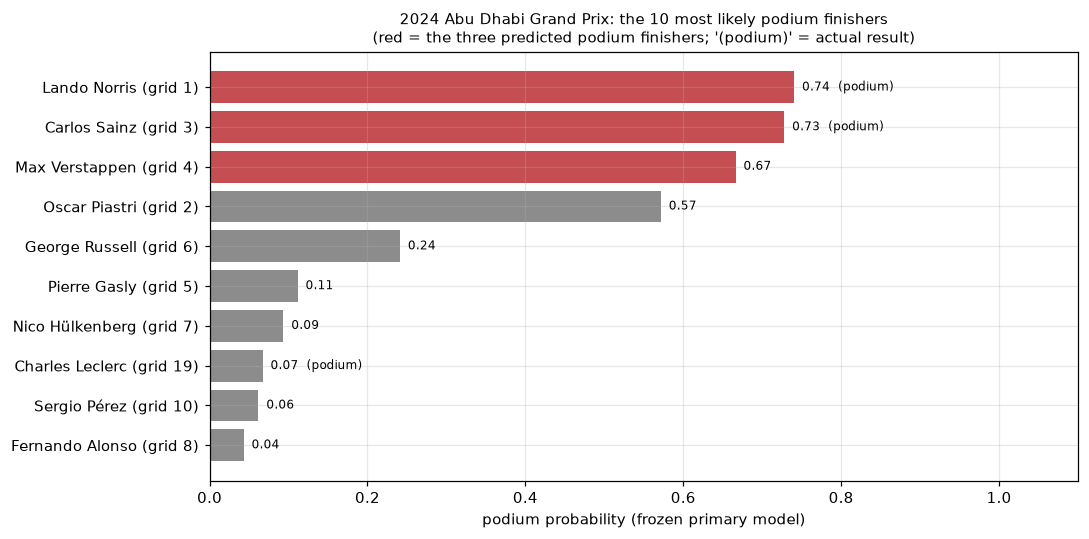

In [161]:
last_race = int(race_names[(race_names["year"] == 2024) & (race_names["name"] == "Abu Dhabi Grand Prix")].index[0])
entries = TEST_ROWS.loc[TEST_ROWS["raceId"] == last_race, ID + FINAL_FEATURES].copy()
entries.insert(2, "driver", entries["driverId"].map(full_name))
race_prediction = predictor.predict_race(entries)

shown = race_prediction[["probability_rank", "driver", "raceId", "driverId", "grid", "podium_probability", "predicted_podium", "missing_inputs"]].copy()
actual = TEST_ROWS.loc[TEST_ROWS["raceId"] == last_race].set_index("driverId")["podium"]
shown["actual podium (added after the prediction)"] = shown["driverId"].map(actual).astype(bool)
print(f"{race_name(last_race)}: {len(entries)} starters supplied, complete race: {bool(race_prediction['complete_race'].iloc[0])}")
display(shown.round(3))
picks = shown[shown["predicted_podium"]]
print("Predicted podium (the three most likely podium finishers, not a finishing order): "
      + ", ".join(f"{d} ({p:.2f})" for d, p in zip(picks["driver"], picks["podium_probability"])))
print(f"Correct picks: {int(picks['actual podium (added after the prediction)'].sum())} of 3")

fig, ax = plt.subplots(figsize=(10, 5))
top = shown.head(10)[::-1]
ax.barh(top["driver"] + " (grid " + top["grid"].astype(int).astype(str) + ")", top["podium_probability"],
        color=np.where(top["predicted_podium"], "#C44E52", "#8C8C8C"))
for y, (p, a) in enumerate(zip(top["podium_probability"], top["actual podium (added after the prediction)"])):
    ax.text(p + 0.01, y, f"{p:.2f}" + ("  (podium)" if a else ""), va="center", fontsize=8)
ax.set_xlim(0, 1.1)
ax.set_xlabel("podium probability (frozen primary model)")
ax.set_title(f"{race_name(last_race)}: the 10 most likely podium finishers\n(red = the three predicted podium finishers; '(podium)' = actual result)", fontsize=10)
plt.tight_layout()
plt.show()

### 11.5 Demonstration 4: invalid inputs are refused explicitly

Each case below is passed to the interface on purpose; the interface must refuse it with a clear message instead of returning a misleading number.

In [162]:
def attempt(label, call):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            out = call()
            status = f"accepted ({len(out)} rows)"
        except PodiumInputError as err:
            status = f"REFUSED: {err}"
    note = "; ".join(str(w.message) for w in caught)
    return {"case": label, "result": status, "warning": note or "-"}


without_age = {k: v for k, v in complete_record.items() if k != "drv_age"}
race_full = entries.copy()
cases = [
    attempt("a feature column is absent (drv_age)", lambda: predictor.predict_proba(without_age)),
    attempt("a non-numeric value (grid = 'P3')", lambda: predictor.predict_proba({**complete_record, "grid": "P3"})),
    attempt("an impossible flag (reached_q3 = 2)", lambda: predictor.predict_proba({**complete_record, "reached_q3": 2})),
    attempt("a share outside [0, 1] (cons_points_share = 1.4)", lambda: predictor.predict_proba({**complete_record, "cons_points_share": 1.4})),
    attempt("the starting position unknown (grid = None)", lambda: predictor.predict_proba({**complete_record, "grid": None})),
    attempt("an empty input", lambda: predictor.predict_proba([])),
    attempt("an incomplete race (2 of the starters left out)", lambda: predictor.predict_race(race_full.iloc[2:])),
    attempt("the same incomplete race, allow_incomplete=True", lambda: predictor.predict_race(race_full.iloc[2:], allow_incomplete=True)),
    attempt("a driver entered twice", lambda: predictor.predict_race(pd.concat([race_full, race_full.iloc[:1]]))),
    attempt("two races mixed in one call", lambda: predictor.predict_race(pd.concat([race_full, TEST_ROWS.loc[TEST_ROWS["raceId"] != last_race, ID + FINAL_FEATURES].head(3)]))),
    attempt("race mode without driverId", lambda: predictor.predict_race(race_full.drop(columns="driverId"))),
]
pd.set_option("display.max_colwidth", 200)
display(pd.DataFrame(cases))
pd.set_option("display.max_colwidth", 60)

,case,result,warning
0,a feature column is absent (drv_age),REFUSED: missing feature column(s) ['drv_age']: all 18 features must be present (use None / NaN for a value that is unknown),-
1,a non-numeric value (grid = 'P3'),REFUSED: non-numeric value(s) in grid: ['P3'],-
2,an impossible flag (reached_q3 = 2),REFUSED: reached_q3 must be 0 or 1 (or unknown); got [2.0],-
3,"a share outside [0, 1] (cons_points_share = 1.4)","REFUSED: cons_points_share must lie in [0, 1]; got [1.4]",-
4,the starting position unknown (grid = None),REFUSED: grid must be known (rows [0]),-
5,an empty input,"REFUSED: records must be a dict, a non-empty list of dicts, or a DataFrame",-
6,an incomplete race (2 of the starters left out),"REFUSED: incomplete race entry: 18 drivers supplied, but n_starters = 20 (pass allow_incomplete=True to rank only the supplied drivers)",-
7,"the same incomplete race, allow_incomplete=True",accepted (18 rows),"incomplete race entry: 18 drivers supplied, but n_starters = 20; the three picks are only among the supplied drivers"
8,a driver entered twice,REFUSED: duplicate driverId(s): [846],-
9,two races mixed in one call,"REFUSED: one race per call; got raceIds [1074, 1144]",-


**Summary of section 11:**
- The inference interface uses the **frozen** primary model and its fitted pre-processing, verified by the pre-test configuration and fingerprint; it reproduces every validation and test probability and every race's official three picks **exactly** (11.1).
- **Complete record** (11.2) and **partially-missing record** (11.3): both return a valid probability; unknown inputs are listed and filled by the frozen pre-processing as in training.
- **Complete race** (11.4): exactly three predicted podium finishers, with race and driver identifiers preserved; the rank among the three is a likelihood order, not a finishing order.
- **Invalid inputs** (11.5): absent columns, non-numeric or impossible values, an unknown grid position, incomplete races, duplicate drivers and mixed races are refused with an explicit message; an incomplete race is only ranked when the caller explicitly allows it, with a warning.

# 12. Known limitations and conclusions

The limitations below are the ones the experiments in this notebook actually show; each points to its evidence.

**Data and era**
- **Qualifying-coverage drift:** qualifying times exist for most drivers only from 2003 onwards (1.7, 5.2: `gap_q1_pct` missing for 1.8% of model-A training rows but 64.8% of model B's). Model A therefore trains on 2003–2018 only; model B uses all seasons with missing-value flags, so it partly learns "qualifying missing = old era". Fifty extra seasons neither helped nor hurt measurably (6.10, 7.9).
- **Era sensitivity:** front-row conversion depends strongly on the decade (46–54% in the 1950s–80s vs 74–75% since 2010, 3.1.1), and model B's training PR-AUC is far lower on old seasons (≈ 0.56–0.58 vs ≈ 0.70, 7.6). Results describe the modern era and may not transfer to very different eras.
- **Season predictability:** the primary model's test PR-AUC moves from 0.65 (2024, several competitive teams) to 0.78 (2023, one dominant team) (7.8). How dominant one team is matters more than the 2022 rule change, and no feature measures it directly.
- **Recording quirks:** pit-lane starts are only recorded from 2015 (7 model-A training rows, so `pit_lane_start` is unreliable); on 2021–22 sprint weekends `grid_minus_quali` also reflects the sprint result; "no standing yet" means "0 points so far" before 2010 but mostly "first race / debut" later; withdrawn cars leave gaps in the grid numbering (e.g. 2005 United States GP), which `n_starters` only partly corrects; formation-lap failures cannot be told apart from lap-1 retirements (2.6).
- **Identity choices:** shared-drive duplicates of the 1950s use a documented proxy (2.6, rule B); renamed teams (Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin) restart their form under a new ID; team form restarts after a break of more than 550 days, driver form does not (a post-test check, the archived development run history Run 11, found that adding a driver reset changes no podium pick).

**Models**
- **Information ceiling:** the starting grid dominates. Removing it costs about 0.16–0.19 correct podium picks per race (9), and it carries about four times the SHAP importance of the next input (10.3). The four model families perform the same within noise on validation and test (6.9, 7.7); post-test checks of race-aware rankers, extra features and XGBoost (section 8; the archived development run history Runs 8, 9, 11 and 12) found no clear improvement either.
- **Podium picks vs the grid:** on the test seasons the official top-3 picks get 2.00 correct drivers per race vs 1.96 for the grid's top three, a difference that is **not** clear (+0.044, interval −0.088 to +0.176, 7.10). The model's clear advantage is in ranking all drivers and in probabilities (test PR-AUC 0.705 vs 0.647 for the grid-only model, 7.7).
- **Probabilities slightly too high:** on the test seasons they sum to about 3.3 per race instead of 3 (7.9).
- **Threshold rule:** the frozen-threshold decision can name any number of podium finishers per race (242 for 204 real podiums on test), which is why the official output is the top 3 per race (7.10).
- **Limited sample:** validation has 60 races and test 68, so differences of a few hundredths are within noise; every comparison is reported with a race-resampling interval.
- **Unpredictable events:** crashes, weather, safety cars and strategy are not in the pre-race data, so podiums like Kvyat's from 14th in the wet 2019 German GP (10.4) cannot be foreseen.
- **Post-test work:** the test seasons were evaluated once (7.5). Section 8 and the exploratory runs recorded in the archived development run history were done afterwards on the historical folds only and changed nothing.

**Explanations**
- **Not causal.** Permutation importance, SHAP and LIME describe what the model relies on, not what causes a podium (10). Correlated inputs (grid, qualifying, standings, form) share credit differently depending on the method (10.9). LIME's local fits are weak (R² 0.14–0.55, 10.6), so local SHAP is the reference.

**Reproducibility**
- The frozen models are verified by fingerprint before the test (7.5) and in every later section. Under other library versions (e.g. on Kaggle) small numeric differences are reported as warnings within a tolerance, while any structural difference (features, settings, pre-processing, model types) stops the notebook.

**Conclusions**
- A leakage-safe, one-row-per-driver-and-race table (24,645 rows, 18 pre-race features) supports a podium model that clearly beats a grid-only baseline on unseen seasons (test PR-AUC 0.705 vs 0.647, ROC-AUC 0.937).
- The official output, the three most likely podium finishers per race, gets 2 of 3 right on average on the test seasons (top-3 F1 0.667) and all three in 16 of 68 races.
- Starting position and recent form explain most of what the model does; qualifying, standings and context add smaller, overlapping information.